# Fraud detection in Credit Card transactions with LSTM model
In this demo, we will show Tensorflow functionality on IBM Z/LinuxONE using credit card transactional data in CSV format provided by IBM in kaggle.com. The data contains normal and also transactions that are likely fraudulent with patterns in historical data such as time since last transaction, amount of money transferred, location (city, country), type of card payment (online/offline), etc. The data is transformed and joined in a Pandas DataFrame, then split into training, validation and test datasets. A Long Short-Term Memory (LSTM) algorithm is then used to predict Fraud Yes/No in the transactions.

Gates are part of the hidden mechanics of the LSTM layer in Tensorflow/Keras. LSTM model in this demo will be built with 2 hidden LSTM layers. Each layer implicitly consists of the gates as depicted below.  

![LSTM CC Diagram](<./images/LSTM for CC on IBM Telum Chip.png>)

At first we will set up a machine learning environment by importing key libraries like TensorFlow (with Keras), NumPy, Pandas, and others for data processing, math operations, model saving/loading, and visualization. We also configures TensorFlow to suppress non-critical log messages and output the TensorFlow version.

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
import tensorflow as tf
from tensorflow import keras
import numpy as np
import pandas as pd
import math
import joblib
print(tf.__version__)

2.18.1


In [2]:
timesteps = 7 # Six past transactions followed by current transaction

# Load dataset into Pandas DataFrame
In this section, we'll demonstrate how to load credit card transactions from a CSV file using the Pandas library, convert columns as needed, remove duplicates, and split the dataset into training (50%), validation (30%), and testing sets (20%). Then we generate the indices for each set using a random selection approach. The resulting indices can be used to access specific rows from the original dataframe or perform other operations.

In [3]:
tdf = pd.read_csv('transactions_history.csv')
tdf['Merchant Name'] = tdf['Merchant Name'].astype(str)
tdf.sort_values(by=['User','Card'], inplace=True)
tdf.reset_index(inplace=True, drop=True)
print (tdf.info())

# Get first of each User-Card combination
first = tdf[['User','Card']].drop_duplicates()
f = np.array(first.index)

# Drop the first N transactions
drop_list = np.concatenate([np.arange(x,x + timesteps - 1) for x in f])
index_list = np.setdiff1d(tdf.index.values,drop_list)

# Split into 0.5 train, 0.3 validate, 0.2 test
tot_length = index_list.shape[0]
train_length = tot_length // 2
validate_length = (tot_length - train_length) * 3 // 5
test_length = tot_length - train_length - validate_length
print (tot_length,train_length,validate_length, test_length)

# Generate list of indices for train, validate, test
np.random.seed(1111)
train_indices = np.random.choice(index_list, train_length, replace=False)
tv_list = np.setdiff1d(index_list, train_indices)
validate_indices = np.random.choice(tv_list, validate_length, replace=False)
test_indices = np.setdiff1d(tv_list, validate_indices)
print (train_indices, validate_indices, test_indices)

<class 'pandas.DataFrame'>
RangeIndex: 245864 entries, 0 to 245863
Data columns (total 15 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   User            245864 non-null  int64  
 1   Card            245864 non-null  int64  
 2   Year            245864 non-null  int64  
 3   Month           245864 non-null  int64  
 4   Day             245864 non-null  int64  
 5   Time            245864 non-null  str    
 6   Amount          245864 non-null  str    
 7   Use Chip        245864 non-null  str    
 8   Merchant Name   245864 non-null  str    
 9   Merchant City   245864 non-null  str    
 10  Merchant State  199705 non-null  str    
 11  Zip             197238 non-null  float64
 12  MCC             245864 non-null  int64  
 13  Errors?         4395 non-null    str    
 14  Is Fraud?       245864 non-null  str    
dtypes: float64(1), int64(6), str(8)
memory usage: 28.1 MB
None
245504 122752 73651 49101
[    50  68902 186069 ...  2

# Generate a test sample as original dataset + test indices
Indices are necessary to speed up large data processing. They play a crucial role in efficient data handling, especially when working with large datasets like millions of transaction records. Indexing enables quick access to rows and efficient joins/merges, optimizes memory usage and eliminates repeated sorting. 

In [4]:
def create_test_sample(df, indices):
    print(indices)
    rows = indices.shape[0]
    index_array = np.zeros((rows, timesteps), dtype=int)
    for i in range(timesteps):
        index_array[:,i] = indices + 1 - timesteps + i
    uniques = np.unique(index_array.flatten())
    df.loc[uniques].to_csv('test_220_40k.csv',index_label='Index')
    np.savetxt('test_220_40k.indices',indices.astype(int),fmt='%d')

create_test_sample(tdf, validate_indices[:40000]) # Uncomment this line to generate a test sample                    

[ 50001    960  75563 ...  24043 219530 174429]


# Define custom mapping functions
To customize how text columns are treated, we define custom mapping (encoder) functions using the astype and to_datetime methods in Pandas. These mapping functions can transform specific categories or values within a column to numerical representations of a specific type, allowing for more nuanced analysis and modeling. For example, a function amtEncoder that maps credit card transaction value in USD with $ to a float type value suitable for model training.

In [5]:
def timeEncoder(X):
    X_hm = X['Time'].str.split(':', expand=True)
    d = pd.to_datetime(dict(year=X['Year'],month=X['Month'],day=X['Day'],hour=X_hm[0],minute=X_hm[1])).astype('int64')
    return pd.DataFrame(d)

def amtEncoder(X):
    amt = X.apply(lambda x: x[1:]).astype(float).map(lambda amt: max(1,amt)).map(math.log)
    return pd.DataFrame(amt)

def decimalEncoder(X,length=5):
    dnew = pd.DataFrame()
    for i in range(length):
        dnew[i] = np.mod(X,10) 
        X = np.floor_divide(X,10)
    return dnew

def fraudEncoder(X):
    return np.where(X == 'Yes', 1, 0).astype(int)

# Fit pre-processing function using DataFrameMapper and pickle the mapper
In machine learning, pre-processing transforms raw data into a structured format by handling missing values, scaling features, encoding categorical variables, and addressing imbalanced data. It also involves tasks like feature engineering, outlier removal, and dimensionality reduction to enhance model performance and accuracy. These steps ensure the data is clean and ready for model training.

In [6]:
save_dir = 'shared/fraud_lstm'
os.makedirs(save_dir, exist_ok=True)

In [7]:
from sklearn_pandas import DataFrameMapper
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import FunctionTransformer
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import LabelBinarizer
from sklearn.impute import SimpleImputer

mapper = DataFrameMapper([('Is Fraud?', FunctionTransformer(fraudEncoder)),
                          (['Merchant State'], [SimpleImputer(strategy='constant'), FunctionTransformer(np.ravel),
                                               LabelEncoder(), FunctionTransformer(decimalEncoder), OneHotEncoder()]),
                          (['Zip'], [SimpleImputer(strategy='constant'), FunctionTransformer(np.ravel),
                                     FunctionTransformer(decimalEncoder), OneHotEncoder()]),
                          ('Merchant Name', [LabelEncoder(), FunctionTransformer(decimalEncoder), OneHotEncoder()]),
                          ('Merchant City', [LabelEncoder(), FunctionTransformer(decimalEncoder), OneHotEncoder()]),
                          ('MCC', [LabelEncoder(), FunctionTransformer(decimalEncoder), OneHotEncoder()]),
                          (['Use Chip'], [SimpleImputer(strategy='constant'), LabelBinarizer()]),
                          (['Errors?'], [SimpleImputer(strategy='constant'), LabelBinarizer()]),
                          (['Year','Month','Day','Time'], [FunctionTransformer(timeEncoder), MinMaxScaler()]),
                          ('Amount', [FunctionTransformer(amtEncoder), MinMaxScaler()])
                         ], input_df=True, df_out=True)
mapper.fit(tdf)

,features,"[('Is Fraud?', ...), (['Merchant State'], ...), ...]"
,df_out,True
,input_df,True
,drop_cols,[]
,default,False
,sparse,False
Name,Type,Value
transformed_names_,list,[]


Serialize and deserialize fitted mapper as Python objects using pickle module. This allows you to save a preprocessing-function to a file and load it later without having to retrain it. 

In [8]:
joblib.dump(mapper, open(os.path.join(save_dir,'fitted_mapper.pkl'),'wb'))
mapper = joblib.load(open(os.path.join(save_dir,'fitted_mapper.pkl'),'rb'))

# Do a transform on one row to get number of mapped features (including label)

In [9]:
mapped_sample = mapper.transform(tdf[:100])
mapped_size = mapped_sample.shape[-1]
print(mapped_size)

190


# Utilities 

A set of helper functions and classes

In [10]:
from sklearn.metrics import f1_score

def f1(conf):
    precision = float(conf[1][1]) / (conf[1][1] + conf[0][1])
    recall    = float(conf[1][1]) / (conf[1][1] + conf[1][0])
    return 2 * precision * recall / (precision + recall)

# Custom metric that evaluates only the final timestep of each sequence.
# Pass the metric CLASS (not instance) so weights are created inside the model.
class LastStepMetric(tf.keras.metrics.Metric):
    def __init__(self, metric_class, name, **kwargs):
        super().__init__(name=name, **kwargs)
        self._m = metric_class(name=name)
    def update_state(self, y_true, y_pred, sample_weight=None):
        self._m.update_state(y_true[:, -1, :], y_pred[:, -1, :], sample_weight)
    def result(self):
        return self._m.result()
    def reset_state(self):
        self._m.reset_state()


# Defining and compiling the LSTM model with Tensorflow
LSTM (Long Short-Term Memory) needs to be defined first with a set of paramaters using integrated Keras in Tensorflow for simplicity. 
```input_shape=tf_input``` - is a matrix of ```timesteps=7``` the number of time steps per input sequence, and ```input_size``` is the number of features per time step.
Training and Testing is completed in batches of 16. 

Using visualization function within the Keras library - ```plot_model``` will create a graphical representation of the LSTM model's architecture.

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (16, 7, 200)           │       312,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (16, 7, 200)           │       320,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (16, 7, 1)             │           201 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 633,001 (2.41 MB)

 Trainable params: 633,001 (2.41 MB)

 Non-trainable params: 0 (0.00 B)

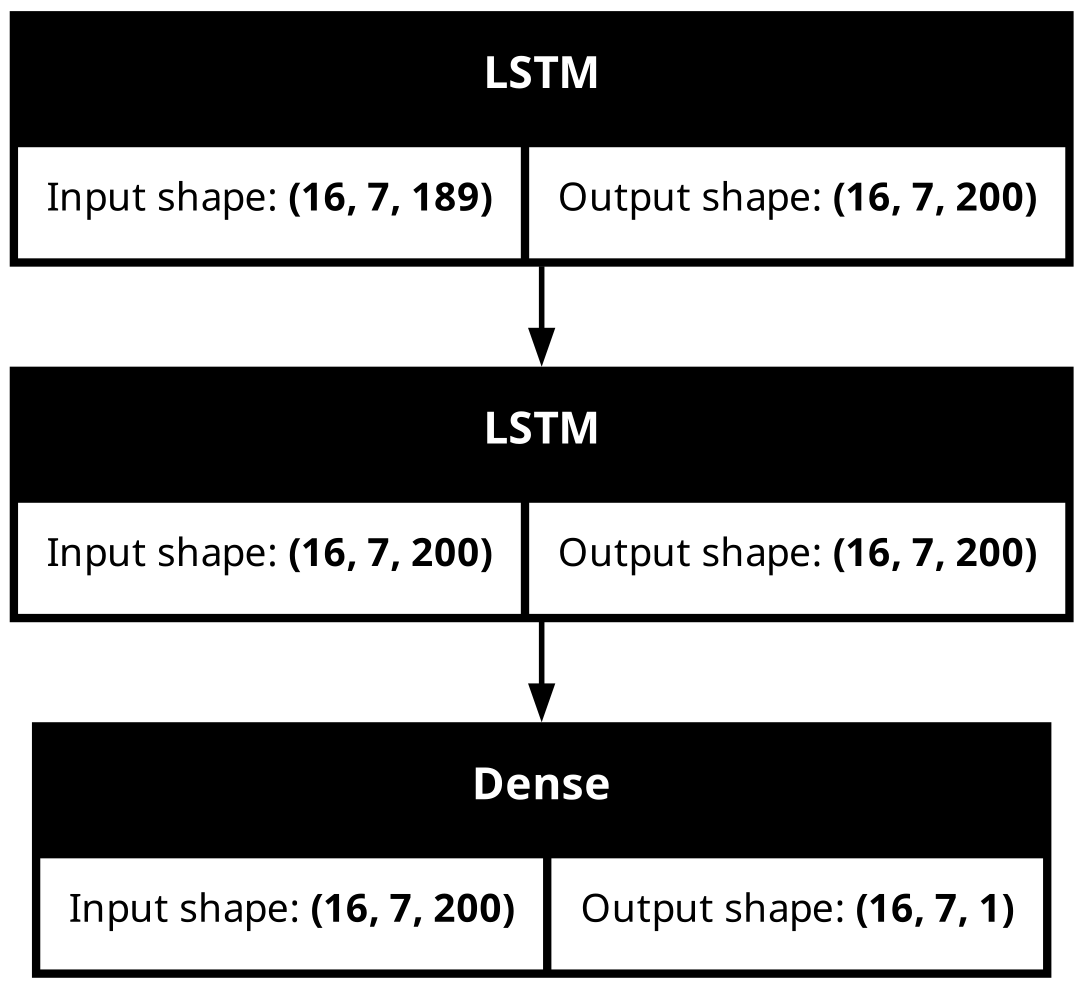

In [11]:
units = [200, 200]
input_size = mapped_size - 1
output_size = 1
batch_size = 16
timesteps = 7

lstm_model = tf.keras.models.Sequential([
    tf.keras.Input(shape=(timesteps, input_size), batch_size=batch_size),
    tf.keras.layers.LSTM(units[0], return_sequences=True),
    tf.keras.layers.LSTM(units[1], return_sequences=True),
    tf.keras.layers.Dense(output_size, activation='sigmoid')
])

lstm_model.summary()
tf.keras.utils.plot_model(lstm_model, 'model.png', show_shapes=True)


In [12]:
# Compile model — metrics instantiated here so weights are created in the right context
metrics = [
    'accuracy',
    LastStepMetric(tf.keras.metrics.TruePositives,  name='TP'),
    LastStepMetric(tf.keras.metrics.FalsePositives, name='FP'),
    LastStepMetric(tf.keras.metrics.FalseNegatives, name='FN'),
    LastStepMetric(tf.keras.metrics.TrueNegatives,  name='TN'),
    tf.keras.metrics.TruePositives(name='tp'),
    tf.keras.metrics.FalsePositives(name='fp'),
    tf.keras.metrics.FalseNegatives(name='fn'),
    tf.keras.metrics.TrueNegatives(name='tn'),
]

lstm_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=metrics)


# Generator for training batches
Generator function produces one batch of data at a time using indices, instead of loading everything into memory at once. This allows streaming of large datasets for on-the-fly processing.

In [13]:
def gen_training_batch(df, mapper, index_list, batch_size):
    np.random.seed(98765)
    train_df = df.loc[index_list]
    non_fraud_indices = train_df[train_df['Is Fraud?'] == 'No'].index.values
    fraud_indices     = train_df[train_df['Is Fraud?'] == 'Yes'].index.values
    fsize = fraud_indices.shape[0]
    while True:
        indices = np.concatenate((fraud_indices,
                                  np.random.choice(non_fraud_indices, fsize, replace=False)))
        np.random.shuffle(indices)
        rows = indices.shape[0]
        index_array = np.zeros((rows, timesteps), dtype=int)
        for i in range(timesteps):
            index_array[:, i] = indices + 1 - timesteps + i
        full_df = mapper.transform(df.loc[index_array.flatten()])
        # shape: (rows, timesteps, features) — batch-major
        target_buffer = full_df['Is Fraud?'].to_numpy().reshape(rows, timesteps, 1)
        data_buffer   = full_df.drop(['Is Fraud?'], axis=1).to_numpy().reshape(rows, timesteps, -1)
        batch_ptr = 0
        while (batch_ptr + batch_size) <= rows:
            yield (data_buffer[batch_ptr:batch_ptr + batch_size],
                   target_buffer[batch_ptr:batch_ptr + batch_size])
            batch_ptr += batch_size


# Tensorflow training - LSTM model
Training the LSTM model via forward pass, loss calculation, backward pass, weights update, epoch loop and validation after each epoch. In ModelCheckpoint, after each epoch, Tensorflow checks the monitored metric  and if the monitored metric improves, the model is saved to the specified location. The best model is then retrieved from checkpoints and saved in the ```saved_dir```.

In [14]:
steps_per_epoch = 500
checkpoint_dir = "./checkpoints/ccf_220_keras_lstm_static/"
filepath = checkpoint_dir + "iter-{epoch:02d}/model.weights.h5"
batch_size = 16

print ("Learning...")
cp_callback = tf.keras.callbacks.ModelCheckpoint(filepath=filepath, save_weights_only=True, verbose=1)
train_generate = gen_training_batch(tdf,mapper,train_indices,batch_size)
lstm_model.fit(train_generate, epochs=5, steps_per_epoch=steps_per_epoch, verbose=1, callbacks=[cp_callback])

lstm_model.save_weights(os.path.join(save_dir,"model.weights.h5"))
lstm_model.export(save_dir)

Learning...


Epoch 1/5


  1/500 ━━━━━━━━━━━━━━━━━━━━ 39:30 5s/step - FN: 7.0000 - FP: 0.0000e+00 - TN: 9.0000 - TP: 0.0000e+00 - accuracy: 0.7679 - fn: 26.0000 - fp: 0.0000e+00 - loss: 0.6767 - tn: 86.0000 - tp: 0.0000e+00

  3/500 ━━━━━━━━━━━━━━━━━━━━ 20s 42ms/step - FN: 13.6667 - FP: 0.0000e+00 - TN: 18.3333 - TP: 0.0000e+00 - accuracy: 0.7882 - fn: 46.3333 - fp: 0.0000e+00 - loss: 0.6504 - tn: 177.6667 - tp: 0.0000e+00

  5/500 ━━━━━━━━━━━━━━━━━━━━ 18s 37ms/step - FN: 21.0000 - FP: 0.0000e+00 - TN: 27.0000 - TP: 0.0000e+00 - accuracy: 0.7831 - fn: 73.2000 - fp: 0.0000e+00 - loss: 0.6440 - tn: 262.8000 - tp: 0.0000e+00

  7/500 ━━━━━━━━━━━━━━━━━━━━ 21s 43ms/step - FN: 29.0000 - FP: 0.0000e+00 - TN: 35.0000 - TP: 0.0000e+00 - accuracy: 0.7776 - fn: 101.2857 - fp: 0.0000e+00 - loss: 0.6412 - tn: 346.7143 - tp: 0.0000e+00

  9/500 ━━━━━━━━━━━━━━━━━━━━ 19s 40ms/step - FN: 36.8889 - FP: 0.0000e+00 - TN: 43.1111 - TP: 0.0000e+00 - accuracy: 0.7722 - fn: 131.0000 - fp: 0.0000e+00 - loss: 0.6364 - tn: 429.0000 - tp: 0.0000e+00

 11/500 ━━━━━━━━━━━━━━━━━━━━ 18s 39ms/step - FN: 43.4545 - FP: 0.0909 - TN: 51.0909 - TP: 1.3636 - accuracy: 0.7691 - fn: 158.9091 - fp: 0.6364 - loss: 0.6317 - tn: 508.0909 - tp: 4.3636                

 13/500 ━━━━━━━━━━━━━━━━━━━━ 18s 37ms/step - FN: 49.0000 - FP: 0.3846 - TN: 59.0000 - TP: 3.6154 - accuracy: 0.7684 - fn: 183.5385 - fp: 2.0769 - loss: 0.6266 - tn: 586.6154 - tp: 11.7692

 14/500 ━━━━━━━━━━━━━━━━━━━━ 19s 40ms/step - FN: 51.6429 - FP: 0.5000 - TN: 62.8571 - TP: 5.0000 - accuracy: 0.7686 - fn: 195.1429 - fp: 2.8571 - loss: 0.6239 - tn: 625.4286 - tp: 16.5714

 15/500 ━━━━━━━━━━━━━━━━━━━━ 21s 44ms/step - FN: 54.3333 - FP: 0.6667 - TN: 66.7333 - TP: 6.2667 - accuracy: 0.7693 - fn: 206.0000 - fp: 3.6000 - loss: 0.6209 - tn: 665.2000 - tp: 21.2000

 17/500 ━━━━━━━━━━━━━━━━━━━━ 20s 43ms/step - FN: 59.8824 - FP: 0.9412 - TN: 74.3529 - TP: 8.8235 - accuracy: 0.7710 - fn: 227.0000 - fp: 4.9412 - loss: 0.6154 - tn: 745.4118 - tp: 30.6471

 18/500 ━━━━━━━━━━━━━━━━━━━━ 21s 45ms/step - FN: 62.5000 - FP: 1.0556 - TN: 78.1111 - TP: 10.3333 - accuracy: 0.7719 - fn: 237.2778 - fp: 5.5556 - loss: 0.6128 - tn: 784.6667 - tp: 36.5000

 19/500 ━━━━━━━━━━━━━━━━━━━━ 22s 46ms/step - FN: 64.8947 - FP: 1.2105 - TN: 81.9474 - TP: 11.9474 - accuracy: 0.7731 - fn: 246.7368 - fp: 6.3158 - loss: 0.6097 - tn: 823.8421 - tp: 43.1053

 20/500 ━━━━━━━━━━━━━━━━━━━━ 22s 46ms/step - FN: 67.1500 - FP: 1.4000 - TN: 85.7500 - TP: 13.7000 - accuracy: 0.7743 - fn: 255.9000 - fp: 7.2000 - loss: 0.6067 - tn: 862.6000 - tp: 50.3000

 22/500 ━━━━━━━━━━━━━━━━━━━━ 22s 48ms/step - FN: 71.3182 - FP: 1.9091 - TN: 93.5000 - TP: 17.2727 - accuracy: 0.7764 - fn: 273.1818 - fp: 10.2727 - loss: 0.6006 - tn: 939.8636 - tp: 64.6818

 23/500 ━━━━━━━━━━━━━━━━━━━━ 23s 49ms/step - FN: 73.3913 - FP: 2.1304 - TN: 97.3913 - TP: 19.0870 - accuracy: 0.7774 - fn: 281.7826 - fp: 11.8261 - loss: 0.5978 - tn: 978.3478 - tp: 72.0435

 24/500 ━━━━━━━━━━━━━━━━━━━━ 25s 53ms/step - FN: 75.3750 - FP: 2.3750 - TN: 101.2083 - TP: 21.0417 - accuracy: 0.7784 - fn: 290.2500 - fp: 13.4167 - loss: 0.5951 - tn: 1016.6250 - tp: 79.7083

 26/500 ━━━━━━━━━━━━━━━━━━━━ 24s 52ms/step - FN: 79.2308 - FP: 2.9615 - TN: 108.7692 - TP: 25.0385 - accuracy: 0.7804 - fn: 306.6923 - fp: 16.6538 - loss: 0.5894 - tn: 1094.1154 - tp: 94.5385

 28/500 ━━━━━━━━━━━━━━━━━━━━ 24s 51ms/step - FN: 82.6786 - FP: 3.9643 - TN: 115.8929 - TP: 29.4643 - accuracy: 0.7822 - fn: 322.4286 - fp: 20.5000 - loss: 0.5841 - tn: 1171.2143 - tp: 109.8571

 29/500 ━━━━━━━━━━━━━━━━━━━━ 24s 52ms/step - FN: 84.3103 - FP: 4.4138 - TN: 119.4138 - TP: 31.8621 - accuracy: 0.7831 - fn: 330.4483 - fp: 22.2759 - loss: 0.5814 - tn: 1209.2759 - tp: 118.0000

 31/500 ━━━━━━━━━━━━━━━━━━━━ 23s 51ms/step - FN: 87.3871 - FP: 5.2903 - TN: 126.5484 - TP: 36.7742 - accuracy: 0.7847 - fn: 346.2258 - fp: 25.9355 - loss: 0.5761 - tn: 1285.0000 - tp: 134.8387

 32/500 ━━━━━━━━━━━━━━━━━━━━ 23s 51ms/step - FN: 88.8438 - FP: 5.6875 - TN: 130.1562 - TP: 39.3125 - accuracy: 0.7856 - fn: 353.7500 - fp: 27.5938 - loss: 0.5733 - tn: 1323.2812 - tp: 143.3750

 34/500 ━━━━━━━━━━━━━━━━━━━━ 23s 49ms/step - FN: 91.5000 - FP: 6.4412 - TN: 137.3235 - TP: 44.7353 - accuracy: 0.7876 - fn: 368.1176 - fp: 30.8235 - loss: 0.5676 - tn: 1399.1765 - tp: 161.8824

 36/500 ━━━━━━━━━━━━━━━━━━━━ 22s 49ms/step - FN: 93.9444 - FP: 7.2222 - TN: 144.6111 - TP: 50.2222 - accuracy: 0.7895 - fn: 382.1389 - fp: 34.0833 - loss: 0.5620 - tn: 1475.4722 - tp: 180.3056

 38/500 ━━━━━━━━━━━━━━━━━━━━ 22s 49ms/step - FN: 96.3421 - FP: 8.0000 - TN: 151.8158 - TP: 55.8421 - accuracy: 0.7912 - fn: 396.1316 - fp: 37.2368 - loss: 0.5566 - tn: 1551.0789 - tp: 199.5526

 39/500 ━━━━━━━━━━━━━━━━━━━━ 23s 51ms/step - FN: 97.5385 - FP: 8.4359 - TN: 155.3333 - TP: 58.6923 - accuracy: 0.7921 - fn: 403.1282 - fp: 38.9231 - loss: 0.5540 - tn: 1588.8462 - tp: 209.1026

 41/500 ━━━━━━━━━━━━━━━━━━━━ 23s 50ms/step - FN: 100.0244 - FP: 9.3415 - TN: 162.3415 - TP: 64.2927 - accuracy: 0.7936 - fn: 417.2195 - fp: 42.3415 - loss: 0.5490 - tn: 1664.6585 - tp: 227.7805

 43/500 ━━━━━━━━━━━━━━━━━━━━ 22s 50ms/step - FN: 102.3488 - FP: 10.2326 - TN: 169.3953 - TP: 70.0233 - accuracy: 0.7952 - fn: 430.6744 - fp: 45.7674 - loss: 0.5440 - tn: 1740.9070 - tp: 246.6512

 45/500 ━━━━━━━━━━━━━━━━━━━━ 23s 51ms/step - FN: 104.6000 - FP: 11.1333 - TN: 176.4444 - TP: 75.8222 - accuracy: 0.7967 - fn: 443.7333 - fp: 49.3556 - loss: 0.5392 - tn: 1817.2444 - tp: 265.6667

 46/500 ━━━━━━━━━━━━━━━━━━━━ 23s 53ms/step - FN: 105.6957 - FP: 11.5652 - TN: 180.0000 - TP: 78.7391 - accuracy: 0.7974 - fn: 450.1304 - fp: 51.1304 - loss: 0.5369 - tn: 1855.6087 - tp: 275.1304

 48/500 ━━━━━━━━━━━━━━━━━━━━ 23s 52ms/step - FN: 107.7917 - FP: 12.3750 - TN: 187.1875 - TP: 84.6458 - accuracy: 0.7989 - fn: 462.5417 - fp: 54.6250 - loss: 0.5322 - tn: 1932.0833 - tp: 294.7500

 50/500 ━━━━━━━━━━━━━━━━━━━━ 23s 52ms/step - FN: 109.8400 - FP: 13.1200 - TN: 194.5800 - TP: 90.4600 - accuracy: 0.8005 - fn: 474.4000 - fp: 58.0400 - loss: 0.5275 - tn: 2009.4600 - tp: 314.1000

 52/500 ━━━━━━━━━━━━━━━━━━━━ 23s 51ms/step - FN: 111.7885 - FP: 13.8077 - TN: 201.9808 - TP: 96.4231 - accuracy: 0.8021 - fn: 485.8269 - fp: 61.2885 - loss: 0.5229 - tn: 2086.7692 - tp: 334.1154

 54/500 ━━━━━━━━━━━━━━━━━━━━ 22s 51ms/step - FN: 113.6111 - FP: 14.4815 - TN: 209.2963 - TP: 102.6111 - accuracy: 0.8036 - fn: 497.0185 - fp: 64.5926 - loss: 0.5184 - tn: 2163.4815 - tp: 354.9074

 56/500 ━━━━━━━━━━━━━━━━━━━━ 22s 50ms/step - FN: 115.3571 - FP: 15.2143 - TN: 216.5714 - TP: 108.8571 - accuracy: 0.8051 - fn: 507.6071 - fp: 68.1429 - loss: 0.5140 - tn: 2240.3036 - tp: 375.9464

 58/500 ━━━━━━━━━━━━━━━━━━━━ 21s 49ms/step - FN: 117.0345 - FP: 15.8966 - TN: 223.8621 - TP: 115.2069 - accuracy: 0.8066 - fn: 517.8103 - fp: 71.5345 - loss: 0.5096 - tn: 2316.7241 - tp: 397.9310

 60/500 ━━━━━━━━━━━━━━━━━━━━ 21s 49ms/step - FN: 118.6833 - FP: 16.5333 - TN: 231.1167 - TP: 121.6667 - accuracy: 0.8081 - fn: 527.8000 - fp: 74.8500 - loss: 0.5053 - tn: 2392.7167 - tp: 420.6333

 62/500 ━━━━━━━━━━━━━━━━━━━━ 21s 49ms/step - FN: 120.2419 - FP: 17.1452 - TN: 238.2742 - TP: 128.3387 - accuracy: 0.8096 - fn: 537.5968 - fp: 78.0323 - loss: 0.5011 - tn: 2468.9839 - tp: 443.3871

 64/500 ━━━━━━━━━━━━━━━━━━━━ 20s 48ms/step - FN: 121.7188 - FP: 17.7656 - TN: 245.5781 - TP: 134.9375 - accuracy: 0.8111 - fn: 546.9062 - fp: 81.3125 - loss: 0.4970 - tn: 2545.7031 - tp: 466.0781

 65/500 ━━━━━━━━━━━━━━━━━━━━ 20s 48ms/step - FN: 122.4308 - FP: 18.0615 - TN: 249.2615 - TP: 138.2462 - accuracy: 0.8118 - fn: 551.4308 - fp: 82.9692 - loss: 0.4950 - tn: 2584.0615 - tp: 477.5385

 66/500 ━━━━━━━━━━━━━━━━━━━━ 20s 48ms/step - FN: 123.1364 - FP: 18.3636 - TN: 253.0303 - TP: 141.4697 - accuracy: 0.8126 - fn: 555.9242 - fp: 84.6364 - loss: 0.4930 - tn: 2622.7273 - tp: 488.7121

 67/500 ━━━━━━━━━━━━━━━━━━━━ 24s 56ms/step - FN: 123.8358 - FP: 18.6567 - TN: 256.8507 - TP: 144.6567 - accuracy: 0.8133 - fn: 560.3134 - fp: 86.2836 - loss: 0.4911 - tn: 2661.5970 - tp: 499.8060

 69/500 ━━━━━━━━━━━━━━━━━━━━ 23s 55ms/step - FN: 125.2754 - FP: 19.2174 - TN: 264.5072 - TP: 151.0000 - accuracy: 0.8147 - fn: 569.0435 - fp: 89.4928 - loss: 0.4872 - tn: 2739.2174 - tp: 522.2464

 71/500 ━━━━━━━━━━━━━━━━━━━━ 23s 55ms/step - FN: 126.7324 - FP: 19.7465 - TN: 272.1127 - TP: 157.4085 - accuracy: 0.8161 - fn: 577.6338 - fp: 92.6901 - loss: 0.4834 - tn: 2816.6761 - tp: 545.0000

 73/500 ━━━━━━━━━━━━━━━━━━━━ 23s 54ms/step - FN: 128.1096 - FP: 20.2466 - TN: 279.8356 - TP: 163.8082 - accuracy: 0.8174 - fn: 585.9452 - fp: 95.8356 - loss: 0.4796 - tn: 2894.6438 - tp: 567.5753

 74/500 ━━━━━━━━━━━━━━━━━━━━ 23s 54ms/step - FN: 128.7838 - FP: 20.5135 - TN: 283.6757 - TP: 167.0270 - accuracy: 0.8181 - fn: 589.9730 - fp: 97.3919 - loss: 0.4777 - tn: 2933.7297 - tp: 578.9054

 76/500 ━━━━━━━━━━━━━━━━━━━━ 22s 54ms/step - FN: 130.1053 - FP: 21.0263 - TN: 291.3947 - TP: 173.4737 - accuracy: 0.8195 - fn: 597.8158 - fp: 100.4737 - loss: 0.4741 - tn: 3012.0000 - tp: 601.7105

 78/500 ━━━━━━━━━━━━━━━━━━━━ 22s 53ms/step - FN: 131.3846 - FP: 21.5128 - TN: 299.1026 - TP: 180.0000 - accuracy: 0.8208 - fn: 605.4487 - fp: 103.4872 - loss: 0.4705 - tn: 3090.1282 - tp: 624.9359

 79/500 ━━━━━━━━━━━━━━━━━━━━ 22s 53ms/step - FN: 132.0000 - FP: 21.7468 - TN: 302.9747 - TP: 183.2785 - accuracy: 0.8215 - fn: 609.1772 - fp: 104.9494 - loss: 0.4687 - tn: 3129.1266 - tp: 636.7468

 80/500 ━━━━━━━━━━━━━━━━━━━━ 22s 54ms/step - FN: 132.6125 - FP: 21.9750 - TN: 306.8375 - TP: 186.5750 - accuracy: 0.8221 - fn: 612.8500 - fp: 106.4250 - loss: 0.4669 - tn: 3168.0375 - tp: 648.6875

 81/500 ━━━━━━━━━━━━━━━━━━━━ 22s 54ms/step - FN: 133.2222 - FP: 22.2222 - TN: 310.6543 - TP: 189.9012 - accuracy: 0.8228 - fn: 616.4691 - fp: 107.9012 - loss: 0.4651 - tn: 3206.7654 - tp: 660.8642

 82/500 ━━━━━━━━━━━━━━━━━━━━ 22s 54ms/step - FN: 133.8415 - FP: 22.4756 - TN: 314.4512 - TP: 193.2317 - accuracy: 0.8234 - fn: 620.0488 - fp: 109.3537 - loss: 0.4634 - tn: 3245.5366 - tp: 673.0610

 84/500 ━━━━━━━━━━━━━━━━━━━━ 22s 54ms/step - FN: 135.0357 - FP: 23.0119 - TN: 321.9643 - TP: 199.9881 - accuracy: 0.8247 - fn: 627.0833 - fp: 112.2500 - loss: 0.4600 - tn: 3322.9524 - tp: 697.7143

 85/500 ━━━━━━━━━━━━━━━━━━━━ 22s 54ms/step - FN: 135.6118 - FP: 23.2941 - TN: 325.7412 - TP: 203.3529 - accuracy: 0.8254 - fn: 630.4824 - fp: 113.7412 - loss: 0.4583 - tn: 3361.7765 - tp: 710.0000

 87/500 ━━━━━━━━━━━━━━━━━━━━ 22s 54ms/step - FN: 136.7586 - FP: 23.8621 - TN: 333.3103 - TP: 210.0690 - accuracy: 0.8266 - fn: 637.1724 - fp: 116.6437 - loss: 0.4550 - tn: 3439.7126 - tp: 734.4713

 89/500 ━━━━━━━━━━━━━━━━━━━━ 21s 54ms/step - FN: 137.8876 - FP: 24.4270 - TN: 340.8202 - TP: 216.8652 - accuracy: 0.8279 - fn: 643.7303 - fp: 119.4719 - loss: 0.4518 - tn: 3517.4607 - tp: 759.3371

 91/500 ━━━━━━━━━━━━━━━━━━━━ 21s 53ms/step - FN: 138.9780 - FP: 24.9670 - TN: 348.3846 - TP: 223.6703 - accuracy: 0.8291 - fn: 650.0769 - fp: 122.4066 - loss: 0.4486 - tn: 3595.1758 - tp: 784.3407

 93/500 ━━━━━━━━━━━━━━━━━━━━ 21s 53ms/step - FN: 140.0645 - FP: 25.4946 - TN: 355.9892 - TP: 230.4516 - accuracy: 0.8303 - fn: 656.2796 - fp: 125.3011 - loss: 0.4455 - tn: 3673.0538 - tp: 809.3656

 94/500 ━━━━━━━━━━━━━━━━━━━━ 21s 53ms/step - FN: 140.5957 - FP: 25.7553 - TN: 359.7660 - TP: 233.8830 - accuracy: 0.8309 - fn: 659.3298 - fp: 126.7340 - loss: 0.4439 - tn: 3711.7979 - tp: 822.1383

 96/500 ━━━━━━━━━━━━━━━━━━━━ 21s 53ms/step - FN: 141.6354 - FP: 26.2604 - TN: 367.3438 - TP: 240.7604 - accuracy: 0.8320 - fn: 665.2917 - fp: 129.5104 - loss: 0.4408 - tn: 3789.4375 - tp: 847.7604

 98/500 ━━━━━━━━━━━━━━━━━━━━ 21s 52ms/step - FN: 142.6633 - FP: 26.7653 - TN: 374.8980 - TP: 247.6735 - accuracy: 0.8332 - fn: 671.1224 - fp: 132.2755 - loss: 0.4378 - tn: 3867.0000 - tp: 873.6020

100/500 ━━━━━━━━━━━━━━━━━━━━ 20s 52ms/step - FN: 143.6700 - FP: 27.2800 - TN: 382.3600 - TP: 254.6900 - accuracy: 0.8343 - fn: 676.8500 - fp: 135.0500 - loss: 0.4348 - tn: 3944.2500 - tp: 899.8500

102/500 ━━━━━━━━━━━━━━━━━━━━ 20s 51ms/step - FN: 144.6667 - FP: 27.7843 - TN: 389.7843 - TP: 261.7647 - accuracy: 0.8354 - fn: 682.4118 - fp: 137.8137 - loss: 0.4319 - tn: 4021.3333 - tp: 926.4412

104/500 ━━━━━━━━━━━━━━━━━━━━ 20s 51ms/step - FN: 145.6346 - FP: 28.2885 - TN: 397.2212 - TP: 268.8558 - accuracy: 0.8365 - fn: 687.7885 - fp: 140.5769 - loss: 0.4290 - tn: 4098.4423 - tp: 953.1923

106/500 ━━━━━━━━━━━━━━━━━━━━ 19s 51ms/step - FN: 146.5660 - FP: 28.7736 - TN: 404.7075 - TP: 275.9528 - accuracy: 0.8376 - fn: 693.0472 - fp: 143.3208 - loss: 0.4262 - tn: 4175.5566 - tp: 980.0755

108/500 ━━━━━━━━━━━━━━━━━━━━ 19s 50ms/step - FN: 147.4815 - FP: 29.2407 - TN: 412.2500 - TP: 283.0278 - accuracy: 0.8387 - fn: 698.2222 - fp: 146.0185 - loss: 0.4234 - tn: 4252.8241 - tp: 1006.9352

110/500 ━━━━━━━━━━━━━━━━━━━━ 19s 50ms/step - FN: 148.4000 - FP: 29.6909 - TN: 419.8727 - TP: 290.0364 - accuracy: 0.8397 - fn: 703.2909 - fp: 148.7000 - loss: 0.4206 - tn: 4330.5909 - tp: 1033.4182

113/500 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - FN: 149.7611 - FP: 30.3451 - TN: 431.3628 - TP: 300.5310 - accuracy: 0.8413 - fn: 710.6903 - fp: 152.5752 - loss: 0.4166 - tn: 4447.4779 - tp: 1073.2566

116/500 ━━━━━━━━━━━━━━━━━━━━ 18s 49ms/step - FN: 151.1121 - FP: 31.0259 - TN: 442.7931 - TP: 311.0690 - accuracy: 0.8428 - fn: 717.8879 - fp: 156.4397 - loss: 0.4126 - tn: 4564.1379 - tp: 1113.5345

118/500 ━━━━━━━━━━━━━━━━━━━━ 18s 48ms/step - FN: 152.0339 - FP: 31.4746 - TN: 450.3136 - TP: 318.1780 - accuracy: 0.8438 - fn: 722.6441 - fp: 158.9576 - loss: 0.4100 - tn: 4641.5000 - tp: 1140.8983

120/500 ━━━━━━━━━━━━━━━━━━━━ 18s 48ms/step - FN: 152.9500 - FP: 31.9250 - TN: 457.9083 - TP: 325.2167 - accuracy: 0.8448 - fn: 727.3000 - fp: 161.4250 - loss: 0.4075 - tn: 4719.2417 - tp: 1168.0333

122/500 ━━━━━━━━━━━━━━━━━━━━ 18s 48ms/step - FN: 153.8361 - FP: 32.3689 - TN: 465.5574 - TP: 332.2377 - accuracy: 0.8457 - fn: 731.8033 - fp: 163.8361 - loss: 0.4050 - tn: 4797.1803 - tp: 1195.1803

124/500 ━━━━━━━━━━━━━━━━━━━━ 17s 48ms/step - FN: 154.6935 - FP: 32.7984 - TN: 473.2661 - TP: 339.2419 - accuracy: 0.8467 - fn: 736.2339 - fp: 166.2258 - loss: 0.4025 - tn: 4875.4113 - tp: 1222.1290

126/500 ━━━━━━━━━━━━━━━━━━━━ 17s 48ms/step - FN: 155.5397 - FP: 33.2143 - TN: 480.9524 - TP: 346.2937 - accuracy: 0.8476 - fn: 740.6111 - fp: 168.6111 - loss: 0.4000 - tn: 4953.6270 - tp: 1249.1508

127/500 ━━━━━━━━━━━━━━━━━━━━ 17s 48ms/step - FN: 155.9764 - FP: 33.4173 - TN: 484.8268 - TP: 349.7795 - accuracy: 0.8481 - fn: 742.7795 - fp: 169.8031 - loss: 0.3988 - tn: 4992.8504 - tp: 1262.5669

129/500 ━━━━━━━━━━━━━━━━━━━━ 17s 47ms/step - FN: 156.8605 - FP: 33.8140 - TN: 492.5039 - TP: 356.8217 - accuracy: 0.8490 - fn: 747.1085 - fp: 172.1318 - loss: 0.3964 - tn: 5070.9767 - tp: 1289.7829

130/500 ━━━━━━━━━━━━━━━━━━━━ 17s 48ms/step - FN: 157.2923 - FP: 34.0077 - TN: 496.3462 - TP: 360.3538 - accuracy: 0.8494 - fn: 749.2385 - fp: 173.2769 - loss: 0.3952 - tn: 5110.0308 - tp: 1303.4538

132/500 ━━━━━━━━━━━━━━━━━━━━ 17s 47ms/step - FN: 158.1364 - FP: 34.4091 - TN: 503.9394 - TP: 367.5152 - accuracy: 0.8503 - fn: 753.4091 - fp: 175.5606 - loss: 0.3929 - tn: 5187.9773 - tp: 1331.0530

134/500 ━━━━━━━━━━━━━━━━━━━━ 17s 47ms/step - FN: 158.9552 - FP: 34.8060 - TN: 511.5373 - TP: 374.7015 - accuracy: 0.8512 - fn: 757.4851 - fp: 177.8358 - loss: 0.3906 - tn: 5266.0448 - tp: 1358.6343

136/500 ━━━━━━━━━━━━━━━━━━━━ 17s 47ms/step - FN: 159.7647 - FP: 35.1912 - TN: 519.1912 - TP: 381.8529 - accuracy: 0.8521 - fn: 761.4632 - fp: 180.1103 - loss: 0.3883 - tn: 5344.3309 - tp: 1386.0956

138/500 ━━━━━━━━━━━━━━━━━━━━ 17s 47ms/step - FN: 160.5580 - FP: 35.5652 - TN: 526.8768 - TP: 389.0000 - accuracy: 0.8529 - fn: 765.3696 - fp: 182.3478 - loss: 0.3860 - tn: 5422.6159 - tp: 1413.6667

140/500 ━━━━━━━━━━━━━━━━━━━━ 16s 47ms/step - FN: 161.3571 - FP: 35.9286 - TN: 534.6071 - TP: 396.1071 - accuracy: 0.8538 - fn: 769.2143 - fp: 184.5500 - loss: 0.3838 - tn: 5501.0143 - tp: 1441.2214

142/500 ━━━━━━━━━━━━━━━━━━━━ 16s 47ms/step - FN: 162.1408 - FP: 36.2958 - TN: 542.3662 - TP: 403.1972 - accuracy: 0.8546 - fn: 772.9718 - fp: 186.7887 - loss: 0.3816 - tn: 5579.4718 - tp: 1468.7676

144/500 ━━━━━━━━━━━━━━━━━━━━ 16s 47ms/step - FN: 162.9167 - FP: 36.6528 - TN: 550.1250 - TP: 410.3056 - accuracy: 0.8554 - fn: 776.6806 - fp: 189.0208 - loss: 0.3794 - tn: 5657.9444 - tp: 1496.3542

145/500 ━━━━━━━━━━━━━━━━━━━━ 16s 47ms/step - FN: 163.2966 - FP: 36.8276 - TN: 553.9931 - TP: 413.8828 - accuracy: 0.8558 - fn: 778.5034 - fp: 190.1310 - loss: 0.3784 - tn: 5697.0828 - tp: 1510.2828

147/500 ━━━━━━━━━━━━━━━━━━━━ 16s 47ms/step - FN: 164.0680 - FP: 37.1701 - TN: 561.7007 - TP: 421.0612 - accuracy: 0.8566 - fn: 782.1224 - fp: 192.3129 - loss: 0.3762 - tn: 5775.2313 - tp: 1538.3333

148/500 ━━━━━━━━━━━━━━━━━━━━ 16s 48ms/step - FN: 164.4459 - FP: 37.3378 - TN: 565.5338 - TP: 424.6824 - accuracy: 0.8570 - fn: 783.9392 - fp: 193.4122 - loss: 0.3752 - tn: 5814.2027 - tp: 1552.4459

150/500 ━━━━━━━━━━━━━━━━━━━━ 16s 47ms/step - FN: 165.1867 - FP: 37.6933 - TN: 573.1867 - TP: 431.9333 - accuracy: 0.8578 - fn: 787.5000 - fp: 195.6333 - loss: 0.3731 - tn: 5892.1600 - tp: 1580.7067

152/500 ━━━━━━━━━━━━━━━━━━━━ 16s 47ms/step - FN: 165.9079 - FP: 38.0395 - TN: 580.8816 - TP: 439.1711 - accuracy: 0.8586 - fn: 790.9868 - fp: 197.8355 - loss: 0.3711 - tn: 5970.2763 - tp: 1608.9013

153/500 ━━━━━━━━━━━━━━━━━━━━ 16s 47ms/step - FN: 166.2614 - FP: 38.2092 - TN: 584.7516 - TP: 442.7778 - accuracy: 0.8590 - fn: 792.6993 - fp: 198.9150 - loss: 0.3701 - tn: 6009.4248 - tp: 1622.9608

155/500 ━━━━━━━━━━━━━━━━━━━━ 16s 47ms/step - FN: 166.9806 - FP: 38.5419 - TN: 592.5355 - TP: 449.9419 - accuracy: 0.8597 - fn: 796.1290 - fp: 201.0581 - loss: 0.3681 - tn: 6087.9677 - tp: 1650.8452

156/500 ━━━━━━━━━━━━━━━━━━━━ 16s 47ms/step - FN: 167.3333 - FP: 38.7051 - TN: 596.4295 - TP: 453.5321 - accuracy: 0.8601 - fn: 797.8205 - fp: 202.1218 - loss: 0.3671 - tn: 6127.1795 - tp: 1664.8782

157/500 ━━━━━━━━━━━━━━━━━━━━ 16s 47ms/step - FN: 167.6815 - FP: 38.8662 - TN: 600.3057 - TP: 457.1465 - accuracy: 0.8605 - fn: 799.4904 - fp: 203.1720 - loss: 0.3661 - tn: 6166.2866 - tp: 1679.0510

159/500 ━━━━━━━━━━━━━━━━━━━━ 15s 47ms/step - FN: 168.3648 - FP: 39.1824 - TN: 608.0503 - TP: 464.4025 - accuracy: 0.8612 - fn: 802.7862 - fp: 205.2893 - loss: 0.3642 - tn: 6244.4340 - tp: 1707.4906

160/500 ━━━━━━━━━━━━━━━━━━━━ 15s 47ms/step - FN: 168.7000 - FP: 39.3375 - TN: 611.9375 - TP: 468.0250 - accuracy: 0.8616 - fn: 804.4125 - fp: 206.3313 - loss: 0.3632 - tn: 6283.5625 - tp: 1721.6937

162/500 ━━━━━━━━━━━━━━━━━━━━ 15s 47ms/step - FN: 169.3642 - FP: 39.6543 - TN: 619.6852 - TP: 475.2963 - accuracy: 0.8623 - fn: 807.6481 - fp: 208.4136 - loss: 0.3613 - tn: 6361.7222 - tp: 1750.2160

164/500 ━━━━━━━━━━━━━━━━━━━━ 15s 47ms/step - FN: 170.0183 - FP: 39.9634 - TN: 627.4268 - TP: 482.5915 - accuracy: 0.8630 - fn: 810.8415 - fp: 210.4695 - loss: 0.3594 - tn: 6439.9329 - tp: 1778.7561

165/500 ━━━━━━━━━━━━━━━━━━━━ 15s 47ms/step - FN: 170.3394 - FP: 40.1152 - TN: 631.3030 - TP: 486.2424 - accuracy: 0.8634 - fn: 812.4121 - fp: 211.4788 - loss: 0.3585 - tn: 6479.0545 - tp: 1793.0545

168/500 ━━━━━━━━━━━━━━━━━━━━ 15s 47ms/step - FN: 171.2857 - FP: 40.5595 - TN: 642.9464 - TP: 497.2083 - accuracy: 0.8644 - fn: 817.0476 - fp: 214.4524 - loss: 0.3558 - tn: 6596.6310 - tp: 1835.8690

170/500 ━━━━━━━━━━━━━━━━━━━━ 15s 47ms/step - FN: 171.9059 - FP: 40.8471 - TN: 650.7176 - TP: 504.5294 - accuracy: 0.8651 - fn: 820.0647 - fp: 216.4000 - loss: 0.3539 - tn: 6675.0647 - tp: 1864.4706

172/500 ━━━━━━━━━━━━━━━━━━━━ 15s 47ms/step - FN: 172.5116 - FP: 41.1279 - TN: 658.4884 - TP: 511.8721 - accuracy: 0.8658 - fn: 823.0349 - fp: 218.3023 - loss: 0.3522 - tn: 6753.4128 - tp: 1893.2500

174/500 ━━━━━━━━━━━━━━━━━━━━ 15s 46ms/step - FN: 173.1092 - FP: 41.4023 - TN: 666.2529 - TP: 519.2356 - accuracy: 0.8665 - fn: 825.9483 - fp: 220.1609 - loss: 0.3504 - tn: 6831.8736 - tp: 1922.0172

177/500 ━━━━━━━━━━━━━━━━━━━━ 14s 46ms/step - FN: 173.9944 - FP: 41.8023 - TN: 677.8983 - TP: 530.3051 - accuracy: 0.8675 - fn: 830.2203 - fp: 222.8870 - loss: 0.3478 - tn: 6949.6158 - tp: 1965.2768

178/500 ━━━━━━━━━━━━━━━━━━━━ 14s 46ms/step - FN: 174.2865 - FP: 41.9326 - TN: 681.7753 - TP: 534.0056 - accuracy: 0.8678 - fn: 831.6292 - fp: 223.7978 - loss: 0.3469 - tn: 6988.8371 - tp: 1979.7360

180/500 ━━━━━━━━━━━━━━━━━━━━ 14s 46ms/step - FN: 174.8667 - FP: 42.1889 - TN: 689.5389 - TP: 541.4056 - accuracy: 0.8685 - fn: 834.4167 - fp: 225.6333 - loss: 0.3452 - tn: 7067.2556 - tp: 2008.6944

182/500 ━━━━━━━━━━━━━━━━━━━━ 14s 46ms/step - FN: 175.4451 - FP: 42.4396 - TN: 697.3077 - TP: 548.8077 - accuracy: 0.8692 - fn: 837.1813 - fp: 227.4286 - loss: 0.3435 - tn: 7145.7308 - tp: 2037.6593

183/500 ━━━━━━━━━━━━━━━━━━━━ 14s 46ms/step - FN: 175.7322 - FP: 42.5628 - TN: 701.1858 - TP: 552.5191 - accuracy: 0.8695 - fn: 838.5519 - fp: 228.3115 - loss: 0.3427 - tn: 7184.9454 - tp: 2052.1913

185/500 ━━━━━━━━━━━━━━━━━━━━ 14s 46ms/step - FN: 176.2973 - FP: 42.8054 - TN: 708.9243 - TP: 559.9730 - accuracy: 0.8701 - fn: 841.2595 - fp: 230.0486 - loss: 0.3410 - tn: 7263.3027 - tp: 2081.3892

187/500 ━━━━━━━━━━━━━━━━━━━━ 14s 46ms/step - FN: 176.8503 - FP: 43.0588 - TN: 716.6578 - TP: 567.4332 - accuracy: 0.8707 - fn: 843.9144 - fp: 231.7861 - loss: 0.3394 - tn: 7341.7807 - tp: 2110.5187

188/500 ━━━━━━━━━━━━━━━━━━━━ 14s 46ms/step - FN: 177.1223 - FP: 43.1862 - TN: 720.5053 - TP: 571.1862 - accuracy: 0.8711 - fn: 845.2234 - fp: 232.6436 - loss: 0.3386 - tn: 7380.9362 - tp: 2125.1968

190/500 ━━━━━━━━━━━━━━━━━━━━ 14s 46ms/step - FN: 177.6579 - FP: 43.4368 - TN: 728.2211 - TP: 578.6842 - accuracy: 0.8717 - fn: 847.8000 - fp: 234.3842 - loss: 0.3370 - tn: 7459.3368 - tp: 2154.4789

191/500 ━━━━━━━━━━━━━━━━━━━━ 14s 46ms/step - FN: 177.9215 - FP: 43.5707 - TN: 732.0733 - TP: 582.4346 - accuracy: 0.8720 - fn: 849.0733 - fp: 235.2513 - loss: 0.3362 - tn: 7498.5079 - tp: 2169.1675

192/500 ━━━━━━━━━━━━━━━━━━━━ 14s 47ms/step - FN: 178.1875 - FP: 43.7031 - TN: 735.9271 - TP: 586.1823 - accuracy: 0.8723 - fn: 850.3490 - fp: 236.1094 - loss: 0.3354 - tn: 7537.7292 - tp: 2183.8125

193/500 ━━━━━━━━━━━━━━━━━━━━ 14s 47ms/step - FN: 178.4560 - FP: 43.8342 - TN: 739.7668 - TP: 589.9430 - accuracy: 0.8726 - fn: 851.6373 - fp: 236.9585 - loss: 0.3346 - tn: 7576.8497 - tp: 2198.5544

194/500 ━━━━━━━━━━━━━━━━━━━━ 14s 47ms/step - FN: 178.7216 - FP: 43.9639 - TN: 743.6134 - TP: 593.7010 - accuracy: 0.8729 - fn: 852.9124 - fp: 237.8041 - loss: 0.3338 - tn: 7616.0258 - tp: 2213.2577

196/500 ━━━━━━━━━━━━━━━━━━━━ 14s 47ms/step - FN: 179.2449 - FP: 44.2194 - TN: 751.3622 - TP: 601.1735 - accuracy: 0.8735 - fn: 855.4235 - fp: 239.5102 - loss: 0.3323 - tn: 7694.5204 - tp: 2242.5459

198/500 ━━━━━━━━━━━━━━━━━━━━ 14s 47ms/step - FN: 179.7576 - FP: 44.4697 - TN: 759.0960 - TP: 608.6768 - accuracy: 0.8741 - fn: 857.8939 - fp: 241.2121 - loss: 0.3308 - tn: 7773.0556 - tp: 2271.8384

200/500 ━━━━━━━━━━━━━━━━━━━━ 13s 46ms/step - FN: 180.2600 - FP: 44.7150 - TN: 766.8650 - TP: 616.1600 - accuracy: 0.8747 - fn: 860.3350 - fp: 242.9250 - loss: 0.3293 - tn: 7851.7150 - tp: 2301.0250

202/500 ━━━━━━━━━━━━━━━━━━━━ 13s 46ms/step - FN: 180.7624 - FP: 44.9752 - TN: 774.6238 - TP: 623.6386 - accuracy: 0.8752 - fn: 862.7673 - fp: 244.6386 - loss: 0.3278 - tn: 7930.4257 - tp: 2330.1683

203/500 ━━━━━━━━━━━━━━━━━━━━ 13s 47ms/step - FN: 181.0148 - FP: 45.1034 - TN: 778.5074 - TP: 627.3744 - accuracy: 0.8755 - fn: 863.9754 - fp: 245.4828 - loss: 0.3270 - tn: 7969.7882 - tp: 2344.7537

204/500 ━━━━━━━━━━━━━━━━━━━━ 13s 47ms/step - FN: 181.2647 - FP: 45.2304 - TN: 782.3922 - TP: 631.1127 - accuracy: 0.8758 - fn: 865.1765 - fp: 246.3235 - loss: 0.3263 - tn: 8009.1569 - tp: 2359.3431

206/500 ━━━━━━━━━━━━━━━━━━━━ 13s 47ms/step - FN: 181.7670 - FP: 45.4806 - TN: 790.1845 - TP: 638.5680 - accuracy: 0.8764 - fn: 867.5631 - fp: 247.9806 - loss: 0.3248 - tn: 8087.9175 - tp: 2388.5388

208/500 ━━━━━━━━━━━━━━━━━━━━ 13s 47ms/step - FN: 182.2692 - FP: 45.7260 - TN: 797.9712 - TP: 646.0337 - accuracy: 0.8769 - fn: 869.9231 - fp: 249.6058 - loss: 0.3234 - tn: 8166.7308 - tp: 2417.7404

210/500 ━━━━━━━━━━━━━━━━━━━━ 13s 47ms/step - FN: 182.7619 - FP: 45.9762 - TN: 805.7190 - TP: 653.5429 - accuracy: 0.8775 - fn: 872.2571 - fp: 251.2095 - loss: 0.3219 - tn: 8245.2857 - tp: 2447.2476

212/500 ━━━━━━━━━━━━━━━━━━━━ 13s 47ms/step - FN: 183.2453 - FP: 46.2311 - TN: 813.5047 - TP: 661.0189 - accuracy: 0.8780 - fn: 874.5472 - fp: 252.8538 - loss: 0.3205 - tn: 8323.9858 - tp: 2476.6132

214/500 ━━━━━━━━━━━━━━━━━━━━ 13s 46ms/step - FN: 183.7243 - FP: 46.4907 - TN: 821.3037 - TP: 668.4813 - accuracy: 0.8785 - fn: 876.8037 - fp: 254.5000 - loss: 0.3191 - tn: 8402.7383 - tp: 2505.9579

216/500 ━━━━━━━━━━━━━━━━━━━━ 13s 46ms/step - FN: 184.2037 - FP: 46.7454 - TN: 829.0926 - TP: 675.9583 - accuracy: 0.8791 - fn: 879.0370 - fp: 256.1204 - loss: 0.3177 - tn: 8481.4398 - tp: 2535.4028

218/500 ━━━━━━━━━━━━━━━━━━━━ 13s 46ms/step - FN: 184.7018 - FP: 47.0000 - TN: 836.8716 - TP: 683.4266 - accuracy: 0.8796 - fn: 881.2615 - fp: 257.7569 - loss: 0.3164 - tn: 8560.1606 - tp: 2564.8211

219/500 ━━━━━━━━━━━━━━━━━━━━ 13s 47ms/step - FN: 184.9543 - FP: 47.1279 - TN: 840.7534 - TP: 687.1644 - accuracy: 0.8799 - fn: 882.3699 - fp: 258.5890 - loss: 0.3157 - tn: 8599.5068 - tp: 2579.5342

221/500 ━━━━━━━━━━━━━━━━━━━━ 12s 47ms/step - FN: 185.4570 - FP: 47.3801 - TN: 848.5068 - TP: 694.6561 - accuracy: 0.8804 - fn: 884.5611 - fp: 260.2308 - loss: 0.3143 - tn: 8678.2262 - tp: 2608.9819

223/500 ━━━━━━━━━━━━━━━━━━━━ 12s 46ms/step - FN: 185.9552 - FP: 47.6278 - TN: 856.2646 - TP: 702.1525 - accuracy: 0.8809 - fn: 886.7265 - fp: 261.8475 - loss: 0.3130 - tn: 8756.9641 - tp: 2638.4619

226/500 ━━━━━━━━━━━━━━━━━━━━ 12s 46ms/step - FN: 186.6858 - FP: 47.9912 - TN: 867.9027 - TP: 713.4204 - accuracy: 0.8816 - fn: 889.9336 - fp: 264.2301 - loss: 0.3111 - tn: 8874.8938 - tp: 2682.9425

227/500 ━━━━━━━━━━━━━━━━━━━━ 12s 46ms/step - FN: 186.9251 - FP: 48.1101 - TN: 871.7930 - TP: 717.1718 - accuracy: 0.8819 - fn: 890.9868 - fp: 265.0264 - loss: 0.3104 - tn: 8914.2335 - tp: 2697.7533

229/500 ━━━━━━━━━━━━━━━━━━━━ 12s 46ms/step - FN: 187.3974 - FP: 48.3450 - TN: 879.5633 - TP: 724.6943 - accuracy: 0.8824 - fn: 893.0699 - fp: 266.6026 - loss: 0.3091 - tn: 8992.8603 - tp: 2727.4672

231/500 ━━━━━━━━━━━━━━━━━━━━ 12s 46ms/step - FN: 187.8615 - FP: 48.5758 - TN: 887.3203 - TP: 732.2424 - accuracy: 0.8829 - fn: 895.1212 - fp: 268.1645 - loss: 0.3078 - tn: 9071.4892 - tp: 2757.2251

233/500 ━━━━━━━━━━━━━━━━━━━━ 12s 46ms/step - FN: 188.3176 - FP: 48.8026 - TN: 895.1030 - TP: 739.7768 - accuracy: 0.8833 - fn: 897.1502 - fp: 269.7082 - loss: 0.3066 - tn: 9150.2361 - tp: 2786.9056

234/500 ━━━━━━━━━━━━━━━━━━━━ 12s 46ms/step - FN: 188.5427 - FP: 48.9145 - TN: 899.0000 - TP: 743.5427 - accuracy: 0.8836 - fn: 898.1581 - fp: 270.4786 - loss: 0.3060 - tn: 9189.6325 - tp: 2801.7308

236/500 ━━━━━━━━━━━━━━━━━━━━ 12s 46ms/step - FN: 188.9915 - FP: 49.1441 - TN: 906.7669 - TP: 751.0975 - accuracy: 0.8841 - fn: 900.1737 - fp: 272.0169 - loss: 0.3047 - tn: 9268.2966 - tp: 2831.5127

239/500 ━━━━━━━━━━━━━━━━━━━━ 12s 46ms/step - FN: 189.6695 - FP: 49.4812 - TN: 918.4310 - TP: 762.4184 - accuracy: 0.8848 - fn: 903.1715 - fp: 274.3013 - loss: 0.3029 - tn: 9386.3556 - tp: 2876.1715

241/500 ━━━━━━━━━━━━━━━━━━━━ 11s 46ms/step - FN: 190.1120 - FP: 49.7095 - TN: 926.2033 - TP: 769.9751 - accuracy: 0.8852 - fn: 905.1286 - fp: 275.8091 - loss: 0.3017 - tn: 9465.1535 - tp: 2905.9087

243/500 ━━━━━━━━━━━━━━━━━━━━ 11s 46ms/step - FN: 190.5473 - FP: 49.9342 - TN: 933.9794 - TP: 777.5391 - accuracy: 0.8857 - fn: 907.0535 - fp: 277.2963 - loss: 0.3005 - tn: 9543.9218 - tp: 2935.7284

245/500 ━━━━━━━━━━━━━━━━━━━━ 11s 46ms/step - FN: 190.9755 - FP: 50.1551 - TN: 941.7633 - TP: 785.1061 - accuracy: 0.8862 - fn: 908.9551 - fp: 278.7714 - loss: 0.2993 - tn: 9622.7265 - tp: 2965.5469

246/500 ━━━━━━━━━━━━━━━━━━━━ 11s 46ms/step - FN: 191.1870 - FP: 50.2642 - TN: 945.6545 - TP: 788.8943 - accuracy: 0.8864 - fn: 909.8943 - fp: 279.5041 - loss: 0.2987 - tn: 9662.1260 - tp: 2980.4756

247/500 ━━━━━━━━━━━━━━━━━━━━ 11s 46ms/step - FN: 191.3968 - FP: 50.3725 - TN: 949.5385 - TP: 792.6923 - accuracy: 0.8866 - fn: 910.8300 - fp: 280.2348 - loss: 0.2981 - tn: 9701.4980 - tp: 2995.4372

249/500 ━━━━━━━━━━━━━━━━━━━━ 11s 46ms/step - FN: 191.8112 - FP: 50.5863 - TN: 957.3133 - TP: 800.2892 - accuracy: 0.8871 - fn: 912.6827 - fp: 281.6908 - loss: 0.2969 - tn: 9780.2972 - tp: 3025.3293

250/500 ━━━━━━━━━━━━━━━━━━━━ 11s 46ms/step - FN: 192.0160 - FP: 50.6920 - TN: 961.2080 - TP: 804.0840 - accuracy: 0.8873 - fn: 913.6000 - fp: 282.4120 - loss: 0.2963 - tn: 9819.7000 - tp: 3040.2880

251/500 ━━━━━━━━━━━━━━━━━━━━ 11s 46ms/step - FN: 192.2191 - FP: 50.7968 - TN: 965.1036 - TP: 807.8805 - accuracy: 0.8875 - fn: 914.5100 - fp: 283.1275 - loss: 0.2958 - tn: 9859.1155 - tp: 3055.2470

252/500 ━━━━━━━━━━━━━━━━━━━━ 11s 46ms/step - FN: 192.4206 - FP: 50.9008 - TN: 969.0000 - TP: 811.6786 - accuracy: 0.8877 - fn: 915.4127 - fp: 283.8373 - loss: 0.2952 - tn: 9898.5079 - tp: 3070.2421

253/500 ━━━━━━━━━━━━━━━━━━━━ 11s 46ms/step - FN: 192.6206 - FP: 51.0040 - TN: 972.9012 - TP: 815.4743 - accuracy: 0.8879 - fn: 916.3083 - fp: 284.5415 - loss: 0.2946 - tn: 9937.9249 - tp: 3085.2253

254/500 ━━━━━━━━━━━━━━━━━━━━ 11s 46ms/step - FN: 192.8189 - FP: 51.1063 - TN: 976.7992 - TP: 819.2756 - accuracy: 0.8882 - fn: 917.1969 - fp: 285.2441 - loss: 0.2940 - tn: 9977.3189 - tp: 3100.2402

256/500 ━━━━━━━━━━━━━━━━━━━━ 11s 46ms/step - FN: 193.2109 - FP: 51.3086 - TN: 984.5859 - TP: 826.8945 - accuracy: 0.8886 - fn: 918.9609 - fp: 286.6562 - loss: 0.2929 - tn: 10056.0664 - tp: 3130.3164

257/500 ━━━━━━━━━━━━━━━━━━━━ 11s 47ms/step - FN: 193.4047 - FP: 51.4086 - TN: 988.4864 - TP: 830.7004 - accuracy: 0.8888 - fn: 919.8327 - fp: 287.3619 - loss: 0.2923 - tn: 10095.4319 - tp: 3145.3735

258/500 ━━━━━━━━━━━━━━━━━━━━ 11s 47ms/step - FN: 193.5969 - FP: 51.5078 - TN: 992.3992 - TP: 834.4961 - accuracy: 0.8890 - fn: 920.6977 - fp: 288.0698 - loss: 0.2918 - tn: 10134.8333 - tp: 3160.3992

259/500 ━━━━━━━━━━━━━━━━━━━━ 11s 47ms/step - FN: 193.7915 - FP: 51.6062 - TN: 996.3050 - TP: 838.2973 - accuracy: 0.8892 - fn: 921.5598 - fp: 288.7722 - loss: 0.2912 - tn: 10174.2201 - tp: 3175.4479

260/500 ━━━━━━━━━━━━━━━━━━━━ 11s 47ms/step - FN: 193.9846 - FP: 51.7038 - TN: 1000.2154 - TP: 842.0962 - accuracy: 0.8895 - fn: 922.4154 - fp: 289.4731 - loss: 0.2907 - tn: 10213.6385 - tp: 3190.4731

261/500 ━━━━━━━━━━━━━━━━━━━━ 11s 47ms/step - FN: 194.1762 - FP: 51.8008 - TN: 1004.1418 - TP: 845.8812 - accuracy: 0.8897 - fn: 923.2644 - fp: 290.1686 - loss: 0.2901 - tn: 10253.1379 - tp: 3205.4291

262/500 ━━━━━━━━━━━━━━━━━━━━ 11s 47ms/step - FN: 194.3664 - FP: 51.8969 - TN: 1008.0725 - TP: 849.6641 - accuracy: 0.8899 - fn: 924.1069 - fp: 290.8588 - loss: 0.2896 - tn: 10292.6336 - tp: 3220.4008

264/500 ━━━━━━━━━━━━━━━━━━━━ 11s 47ms/step - FN: 194.7424 - FP: 52.0871 - TN: 1015.9242 - TP: 857.2462 - accuracy: 0.8903 - fn: 925.7803 - fp: 292.2235 - loss: 0.2885 - tn: 10371.6439 - tp: 3250.3523

265/500 ━━━━━━━━━━━━━━━━━━━━ 11s 47ms/step - FN: 194.9283 - FP: 52.1811 - TN: 1019.8453 - TP: 861.0453 - accuracy: 0.8905 - fn: 926.6113 - fp: 292.9057 - loss: 0.2879 - tn: 10411.1283 - tp: 3265.3547

267/500 ━━━━━━━━━━━━━━━━━━━━ 11s 47ms/step - FN: 195.2959 - FP: 52.3670 - TN: 1027.6629 - TP: 868.6742 - accuracy: 0.8909 - fn: 928.2547 - fp: 294.2622 - loss: 0.2869 - tn: 10489.9738 - tp: 3295.5094

268/500 ━━━━━━━━━━━━━━━━━━━━ 11s 47ms/step - FN: 195.4776 - FP: 52.4627 - TN: 1031.5560 - TP: 872.5037 - accuracy: 0.8911 - fn: 929.0709 - fp: 294.9478 - loss: 0.2863 - tn: 10529.3433 - tp: 3310.6381

270/500 ━━━━━━━━━━━━━━━━━━━━ 10s 47ms/step - FN: 195.8370 - FP: 52.6519 - TN: 1039.3481 - TP: 880.1630 - accuracy: 0.8915 - fn: 930.6926 - fp: 296.3037 - loss: 0.2853 - tn: 10608.0370 - tp: 3340.9667

272/500 ━━━━━━━━━━━━━━━━━━━━ 10s 47ms/step - FN: 196.1912 - FP: 52.8382 - TN: 1047.1691 - TP: 887.8015 - accuracy: 0.8919 - fn: 932.2978 - fp: 297.6471 - loss: 0.2842 - tn: 10686.8640 - tp: 3371.1912

274/500 ━━━━━━━━━━━━━━━━━━━━ 10s 48ms/step - FN: 196.5474 - FP: 53.0219 - TN: 1055.0219 - TP: 895.4088 - accuracy: 0.8923 - fn: 933.8905 - fp: 298.9708 - loss: 0.2832 - tn: 10765.8139 - tp: 3401.3248

276/500 ━━━━━━━━━━━━━━━━━━━━ 10s 48ms/step - FN: 196.8986 - FP: 53.2029 - TN: 1062.8696 - TP: 903.0290 - accuracy: 0.8927 - fn: 935.4638 - fp: 300.2790 - loss: 0.2821 - tn: 10844.7572 - tp: 3431.5000

278/500 ━━━━━━━━━━━━━━━━━━━━ 10s 47ms/step - FN: 197.2446 - FP: 53.3813 - TN: 1070.7122 - TP: 910.6619 - accuracy: 0.8931 - fn: 937.0144 - fp: 301.5827 - loss: 0.2811 - tn: 10923.6978 - tp: 3461.7050

279/500 ━━━━━━━━━━━━━━━━━━━━ 10s 48ms/step - FN: 197.4158 - FP: 53.4695 - TN: 1074.6452 - TP: 914.4695 - accuracy: 0.8933 - fn: 937.7814 - fp: 302.2366 - loss: 0.2806 - tn: 10963.2043 - tp: 3476.7778

280/500 ━━━━━━━━━━━━━━━━━━━━ 10s 48ms/step - FN: 197.5857 - FP: 53.5571 - TN: 1078.5750 - TP: 918.2821 - accuracy: 0.8935 - fn: 938.5429 - fp: 302.8893 - loss: 0.2801 - tn: 11002.7393 - tp: 3491.8286

281/500 ━━━━━━━━━━━━━━━━━━━━ 10s 48ms/step - FN: 197.7544 - FP: 53.6441 - TN: 1082.5053 - TP: 922.0961 - accuracy: 0.8937 - fn: 939.2989 - fp: 303.5516 - loss: 0.2796 - tn: 11042.2420 - tp: 3506.9075

282/500 ━━━━━━━━━━━━━━━━━━━━ 10s 48ms/step - FN: 197.9220 - FP: 53.7305 - TN: 1086.4326 - TP: 925.9149 - accuracy: 0.8939 - fn: 940.0496 - fp: 304.2163 - loss: 0.2791 - tn: 11081.7518 - tp: 3521.9823

284/500 ━━━━━━━━━━━━━━━━━━━━ 10s 48ms/step - FN: 198.2606 - FP: 53.9014 - TN: 1094.2852 - TP: 933.5528 - accuracy: 0.8943 - fn: 941.5493 - fp: 305.5317 - loss: 0.2781 - tn: 11160.8521 - tp: 3552.0669

285/500 ━━━━━━━━━━━━━━━━━━━━ 10s 48ms/step - FN: 198.4281 - FP: 53.9895 - TN: 1098.2070 - TP: 937.3754 - accuracy: 0.8945 - fn: 942.2912 - fp: 306.1930 - loss: 0.2776 - tn: 11200.4175 - tp: 3567.0982

286/500 ━━━━━━━━━━━━━━━━━━━━ 10s 48ms/step - FN: 198.5944 - FP: 54.0769 - TN: 1102.1259 - TP: 941.2028 - accuracy: 0.8947 - fn: 943.0280 - fp: 306.8497 - loss: 0.2771 - tn: 11239.9406 - tp: 3582.1818

287/500 ━━━━━━━━━━━━━━━━━━━━ 10s 48ms/step - FN: 198.7596 - FP: 54.1638 - TN: 1106.0453 - TP: 945.0314 - accuracy: 0.8948 - fn: 943.7631 - fp: 307.5087 - loss: 0.2766 - tn: 11279.4774 - tp: 3597.2509

288/500 ━━━━━━━━━━━━━━━━━━━━ 10s 48ms/step - FN: 198.9236 - FP: 54.2500 - TN: 1109.9618 - TP: 948.8646 - accuracy: 0.8950 - fn: 944.4931 - fp: 308.1632 - loss: 0.2761 - tn: 11318.9861 - tp: 3612.3576

289/500 ━━━━━━━━━━━━━━━━━━━━ 10s 48ms/step - FN: 199.0865 - FP: 54.3356 - TN: 1113.8927 - TP: 952.6851 - accuracy: 0.8952 - fn: 945.2180 - fp: 308.8131 - loss: 0.2756 - tn: 11358.5571 - tp: 3627.4118

290/500 ━━━━━━━━━━━━━━━━━━━━ 10s 48ms/step - FN: 199.2483 - FP: 54.4207 - TN: 1117.8379 - TP: 956.4931 - accuracy: 0.8954 - fn: 945.9379 - fp: 309.4586 - loss: 0.2752 - tn: 11398.1931 - tp: 3642.4103

291/500 ━━━━━━━━━━━━━━━━━━━━ 10s 48ms/step - FN: 199.4089 - FP: 54.5086 - TN: 1121.7835 - TP: 960.2990 - accuracy: 0.8956 - fn: 946.6529 - fp: 310.1031 - loss: 0.2747 - tn: 11437.8419 - tp: 3657.4021

292/500 ━━━━━━━━━━━━━━━━━━━━ 10s 48ms/step - FN: 199.5719 - FP: 54.5993 - TN: 1125.7260 - TP: 964.1027 - accuracy: 0.8958 - fn: 947.3664 - fp: 310.7534 - loss: 0.2742 - tn: 11477.4966 - tp: 3672.3836

295/500 ━━━━━━━━━━━━━━━━━━━━ 9s 48ms/step - FN: 200.0610 - FP: 54.8678 - TN: 1137.5322 - TP: 975.5390 - accuracy: 0.8963 - fn: 949.5220 - fp: 312.6814 - loss: 0.2728 - tn: 11596.3017 - tp: 3717.4949 

297/500 ━━━━━━━━━━━━━━━━━━━━ 9s 48ms/step - FN: 200.3838 - FP: 55.0438 - TN: 1145.4276 - TP: 983.1448 - accuracy: 0.8967 - fn: 950.9394 - fp: 313.9562 - loss: 0.2718 - tn: 11675.5892 - tp: 3747.5152

299/500 ━━━━━━━━━━━━━━━━━━━━ 9s 48ms/step - FN: 200.7023 - FP: 55.2174 - TN: 1153.3244 - TP: 990.7559 - accuracy: 0.8970 - fn: 952.3445 - fp: 315.2140 - loss: 0.2709 - tn: 11755.0167 - tp: 3777.4247

301/500 ━━━━━━━━━━━━━━━━━━━━ 9s 48ms/step - FN: 201.0166 - FP: 55.3887 - TN: 1161.2226 - TP: 998.3721 - accuracy: 0.8974 - fn: 953.7309 - fp: 316.4551 - loss: 0.2700 - tn: 11834.4485 - tp: 3807.3654

302/500 ━━━━━━━━━━━━━━━━━━━━ 9s 48ms/step - FN: 201.1722 - FP: 55.4735 - TN: 1165.1656 - TP: 1002.1887 - accuracy: 0.8976 - fn: 954.4172 - fp: 317.0695 - loss: 0.2695 - tn: 11874.1391 - tp: 3822.3742

303/500 ━━━━━━━━━━━━━━━━━━━━ 9s 48ms/step - FN: 201.3267 - FP: 55.5578 - TN: 1169.1122 - TP: 1006.0033 - accuracy: 0.8978 - fn: 955.0990 - fp: 317.6898 - loss: 0.2691 - tn: 11913.8251 - tp: 3837.3861

305/500 ━━━━━━━━━━━━━━━━━━━━ 9s 48ms/step - FN: 201.6328 - FP: 55.7246 - TN: 1177.0164 - TP: 1013.6262 - accuracy: 0.8981 - fn: 956.4492 - fp: 318.9180 - loss: 0.2681 - tn: 11993.2393 - tp: 3867.3934

306/500 ━━━━━━━━━━━━━━━━━━━━ 9s 48ms/step - FN: 201.7843 - FP: 55.8072 - TN: 1180.9739 - TP: 1017.4346 - accuracy: 0.8983 - fn: 957.1242 - fp: 319.5261 - loss: 0.2677 - tn: 12032.9183 - tp: 3882.4314

308/500 ━━━━━━━━━━━━━━━━━━━━ 9s 48ms/step - FN: 202.0844 - FP: 55.9708 - TN: 1188.8734 - TP: 1025.0714 - accuracy: 0.8986 - fn: 958.4740 - fp: 320.7370 - loss: 0.2668 - tn: 12112.2500 - tp: 3912.5390

310/500 ━━━━━━━━━━━━━━━━━━━━ 9s 48ms/step - FN: 202.3806 - FP: 56.1323 - TN: 1196.7806 - TP: 1032.7065 - accuracy: 0.8990 - fn: 959.8129 - fp: 321.9323 - loss: 0.2659 - tn: 12191.5710 - tp: 3942.6839

311/500 ━━━━━━━━━━━━━━━━━━━━ 9s 48ms/step - FN: 202.5273 - FP: 56.2154 - TN: 1200.7363 - TP: 1036.5209 - accuracy: 0.8991 - fn: 960.4759 - fp: 322.5273 - loss: 0.2655 - tn: 12231.2765 - tp: 3957.7203

313/500 ━━━━━━━━━━━━━━━━━━━━ 8s 48ms/step - FN: 202.8179 - FP: 56.3834 - TN: 1208.6358 - TP: 1044.1629 - accuracy: 0.8995 - fn: 961.7955 - fp: 323.7093 - loss: 0.2646 - tn: 12310.6038 - tp: 3987.8914

314/500 ━━━━━━━━━━━━━━━━━━━━ 8s 48ms/step - FN: 202.9618 - FP: 56.4713 - TN: 1212.5892 - TP: 1047.9777 - accuracy: 0.8996 - fn: 962.4490 - fp: 324.3057 - loss: 0.2641 - tn: 12350.2803 - tp: 4002.9650

316/500 ━━━━━━━━━━━━━━━━━━━━ 8s 48ms/step - FN: 203.2468 - FP: 56.6456 - TN: 1220.4810 - TP: 1055.6266 - accuracy: 0.9000 - fn: 963.7437 - fp: 325.4873 - loss: 0.2633 - tn: 12429.6044 - tp: 4033.1646

317/500 ━━━━━━━━━━━━━━━━━━━━ 8s 48ms/step - FN: 203.3880 - FP: 56.7319 - TN: 1224.4290 - TP: 1059.4511 - accuracy: 0.9001 - fn: 964.3849 - fp: 326.0789 - loss: 0.2628 - tn: 12469.2650 - tp: 4048.2713

318/500 ━━━━━━━━━━━━━━━━━━━━ 8s 48ms/step - FN: 203.5283 - FP: 56.8176 - TN: 1228.3805 - TP: 1063.2736 - accuracy: 0.9003 - fn: 965.0220 - fp: 326.6698 - loss: 0.2624 - tn: 12508.9434 - tp: 4063.3648

320/500 ━━━━━━━━━━━━━━━━━━━━ 8s 48ms/step - FN: 203.8125 - FP: 56.9875 - TN: 1236.2781 - TP: 1070.9219 - accuracy: 0.9006 - fn: 966.2906 - fp: 327.8469 - loss: 0.2615 - tn: 12588.2750 - tp: 4093.5875

321/500 ━━━━━━━━━━━━━━━━━━━━ 8s 48ms/step - FN: 203.9533 - FP: 57.0717 - TN: 1240.2305 - TP: 1074.7445 - accuracy: 0.9008 - fn: 966.9221 - fp: 328.4299 - loss: 0.2611 - tn: 12627.9564 - tp: 4108.6916

323/500 ━━━━━━━━━━━━━━━━━━━━ 8s 48ms/step - FN: 204.2322 - FP: 57.2384 - TN: 1248.1084 - TP: 1082.4211 - accuracy: 0.9011 - fn: 968.1734 - fp: 329.5882 - loss: 0.2603 - tn: 12707.2353 - tp: 4139.0031

324/500 ━━━━━━━━━━━━━━━━━━━━ 8s 48ms/step - FN: 204.3704 - FP: 57.3210 - TN: 1252.0494 - TP: 1086.2593 - accuracy: 0.9013 - fn: 968.7963 - fp: 330.1636 - loss: 0.2598 - tn: 12746.8735 - tp: 4154.1667

326/500 ━━━━━━━━━━━━━━━━━━━━ 8s 48ms/step - FN: 204.6442 - FP: 57.4847 - TN: 1259.9448 - TP: 1093.9264 - accuracy: 0.9016 - fn: 970.0368 - fp: 331.3098 - loss: 0.2590 - tn: 12826.2055 - tp: 4184.4479

328/500 ━━━━━━━━━━━━━━━━━━━━ 8s 48ms/step - FN: 204.9146 - FP: 57.6463 - TN: 1267.8293 - TP: 1101.6098 - accuracy: 0.9019 - fn: 971.2683 - fp: 332.4451 - loss: 0.2582 - tn: 12905.4085 - tp: 4214.8780

330/500 ━━━━━━━━━━━━━━━━━━━━ 8s 48ms/step - FN: 205.1818 - FP: 57.8061 - TN: 1275.7182 - TP: 1109.2939 - accuracy: 0.9022 - fn: 972.4848 - fp: 333.5758 - loss: 0.2574 - tn: 12984.6576 - tp: 4245.2818

331/500 ━━━━━━━━━━━━━━━━━━━━ 8s 48ms/step - FN: 205.3142 - FP: 57.8852 - TN: 1279.6556 - TP: 1113.1450 - accuracy: 0.9024 - fn: 973.0876 - fp: 334.1420 - loss: 0.2569 - tn: 13024.2508 - tp: 4260.5196

332/500 ━━━━━━━━━━━━━━━━━━━━ 8s 48ms/step - FN: 205.4458 - FP: 57.9639 - TN: 1283.5964 - TP: 1116.9940 - accuracy: 0.9026 - fn: 973.6867 - fp: 334.7048 - loss: 0.2565 - tn: 13063.8825 - tp: 4275.7259

334/500 ━━━━━━━━━━━━━━━━━━━━ 7s 48ms/step - FN: 205.7066 - FP: 58.1198 - TN: 1291.4850 - TP: 1124.6886 - accuracy: 0.9029 - fn: 974.8802 - fp: 335.8204 - loss: 0.2557 - tn: 13143.2066 - tp: 4306.0928

336/500 ━━━━━━━━━━━━━━━━━━━━ 7s 48ms/step - FN: 205.9643 - FP: 58.2738 - TN: 1299.3869 - TP: 1132.3750 - accuracy: 0.9032 - fn: 976.0595 - fp: 336.9256 - loss: 0.2549 - tn: 13222.5357 - tp: 4336.4792

338/500 ━━━━━━━━━━━━━━━━━━━━ 7s 48ms/step - FN: 206.2189 - FP: 58.4260 - TN: 1307.2574 - TP: 1140.0976 - accuracy: 0.9035 - fn: 977.2249 - fp: 338.0207 - loss: 0.2541 - tn: 13301.7633 - tp: 4366.9911

340/500 ━━━━━━━━━━━━━━━━━━━━ 7s 47ms/step - FN: 206.4706 - FP: 58.5824 - TN: 1315.1147 - TP: 1147.8324 - accuracy: 0.9038 - fn: 978.3765 - fp: 339.1088 - loss: 0.2533 - tn: 13380.9559 - tp: 4397.5588

342/500 ━━━━━━━━━━━━━━━━━━━━ 7s 47ms/step - FN: 206.7193 - FP: 58.7368 - TN: 1322.9766 - TP: 1155.5673 - accuracy: 0.9041 - fn: 979.5146 - fp: 340.1842 - loss: 0.2525 - tn: 13460.1696 - tp: 4428.1316

344/500 ━━━━━━━━━━━━━━━━━━━━ 7s 47ms/step - FN: 206.9651 - FP: 58.8895 - TN: 1330.8488 - TP: 1163.2965 - accuracy: 0.9044 - fn: 980.6395 - fp: 341.2471 - loss: 0.2517 - tn: 13539.4128 - tp: 4458.7006

345/500 ━━━━━━━━━━━━━━━━━━━━ 7s 47ms/step - FN: 207.0870 - FP: 58.9652 - TN: 1334.7855 - TP: 1167.1623 - accuracy: 0.9046 - fn: 981.1971 - fp: 341.7739 - loss: 0.2514 - tn: 13579.0232 - tp: 4474.0058

347/500 ━━━━━━━━━━━━━━━━━━━━ 7s 47ms/step - FN: 207.3285 - FP: 59.1153 - TN: 1342.6657 - TP: 1174.8905 - accuracy: 0.9048 - fn: 982.3026 - fp: 342.8184 - loss: 0.2506 - tn: 13658.2190 - tp: 4504.6599

349/500 ━━━━━━━━━━━━━━━━━━━━ 7s 48ms/step - FN: 207.5673 - FP: 59.2636 - TN: 1350.5473 - TP: 1182.6218 - accuracy: 0.9051 - fn: 983.3954 - fp: 343.8567 - loss: 0.2498 - tn: 13737.4298 - tp: 4535.3181

351/500 ━━━━━━━━━━━━━━━━━━━━ 7s 47ms/step - FN: 207.8034 - FP: 59.4131 - TN: 1358.4501 - TP: 1190.3333 - accuracy: 0.9054 - fn: 984.4758 - fp: 344.8974 - loss: 0.2490 - tn: 13816.7835 - tp: 4565.8433

353/500 ━━━━━━━━━━━━━━━━━━━━ 6s 47ms/step - FN: 208.0368 - FP: 59.5637 - TN: 1366.3513 - TP: 1198.0482 - accuracy: 0.9057 - fn: 985.5439 - fp: 345.9292 - loss: 0.2483 - tn: 13896.1756 - tp: 4596.3513

354/500 ━━━━━━━━━━━━━━━━━━━━ 6s 47ms/step - FN: 208.1525 - FP: 59.6384 - TN: 1370.3023 - TP: 1201.9068 - accuracy: 0.9059 - fn: 986.0734 - fp: 346.4407 - loss: 0.2479 - tn: 13935.8277 - tp: 4611.6582

355/500 ━━━━━━━━━━━━━━━━━━━━ 6s 47ms/step - FN: 208.2676 - FP: 59.7127 - TN: 1374.2535 - TP: 1205.7662 - accuracy: 0.9060 - fn: 986.6000 - fp: 346.9493 - loss: 0.2475 - tn: 13975.4789 - tp: 4626.9718

356/500 ━━━━━━━━━━━━━━━━━━━━ 6s 48ms/step - FN: 208.3820 - FP: 59.7865 - TN: 1378.2022 - TP: 1209.6292 - accuracy: 0.9062 - fn: 987.1236 - fp: 347.4551 - loss: 0.2472 - tn: 14015.1067 - tp: 4642.3146

357/500 ━━━━━━━━━━━━━━━━━━━━ 6s 48ms/step - FN: 208.4958 - FP: 59.8599 - TN: 1382.1513 - TP: 1213.4930 - accuracy: 0.9063 - fn: 987.6443 - fp: 347.9580 - loss: 0.2468 - tn: 14054.7507 - tp: 4657.6471

358/500 ━━━━━━━━━━━━━━━━━━━━ 6s 48ms/step - FN: 208.6089 - FP: 59.9330 - TN: 1386.1117 - TP: 1217.3464 - accuracy: 0.9065 - fn: 988.1620 - fp: 348.4581 - loss: 0.2464 - tn: 14094.4469 - tp: 4672.9330

359/500 ━━━━━━━━━━━━━━━━━━━━ 6s 48ms/step - FN: 208.7214 - FP: 60.0056 - TN: 1390.0752 - TP: 1221.1978 - accuracy: 0.9066 - fn: 988.6769 - fp: 348.9554 - loss: 0.2460 - tn: 14134.1616 - tp: 4688.2061

360/500 ━━━━━━━━━━━━━━━━━━━━ 6s 48ms/step - FN: 208.8333 - FP: 60.0778 - TN: 1394.0278 - TP: 1225.0611 - accuracy: 0.9067 - fn: 989.1889 - fp: 349.4500 - loss: 0.2457 - tn: 14173.8333 - tp: 4703.5278

361/500 ━━━━━━━━━━━━━━━━━━━━ 6s 48ms/step - FN: 208.9446 - FP: 60.1496 - TN: 1397.9778 - TP: 1228.9280 - accuracy: 0.9069 - fn: 989.6981 - fp: 349.9418 - loss: 0.2453 - tn: 14213.5235 - tp: 4718.8366

363/500 ━━━━━━━━━━━━━━━━━━━━ 6s 48ms/step - FN: 209.1653 - FP: 60.2920 - TN: 1405.8788 - TP: 1236.6639 - accuracy: 0.9072 - fn: 990.7080 - fp: 350.9229 - loss: 0.2446 - tn: 14292.8733 - tp: 4749.4959

364/500 ━━━━━━━━━━━━━━━━━━━━ 6s 48ms/step - FN: 209.2747 - FP: 60.3626 - TN: 1409.8242 - TP: 1240.5385 - accuracy: 0.9073 - fn: 991.2088 - fp: 351.4121 - loss: 0.2442 - tn: 14332.5220 - tp: 4764.8571

365/500 ━━━━━━━━━━━━━━━━━━━━ 6s 49ms/step - FN: 209.3836 - FP: 60.4329 - TN: 1413.7671 - TP: 1244.4164 - accuracy: 0.9074 - fn: 991.7068 - fp: 351.8986 - loss: 0.2438 - tn: 14372.1397 - tp: 4780.2548

366/500 ━━━━━━━━━━━━━━━━━━━━ 6s 49ms/step - FN: 209.4918 - FP: 60.5027 - TN: 1417.7131 - TP: 1248.2923 - accuracy: 0.9076 - fn: 992.2022 - fp: 352.3825 - loss: 0.2435 - tn: 14411.7732 - tp: 4795.6421

367/500 ━━━━━━━━━━━━━━━━━━━━ 6s 49ms/step - FN: 209.5995 - FP: 60.5722 - TN: 1421.6540 - TP: 1252.1744 - accuracy: 0.9077 - fn: 992.6948 - fp: 352.8638 - loss: 0.2431 - tn: 14451.4223 - tp: 4811.0191

369/500 ━━━━━━━━━━━━━━━━━━━━ 6s 49ms/step - FN: 209.8130 - FP: 60.7100 - TN: 1429.5393 - TP: 1259.9377 - accuracy: 0.9080 - fn: 993.6721 - fp: 353.8293 - loss: 0.2424 - tn: 14530.7534 - tp: 4841.7453

371/500 ━━━━━━━━━━━━━━━━━━━━ 6s 49ms/step - FN: 210.0243 - FP: 60.8464 - TN: 1437.4340 - TP: 1267.6954 - accuracy: 0.9083 - fn: 994.6415 - fp: 354.7898 - loss: 0.2417 - tn: 14610.1105 - tp: 4872.4582

373/500 ━━━━━━━━━━━━━━━━━━━━ 6s 48ms/step - FN: 210.2332 - FP: 60.9839 - TN: 1445.3458 - TP: 1275.4370 - accuracy: 0.9085 - fn: 995.6032 - fp: 355.7534 - loss: 0.2410 - tn: 14689.5764 - tp: 4903.0670

375/500 ━━━━━━━━━━━━━━━━━━━━ 6s 48ms/step - FN: 210.4400 - FP: 61.1227 - TN: 1453.2587 - TP: 1283.1787 - accuracy: 0.9088 - fn: 996.5547 - fp: 356.7093 - loss: 0.2403 - tn: 14769.0373 - tp: 4933.6987

376/500 ━━━━━━━━━━━━━━━━━━━━ 6s 48ms/step - FN: 210.5426 - FP: 61.1915 - TN: 1457.2074 - TP: 1287.0585 - accuracy: 0.9089 - fn: 997.0266 - fp: 357.1835 - loss: 0.2399 - tn: 14808.7340 - tp: 4949.0559

378/500 ━━━━━━━━━━━━━━━━━━━━ 5s 48ms/step - FN: 210.7460 - FP: 61.3280 - TN: 1465.1111 - TP: 1294.8148 - accuracy: 0.9092 - fn: 997.9683 - fp: 358.1243 - loss: 0.2392 - tn: 14888.1349 - tp: 4979.7725

379/500 ━━━━━━━━━━━━━━━━━━━━ 5s 49ms/step - FN: 210.8470 - FP: 61.3958 - TN: 1469.0607 - TP: 1298.6966 - accuracy: 0.9093 - fn: 998.4354 - fp: 358.5910 - loss: 0.2389 - tn: 14927.8338 - tp: 4995.1398

381/500 ━━━━━━━━━━━━━━━━━━━━ 5s 48ms/step - FN: 211.0472 - FP: 61.5302 - TN: 1476.9895 - TP: 1306.4331 - accuracy: 0.9096 - fn: 999.3622 - fp: 359.5171 - loss: 0.2382 - tn: 15007.3517 - tp: 5025.7690

383/500 ━━━━━━━━━━━━━━━━━━━━ 5s 48ms/step - FN: 211.2454 - FP: 61.6658 - TN: 1484.9321 - TP: 1314.1567 - accuracy: 0.9099 - fn: 1000.2794 - fp: 360.4386 - loss: 0.2375 - tn: 15086.9321 - tp: 5056.3499

385/500 ━━━━━━━━━━━━━━━━━━━━ 5s 48ms/step - FN: 211.4416 - FP: 61.8026 - TN: 1492.8831 - TP: 1321.8727 - accuracy: 0.9101 - fn: 1001.1870 - fp: 361.3610 - loss: 0.2368 - tn: 15166.5610 - tp: 5086.8909

387/500 ━━━━━━━━━━━━━━━━━━━━ 5s 48ms/step - FN: 211.6357 - FP: 61.9380 - TN: 1500.8217 - TP: 1329.6047 - accuracy: 0.9104 - fn: 1002.0904 - fp: 362.2791 - loss: 0.2361 - tn: 15246.0491 - tp: 5117.5814

389/500 ━━━━━━━━━━━━━━━━━━━━ 5s 48ms/step - FN: 211.8303 - FP: 62.0720 - TN: 1508.7429 - TP: 1337.3548 - accuracy: 0.9107 - fn: 1002.9871 - fp: 363.1902 - loss: 0.2355 - tn: 15325.4679 - tp: 5148.3548

391/500 ━━━━━━━━━━━━━━━━━━━━ 5s 48ms/step - FN: 212.0256 - FP: 62.2046 - TN: 1516.6547 - TP: 1345.1151 - accuracy: 0.9109 - fn: 1003.8772 - fp: 364.0997 - loss: 0.2348 - tn: 15404.8542 - tp: 5179.1688

393/500 ━━━━━━━━━━━━━━━━━━━━ 5s 48ms/step - FN: 212.2188 - FP: 62.3359 - TN: 1524.5598 - TP: 1352.8855 - accuracy: 0.9112 - fn: 1004.7583 - fp: 365.0153 - loss: 0.2341 - tn: 15484.2875 - tp: 5209.9389

395/500 ━━━━━━━━━━━━━━━━━━━━ 5s 48ms/step - FN: 212.4101 - FP: 62.4658 - TN: 1532.4759 - TP: 1360.6481 - accuracy: 0.9114 - fn: 1005.6354 - fp: 365.9215 - loss: 0.2335 - tn: 15563.7772 - tp: 5240.6658

397/500 ━━━━━━━━━━━━━━━━━━━━ 4s 48ms/step - FN: 212.5995 - FP: 62.5945 - TN: 1540.3955 - TP: 1368.4106 - accuracy: 0.9117 - fn: 1006.5038 - fp: 366.8237 - loss: 0.2328 - tn: 15643.2947 - tp: 5271.3778

399/500 ━━━━━━━━━━━━━━━━━━━━ 4s 48ms/step - FN: 212.7870 - FP: 62.7218 - TN: 1548.3158 - TP: 1376.1754 - accuracy: 0.9119 - fn: 1007.3634 - fp: 367.7168 - loss: 0.2322 - tn: 15722.8321 - tp: 5302.0877

401/500 ━━━━━━━━━━━━━━━━━━━━ 4s 48ms/step - FN: 212.9726 - FP: 62.8479 - TN: 1556.2294 - TP: 1383.9501 - accuracy: 0.9122 - fn: 1008.2170 - fp: 368.6010 - loss: 0.2315 - tn: 15802.4140 - tp: 5332.7681

403/500 ━━━━━━━━━━━━━━━━━━━━ 4s 48ms/step - FN: 213.1563 - FP: 62.9727 - TN: 1564.1390 - TP: 1391.7320 - accuracy: 0.9124 - fn: 1009.0645 - fp: 369.4764 - loss: 0.2309 - tn: 15881.9752 - tp: 5363.4839

405/500 ━━━━━━━━━━━━━━━━━━━━ 4s 48ms/step - FN: 213.3383 - FP: 63.0963 - TN: 1572.0469 - TP: 1399.5185 - accuracy: 0.9127 - fn: 1009.9037 - fp: 370.3432 - loss: 0.2303 - tn: 15961.4963 - tp: 5394.2568

406/500 ━━━━━━━━━━━━━━━━━━━━ 4s 48ms/step - FN: 213.4286 - FP: 63.1576 - TN: 1576.0025 - TP: 1403.4113 - accuracy: 0.9128 - fn: 1010.3202 - fp: 370.7759 - loss: 0.2299 - tn: 16001.2266 - tp: 5409.6773

408/500 ━━━━━━━━━━━━━━━━━━━━ 4s 48ms/step - FN: 213.6078 - FP: 63.2794 - TN: 1583.9142 - TP: 1411.1985 - accuracy: 0.9130 - fn: 1011.1471 - fp: 371.6397 - loss: 0.2293 - tn: 16080.7010 - tp: 5440.5123

409/500 ━━━━━━━━━━━━━━━━━━━━ 4s 48ms/step - FN: 213.6968 - FP: 63.3399 - TN: 1587.8680 - TP: 1415.0954 - accuracy: 0.9131 - fn: 1011.5575 - fp: 372.0685 - loss: 0.2290 - tn: 16120.4401 - tp: 5455.9340

410/500 ━━━━━━━━━━━━━━━━━━━━ 4s 48ms/step - FN: 213.7854 - FP: 63.4000 - TN: 1591.8195 - TP: 1418.9951 - accuracy: 0.9133 - fn: 1011.9659 - fp: 372.4951 - loss: 0.2287 - tn: 16160.1854 - tp: 5471.3537

412/500 ━━━━━━━━━━━━━━━━━━━━ 4s 48ms/step - FN: 213.9612 - FP: 63.5194 - TN: 1599.7306 - TP: 1426.7888 - accuracy: 0.9135 - fn: 1012.7767 - fp: 373.3422 - loss: 0.2281 - tn: 16239.7476 - tp: 5502.1335

413/500 ━━━━━━━━━━━━━━━━━━━━ 4s 48ms/step - FN: 214.0484 - FP: 63.5787 - TN: 1603.6901 - TP: 1430.6828 - accuracy: 0.9136 - fn: 1013.1792 - fp: 373.7627 - loss: 0.2277 - tn: 16279.5278 - tp: 5517.5303

414/500 ━━━━━━━━━━━━━━━━━━━━ 4s 48ms/step - FN: 214.1353 - FP: 63.6377 - TN: 1607.6473 - TP: 1434.5797 - accuracy: 0.9137 - fn: 1013.5797 - fp: 374.1812 - loss: 0.2274 - tn: 16319.2923 - tp: 5532.9469

415/500 ━━━━━━━━━━━━━━━━━━━━ 4s 48ms/step - FN: 214.2217 - FP: 63.6964 - TN: 1611.6096 - TP: 1438.4723 - accuracy: 0.9139 - fn: 1013.9783 - fp: 374.5976 - loss: 0.2271 - tn: 16359.0675 - tp: 5548.3566

416/500 ━━━━━━━━━━━━━━━━━━━━ 4s 48ms/step - FN: 214.3077 - FP: 63.7548 - TN: 1615.5697 - TP: 1442.3678 - accuracy: 0.9140 - fn: 1014.3750 - fp: 375.0120 - loss: 0.2268 - tn: 16398.8365 - tp: 5563.7764

417/500 ━━━━━━━━━━━━━━━━━━━━ 4s 48ms/step - FN: 214.3933 - FP: 63.8129 - TN: 1619.5300 - TP: 1446.2638 - accuracy: 0.9141 - fn: 1014.7698 - fp: 375.4245 - loss: 0.2265 - tn: 16438.6235 - tp: 5579.1823

418/500 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step - FN: 214.4785 - FP: 63.8708 - TN: 1623.4904 - TP: 1450.1603 - accuracy: 0.9142 - fn: 1015.1627 - fp: 375.8373 - loss: 0.2262 - tn: 16478.4234 - tp: 5594.5766

420/500 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step - FN: 214.6476 - FP: 63.9857 - TN: 1631.4119 - TP: 1457.9548 - accuracy: 0.9144 - fn: 1015.9429 - fp: 376.6619 - loss: 0.2256 - tn: 16558.0024 - tp: 5625.3929

421/500 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step - FN: 214.7316 - FP: 64.0428 - TN: 1635.3753 - TP: 1461.8504 - accuracy: 0.9146 - fn: 1016.3302 - fp: 377.0713 - loss: 0.2253 - tn: 16597.7981 - tp: 5640.8005

423/500 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step - FN: 214.8983 - FP: 64.1560 - TN: 1643.3050 - TP: 1469.6407 - accuracy: 0.9148 - fn: 1017.0993 - fp: 377.8889 - loss: 0.2247 - tn: 16677.3995 - tp: 5671.6123

424/500 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step - FN: 214.9811 - FP: 64.2123 - TN: 1647.2665 - TP: 1473.5401 - accuracy: 0.9149 - fn: 1017.4811 - fp: 378.2948 - loss: 0.2244 - tn: 16717.1816 - tp: 5687.0425

426/500 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step - FN: 215.1455 - FP: 64.3239 - TN: 1655.1901 - TP: 1481.3404 - accuracy: 0.9151 - fn: 1018.2394 - fp: 379.1009 - loss: 0.2238 - tn: 16796.7418 - tp: 5717.9178

427/500 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step - FN: 215.2272 - FP: 64.3794 - TN: 1659.1546 - TP: 1485.2389 - accuracy: 0.9152 - fn: 1018.6183 - fp: 379.5012 - loss: 0.2235 - tn: 16836.5316 - tp: 5733.3489

428/500 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step - FN: 215.3084 - FP: 64.4346 - TN: 1663.1192 - TP: 1489.1379 - accuracy: 0.9154 - fn: 1018.9953 - fp: 379.8995 - loss: 0.2232 - tn: 16876.3224 - tp: 5748.7827

429/500 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step - FN: 215.3893 - FP: 64.4895 - TN: 1667.0816 - TP: 1493.0396 - accuracy: 0.9155 - fn: 1019.3706 - fp: 380.2960 - loss: 0.2229 - tn: 16916.1049 - tp: 5764.2284

431/500 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step - FN: 215.5499 - FP: 64.5986 - TN: 1675.0046 - TP: 1500.8469 - accuracy: 0.9157 - fn: 1020.1160 - fp: 381.0882 - loss: 0.2223 - tn: 16995.6845 - tp: 5795.1114

433/500 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step - FN: 215.7090 - FP: 64.7067 - TN: 1682.9330 - TP: 1508.6513 - accuracy: 0.9159 - fn: 1020.8545 - fp: 381.8776 - loss: 0.2217 - tn: 17075.2794 - tp: 5825.9885

434/500 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step - FN: 215.7880 - FP: 64.7604 - TN: 1686.8940 - TP: 1512.5576 - accuracy: 0.9160 - fn: 1021.2212 - fp: 382.2719 - loss: 0.2214 - tn: 17115.0737 - tp: 5841.4332

435/500 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step - FN: 215.8667 - FP: 64.8138 - TN: 1690.8598 - TP: 1516.4598 - accuracy: 0.9161 - fn: 1021.5862 - fp: 382.6667 - loss: 0.2212 - tn: 17154.8851 - tp: 5856.8621

436/500 ━━━━━━━━━━━━━━━━━━━━ 3s 49ms/step - FN: 215.9450 - FP: 64.8670 - TN: 1694.8234 - TP: 1520.3647 - accuracy: 0.9163 - fn: 1021.9495 - fp: 383.0596 - loss: 0.2209 - tn: 17194.6881 - tp: 5872.3028

438/500 ━━━━━━━━━━━━━━━━━━━━ 3s 49ms/step - FN: 216.1005 - FP: 64.9726 - TN: 1702.7534 - TP: 1528.1735 - accuracy: 0.9165 - fn: 1022.6712 - fp: 383.8425 - loss: 0.2203 - tn: 17274.3767 - tp: 5903.1096

441/500 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - FN: 216.3311 - FP: 65.1361 - TN: 1714.6667 - TP: 1539.8662 - accuracy: 0.9168 - fn: 1023.7415 - fp: 385.0136 - loss: 0.2194 - tn: 17394.0748 - tp: 5949.1701

442/500 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - FN: 216.4072 - FP: 65.1900 - TN: 1718.6357 - TP: 1543.7670 - accuracy: 0.9169 - fn: 1024.0973 - fp: 385.4005 - loss: 0.2192 - tn: 17433.9706 - tp: 5964.5317

444/500 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - FN: 216.5586 - FP: 65.2973 - TN: 1726.5653 - TP: 1551.5788 - accuracy: 0.9171 - fn: 1024.8041 - fp: 386.1689 - loss: 0.2186 - tn: 17513.7095 - tp: 5995.3176

446/500 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - FN: 216.7085 - FP: 65.4036 - TN: 1734.4776 - TP: 1559.4103 - accuracy: 0.9174 - fn: 1025.5045 - fp: 386.9305 - loss: 0.2180 - tn: 17593.3318 - tp: 6026.2332

448/500 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - FN: 216.8571 - FP: 65.5089 - TN: 1742.3929 - TP: 1567.2411 - accuracy: 0.9176 - fn: 1026.2031 - fp: 387.6853 - loss: 0.2175 - tn: 17672.9487 - tp: 6057.1629

449/500 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - FN: 216.9310 - FP: 65.5612 - TN: 1746.3541 - TP: 1571.1537 - accuracy: 0.9177 - fn: 1026.5501 - fp: 388.0624 - loss: 0.2172 - tn: 17712.7572 - tp: 6072.6303

450/500 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - FN: 217.0044 - FP: 65.6133 - TN: 1750.3178 - TP: 1575.0644 - accuracy: 0.9178 - fn: 1026.8956 - fp: 388.4378 - loss: 0.2169 - tn: 17752.5822 - tp: 6088.0844

451/500 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - FN: 217.0776 - FP: 65.6652 - TN: 1754.2772 - TP: 1578.9800 - accuracy: 0.9179 - fn: 1027.2395 - fp: 388.8115 - loss: 0.2166 - tn: 17792.3902 - tp: 6103.5588

453/500 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - FN: 217.2230 - FP: 65.7682 - TN: 1762.1943 - TP: 1586.8146 - accuracy: 0.9181 - fn: 1027.9227 - fp: 389.5541 - loss: 0.2161 - tn: 17872.0309 - tp: 6134.4923

455/500 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - FN: 217.3670 - FP: 65.8703 - TN: 1770.1165 - TP: 1594.6462 - accuracy: 0.9183 - fn: 1028.6044 - fp: 390.2901 - loss: 0.2155 - tn: 17951.6747 - tp: 6165.4308

456/500 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - FN: 217.4386 - FP: 65.9211 - TN: 1774.0768 - TP: 1598.5636 - accuracy: 0.9184 - fn: 1028.9430 - fp: 390.6557 - loss: 0.2153 - tn: 17991.4803 - tp: 6180.9211

458/500 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - FN: 217.5808 - FP: 66.0240 - TN: 1781.9891 - TP: 1606.4061 - accuracy: 0.9186 - fn: 1029.6157 - fp: 391.3843 - loss: 0.2147 - tn: 18071.1070 - tp: 6211.8930

460/500 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - FN: 217.7217 - FP: 66.1283 - TN: 1789.8826 - TP: 1614.2674 - accuracy: 0.9188 - fn: 1030.2826 - fp: 392.1087 - loss: 0.2142 - tn: 18150.6696 - tp: 6242.9391

462/500 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - FN: 217.8615 - FP: 66.2338 - TN: 1797.7835 - TP: 1622.1212 - accuracy: 0.9190 - fn: 1030.9437 - fp: 392.8333 - loss: 0.2137 - tn: 18230.2576 - tp: 6273.9654

465/500 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - FN: 218.0731 - FP: 66.3935 - TN: 1809.6645 - TP: 1633.8688 - accuracy: 0.9193 - fn: 1031.9290 - fp: 393.9118 - loss: 0.2129 - tn: 18349.8237 - tp: 6320.3355

468/500 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - FN: 218.2842 - FP: 66.5534 - TN: 1821.5235 - TP: 1645.6389 - accuracy: 0.9196 - fn: 1032.9038 - fp: 394.9786 - loss: 0.2121 - tn: 18469.3077 - tp: 6366.8098

469/500 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - FN: 218.3539 - FP: 66.6077 - TN: 1825.4733 - TP: 1649.5650 - accuracy: 0.9197 - fn: 1033.2260 - fp: 395.3326 - loss: 0.2118 - tn: 18509.1343 - tp: 6382.3070

470/500 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - FN: 218.4234 - FP: 66.6617 - TN: 1829.4213 - TP: 1653.4936 - accuracy: 0.9198 - fn: 1033.5468 - fp: 395.6851 - loss: 0.2115 - tn: 18548.9404 - tp: 6397.8277

471/500 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - FN: 218.4926 - FP: 66.7176 - TN: 1833.3715 - TP: 1657.4183 - accuracy: 0.9199 - fn: 1033.8684 - fp: 396.0382 - loss: 0.2113 - tn: 18588.7389 - tp: 6413.3546

472/500 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - FN: 218.5614 - FP: 66.7733 - TN: 1837.3220 - TP: 1661.3432 - accuracy: 0.9200 - fn: 1034.1886 - fp: 396.3898 - loss: 0.2110 - tn: 18628.5381 - tp: 6428.8835

474/500 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - FN: 218.7004 - FP: 66.8840 - TN: 1845.2363 - TP: 1669.1793 - accuracy: 0.9202 - fn: 1034.8291 - fp: 397.0886 - loss: 0.2105 - tn: 18708.1772 - tp: 6459.9051

476/500 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - FN: 218.8403 - FP: 66.9937 - TN: 1853.1366 - TP: 1677.0294 - accuracy: 0.9204 - fn: 1035.4685 - fp: 397.7815 - loss: 0.2100 - tn: 18787.7983 - tp: 6490.9517

479/500 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - FN: 219.0480 - FP: 67.1566 - TN: 1864.9791 - TP: 1688.8163 - accuracy: 0.9207 - fn: 1036.4175 - fp: 398.8100 - loss: 0.2092 - tn: 18907.1754 - tp: 6537.5971

482/500 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - FN: 219.2531 - FP: 67.3174 - TN: 1876.8444 - TP: 1700.5851 - accuracy: 0.9210 - fn: 1037.3548 - fp: 399.8320 - loss: 0.2085 - tn: 19026.5477 - tp: 6584.2656

484/500 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - FN: 219.3884 - FP: 67.4236 - TN: 1884.7190 - TP: 1708.4690 - accuracy: 0.9212 - fn: 1037.9731 - fp: 400.5103 - loss: 0.2080 - tn: 19106.0413 - tp: 6615.4752

485/500 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - FN: 219.4557 - FP: 67.4784 - TN: 1888.6619 - TP: 1712.4041 - accuracy: 0.9213 - fn: 1038.2804 - fp: 400.8536 - loss: 0.2077 - tn: 19145.8124 - tp: 6631.0536

487/500 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - FN: 219.5893 - FP: 67.5873 - TN: 1896.5626 - TP: 1720.2608 - accuracy: 0.9215 - fn: 1038.8932 - fp: 401.5359 - loss: 0.2072 - tn: 19225.4312 - tp: 6662.1396

490/500 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - FN: 219.8143 - FP: 67.7490 - TN: 1908.4224 - TP: 1732.0143 - accuracy: 0.9218 - fn: 1039.8449 - fp: 402.5490 - loss: 0.2065 - tn: 19344.9204 - tp: 6708.6857

492/500 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - FN: 219.9695 - FP: 67.8557 - TN: 1916.3191 - TP: 1739.8557 - accuracy: 0.9220 - fn: 1040.4797 - fp: 403.2195 - loss: 0.2060 - tn: 19424.5346 - tp: 6739.7663

494/500 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - FN: 220.1235 - FP: 67.9636 - TN: 1924.2348 - TP: 1747.6781 - accuracy: 0.9222 - fn: 1041.1093 - fp: 403.8988 - loss: 0.2055 - tn: 19504.2206 - tp: 6770.7713

496/500 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - FN: 220.2762 - FP: 68.0726 - TN: 1932.1573 - TP: 1755.4940 - accuracy: 0.9223 - fn: 1041.7339 - fp: 404.5887 - loss: 0.2050 - tn: 19583.9435 - tp: 6801.7339

498/500 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - FN: 220.4297 - FP: 68.1807 - TN: 1940.0743 - TP: 1763.3153 - accuracy: 0.9225 - fn: 1042.3614 - fp: 405.2731 - loss: 0.2046 - tn: 19663.6265 - tp: 6832.7390

499/500 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - FN: 220.5090 - FP: 68.2345 - TN: 1944.0301 - TP: 1767.2265 - accuracy: 0.9226 - fn: 1042.6854 - fp: 405.6132 - loss: 0.2043 - tn: 19703.4629 - tp: 6848.2385


Epoch 1: saving model to ./checkpoints/ccf_220_keras_lstm_static/iter-01/model.weights.h5



Epoch 1: finished saving model to ./checkpoints/ccf_220_keras_lstm_static/iter-01/model.weights.h5


500/500 ━━━━━━━━━━━━━━━━━━━━ 28s 47ms/step - FN: 260.0000 - FP: 95.0000 - TN: 3922.0000 - TP: 3723.0000 - accuracy: 0.9682 - fn: 1205.0000 - fp: 575.0000 - loss: 0.0861 - tn: 39615.0000 - tp: 14605.0000


Epoch 2/5


  1/500 ━━━━━━━━━━━━━━━━━━━━ 18s 36ms/step - FN: 0.0000e+00 - FP: 1.0000 - TN: 5.0000 - TP: 10.0000 - accuracy: 0.9911 - fn: 0.0000e+00 - fp: 1.0000 - loss: 0.0219 - tn: 65.0000 - tp: 46.0000

  3/500 ━━━━━━━━━━━━━━━━━━━━ 15s 32ms/step - FN: 0.0000e+00 - FP: 1.0000 - TN: 13.0000 - TP: 18.0000 - accuracy: 0.9945 - fn: 0.0000e+00 - fp: 1.0000 - loss: 0.0158 - tn: 146.0000 - tp: 77.0000

  5/500 ━━━━━━━━━━━━━━━━━━━━ 30s 61ms/step - FN: 0.0000e+00 - FP: 1.8000 - TN: 21.2000 - TP: 25.0000 - accuracy: 0.9927 - fn: 0.0000e+00 - fp: 2.6000 - loss: 0.0233 - tn: 233.0000 - tp: 100.4000

  6/500 ━━━━━━━━━━━━━━━━━━━━ 29s 60ms/step - FN: 0.0000e+00 - FP: 2.0000 - TN: 25.0000 - TP: 29.0000 - accuracy: 0.9927 - fn: 0.0000e+00 - fp: 3.0000 - loss: 0.0241 - tn: 273.3333 - tp: 115.6667

  8/500 ━━━━━━━━━━━━━━━━━━━━ 26s 54ms/step - FN: 0.0000e+00 - FP: 2.2500 - TN: 33.1250 - TP: 36.6250 - accuracy: 0.9927 - fn: 0.0000e+00 - fp: 3.7500 - loss: 0.0245 - tn: 355.3750 - tp: 144.8750

  9/500 ━━━━━━━━━━━━━━━━━━━━ 26s 54ms/step - FN: 0.0000e+00 - FP: 2.3333 - TN: 37.2222 - TP: 40.4444 - accuracy: 0.9928 - fn: 0.0000e+00 - fp: 4.1111 - loss: 0.0243 - tn: 394.8889 - tp: 161.0000

 10/500 ━━━━━━━━━━━━━━━━━━━━ 27s 55ms/step - FN: 0.0000e+00 - FP: 2.4000 - TN: 41.2000 - TP: 44.4000 - accuracy: 0.9928 - fn: 0.0000e+00 - fp: 4.5000 - loss: 0.0243 - tn: 434.3000 - tp: 177.2000

 11/500 ━━━━━━━━━━━━━━━━━━━━ 30s 63ms/step - FN: 0.0000e+00 - FP: 2.4545 - TN: 44.6364 - TP: 48.9091 - accuracy: 0.9928 - fn: 0.0000e+00 - fp: 4.8182 - loss: 0.0242 - tn: 471.9091 - tp: 195.2727

 13/500 ━━━━━━━━━━━━━━━━━━━━ 29s 60ms/step - FN: 0.0000e+00 - FP: 2.5385 - TN: 52.3846 - TP: 57.0769 - accuracy: 0.9929 - fn: 0.1538 - fp: 5.3077 - loss: 0.0240 - tn: 551.1538 - tp: 227.3846    

 14/500 ━━━━━━━━━━━━━━━━━━━━ 29s 61ms/step - FN: 0.0000e+00 - FP: 2.5714 - TN: 56.4286 - TP: 61.0000 - accuracy: 0.9930 - fn: 0.2143 - fp: 5.5000 - loss: 0.0238 - tn: 591.0714 - tp: 243.2143

 15/500 ━━━━━━━━━━━━━━━━━━━━ 29s 61ms/step - FN: 0.0667 - FP: 2.6000 - TN: 60.3333 - TP: 65.0000 - accuracy: 0.9931 - fn: 0.3333 - fp: 5.7333 - loss: 0.0238 - tn: 630.1333 - tp: 259.8000    

 17/500 ━━━━━━━━━━━━━━━━━━━━ 27s 58ms/step - FN: 0.1765 - FP: 2.6471 - TN: 68.0588 - TP: 73.1176 - accuracy: 0.9932 - fn: 0.5294 - fp: 6.1176 - loss: 0.0236 - tn: 708.9412 - tp: 292.4118

 19/500 ━━━━━━━━━━━━━━━━━━━━ 26s 54ms/step - FN: 0.2632 - FP: 2.6842 - TN: 76.0526 - TP: 81.0000 - accuracy: 0.9932 - fn: 0.6842 - fp: 6.7368 - loss: 0.0235 - tn: 789.4211 - tp: 323.1579

 20/500 ━━━━━━━━━━━━━━━━━━━━ 26s 56ms/step - FN: 0.3000 - FP: 2.7000 - TN: 80.2000 - TP: 84.8000 - accuracy: 0.9932 - fn: 0.7500 - fp: 7.0000 - loss: 0.0234 - tn: 830.4500 - tp: 337.8000

 22/500 ━━━━━━━━━━━━━━━━━━━━ 26s 55ms/step - FN: 0.3636 - FP: 2.7273 - TN: 88.2727 - TP: 92.6364 - accuracy: 0.9932 - fn: 0.8636 - fp: 7.5909 - loss: 0.0231 - tn: 911.6364 - tp: 367.9091

 23/500 ━━━━━━━━━━━━━━━━━━━━ 26s 55ms/step - FN: 0.3913 - FP: 2.7391 - TN: 92.3043 - TP: 96.5652 - accuracy: 0.9932 - fn: 0.9130 - fp: 7.9565 - loss: 0.0230 - tn: 951.3043 - tp: 383.8261

 25/500 ━━━━━━━━━━━━━━━━━━━━ 25s 54ms/step - FN: 0.4400 - FP: 2.7600 - TN: 100.4400 - TP: 104.3600 - accuracy: 0.9932 - fn: 1.0000 - fp: 8.6400 - loss: 0.0228 - tn: 1031.4000 - tp: 414.9600

 27/500 ━━━━━━━━━━━━━━━━━━━━ 25s 53ms/step - FN: 0.4815 - FP: 2.7778 - TN: 108.7778 - TP: 111.9630 - accuracy: 0.9933 - fn: 1.0741 - fp: 9.2963 - loss: 0.0226 - tn: 1112.3704 - tp: 445.2593

 29/500 ━━━━━━━━━━━━━━━━━━━━ 24s 52ms/step - FN: 0.5172 - FP: 2.7931 - TN: 117.0000 - TP: 119.6897 - accuracy: 0.9933 - fn: 1.1379 - fp: 9.8966 - loss: 0.0224 - tn: 1193.4483 - tp: 475.5172

 30/500 ━━━━━━━━━━━━━━━━━━━━ 24s 52ms/step - FN: 0.5333 - FP: 2.8000 - TN: 121.0333 - TP: 123.6333 - accuracy: 0.9933 - fn: 1.1667 - fp: 10.1667 - loss: 0.0223 - tn: 1233.5667 - tp: 491.1000

 32/500 ━━━━━━━━━━━━━━━━━━━━ 24s 52ms/step - FN: 0.5625 - FP: 2.8125 - TN: 128.9062 - TP: 131.7188 - accuracy: 0.9934 - fn: 1.2188 - fp: 10.6562 - loss: 0.0220 - tn: 1312.8750 - tp: 523.2500

 34/500 ━━━━━━━━━━━━━━━━━━━━ 24s 52ms/step - FN: 0.5882 - FP: 2.8235 - TN: 136.8235 - TP: 139.7647 - accuracy: 0.9935 - fn: 1.2647 - fp: 11.0882 - loss: 0.0217 - tn: 1393.2059 - tp: 554.4412

 36/500 ━━━━━━━━━━━━━━━━━━━━ 23s 51ms/step - FN: 0.6111 - FP: 2.8333 - TN: 144.9444 - TP: 147.6111 - accuracy: 0.9935 - fn: 1.3056 - fp: 11.4722 - loss: 0.0215 - tn: 1474.6111 - tp: 584.6111

 37/500 ━━━━━━━━━━━━━━━━━━━━ 23s 52ms/step - FN: 0.6216 - FP: 2.8378 - TN: 149.0270 - TP: 151.5135 - accuracy: 0.9936 - fn: 1.3243 - fp: 11.6757 - loss: 0.0213 - tn: 1515.0000 - tp: 600.0000

 38/500 ━━━━━━━━━━━━━━━━━━━━ 23s 52ms/step - FN: 0.6316 - FP: 2.8421 - TN: 153.0789 - TP: 155.4474 - accuracy: 0.9936 - fn: 1.3421 - fp: 11.8684 - loss: 0.0212 - tn: 1555.1316 - tp: 615.6579

 39/500 ━━━━━━━━━━━━━━━━━━━━ 24s 54ms/step - FN: 0.6410 - FP: 2.8462 - TN: 157.0769 - TP: 159.4359 - accuracy: 0.9937 - fn: 1.3590 - fp: 12.0513 - loss: 0.0211 - tn: 1595.1026 - tp: 631.4872

 41/500 ━━━━━━━━━━━━━━━━━━━━ 25s 54ms/step - FN: 0.6585 - FP: 2.8537 - TN: 165.1463 - TP: 167.3415 - accuracy: 0.9937 - fn: 1.3902 - fp: 12.3902 - loss: 0.0208 - tn: 1675.3415 - tp: 662.8780

 42/500 ━━━━━━━━━━━━━━━━━━━━ 25s 55ms/step - FN: 0.6667 - FP: 2.8571 - TN: 169.1905 - TP: 171.2857 - accuracy: 0.9938 - fn: 1.4048 - fp: 12.5476 - loss: 0.0207 - tn: 1715.5952 - tp: 678.4524

 44/500 ━━━━━━━━━━━━━━━━━━━━ 24s 54ms/step - FN: 0.6818 - FP: 2.8636 - TN: 177.2273 - TP: 179.2273 - accuracy: 0.9939 - fn: 1.4318 - fp: 12.8636 - loss: 0.0204 - tn: 1796.0000 - tp: 709.7045

 46/500 ━━━━━━━━━━━━━━━━━━━━ 24s 53ms/step - FN: 0.6957 - FP: 2.8696 - TN: 185.1087 - TP: 187.3261 - accuracy: 0.9939 - fn: 1.4565 - fp: 13.1739 - loss: 0.0202 - tn: 1875.6087 - tp: 741.7609

 48/500 ━━━━━━━━━━━━━━━━━━━━ 23s 52ms/step - FN: 0.7083 - FP: 2.8750 - TN: 192.9583 - TP: 195.4583 - accuracy: 0.9940 - fn: 1.4792 - fp: 13.5000 - loss: 0.0199 - tn: 1954.8750 - tp: 774.1458

 51/500 ━━━━━━━━━━━━━━━━━━━━ 22s 50ms/step - FN: 0.7255 - FP: 2.8824 - TN: 204.5882 - TP: 207.8039 - accuracy: 0.9941 - fn: 1.5098 - fp: 13.9412 - loss: 0.0196 - tn: 2072.9412 - tp: 823.6078

 53/500 ━━━━━━━━━━━━━━━━━━━━ 22s 51ms/step - FN: 0.7358 - FP: 2.8868 - TN: 212.3208 - TP: 216.0566 - accuracy: 0.9942 - fn: 1.5283 - fp: 14.2075 - loss: 0.0194 - tn: 2152.0377 - tp: 856.2264

 54/500 ━━━━━━━━━━━━━━━━━━━━ 22s 51ms/step - FN: 0.7407 - FP: 2.8889 - TN: 216.2222 - TP: 220.1481 - accuracy: 0.9942 - fn: 1.5370 - fp: 14.3333 - loss: 0.0193 - tn: 2191.7963 - tp: 872.3333

 55/500 ━━━━━━━━━━━━━━━━━━━━ 23s 52ms/step - FN: 0.7455 - FP: 2.8909 - TN: 220.1273 - TP: 224.2364 - accuracy: 0.9943 - fn: 1.5455 - fp: 14.4545 - loss: 0.0192 - tn: 2231.6182 - tp: 888.3818

 57/500 ━━━━━━━━━━━━━━━━━━━━ 23s 52ms/step - FN: 0.7544 - FP: 2.8947 - TN: 227.9474 - TP: 232.4035 - accuracy: 0.9943 - fn: 1.5614 - fp: 14.6842 - loss: 0.0189 - tn: 2311.2632 - tp: 920.4912

 59/500 ━━━━━━━━━━━━━━━━━━━━ 22s 52ms/step - FN: 0.7627 - FP: 2.8983 - TN: 235.7458 - TP: 240.5932 - accuracy: 0.9944 - fn: 1.5763 - fp: 14.9322 - loss: 0.0187 - tn: 2391.1186 - tp: 952.3729

 60/500 ━━━━━━━━━━━━━━━━━━━━ 22s 52ms/step - FN: 0.7667 - FP: 2.9000 - TN: 239.7167 - TP: 244.6167 - accuracy: 0.9944 - fn: 1.5833 - fp: 15.0500 - loss: 0.0186 - tn: 2431.2500 - tp: 968.1167

 61/500 ━━━━━━━━━━━━━━━━━━━━ 22s 52ms/step - FN: 0.7705 - FP: 2.9016 - TN: 243.7213 - TP: 248.6066 - accuracy: 0.9945 - fn: 1.5902 - fp: 15.1639 - loss: 0.0185 - tn: 2471.7213 - tp: 983.5246

 63/500 ━━━━━━━━━━━━━━━━━━━━ 22s 51ms/step - FN: 0.7778 - FP: 2.9048 - TN: 251.6984 - TP: 256.6190 - accuracy: 0.9945 - fn: 1.6032 - fp: 15.3810 - loss: 0.0183 - tn: 2552.3810 - tp: 1014.6349

 65/500 ━━━━━━━━━━━━━━━━━━━━ 22s 51ms/step - FN: 0.7846 - FP: 2.9077 - TN: 259.7077 - TP: 264.6000 - accuracy: 0.9946 - fn: 1.6154 - fp: 15.6154 - loss: 0.0181 - tn: 2633.3231 - tp: 1045.4462

 67/500 ━━━━━━━━━━━━━━━━━━━━ 21s 50ms/step - FN: 0.7910 - FP: 2.9104 - TN: 267.7313 - TP: 272.5672 - accuracy: 0.9947 - fn: 1.6269 - fp: 15.8657 - loss: 0.0179 - tn: 2714.2687 - tp: 1076.2388

 69/500 ━━━━━━━━━━━━━━━━━━━━ 21s 50ms/step - FN: 0.7971 - FP: 2.9130 - TN: 275.7536 - TP: 280.5362 - accuracy: 0.9947 - fn: 1.6377 - fp: 16.1014 - loss: 0.0178 - tn: 2795.1594 - tp: 1107.1014

 71/500 ━━━━━━━━━━━━━━━━━━━━ 21s 51ms/step - FN: 0.8028 - FP: 2.9155 - TN: 283.9014 - TP: 288.3803 - accuracy: 0.9948 - fn: 1.6479 - fp: 16.3521 - loss: 0.0176 - tn: 2876.4507 - tp: 1137.5493

 72/500 ━━━━━━━━━━━━━━━━━━━━ 21s 51ms/step - FN: 0.8056 - FP: 2.9167 - TN: 287.9306 - TP: 292.3472 - accuracy: 0.9948 - fn: 1.6528 - fp: 16.4722 - loss: 0.0175 - tn: 2916.7778 - tp: 1153.0972

 74/500 ━━━━━━━━━━━━━━━━━━━━ 21s 51ms/step - FN: 0.8108 - FP: 2.9189 - TN: 295.8649 - TP: 300.4054 - accuracy: 0.9949 - fn: 1.6622 - fp: 16.7027 - loss: 0.0174 - tn: 2996.9054 - tp: 1184.7297

 76/500 ━━━━━━━━━━━━━━━━━━━━ 21s 50ms/step - FN: 0.8158 - FP: 2.9211 - TN: 303.7632 - TP: 308.5000 - accuracy: 0.9949 - fn: 1.6974 - fp: 16.9474 - loss: 0.0172 - tn: 3077.0263 - tp: 1216.3289

 78/500 ━━━━━━━━━━━━━━━━━━━━ 20s 50ms/step - FN: 0.8205 - FP: 2.9231 - TN: 311.6410 - TP: 316.6154 - accuracy: 0.9949 - fn: 1.7308 - fp: 17.1795 - loss: 0.0170 - tn: 3157.6795 - tp: 1247.4103

 80/500 ━━━━━━━━━━━━━━━━━━━━ 20s 49ms/step - FN: 0.8250 - FP: 2.9250 - TN: 319.4750 - TP: 324.7750 - accuracy: 0.9950 - fn: 1.7625 - fp: 17.4000 - loss: 0.0169 - tn: 3237.9375 - tp: 1278.9000

 82/500 ━━━━━━━━━━━━━━━━━━━━ 20s 49ms/step - FN: 0.8293 - FP: 2.9268 - TN: 327.2073 - TP: 333.0366 - accuracy: 0.9950 - fn: 1.7927 - fp: 17.6098 - loss: 0.0167 - tn: 3317.4878 - tp: 1311.1098

 84/500 ━━━━━━━━━━━━━━━━━━━━ 20s 49ms/step - FN: 0.8333 - FP: 2.9405 - TN: 335.0119 - TP: 341.2143 - accuracy: 0.9951 - fn: 1.8214 - fp: 17.8333 - loss: 0.0166 - tn: 3397.2143 - tp: 1343.1310

 86/500 ━━━━━━━━━━━━━━━━━━━━ 19s 48ms/step - FN: 0.8372 - FP: 2.9651 - TN: 342.8023 - TP: 349.3953 - accuracy: 0.9951 - fn: 1.8488 - fp: 18.0930 - loss: 0.0165 - tn: 3476.8837 - tp: 1375.1744

 89/500 ━━━━━━━━━━━━━━━━━━━━ 19s 47ms/step - FN: 0.8427 - FP: 3.0000 - TN: 354.5169 - TP: 361.6404 - accuracy: 0.9952 - fn: 1.8876 - fp: 18.4607 - loss: 0.0163 - tn: 3596.1348 - tp: 1423.5169

 92/500 ━━━━━━━━━━━━━━━━━━━━ 18s 46ms/step - FN: 0.8478 - FP: 3.0326 - TN: 366.2826 - TP: 373.8370 - accuracy: 0.9952 - fn: 1.9239 - fp: 18.8043 - loss: 0.0161 - tn: 3715.7065 - tp: 1471.5652

 94/500 ━━━━━━━━━━━━━━━━━━━━ 18s 46ms/step - FN: 0.8511 - FP: 3.0532 - TN: 374.1702 - TP: 381.9255 - accuracy: 0.9953 - fn: 1.9468 - fp: 19.0213 - loss: 0.0160 - tn: 3795.6809 - tp: 1503.3511

 96/500 ━━━━━━━━━━━━━━━━━━━━ 18s 46ms/step - FN: 0.8542 - FP: 3.0729 - TN: 382.0104 - TP: 390.0625 - accuracy: 0.9953 - fn: 1.9688 - fp: 19.2292 - loss: 0.0158 - tn: 3875.3542 - tp: 1535.4479

 98/500 ━━━━━━━━━━━━━━━━━━━━ 18s 46ms/step - FN: 0.8571 - FP: 3.0918 - TN: 389.8776 - TP: 398.1735 - accuracy: 0.9953 - fn: 1.9898 - fp: 19.4490 - loss: 0.0157 - tn: 3955.1735 - tp: 1567.3878

100/500 ━━━━━━━━━━━━━━━━━━━━ 18s 46ms/step - FN: 0.8600 - FP: 3.1100 - TN: 397.8400 - TP: 406.1900 - accuracy: 0.9954 - fn: 2.0100 - fp: 19.6600 - loss: 0.0156 - tn: 4035.3600 - tp: 1598.9700

102/500 ━━━━━━━━━━━━━━━━━━━━ 18s 45ms/step - FN: 0.8627 - FP: 3.1275 - TN: 405.7549 - TP: 414.2549 - accuracy: 0.9954 - fn: 2.0392 - fp: 19.8824 - loss: 0.0155 - tn: 4115.1078 - tp: 1630.9706

103/500 ━━━━━━━━━━━━━━━━━━━━ 18s 45ms/step - FN: 0.8641 - FP: 3.1359 - TN: 409.6990 - TP: 418.3010 - accuracy: 0.9954 - fn: 2.0583 - fp: 19.9903 - loss: 0.0155 - tn: 4154.8544 - tp: 1647.0971

105/500 ━━━━━━━━━━━━━━━━━━━━ 17s 45ms/step - FN: 0.8667 - FP: 3.1524 - TN: 417.6000 - TP: 426.3810 - accuracy: 0.9954 - fn: 2.0952 - fp: 20.2190 - loss: 0.0154 - tn: 4234.3238 - tp: 1679.3619

107/500 ━━━━━━━━━━━━━━━━━━━━ 17s 45ms/step - FN: 0.8692 - FP: 3.1682 - TN: 425.4953 - TP: 434.4673 - accuracy: 0.9955 - fn: 2.1308 - fp: 20.4393 - loss: 0.0153 - tn: 4313.6355 - tp: 1711.7944

109/500 ━━━━━━━━━━━━━━━━━━━━ 17s 45ms/step - FN: 0.8716 - FP: 3.1835 - TN: 433.3028 - TP: 442.6422 - accuracy: 0.9955 - fn: 2.1835 - fp: 20.6514 - loss: 0.0152 - tn: 4392.7064 - tp: 1744.4587

110/500 ━━━━━━━━━━━━━━━━━━━━ 17s 45ms/step - FN: 0.8727 - FP: 3.2000 - TN: 437.2182 - TP: 446.7091 - accuracy: 0.9955 - fn: 2.2091 - fp: 20.7909 - loss: 0.0151 - tn: 4432.3000 - tp: 1760.7000

111/500 ━━━━━━━━━━━━━━━━━━━━ 17s 45ms/step - FN: 0.8739 - FP: 3.2162 - TN: 441.1171 - TP: 450.7928 - accuracy: 0.9955 - fn: 2.2342 - fp: 20.9279 - loss: 0.0151 - tn: 4471.8018 - tp: 1777.0360

113/500 ━━━━━━━━━━━━━━━━━━━━ 17s 45ms/step - FN: 0.8761 - FP: 3.2655 - TN: 448.9823 - TP: 458.8761 - accuracy: 0.9955 - fn: 2.2832 - fp: 21.2301 - loss: 0.0150 - tn: 4551.1150 - tp: 1809.3717

115/500 ━━━━━━━━━━━━━━━━━━━━ 17s 45ms/step - FN: 0.9130 - FP: 3.3130 - TN: 456.8957 - TP: 466.8783 - accuracy: 0.9955 - fn: 2.4087 - fp: 21.5217 - loss: 0.0150 - tn: 4630.6696 - tp: 1841.4000

117/500 ━━━━━━━━━━━━━━━━━━━━ 17s 45ms/step - FN: 0.9658 - FP: 3.3590 - TN: 464.7778 - TP: 474.8974 - accuracy: 0.9956 - fn: 2.5726 - fp: 21.8034 - loss: 0.0150 - tn: 4710.3846 - tp: 1873.2393

118/500 ━━━━━━━━━━━━━━━━━━━━ 17s 45ms/step - FN: 0.9915 - FP: 3.3814 - TN: 468.7203 - TP: 478.9068 - accuracy: 0.9956 - fn: 2.6525 - fp: 21.9407 - loss: 0.0150 - tn: 4750.2458 - tp: 1889.1610

120/500 ━━━━━━━━━━━━━━━━━━━━ 17s 45ms/step - FN: 1.0417 - FP: 3.4417 - TN: 476.6333 - TP: 486.8833 - accuracy: 0.9956 - fn: 2.8083 - fp: 22.2417 - loss: 0.0150 - tn: 4830.0500 - tp: 1920.9000

122/500 ━━━━━━━━━━━━━━━━━━━━ 16s 45ms/step - FN: 1.0902 - FP: 3.5082 - TN: 484.5082 - TP: 494.8934 - accuracy: 0.9956 - fn: 2.9590 - fp: 22.5738 - loss: 0.0149 - tn: 4909.8279 - tp: 1952.6393

124/500 ━━━━━━━━━━━━━━━━━━━━ 16s 45ms/step - FN: 1.1371 - FP: 3.5887 - TN: 492.4032 - TP: 502.8710 - accuracy: 0.9956 - fn: 3.1048 - fp: 22.9355 - loss: 0.0149 - tn: 4989.9194 - tp: 1984.0403

125/500 ━━━━━━━━━━━━━━━━━━━━ 16s 45ms/step - FN: 1.1600 - FP: 3.6320 - TN: 496.3440 - TP: 506.8640 - accuracy: 0.9956 - fn: 3.1760 - fp: 23.1200 - loss: 0.0149 - tn: 5029.9360 - tp: 1999.7680

127/500 ━━━━━━━━━━━━━━━━━━━━ 16s 45ms/step - FN: 1.2047 - FP: 3.7165 - TN: 504.2047 - TP: 514.8740 - accuracy: 0.9956 - fn: 3.3150 - fp: 23.4961 - loss: 0.0149 - tn: 5109.9370 - tp: 2031.2520

129/500 ━━━━━━━━━━━━━━━━━━━━ 16s 45ms/step - FN: 1.2481 - FP: 3.7984 - TN: 512.0698 - TP: 522.8837 - accuracy: 0.9956 - fn: 3.4496 - fp: 23.8837 - loss: 0.0149 - tn: 5189.7209 - tp: 2062.9457

132/500 ━━━━━━━━━━━━━━━━━━━━ 16s 44ms/step - FN: 1.3258 - FP: 3.9167 - TN: 523.9242 - TP: 534.8333 - accuracy: 0.9956 - fn: 3.6667 - fp: 24.4545 - loss: 0.0149 - tn: 5309.3258 - tp: 2110.5530

134/500 ━━━━━━━━━━━━━━━━━━━━ 16s 44ms/step - FN: 1.3806 - FP: 3.9925 - TN: 531.7910 - TP: 542.8358 - accuracy: 0.9956 - fn: 3.8284 - fp: 24.8209 - loss: 0.0149 - tn: 5388.7537 - tp: 2142.5970

136/500 ━━━━━━━━━━━━━━━━━━━━ 15s 44ms/step - FN: 1.4412 - FP: 4.0662 - TN: 539.6618 - TP: 550.8309 - accuracy: 0.9956 - fn: 4.0000 - fp: 25.1765 - loss: 0.0149 - tn: 5468.1838 - tp: 2174.6397

137/500 ━━━━━━━━━━━━━━━━━━━━ 16s 44ms/step - FN: 1.4745 - FP: 4.1022 - TN: 543.5693 - TP: 554.8540 - accuracy: 0.9956 - fn: 4.0876 - fp: 25.3577 - loss: 0.0149 - tn: 5507.7226 - tp: 2190.8321

139/500 ━━━━━━━━━━━━━━━━━━━━ 15s 44ms/step - FN: 1.5396 - FP: 4.1727 - TN: 551.3741 - TP: 562.9137 - accuracy: 0.9956 - fn: 4.2590 - fp: 25.7122 - loss: 0.0149 - tn: 5586.7914 - tp: 2223.2374

141/500 ━━━━━━━━━━━━━━━━━━━━ 15s 44ms/step - FN: 1.6028 - FP: 4.2411 - TN: 559.1702 - TP: 570.9858 - accuracy: 0.9956 - fn: 4.4255 - fp: 26.0922 - loss: 0.0149 - tn: 5665.8723 - tp: 2255.6099

143/500 ━━━━━━━━━━━━━━━━━━━━ 15s 44ms/step - FN: 1.6643 - FP: 4.3077 - TN: 567.0280 - TP: 579.0000 - accuracy: 0.9956 - fn: 4.5874 - fp: 26.4825 - loss: 0.0149 - tn: 5745.1748 - tp: 2287.7552

145/500 ━━━━━━━━━━━━━━━━━━━━ 15s 44ms/step - FN: 1.7241 - FP: 4.3724 - TN: 574.9172 - TP: 586.9862 - accuracy: 0.9956 - fn: 4.7448 - fp: 26.8690 - loss: 0.0149 - tn: 5824.8207 - tp: 2319.5655

146/500 ━━━━━━━━━━━━━━━━━━━━ 15s 44ms/step - FN: 1.7534 - FP: 4.4041 - TN: 578.8562 - TP: 590.9863 - accuracy: 0.9956 - fn: 4.8219 - fp: 27.0616 - loss: 0.0149 - tn: 5864.6370 - tp: 2335.4795

148/500 ━━━━━━━━━━━━━━━━━━━━ 15s 44ms/step - FN: 1.8108 - FP: 4.4662 - TN: 586.7568 - TP: 598.9662 - accuracy: 0.9956 - fn: 4.9865 - fp: 27.4459 - loss: 0.0149 - tn: 5944.1757 - tp: 2367.3919

149/500 ━━━━━━━━━━━━━━━━━━━━ 15s 44ms/step - FN: 1.8389 - FP: 4.4966 - TN: 590.7181 - TP: 602.9463 - accuracy: 0.9956 - fn: 5.0671 - fp: 27.6443 - loss: 0.0149 - tn: 5984.0000 - tp: 2383.2886

151/500 ━━━━━━━━━━━━━━━━━━━━ 15s 44ms/step - FN: 1.8940 - FP: 4.5563 - TN: 598.6093 - TP: 610.9404 - accuracy: 0.9956 - fn: 5.2252 - fp: 28.0331 - loss: 0.0149 - tn: 6063.5762 - tp: 2415.1656

153/500 ━━━━━━━━━━━━━━━━━━━━ 15s 44ms/step - FN: 1.9477 - FP: 4.6144 - TN: 606.4575 - TP: 618.9804 - accuracy: 0.9956 - fn: 5.3791 - fp: 28.4248 - loss: 0.0149 - tn: 6142.9477 - tp: 2447.2484

156/500 ━━━━━━━━━━━━━━━━━━━━ 15s 44ms/step - FN: 2.0256 - FP: 4.6987 - TN: 618.2756 - TP: 631.0000 - accuracy: 0.9956 - fn: 5.6026 - fp: 29.0256 - loss: 0.0149 - tn: 6262.0064 - tp: 2495.3654

158/500 ━━━━━━━━━━━━━━━━━━━━ 14s 44ms/step - FN: 2.0759 - FP: 4.7532 - TN: 626.1772 - TP: 638.9937 - accuracy: 0.9956 - fn: 5.7468 - fp: 29.4177 - loss: 0.0148 - tn: 6341.5506 - tp: 2527.2848

160/500 ━━━━━━━━━━━━━━━━━━━━ 14s 44ms/step - FN: 2.1250 - FP: 4.8063 - TN: 634.0250 - TP: 647.0438 - accuracy: 0.9956 - fn: 5.8875 - fp: 29.8250 - loss: 0.0148 - tn: 6420.9062 - tp: 2559.3812

163/500 ━━━━━━━━━━━━━━━━━━━━ 14s 43ms/step - FN: 2.1963 - FP: 4.8834 - TN: 645.8282 - TP: 659.0920 - accuracy: 0.9956 - fn: 6.0920 - fp: 30.4356 - loss: 0.0148 - tn: 6540.2883 - tp: 2607.1840

165/500 ━━━━━━━━━━━━━━━━━━━━ 14s 43ms/step - FN: 2.2424 - FP: 4.9333 - TN: 653.7152 - TP: 667.1091 - accuracy: 0.9956 - fn: 6.2242 - fp: 30.8303 - loss: 0.0148 - tn: 6619.9636 - tp: 2638.9818

167/500 ━━━━━━━━━━━━━━━━━━━━ 14s 43ms/step - FN: 2.2874 - FP: 4.9820 - TN: 661.5988 - TP: 675.1317 - accuracy: 0.9956 - fn: 6.3533 - fp: 31.2156 - loss: 0.0148 - tn: 6699.5269 - tp: 2670.9042

168/500 ━━━━━━━━━━━━━━━━━━━━ 14s 43ms/step - FN: 2.3095 - FP: 5.0060 - TN: 665.5357 - TP: 679.1488 - accuracy: 0.9956 - fn: 6.4167 - fp: 31.4048 - loss: 0.0148 - tn: 6739.2798 - tp: 2686.8988

170/500 ━━━━━━━━━━━━━━━━━━━━ 14s 43ms/step - FN: 2.3529 - FP: 5.0529 - TN: 673.4471 - TP: 687.1471 - accuracy: 0.9956 - fn: 6.5412 - fp: 31.7765 - loss: 0.0148 - tn: 6818.8882 - tp: 2718.7941

172/500 ━━━━━━━━━━━━━━━━━━━━ 14s 43ms/step - FN: 2.3953 - FP: 5.0988 - TN: 681.3721 - TP: 695.1337 - accuracy: 0.9956 - fn: 6.6628 - fp: 32.1395 - loss: 0.0148 - tn: 6898.5233 - tp: 2750.6744

173/500 ━━━━━━━━━━━━━━━━━━━━ 14s 43ms/step - FN: 2.4162 - FP: 5.1214 - TN: 685.3410 - TP: 699.1214 - accuracy: 0.9956 - fn: 6.7283 - fp: 32.3179 - loss: 0.0148 - tn: 6938.3642 - tp: 2766.5896

175/500 ━━━━━━━━━━━━━━━━━━━━ 14s 43ms/step - FN: 2.4571 - FP: 5.1657 - TN: 693.2457 - TP: 707.1314 - accuracy: 0.9956 - fn: 6.8571 - fp: 32.6686 - loss: 0.0148 - tn: 7017.7771 - tp: 2798.6971

177/500 ━━━━━━━━━━━━━━━━━━━━ 13s 43ms/step - FN: 2.4972 - FP: 5.2090 - TN: 701.1412 - TP: 715.1525 - accuracy: 0.9956 - fn: 6.9831 - fp: 33.0113 - loss: 0.0148 - tn: 7097.2034 - tp: 2830.8023

179/500 ━━━━━━━━━━━━━━━━━━━━ 13s 43ms/step - FN: 2.5363 - FP: 5.2514 - TN: 709.0223 - TP: 723.1899 - accuracy: 0.9956 - fn: 7.1061 - fp: 33.3464 - loss: 0.0147 - tn: 7176.5810 - tp: 2862.9665

180/500 ━━━━━━━━━━━━━━━━━━━━ 13s 44ms/step - FN: 2.5556 - FP: 5.2722 - TN: 712.9667 - TP: 727.2056 - accuracy: 0.9956 - fn: 7.1667 - fp: 33.5111 - loss: 0.0147 - tn: 7216.2667 - tp: 2879.0556

181/500 ━━━━━━━━━━━━━━━━━━━━ 14s 45ms/step - FN: 2.5746 - FP: 5.2928 - TN: 716.9171 - TP: 731.2155 - accuracy: 0.9956 - fn: 7.2265 - fp: 33.6740 - loss: 0.0147 - tn: 7256.0055 - tp: 2895.0939

182/500 ━━━━━━━━━━━━━━━━━━━━ 14s 45ms/step - FN: 2.5934 - FP: 5.3132 - TN: 720.8846 - TP: 735.2088 - accuracy: 0.9956 - fn: 7.2857 - fp: 33.8352 - loss: 0.0147 - tn: 7295.8132 - tp: 2911.0659

183/500 ━━━━━━━━━━━━━━━━━━━━ 14s 45ms/step - FN: 2.6120 - FP: 5.3333 - TN: 724.8415 - TP: 739.2131 - accuracy: 0.9956 - fn: 7.3443 - fp: 33.9945 - loss: 0.0147 - tn: 7335.6120 - tp: 2927.0492

184/500 ━━━━━━━━━━━━━━━━━━━━ 14s 46ms/step - FN: 2.6304 - FP: 5.3533 - TN: 728.8043 - TP: 743.2120 - accuracy: 0.9956 - fn: 7.4022 - fp: 34.1522 - loss: 0.0147 - tn: 7375.4239 - tp: 2943.0217

185/500 ━━━━━━━━━━━━━━━━━━━━ 14s 46ms/step - FN: 2.6486 - FP: 5.3730 - TN: 732.7784 - TP: 747.2000 - accuracy: 0.9956 - fn: 7.4595 - fp: 34.3081 - loss: 0.0147 - tn: 7415.2811 - tp: 2958.9514

186/500 ━━━━━━━━━━━━━━━━━━━━ 14s 46ms/step - FN: 2.6667 - FP: 5.3925 - TN: 736.7473 - TP: 751.1935 - accuracy: 0.9956 - fn: 7.5161 - fp: 34.4624 - loss: 0.0147 - tn: 7455.1613 - tp: 2974.8602

187/500 ━━━━━━━━━━━━━━━━━━━━ 14s 46ms/step - FN: 2.6845 - FP: 5.4118 - TN: 740.7059 - TP: 755.1979 - accuracy: 0.9956 - fn: 7.5722 - fp: 34.6150 - loss: 0.0147 - tn: 7495.0000 - tp: 2990.8128

188/500 ━━━━━━━━━━━━━━━━━━━━ 14s 46ms/step - FN: 2.7021 - FP: 5.4309 - TN: 744.6649 - TP: 759.2021 - accuracy: 0.9956 - fn: 7.6277 - fp: 34.7713 - loss: 0.0147 - tn: 7534.8085 - tp: 3006.7926

189/500 ━━━━━━━━━━━━━━━━━━━━ 14s 47ms/step - FN: 2.7196 - FP: 5.4497 - TN: 748.6085 - TP: 763.2222 - accuracy: 0.9956 - fn: 7.6825 - fp: 34.9259 - loss: 0.0147 - tn: 7574.5503 - tp: 3022.8413

190/500 ━━━━━━━━━━━━━━━━━━━━ 14s 47ms/step - FN: 2.7368 - FP: 5.4684 - TN: 752.5684 - TP: 767.2263 - accuracy: 0.9957 - fn: 7.7368 - fp: 35.0789 - loss: 0.0146 - tn: 7614.3895 - tp: 3038.7947

192/500 ━━━━━━━━━━━━━━━━━━━━ 14s 47ms/step - FN: 2.7708 - FP: 5.5052 - TN: 760.4948 - TP: 775.2292 - accuracy: 0.9957 - fn: 7.8438 - fp: 35.3906 - loss: 0.0146 - tn: 7694.0469 - tp: 3070.7188

193/500 ━━━━━━━━━━━━━━━━━━━━ 14s 47ms/step - FN: 2.7876 - FP: 5.5233 - TN: 764.4508 - TP: 779.2383 - accuracy: 0.9957 - fn: 7.8964 - fp: 35.5440 - loss: 0.0146 - tn: 7733.8549 - tp: 3086.7047

195/500 ━━━━━━━━━━━━━━━━━━━━ 14s 47ms/step - FN: 2.8205 - FP: 5.5590 - TN: 772.3590 - TP: 787.2615 - accuracy: 0.9957 - fn: 8.0000 - fp: 35.8462 - loss: 0.0146 - tn: 7813.4205 - tp: 3118.7333

197/500 ━━━━━━━━━━━━━━━━━━━━ 14s 47ms/step - FN: 2.8528 - FP: 5.5939 - TN: 780.2792 - TP: 795.2741 - accuracy: 0.9957 - fn: 8.1015 - fp: 36.1421 - loss: 0.0146 - tn: 7893.1320 - tp: 3150.6244

200/500 ━━━━━━━━━━━━━━━━━━━━ 13s 46ms/step - FN: 2.9000 - FP: 5.6450 - TN: 792.1900 - TP: 807.2650 - accuracy: 0.9957 - fn: 8.2500 - fp: 36.5750 - loss: 0.0145 - tn: 8012.9200 - tp: 3198.2550

203/500 ━━━━━━━━━━━━━━━━━━━━ 13s 46ms/step - FN: 2.9458 - FP: 5.6946 - TN: 804.0591 - TP: 819.3005 - accuracy: 0.9957 - fn: 8.3941 - fp: 37.0099 - loss: 0.0145 - tn: 8132.6404 - tp: 3245.9557

206/500 ━━━━━━━━━━━━━━━━━━━━ 13s 46ms/step - FN: 2.9903 - FP: 5.7427 - TN: 815.9320 - TP: 831.3350 - accuracy: 0.9957 - fn: 8.5340 - fp: 37.4320 - loss: 0.0145 - tn: 8252.4563 - tp: 3293.5777

208/500 ━━━━━━━━━━━━━━━━━━━━ 13s 46ms/step - FN: 3.0192 - FP: 5.7740 - TN: 823.8413 - TP: 839.3654 - accuracy: 0.9957 - fn: 8.6250 - fp: 37.7163 - loss: 0.0145 - tn: 8332.2452 - tp: 3325.4135

209/500 ━━━━━━━━━━━━━━━━━━━━ 13s 46ms/step - FN: 3.0335 - FP: 5.7895 - TN: 827.7990 - TP: 843.3780 - accuracy: 0.9957 - fn: 8.6699 - fp: 37.8565 - loss: 0.0144 - tn: 8372.1914 - tp: 3341.2823

211/500 ━━━━━━━━━━━━━━━━━━━━ 13s 46ms/step - FN: 3.0616 - FP: 5.8199 - TN: 835.7630 - TP: 851.3555 - accuracy: 0.9957 - fn: 8.7583 - fp: 38.1327 - loss: 0.0144 - tn: 8452.2322 - tp: 3372.8768

214/500 ━━━━━━━━━━━━━━━━━━━━ 12s 45ms/step - FN: 3.1028 - FP: 5.8645 - TN: 847.7150 - TP: 863.3178 - accuracy: 0.9957 - fn: 8.8879 - fp: 38.5374 - loss: 0.0144 - tn: 8572.2804 - tp: 3420.2944

216/500 ━━━━━━━━━━━━━━━━━━━━ 12s 45ms/step - FN: 3.1296 - FP: 5.8935 - TN: 855.6713 - TP: 871.3056 - accuracy: 0.9957 - fn: 8.9722 - fp: 38.8056 - loss: 0.0144 - tn: 8652.1620 - tp: 3452.0602

219/500 ━━━━━━━━━━━━━━━━━━━━ 12s 45ms/step - FN: 3.1689 - FP: 5.9361 - TN: 867.6256 - TP: 883.2694 - accuracy: 0.9957 - fn: 9.0959 - fp: 39.2055 - loss: 0.0143 - tn: 8772.0228 - tp: 3499.6758

220/500 ━━━━━━━━━━━━━━━━━━━━ 12s 45ms/step - FN: 3.1818 - FP: 5.9500 - TN: 871.6136 - TP: 887.2545 - accuracy: 0.9957 - fn: 9.1364 - fp: 39.3364 - loss: 0.0143 - tn: 8812.0182 - tp: 3515.5091

222/500 ━━━━━━━━━━━━━━━━━━━━ 12s 45ms/step - FN: 3.2072 - FP: 5.9775 - TN: 879.5946 - TP: 895.2207 - accuracy: 0.9958 - fn: 9.2162 - fp: 39.5946 - loss: 0.0143 - tn: 8891.8919 - tp: 3547.2973

223/500 ━━━━━━━━━━━━━━━━━━━━ 12s 45ms/step - FN: 3.2197 - FP: 5.9910 - TN: 883.5740 - TP: 899.2152 - accuracy: 0.9958 - fn: 9.2556 - fp: 39.7220 - loss: 0.0143 - tn: 8931.7892 - tp: 3563.2332

225/500 ━━━━━━━━━━━━━━━━━━━━ 12s 45ms/step - FN: 3.2444 - FP: 6.0178 - TN: 891.5022 - TP: 907.2356 - accuracy: 0.9958 - fn: 9.3333 - fp: 39.9733 - loss: 0.0143 - tn: 9011.3956 - tp: 3595.2978

228/500 ━━━━━━━━━━━━━━━━━━━━ 12s 45ms/step - FN: 3.2807 - FP: 6.0570 - TN: 903.3947 - TP: 919.2675 - accuracy: 0.9958 - fn: 9.4474 - fp: 40.3684 - loss: 0.0142 - tn: 9130.9825 - tp: 3643.2018

229/500 ━━━━━━━━━━━━━━━━━━━━ 12s 45ms/step - FN: 3.2926 - FP: 6.0699 - TN: 907.3668 - TP: 923.2707 - accuracy: 0.9958 - fn: 9.4847 - fp: 40.5022 - loss: 0.0142 - tn: 9170.8996 - tp: 3659.1135

230/500 ━━━━━━━━━━━━━━━━━━━━ 12s 45ms/step - FN: 3.3043 - FP: 6.0826 - TN: 911.3348 - TP: 927.2783 - accuracy: 0.9958 - fn: 9.5217 - fp: 40.6348 - loss: 0.0142 - tn: 9210.7783 - tp: 3675.0652

232/500 ━━━━━━━━━━━━━━━━━━━━ 12s 45ms/step - FN: 3.3276 - FP: 6.1078 - TN: 919.2672 - TP: 935.2974 - accuracy: 0.9958 - fn: 9.5948 - fp: 40.8966 - loss: 0.0142 - tn: 9290.5086 - tp: 3707.0000

233/500 ━━━━━━━━━━━━━━━━━━━━ 11s 45ms/step - FN: 3.3391 - FP: 6.1202 - TN: 923.2403 - TP: 939.3004 - accuracy: 0.9958 - fn: 9.6352 - fp: 41.0258 - loss: 0.0142 - tn: 9330.3906 - tp: 3722.9485

236/500 ━━━━━━━━━━━━━━━━━━━━ 11s 45ms/step - FN: 3.3729 - FP: 6.1568 - TN: 935.1441 - TP: 951.3263 - accuracy: 0.9958 - fn: 9.7542 - fp: 41.4068 - loss: 0.0142 - tn: 9450.0424 - tp: 3770.7966

237/500 ━━━━━━━━━━━━━━━━━━━━ 11s 45ms/step - FN: 3.3840 - FP: 6.1688 - TN: 939.1224 - TP: 955.3249 - accuracy: 0.9958 - fn: 9.7932 - fp: 41.5316 - loss: 0.0141 - tn: 9489.9325 - tp: 3786.7426

239/500 ━━━━━━━━━━━━━━━━━━━━ 11s 45ms/step - FN: 3.4059 - FP: 6.1925 - TN: 947.0628 - TP: 963.3389 - accuracy: 0.9958 - fn: 9.8703 - fp: 41.7782 - loss: 0.0141 - tn: 9569.6778 - tp: 3818.6736

241/500 ━━━━━━━━━━━━━━━━━━━━ 11s 45ms/step - FN: 3.4274 - FP: 6.2158 - TN: 955.0124 - TP: 971.3444 - accuracy: 0.9958 - fn: 9.9461 - fp: 42.0207 - loss: 0.0141 - tn: 9649.4523 - tp: 3850.5809

243/500 ━━━━━━━━━━━━━━━━━━━━ 11s 45ms/step - FN: 3.4486 - FP: 6.2387 - TN: 962.9424 - TP: 979.3704 - accuracy: 0.9958 - fn: 10.0247 - fp: 42.2634 - loss: 0.0141 - tn: 9729.2428 - tp: 3882.4691

245/500 ━━━━━━━━━━━━━━━━━━━━ 11s 44ms/step - FN: 3.4694 - FP: 6.2612 - TN: 970.8898 - TP: 987.3796 - accuracy: 0.9958 - fn: 10.1061 - fp: 42.5061 - loss: 0.0140 - tn: 9809.0857 - tp: 3914.3020

248/500 ━━━━━━━━━━━━━━━━━━━━ 11s 44ms/step - FN: 3.5000 - FP: 6.2944 - TN: 982.8468 - TP: 999.3589 - accuracy: 0.9958 - fn: 10.2258 - fp: 42.8629 - loss: 0.0140 - tn: 9929.0444 - tp: 3961.8669

250/500 ━━━━━━━━━━━━━━━━━━━━ 11s 44ms/step - FN: 3.5200 - FP: 6.3160 - TN: 990.8360 - TP: 1007.3280 - accuracy: 0.9958 - fn: 10.3040 - fp: 43.0960 - loss: 0.0140 - tn: 10009.0920 - tp: 3993.5080

251/500 ━━━━━━━━━━━━━━━━━━━━ 11s 44ms/step - FN: 3.5299 - FP: 6.3267 - TN: 994.8207 - TP: 1011.3227 - accuracy: 0.9959 - fn: 10.3426 - fp: 43.2112 - loss: 0.0140 - tn: 10049.0717 - tp: 4009.3745

252/500 ━━━━━━━━━━━━━━━━━━━━ 10s 44ms/step - FN: 3.5397 - FP: 6.3373 - TN: 998.8016 - TP: 1015.3214 - accuracy: 0.9959 - fn: 10.3810 - fp: 43.3254 - loss: 0.0140 - tn: 10089.0119 - tp: 4025.2817

254/500 ━━━━━━━━━━━━━━━━━━━━ 10s 44ms/step - FN: 3.5591 - FP: 6.3583 - TN: 1006.7638 - TP: 1023.3189 - accuracy: 0.9959 - fn: 10.4567 - fp: 43.5512 - loss: 0.0139 - tn: 10168.8622 - tp: 4057.1299

256/500 ━━━━━━━━━━━━━━━━━━━━ 10s 44ms/step - FN: 3.5781 - FP: 6.3789 - TN: 1014.7305 - TP: 1031.3125 - accuracy: 0.9959 - fn: 10.5312 - fp: 43.7812 - loss: 0.0139 - tn: 10248.8203 - tp: 4088.8672

258/500 ━━━━━━━━━━━━━━━━━━━━ 10s 44ms/step - FN: 3.5969 - FP: 6.3992 - TN: 1022.6860 - TP: 1039.3178 - accuracy: 0.9959 - fn: 10.6047 - fp: 44.0116 - loss: 0.0139 - tn: 10328.7403 - tp: 4120.6434

259/500 ━━━━━━━━━━━━━━━━━━━━ 10s 44ms/step - FN: 3.6062 - FP: 6.4093 - TN: 1026.6525 - TP: 1043.3320 - accuracy: 0.9959 - fn: 10.6448 - fp: 44.1274 - loss: 0.0139 - tn: 10368.7143 - tp: 4136.5135

261/500 ━━━━━━━━━━━━━━━━━━━━ 10s 44ms/step - FN: 3.6245 - FP: 6.4291 - TN: 1034.5594 - TP: 1051.3870 - accuracy: 0.9959 - fn: 10.7241 - fp: 44.3563 - loss: 0.0139 - tn: 10448.4981 - tp: 4168.4215

262/500 ━━━━━━━━━━━━━━━━━━━━ 10s 44ms/step - FN: 3.6336 - FP: 6.4389 - TN: 1038.5038 - TP: 1055.4237 - accuracy: 0.9959 - fn: 10.7634 - fp: 44.4695 - loss: 0.0138 - tn: 10488.2863 - tp: 4184.4809

263/500 ━━━━━━━━━━━━━━━━━━━━ 10s 44ms/step - FN: 3.6426 - FP: 6.4487 - TN: 1042.4487 - TP: 1059.4601 - accuracy: 0.9959 - fn: 10.8023 - fp: 44.5817 - loss: 0.0138 - tn: 10528.1065 - tp: 4200.5095

264/500 ━━━━━━━━━━━━━━━━━━━━ 10s 44ms/step - FN: 3.6515 - FP: 6.4583 - TN: 1046.3939 - TP: 1063.4962 - accuracy: 0.9959 - fn: 10.8409 - fp: 44.6932 - loss: 0.0138 - tn: 10567.9432 - tp: 4216.5227

266/500 ━━━━━━━━━━━━━━━━━━━━ 10s 44ms/step - FN: 3.6692 - FP: 6.4774 - TN: 1054.2970 - TP: 1071.5564 - accuracy: 0.9959 - fn: 10.9173 - fp: 44.9361 - loss: 0.0138 - tn: 10647.5940 - tp: 4248.5526

268/500 ━━━━━━━━━━━━━━━━━━━━ 10s 44ms/step - FN: 3.6866 - FP: 6.4963 - TN: 1062.2090 - TP: 1079.6082 - accuracy: 0.9959 - fn: 10.9925 - fp: 45.1754 - loss: 0.0138 - tn: 10727.2836 - tp: 4280.5485

270/500 ━━━━━━━━━━━━━━━━━━━━ 10s 44ms/step - FN: 3.7037 - FP: 6.5148 - TN: 1070.1481 - TP: 1087.6333 - accuracy: 0.9959 - fn: 11.0667 - fp: 45.4111 - loss: 0.0138 - tn: 10807.0852 - tp: 4312.4370

272/500 ━━━━━━━━━━━━━━━━━━━━ 10s 44ms/step - FN: 3.7206 - FP: 6.5331 - TN: 1078.0662 - TP: 1095.6801 - accuracy: 0.9959 - fn: 11.1397 - fp: 45.6434 - loss: 0.0137 - tn: 10886.8493 - tp: 4344.3676

274/500 ━━━━━━━━━━━━━━━━━━━━ 9s 44ms/step - FN: 3.7372 - FP: 6.5511 - TN: 1085.9745 - TP: 1103.7372 - accuracy: 0.9959 - fn: 11.2117 - fp: 45.8723 - loss: 0.0137 - tn: 10966.5620 - tp: 4376.3540 

275/500 ━━━━━━━━━━━━━━━━━━━━ 9s 44ms/step - FN: 3.7455 - FP: 6.5600 - TN: 1089.9273 - TP: 1107.7673 - accuracy: 0.9959 - fn: 11.2473 - fp: 45.9891 - loss: 0.0137 - tn: 11006.4255 - tp: 4392.3382

276/500 ━━━━━━━━━━━━━━━━━━━━ 9s 44ms/step - FN: 3.7536 - FP: 6.5688 - TN: 1093.8768 - TP: 1111.8007 - accuracy: 0.9959 - fn: 11.2826 - fp: 46.1051 - loss: 0.0137 - tn: 11046.2826 - tp: 4408.3297

277/500 ━━━━━━━━━━━━━━━━━━━━ 9s 44ms/step - FN: 3.7617 - FP: 6.5776 - TN: 1097.8339 - TP: 1115.8267 - accuracy: 0.9959 - fn: 11.3177 - fp: 46.2202 - loss: 0.0137 - tn: 11086.1805 - tp: 4424.2816

278/500 ━━━━━━━━━━━━━━━━━━━━ 9s 45ms/step - FN: 3.7698 - FP: 6.5863 - TN: 1101.7986 - TP: 1119.8453 - accuracy: 0.9959 - fn: 11.3525 - fp: 46.3345 - loss: 0.0137 - tn: 11126.0899 - tp: 4440.2230

280/500 ━━━━━━━━━━━━━━━━━━━━ 9s 44ms/step - FN: 3.7857 - FP: 6.6036 - TN: 1109.7357 - TP: 1127.8750 - accuracy: 0.9959 - fn: 11.4214 - fp: 46.5607 - loss: 0.0137 - tn: 11205.9000 - tp: 4472.1179

282/500 ━━━━━━━━━━━━━━━━━━━━ 9s 44ms/step - FN: 3.8014 - FP: 6.6206 - TN: 1117.6667 - TP: 1135.9113 - accuracy: 0.9960 - fn: 11.4929 - fp: 46.7837 - loss: 0.0136 - tn: 11285.6418 - tp: 4504.0816

283/500 ━━━━━━━━━━━━━━━━━━━━ 9s 45ms/step - FN: 3.8092 - FP: 6.6290 - TN: 1121.6360 - TP: 1139.9258 - accuracy: 0.9960 - fn: 11.5300 - fp: 46.8940 - loss: 0.0136 - tn: 11325.5548 - tp: 4520.0212

285/500 ━━━━━━━━━━━━━━━━━━━━ 9s 45ms/step - FN: 3.8246 - FP: 6.6456 - TN: 1129.6000 - TP: 1147.9298 - accuracy: 0.9960 - fn: 11.6035 - fp: 47.1123 - loss: 0.0136 - tn: 11405.5123 - tp: 4551.7719

286/500 ━━━━━━━━━━━━━━━━━━━━ 9s 45ms/step - FN: 3.8322 - FP: 6.6538 - TN: 1133.5804 - TP: 1151.9336 - accuracy: 0.9960 - fn: 11.6399 - fp: 47.2203 - loss: 0.0136 - tn: 11445.5280 - tp: 4567.6119

287/500 ━━━━━━━━━━━━━━━━━━━━ 9s 45ms/step - FN: 3.8397 - FP: 6.6620 - TN: 1137.5575 - TP: 1155.9408 - accuracy: 0.9960 - fn: 11.6760 - fp: 47.3310 - loss: 0.0136 - tn: 11485.5540 - tp: 4583.4390

288/500 ━━━━━━━━━━━━━━━━━━━━ 9s 45ms/step - FN: 3.8472 - FP: 6.6701 - TN: 1141.5382 - TP: 1159.9444 - accuracy: 0.9960 - fn: 11.7118 - fp: 47.4444 - loss: 0.0136 - tn: 11525.6007 - tp: 4599.2431

290/500 ━━━━━━━━━━━━━━━━━━━━ 9s 45ms/step - FN: 3.8621 - FP: 6.6862 - TN: 1149.4931 - TP: 1167.9586 - accuracy: 0.9960 - fn: 11.7828 - fp: 47.6690 - loss: 0.0136 - tn: 11605.6069 - tp: 4630.9414

291/500 ━━━━━━━━━━━━━━━━━━━━ 9s 45ms/step - FN: 3.8694 - FP: 6.6942 - TN: 1153.4777 - TP: 1171.9588 - accuracy: 0.9960 - fn: 11.8179 - fp: 47.7835 - loss: 0.0135 - tn: 11645.6186 - tp: 4646.7801

292/500 ━━━━━━━━━━━━━━━━━━━━ 9s 45ms/step - FN: 3.8767 - FP: 6.7021 - TN: 1157.4521 - TP: 1175.9692 - accuracy: 0.9960 - fn: 11.8527 - fp: 47.9007 - loss: 0.0135 - tn: 11685.5822 - tp: 4662.6644

293/500 ━━━━━━━━━━━━━━━━━━━━ 9s 45ms/step - FN: 3.8840 - FP: 6.7099 - TN: 1161.4198 - TP: 1179.9863 - accuracy: 0.9960 - fn: 11.8874 - fp: 48.0171 - loss: 0.0135 - tn: 11725.5085 - tp: 4678.5870

295/500 ━━━━━━━━━━━━━━━━━━━━ 9s 45ms/step - FN: 3.8983 - FP: 6.7254 - TN: 1169.3390 - TP: 1188.0373 - accuracy: 0.9960 - fn: 11.9559 - fp: 48.2475 - loss: 0.0135 - tn: 11805.2780 - tp: 4710.5186

297/500 ━━━━━━━━━━━━━━━━━━━━ 9s 45ms/step - FN: 3.9125 - FP: 6.7441 - TN: 1177.2525 - TP: 1196.0909 - accuracy: 0.9960 - fn: 12.0236 - fp: 48.4815 - loss: 0.0135 - tn: 11885.0168 - tp: 4742.4781

299/500 ━━━━━━━━━━━━━━━━━━━━ 9s 45ms/step - FN: 3.9264 - FP: 6.7659 - TN: 1185.1605 - TP: 1204.1472 - accuracy: 0.9960 - fn: 12.0903 - fp: 48.7191 - loss: 0.0135 - tn: 11964.7425 - tp: 4774.4482

301/500 ━━━━━━━━━━━━━━━━━━━━ 8s 45ms/step - FN: 3.9402 - FP: 6.7874 - TN: 1193.0764 - TP: 1212.1960 - accuracy: 0.9960 - fn: 12.1561 - fp: 48.9535 - loss: 0.0134 - tn: 12044.4917 - tp: 4806.3987

303/500 ━━━━━━━━━━━━━━━━━━━━ 8s 45ms/step - FN: 3.9538 - FP: 6.8086 - TN: 1200.9934 - TP: 1220.2442 - accuracy: 0.9960 - fn: 12.2211 - fp: 49.1848 - loss: 0.0134 - tn: 12124.2343 - tp: 4838.3597

305/500 ━━━━━━━━━━━━━━━━━━━━ 8s 45ms/step - FN: 3.9672 - FP: 6.8295 - TN: 1208.8885 - TP: 1228.3148 - accuracy: 0.9960 - fn: 12.2885 - fp: 49.4131 - loss: 0.0134 - tn: 12203.8754 - tp: 4870.4230

306/500 ━━━━━━━━━━━━━━━━━━━━ 8s 45ms/step - FN: 3.9739 - FP: 6.8399 - TN: 1212.8301 - TP: 1232.3562 - accuracy: 0.9960 - fn: 12.3235 - fp: 49.5261 - loss: 0.0134 - tn: 12243.6928 - tp: 4886.4575

307/500 ━━━━━━━━━━━━━━━━━━━━ 8s 45ms/step - FN: 3.9805 - FP: 6.8502 - TN: 1216.7785 - TP: 1236.3909 - accuracy: 0.9960 - fn: 12.3583 - fp: 49.6384 - loss: 0.0134 - tn: 12283.5309 - tp: 4902.4723

309/500 ━━━━━━━━━━━━━━━━━━━━ 8s 45ms/step - FN: 3.9935 - FP: 6.8706 - TN: 1224.6699 - TP: 1244.4660 - accuracy: 0.9960 - fn: 12.4337 - fp: 49.8608 - loss: 0.0134 - tn: 12363.1812 - tp: 4934.5243

311/500 ━━━━━━━━━━━━━━━━━━━━ 8s 45ms/step - FN: 4.0064 - FP: 6.8907 - TN: 1232.5756 - TP: 1252.5273 - accuracy: 0.9960 - fn: 12.5080 - fp: 50.0804 - loss: 0.0133 - tn: 12442.8778 - tp: 4966.5338

312/500 ━━━━━━━━━━━━━━━━━━━━ 8s 45ms/step - FN: 4.0128 - FP: 6.9006 - TN: 1236.5353 - TP: 1256.5513 - accuracy: 0.9960 - fn: 12.5449 - fp: 50.1923 - loss: 0.0133 - tn: 12482.7340 - tp: 4982.5288

314/500 ━━━━━━━━━━━━━━━━━━━━ 8s 45ms/step - FN: 4.0255 - FP: 6.9204 - TN: 1244.4490 - TP: 1264.6051 - accuracy: 0.9960 - fn: 12.6178 - fp: 50.4299 - loss: 0.0133 - tn: 12562.4076 - tp: 5014.5446

316/500 ━━━━━━━━━━━━━━━━━━━━ 8s 45ms/step - FN: 4.0380 - FP: 6.9399 - TN: 1252.3576 - TP: 1272.6646 - accuracy: 0.9960 - fn: 12.6899 - fp: 50.6741 - loss: 0.0133 - tn: 12642.0538 - tp: 5046.5823

318/500 ━━━━━━━━━━━━━━━━━━━━ 8s 45ms/step - FN: 4.0503 - FP: 6.9591 - TN: 1260.2516 - TP: 1280.7390 - accuracy: 0.9961 - fn: 12.7610 - fp: 50.9151 - loss: 0.0133 - tn: 12721.6478 - tp: 5078.6761

319/500 ━━━━━━━━━━━━━━━━━━━━ 8s 45ms/step - FN: 4.0564 - FP: 6.9687 - TN: 1264.2006 - TP: 1284.7743 - accuracy: 0.9961 - fn: 12.7962 - fp: 51.0439 - loss: 0.0133 - tn: 12761.4169 - tp: 5094.7429

320/500 ━━━━━━━━━━━━━━━━━━━━ 8s 45ms/step - FN: 4.0625 - FP: 6.9781 - TN: 1268.1562 - TP: 1288.8031 - accuracy: 0.9961 - fn: 12.8313 - fp: 51.1719 - loss: 0.0133 - tn: 12801.2062 - tp: 5110.7906

321/500 ━━━━━━━━━━━━━━━━━━━━ 8s 45ms/step - FN: 4.0685 - FP: 6.9875 - TN: 1272.1059 - TP: 1292.8380 - accuracy: 0.9961 - fn: 12.8723 - fp: 51.2991 - loss: 0.0133 - tn: 12841.0093 - tp: 5126.8193

322/500 ━━━━━━━━━━━━━━━━━━━━ 8s 45ms/step - FN: 4.0776 - FP: 6.9969 - TN: 1276.0559 - TP: 1296.8696 - accuracy: 0.9961 - fn: 12.9161 - fp: 51.4255 - loss: 0.0132 - tn: 12880.8199 - tp: 5142.8385

323/500 ━━━━━━━━━━━━━━━━━━━━ 8s 45ms/step - FN: 4.0867 - FP: 7.0062 - TN: 1280.0062 - TP: 1300.9009 - accuracy: 0.9961 - fn: 12.9628 - fp: 51.5542 - loss: 0.0132 - tn: 12920.6130 - tp: 5158.8700

324/500 ━━━━━━━━━━━━━━━━━━━━ 7s 45ms/step - FN: 4.0957 - FP: 7.0154 - TN: 1283.9660 - TP: 1304.9228 - accuracy: 0.9961 - fn: 13.0093 - fp: 51.6821 - loss: 0.0132 - tn: 12960.4506 - tp: 5174.8580

326/500 ━━━━━━━━━━━━━━━━━━━━ 7s 45ms/step - FN: 4.1135 - FP: 7.0337 - TN: 1291.8926 - TP: 1312.9601 - accuracy: 0.9961 - fn: 13.1012 - fp: 51.9356 - loss: 0.0132 - tn: 13040.1472 - tp: 5206.8160

328/500 ━━━━━━━━━━━━━━━━━━━━ 7s 45ms/step - FN: 4.1311 - FP: 7.0518 - TN: 1299.8049 - TP: 1321.0122 - accuracy: 0.9961 - fn: 13.1921 - fp: 52.1890 - loss: 0.0132 - tn: 13119.6738 - tp: 5238.9451

330/500 ━━━━━━━━━━━━━━━━━━━━ 7s 45ms/step - FN: 4.1485 - FP: 7.0697 - TN: 1307.7424 - TP: 1329.0394 - accuracy: 0.9961 - fn: 13.2818 - fp: 52.4424 - loss: 0.0132 - tn: 13199.3636 - tp: 5270.9121

332/500 ━━━━━━━━━━━━━━━━━━━━ 7s 45ms/step - FN: 4.1657 - FP: 7.0934 - TN: 1315.6717 - TP: 1337.0693 - accuracy: 0.9961 - fn: 13.3705 - fp: 52.7048 - loss: 0.0132 - tn: 13279.0994 - tp: 5302.8253

333/500 ━━━━━━━━━━━━━━━━━━━━ 7s 45ms/step - FN: 4.1742 - FP: 7.1051 - TN: 1319.6366 - TP: 1341.0841 - accuracy: 0.9961 - fn: 13.4144 - fp: 52.8348 - loss: 0.0132 - tn: 13318.9580 - tp: 5318.7928

334/500 ━━━━━━━━━━━━━━━━━━━━ 7s 45ms/step - FN: 4.1826 - FP: 7.1168 - TN: 1323.6018 - TP: 1345.0988 - accuracy: 0.9961 - fn: 13.4581 - fp: 52.9641 - loss: 0.0131 - tn: 13358.8293 - tp: 5334.7485

335/500 ━━━━━━━━━━━━━━━━━━━━ 7s 45ms/step - FN: 4.1910 - FP: 7.1284 - TN: 1327.5701 - TP: 1349.1104 - accuracy: 0.9961 - fn: 13.5015 - fp: 53.0925 - loss: 0.0131 - tn: 13398.7015 - tp: 5350.7045

336/500 ━━━━━━━━━━━━━━━━━━━━ 7s 45ms/step - FN: 4.1994 - FP: 7.1399 - TN: 1331.5327 - TP: 1353.1280 - accuracy: 0.9961 - fn: 13.5446 - fp: 53.2202 - loss: 0.0131 - tn: 13438.5833 - tp: 5366.6518

337/500 ━━━━━━━━━━━━━━━━━━━━ 7s 46ms/step - FN: 4.2077 - FP: 7.1513 - TN: 1335.4896 - TP: 1357.1513 - accuracy: 0.9961 - fn: 13.5875 - fp: 53.3472 - loss: 0.0131 - tn: 13478.4392 - tp: 5382.6261

338/500 ━━━━━━━━━━━━━━━━━━━━ 7s 46ms/step - FN: 4.2160 - FP: 7.1627 - TN: 1339.4527 - TP: 1361.1686 - accuracy: 0.9961 - fn: 13.6302 - fp: 53.4734 - loss: 0.0131 - tn: 13518.2988 - tp: 5398.5976

340/500 ━━━━━━━━━━━━━━━━━━━━ 7s 46ms/step - FN: 4.2412 - FP: 7.1853 - TN: 1347.3706 - TP: 1369.2029 - accuracy: 0.9961 - fn: 13.7265 - fp: 53.7294 - loss: 0.0131 - tn: 13597.9206 - tp: 5430.6235

343/500 ━━━━━━━━━━━━━━━━━━━━ 7s 45ms/step - FN: 4.2828 - FP: 7.2187 - TN: 1359.2595 - TP: 1381.2391 - accuracy: 0.9961 - fn: 13.8776 - fp: 54.1079 - loss: 0.0131 - tn: 13717.3878 - tp: 5478.6268

345/500 ━━━━━━━━━━━━━━━━━━━━ 7s 45ms/step - FN: 4.3101 - FP: 7.2406 - TN: 1367.1971 - TP: 1389.2522 - accuracy: 0.9961 - fn: 13.9797 - fp: 54.3623 - loss: 0.0131 - tn: 13797.0725 - tp: 5510.5855

347/500 ━━━━━━━━━━━━━━━━━━━━ 6s 45ms/step - FN: 4.3372 - FP: 7.2622 - TN: 1375.1239 - TP: 1397.2767 - accuracy: 0.9961 - fn: 14.0836 - fp: 54.6196 - loss: 0.0130 - tn: 13876.7205 - tp: 5542.5764

348/500 ━━━━━━━━━━━━━━━━━━━━ 6s 46ms/step - FN: 4.3506 - FP: 7.2730 - TN: 1379.0862 - TP: 1401.2902 - accuracy: 0.9961 - fn: 14.1351 - fp: 54.7471 - loss: 0.0130 - tn: 13916.5230 - tp: 5558.5948

349/500 ━━━━━━━━━━━━━━━━━━━━ 6s 46ms/step - FN: 4.3639 - FP: 7.2837 - TN: 1383.0372 - TP: 1405.3152 - accuracy: 0.9961 - fn: 14.1862 - fp: 54.8797 - loss: 0.0130 - tn: 13956.2837 - tp: 5574.6504

351/500 ━━━━━━━━━━━━━━━━━━━━ 6s 46ms/step - FN: 4.3903 - FP: 7.3048 - TN: 1390.9345 - TP: 1413.3704 - accuracy: 0.9961 - fn: 14.2877 - fp: 55.1425 - loss: 0.0130 - tn: 14035.8120 - tp: 5606.7578

353/500 ━━━━━━━━━━━━━━━━━━━━ 6s 46ms/step - FN: 4.4164 - FP: 7.3258 - TN: 1398.8527 - TP: 1421.4051 - accuracy: 0.9961 - fn: 14.3881 - fp: 55.4023 - loss: 0.0130 - tn: 14115.4136 - tp: 5638.7960

355/500 ━━━━━━━━━━━━━━━━━━━━ 6s 46ms/step - FN: 4.4423 - FP: 7.3465 - TN: 1406.7887 - TP: 1429.4225 - accuracy: 0.9961 - fn: 14.4873 - fp: 55.6592 - loss: 0.0130 - tn: 14195.0789 - tp: 5670.7746

357/500 ━━━━━━━━━━━━━━━━━━━━ 6s 46ms/step - FN: 4.4678 - FP: 7.3669 - TN: 1414.7199 - TP: 1437.4454 - accuracy: 0.9961 - fn: 14.5854 - fp: 55.9132 - loss: 0.0130 - tn: 14274.7395 - tp: 5702.7619

359/500 ━━━━━━━━━━━━━━━━━━━━ 6s 46ms/step - FN: 4.4930 - FP: 7.3872 - TN: 1422.6379 - TP: 1445.4819 - accuracy: 0.9961 - fn: 14.6880 - fp: 56.1643 - loss: 0.0130 - tn: 14354.3175 - tp: 5734.8301

361/500 ━━━━━━━━━━━━━━━━━━━━ 6s 46ms/step - FN: 4.5180 - FP: 7.4072 - TN: 1430.5679 - TP: 1453.5069 - accuracy: 0.9961 - fn: 14.7950 - fp: 56.4127 - loss: 0.0130 - tn: 14433.9335 - tp: 5766.8587

362/500 ━━━━━━━━━━━━━━━━━━━━ 6s 46ms/step - FN: 4.5304 - FP: 7.4171 - TN: 1434.5331 - TP: 1457.5193 - accuracy: 0.9961 - fn: 14.8481 - fp: 56.5359 - loss: 0.0129 - tn: 14473.7790 - tp: 5782.8370

363/500 ━━━━━━━━━━━━━━━━━━━━ 6s 46ms/step - FN: 4.5427 - FP: 7.4270 - TN: 1438.4959 - TP: 1461.5344 - accuracy: 0.9961 - fn: 14.9008 - fp: 56.6584 - loss: 0.0129 - tn: 14513.5868 - tp: 5798.8540

364/500 ━━━━━━━━━━━━━━━━━━━━ 6s 46ms/step - FN: 4.5549 - FP: 7.4368 - TN: 1442.4670 - TP: 1465.5412 - accuracy: 0.9961 - fn: 14.9533 - fp: 56.7802 - loss: 0.0129 - tn: 14553.4313 - tp: 5814.8352

365/500 ━━━━━━━━━━━━━━━━━━━━ 6s 46ms/step - FN: 4.5671 - FP: 7.4466 - TN: 1446.4438 - TP: 1469.5425 - accuracy: 0.9961 - fn: 15.0055 - fp: 56.9041 - loss: 0.0129 - tn: 14593.2767 - tp: 5830.8137

366/500 ━━━━━━━━━━━━━━━━━━━━ 6s 46ms/step - FN: 4.5792 - FP: 7.4563 - TN: 1450.4180 - TP: 1473.5464 - accuracy: 0.9961 - fn: 15.0574 - fp: 57.0273 - loss: 0.0129 - tn: 14633.1120 - tp: 5846.8033

369/500 ━━━━━━━━━━━━━━━━━━━━ 5s 46ms/step - FN: 4.6152 - FP: 7.4932 - TN: 1462.3279 - TP: 1485.5637 - accuracy: 0.9961 - fn: 15.2114 - fp: 57.4092 - loss: 0.0129 - tn: 14752.5772 - tp: 5894.8022

371/500 ━━━━━━━━━━━━━━━━━━━━ 5s 46ms/step - FN: 4.6388 - FP: 7.5175 - TN: 1470.2534 - TP: 1493.5903 - accuracy: 0.9961 - fn: 15.3127 - fp: 57.6604 - loss: 0.0129 - tn: 14832.1860 - tp: 5926.8410

373/500 ━━━━━━━━━━━━━━━━━━━━ 5s 46ms/step - FN: 4.6622 - FP: 7.5416 - TN: 1478.1501 - TP: 1501.6461 - accuracy: 0.9961 - fn: 15.4182 - fp: 57.9088 - loss: 0.0129 - tn: 14911.7051 - tp: 5958.9678

375/500 ━━━━━━━━━━━━━━━━━━━━ 5s 46ms/step - FN: 4.6853 - FP: 7.5653 - TN: 1486.0453 - TP: 1509.7040 - accuracy: 0.9961 - fn: 15.5227 - fp: 58.1547 - loss: 0.0129 - tn: 14991.1867 - tp: 5991.1360

376/500 ━━━━━━━━━━━━━━━━━━━━ 5s 46ms/step - FN: 4.6968 - FP: 7.5771 - TN: 1490.0027 - TP: 1513.7234 - accuracy: 0.9961 - fn: 15.5745 - fp: 58.2766 - loss: 0.0129 - tn: 15030.9628 - tp: 6007.1862

377/500 ━━━━━━━━━━━━━━━━━━━━ 5s 46ms/step - FN: 4.7082 - FP: 7.5889 - TN: 1493.9682 - TP: 1517.7347 - accuracy: 0.9962 - fn: 15.6260 - fp: 58.4005 - loss: 0.0128 - tn: 15070.7772 - tp: 6023.1963

378/500 ━━━━━━━━━━━━━━━━━━━━ 5s 46ms/step - FN: 4.7196 - FP: 7.6005 - TN: 1497.9339 - TP: 1521.7460 - accuracy: 0.9962 - fn: 15.6772 - fp: 58.5238 - loss: 0.0128 - tn: 15110.6085 - tp: 6039.1905

379/500 ━━━━━━━━━━━━━━━━━━━━ 5s 46ms/step - FN: 4.7309 - FP: 7.6121 - TN: 1501.9050 - TP: 1525.7520 - accuracy: 0.9962 - fn: 15.7282 - fp: 58.6464 - loss: 0.0128 - tn: 15150.4776 - tp: 6055.1478

381/500 ━━━━━━━━━━━━━━━━━━━━ 5s 46ms/step - FN: 4.7533 - FP: 7.6352 - TN: 1509.8530 - TP: 1533.7585 - accuracy: 0.9962 - fn: 15.8294 - fp: 58.8898 - loss: 0.0128 - tn: 15230.2310 - tp: 6087.0499

382/500 ━━━━━━━━━━━━━━━━━━━━ 5s 46ms/step - FN: 4.7644 - FP: 7.6466 - TN: 1513.8246 - TP: 1537.7644 - accuracy: 0.9962 - fn: 15.8796 - fp: 59.0105 - loss: 0.0128 - tn: 15270.0628 - tp: 6103.0471

384/500 ━━━━━━━━━━━━━━━━━━━━ 5s 46ms/step - FN: 4.7865 - FP: 7.6693 - TN: 1521.7812 - TP: 1545.7630 - accuracy: 0.9962 - fn: 15.9792 - fp: 59.2500 - loss: 0.0128 - tn: 15349.8229 - tp: 6134.9479

386/500 ━━━━━━━━━━━━━━━━━━━━ 5s 46ms/step - FN: 4.8083 - FP: 7.6917 - TN: 1529.7617 - TP: 1553.7383 - accuracy: 0.9962 - fn: 16.0777 - fp: 59.4922 - loss: 0.0128 - tn: 15429.7021 - tp: 6166.7280

387/500 ━━━━━━━━━━━━━━━━━━━━ 5s 46ms/step - FN: 4.8191 - FP: 7.7028 - TN: 1533.7571 - TP: 1557.7209 - accuracy: 0.9962 - fn: 16.1266 - fp: 59.6124 - loss: 0.0128 - tn: 15469.6460 - tp: 6182.6150

389/500 ━━━━━━━━━━━━━━━━━━━━ 5s 46ms/step - FN: 4.8406 - FP: 7.7249 - TN: 1541.7326 - TP: 1565.7018 - accuracy: 0.9962 - fn: 16.2237 - fp: 59.8509 - loss: 0.0128 - tn: 15549.4524 - tp: 6214.4730

390/500 ━━━━━━━━━━━━━━━━━━━━ 5s 46ms/step - FN: 4.8513 - FP: 7.7359 - TN: 1545.7128 - TP: 1569.7000 - accuracy: 0.9962 - fn: 16.2718 - fp: 59.9692 - loss: 0.0128 - tn: 15589.3205 - tp: 6230.4385

391/500 ━━━━━━━━━━━━━━━━━━━━ 4s 46ms/step - FN: 4.8619 - FP: 7.7468 - TN: 1549.6931 - TP: 1573.6982 - accuracy: 0.9962 - fn: 16.3197 - fp: 60.0870 - loss: 0.0128 - tn: 15629.2123 - tp: 6246.3811

393/500 ━━━━━━━━━━━━━━━━━━━━ 4s 46ms/step - FN: 4.8830 - FP: 7.7684 - TN: 1557.6590 - TP: 1581.6896 - accuracy: 0.9962 - fn: 16.4148 - fp: 60.3206 - loss: 0.0127 - tn: 15709.0560 - tp: 6278.2087

396/500 ━━━━━━━━━━━━━━━━━━━━ 4s 46ms/step - FN: 4.9141 - FP: 7.8005 - TN: 1569.5884 - TP: 1593.6970 - accuracy: 0.9962 - fn: 16.5556 - fp: 60.6667 - loss: 0.0127 - tn: 15828.6793 - tp: 6326.0985

398/500 ━━━━━━━━━━━━━━━━━━━━ 4s 46ms/step - FN: 4.9347 - FP: 7.8216 - TN: 1577.5377 - TP: 1601.7060 - accuracy: 0.9962 - fn: 16.6482 - fp: 60.8945 - loss: 0.0127 - tn: 15908.3719 - tp: 6358.0854

401/500 ━━━━━━━━━━━━━━━━━━━━ 4s 45ms/step - FN: 4.9651 - FP: 7.8529 - TN: 1589.4688 - TP: 1613.7132 - accuracy: 0.9962 - fn: 16.7855 - fp: 61.2319 - loss: 0.0127 - tn: 16028.0349 - tp: 6405.9476

403/500 ━━━━━━━━━━━━━━━━━━━━ 4s 45ms/step - FN: 4.9851 - FP: 7.8734 - TN: 1597.4119 - TP: 1621.7295 - accuracy: 0.9962 - fn: 16.8759 - fp: 61.4541 - loss: 0.0127 - tn: 16107.8462 - tp: 6437.8238

405/500 ━━━━━━━━━━━━━━━━━━━━ 4s 45ms/step - FN: 5.0049 - FP: 7.8938 - TN: 1605.3383 - TP: 1629.7630 - accuracy: 0.9962 - fn: 16.9654 - fp: 61.6741 - loss: 0.0127 - tn: 16187.5383 - tp: 6469.8222

406/500 ━━━━━━━━━━━━━━━━━━━━ 4s 46ms/step - FN: 5.0148 - FP: 7.9039 - TN: 1609.2980 - TP: 1633.7833 - accuracy: 0.9962 - fn: 17.0099 - fp: 61.7833 - loss: 0.0127 - tn: 16227.3571 - tp: 6485.8498

408/500 ━━━━━━━━━━━━━━━━━━━━ 4s 46ms/step - FN: 5.0343 - FP: 7.9240 - TN: 1617.2304 - TP: 1641.8113 - accuracy: 0.9962 - fn: 17.0980 - fp: 62.0000 - loss: 0.0126 - tn: 16307.0515 - tp: 6517.8505

410/500 ━━━━━━━━━━━━━━━━━━━━ 4s 45ms/step - FN: 5.0537 - FP: 7.9439 - TN: 1625.1780 - TP: 1649.8244 - accuracy: 0.9962 - fn: 17.1854 - fp: 62.2146 - loss: 0.0126 - tn: 16386.7976 - tp: 6549.8024

413/500 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step - FN: 5.0823 - FP: 7.9734 - TN: 1637.0896 - TP: 1661.8547 - accuracy: 0.9962 - fn: 17.3148 - fp: 62.5400 - loss: 0.0126 - tn: 16506.3995 - tp: 6597.7458

415/500 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step - FN: 5.1012 - FP: 7.9928 - TN: 1645.0386 - TP: 1669.8675 - accuracy: 0.9962 - fn: 17.4000 - fp: 62.7566 - loss: 0.0126 - tn: 16586.1157 - tp: 6629.7277

417/500 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step - FN: 5.1199 - FP: 8.0120 - TN: 1652.9904 - TP: 1677.8777 - accuracy: 0.9962 - fn: 17.4844 - fp: 62.9736 - loss: 0.0126 - tn: 16665.8225 - tp: 6661.7194

419/500 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step - FN: 5.1384 - FP: 8.0310 - TN: 1660.9523 - TP: 1685.8783 - accuracy: 0.9962 - fn: 17.5680 - fp: 63.1885 - loss: 0.0126 - tn: 16745.5847 - tp: 6693.6587

421/500 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step - FN: 5.1568 - FP: 8.0499 - TN: 1668.9287 - TP: 1693.8646 - accuracy: 0.9962 - fn: 17.6508 - fp: 63.4062 - loss: 0.0126 - tn: 16825.4276 - tp: 6725.5154

423/500 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step - FN: 5.1749 - FP: 8.0686 - TN: 1676.8794 - TP: 1701.8771 - accuracy: 0.9962 - fn: 17.7329 - fp: 63.6217 - loss: 0.0125 - tn: 16905.1773 - tp: 6757.4681

426/500 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step - FN: 5.2019 - FP: 8.0962 - TN: 1688.8239 - TP: 1713.8779 - accuracy: 0.9962 - fn: 17.8545 - fp: 63.9413 - loss: 0.0125 - tn: 17024.9319 - tp: 6805.2723

428/500 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step - FN: 5.2196 - FP: 8.1145 - TN: 1696.8061 - TP: 1721.8598 - accuracy: 0.9962 - fn: 17.9346 - fp: 64.1519 - loss: 0.0125 - tn: 17104.7734 - tp: 6837.1402

430/500 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step - FN: 5.2372 - FP: 8.1326 - TN: 1704.7953 - TP: 1729.8349 - accuracy: 0.9962 - fn: 18.0140 - fp: 64.3605 - loss: 0.0125 - tn: 17184.6674 - tp: 6868.9581

432/500 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step - FN: 5.2546 - FP: 8.1505 - TN: 1712.7778 - TP: 1737.8171 - accuracy: 0.9962 - fn: 18.0926 - fp: 64.5671 - loss: 0.0125 - tn: 17264.5023 - tp: 6900.8380

434/500 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - FN: 5.2719 - FP: 8.1682 - TN: 1720.7442 - TP: 1745.8157 - accuracy: 0.9962 - fn: 18.1705 - fp: 64.7719 - loss: 0.0125 - tn: 17344.2903 - tp: 6932.7673

436/500 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - FN: 5.2890 - FP: 8.1858 - TN: 1728.6972 - TP: 1753.8280 - accuracy: 0.9962 - fn: 18.2477 - fp: 64.9748 - loss: 0.0125 - tn: 17424.0390 - tp: 6964.7385

438/500 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - FN: 5.3059 - FP: 8.2032 - TN: 1736.6575 - TP: 1761.8333 - accuracy: 0.9963 - fn: 18.3242 - fp: 65.1758 - loss: 0.0124 - tn: 17503.8676 - tp: 6996.6324

441/500 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - FN: 5.3311 - FP: 8.2290 - TN: 1748.5986 - TP: 1773.8413 - accuracy: 0.9963 - fn: 18.4376 - fp: 65.4739 - loss: 0.0124 - tn: 17623.7166 - tp: 7044.3719

443/500 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - FN: 5.3476 - FP: 8.2460 - TN: 1756.5508 - TP: 1781.8555 - accuracy: 0.9963 - fn: 18.5124 - fp: 65.6704 - loss: 0.0124 - tn: 17703.6027 - tp: 7076.2144

445/500 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - FN: 5.3640 - FP: 8.2629 - TN: 1764.4989 - TP: 1789.8742 - accuracy: 0.9963 - fn: 18.5865 - fp: 65.8652 - loss: 0.0124 - tn: 17783.4562 - tp: 7108.0921

447/500 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - FN: 5.3803 - FP: 8.2796 - TN: 1772.4653 - TP: 1797.8747 - accuracy: 0.9963 - fn: 18.6600 - fp: 66.0582 - loss: 0.0124 - tn: 17863.4161 - tp: 7139.8658

449/500 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - FN: 5.3964 - FP: 8.2962 - TN: 1780.4343 - TP: 1805.8731 - accuracy: 0.9963 - fn: 18.7327 - fp: 66.2494 - loss: 0.0124 - tn: 17943.3697 - tp: 7171.6481

451/500 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - FN: 5.4124 - FP: 8.3126 - TN: 1788.3991 - TP: 1813.8758 - accuracy: 0.9963 - fn: 18.8049 - fp: 66.4390 - loss: 0.0123 - tn: 18023.2993 - tp: 7203.4568

453/500 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - FN: 5.4283 - FP: 8.3289 - TN: 1796.3642 - TP: 1821.8786 - accuracy: 0.9963 - fn: 18.8764 - fp: 66.6269 - loss: 0.0123 - tn: 18103.1545 - tp: 7235.3422

455/500 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - FN: 5.4440 - FP: 8.3451 - TN: 1804.3231 - TP: 1829.8879 - accuracy: 0.9963 - fn: 18.9473 - fp: 66.8132 - loss: 0.0123 - tn: 18182.9582 - tp: 7267.2813

457/500 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - FN: 5.4595 - FP: 8.3611 - TN: 1812.2757 - TP: 1837.9037 - accuracy: 0.9963 - fn: 19.0175 - fp: 66.9978 - loss: 0.0123 - tn: 18262.8009 - tp: 7299.1838

458/500 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - FN: 5.4672 - FP: 8.3690 - TN: 1816.2533 - TP: 1841.9105 - accuracy: 0.9963 - fn: 19.0524 - fp: 67.0917 - loss: 0.0123 - tn: 18302.7205 - tp: 7315.1354

460/500 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - FN: 5.4826 - FP: 8.3848 - TN: 1824.2109 - TP: 1849.9217 - accuracy: 0.9963 - fn: 19.1217 - fp: 67.2826 - loss: 0.0123 - tn: 18382.5739 - tp: 7347.0217

462/500 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - FN: 5.4978 - FP: 8.4004 - TN: 1832.1710 - TP: 1857.9307 - accuracy: 0.9963 - fn: 19.1905 - fp: 67.4762 - loss: 0.0123 - tn: 18462.4372 - tp: 7378.8961

464/500 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - FN: 5.5129 - FP: 8.4159 - TN: 1840.1466 - TP: 1865.9246 - accuracy: 0.9963 - fn: 19.2586 - fp: 67.6681 - loss: 0.0123 - tn: 18542.4246 - tp: 7410.6487

466/500 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - FN: 5.5279 - FP: 8.4313 - TN: 1848.1202 - TP: 1873.9206 - accuracy: 0.9963 - fn: 19.3262 - fp: 67.8627 - loss: 0.0122 - tn: 18622.3519 - tp: 7442.4592

468/500 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - FN: 5.5427 - FP: 8.4466 - TN: 1856.0791 - TP: 1881.9316 - accuracy: 0.9963 - fn: 19.3974 - fp: 68.0620 - loss: 0.0122 - tn: 18702.2009 - tp: 7474.3397

470/500 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - FN: 5.5574 - FP: 8.4617 - TN: 1864.0298 - TP: 1889.9511 - accuracy: 0.9963 - fn: 19.4681 - fp: 68.2617 - loss: 0.0122 - tn: 18782.0277 - tp: 7506.2426

472/500 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - FN: 5.5720 - FP: 8.4767 - TN: 1871.9809 - TP: 1897.9703 - accuracy: 0.9963 - fn: 19.5381 - fp: 68.4597 - loss: 0.0122 - tn: 18861.8559 - tp: 7538.1462

473/500 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - FN: 5.5793 - FP: 8.4841 - TN: 1875.9598 - TP: 1901.9767 - accuracy: 0.9963 - fn: 19.5729 - fp: 68.5581 - loss: 0.0122 - tn: 18901.7970 - tp: 7554.0719

474/500 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - FN: 5.5865 - FP: 8.4916 - TN: 1879.9409 - TP: 1905.9810 - accuracy: 0.9963 - fn: 19.6076 - fp: 68.6561 - loss: 0.0122 - tn: 18941.7553 - tp: 7569.9810

477/500 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - FN: 5.6080 - FP: 8.5136 - TN: 1891.8910 - TP: 1917.9874 - accuracy: 0.9963 - fn: 19.7107 - fp: 68.9476 - loss: 0.0122 - tn: 19061.6960 - tp: 7617.6457

479/500 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - FN: 5.6221 - FP: 8.5282 - TN: 1899.8580 - TP: 1925.9916 - accuracy: 0.9963 - fn: 19.7787 - fp: 69.1420 - loss: 0.0122 - tn: 19141.6639 - tp: 7649.4154

481/500 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - FN: 5.6362 - FP: 8.5426 - TN: 1907.8337 - TP: 1933.9875 - accuracy: 0.9963 - fn: 19.8462 - fp: 69.3368 - loss: 0.0122 - tn: 19221.6445 - tp: 7681.1726

483/500 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - FN: 5.6501 - FP: 8.5569 - TN: 1915.8095 - TP: 1941.9834 - accuracy: 0.9963 - fn: 19.9130 - fp: 69.5342 - loss: 0.0121 - tn: 19301.6460 - tp: 7712.9068

485/500 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - FN: 5.6639 - FP: 8.5711 - TN: 1923.7856 - TP: 1949.9794 - accuracy: 0.9963 - fn: 19.9794 - fp: 69.7299 - loss: 0.0121 - tn: 19381.6103 - tp: 7744.6804

487/500 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - FN: 5.6776 - FP: 8.5852 - TN: 1931.7639 - TP: 1957.9733 - accuracy: 0.9963 - fn: 20.0452 - fp: 69.9240 - loss: 0.0121 - tn: 19461.5524 - tp: 7776.4784

489/500 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - FN: 5.6933 - FP: 8.5992 - TN: 1939.7362 - TP: 1965.9714 - accuracy: 0.9963 - fn: 20.1125 - fp: 70.1186 - loss: 0.0121 - tn: 19541.4949 - tp: 7808.2740

491/500 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - FN: 5.7108 - FP: 8.6130 - TN: 1947.7149 - TP: 1973.9613 - accuracy: 0.9963 - fn: 20.1813 - fp: 70.3157 - loss: 0.0121 - tn: 19621.4969 - tp: 7840.0061

492/500 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - FN: 5.7195 - FP: 8.6199 - TN: 1951.7012 - TP: 1977.9593 - accuracy: 0.9964 - fn: 20.2154 - fp: 70.4146 - loss: 0.0121 - tn: 19661.4614 - tp: 7855.9085

495/500 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - FN: 5.7455 - FP: 8.6404 - TN: 1963.6687 - TP: 1989.9455 - accuracy: 0.9964 - fn: 20.3172 - fp: 70.7091 - loss: 0.0121 - tn: 19781.3636 - tp: 7903.6101

497/500 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - FN: 5.7626 - FP: 8.6539 - TN: 1971.6358 - TP: 1997.9477 - accuracy: 0.9964 - fn: 20.3843 - fp: 70.9034 - loss: 0.0121 - tn: 19861.2616 - tp: 7935.4507

499/500 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - FN: 5.7796 - FP: 8.6673 - TN: 1979.6012 - TP: 2005.9519 - accuracy: 0.9964 - fn: 20.4549 - fp: 71.0962 - loss: 0.0121 - tn: 19941.1623 - tp: 7967.2866

500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - FN: 5.7880 - FP: 8.6740 - TN: 1983.5780 - TP: 2009.9600 - accuracy: 0.9964 - fn: 20.4900 - fp: 71.1920 - loss: 0.0120 - tn: 19981.1040 - tp: 7983.2140


Epoch 2: saving model to ./checkpoints/ccf_220_keras_lstm_static/iter-02/model.weights.h5



Epoch 2: finished saving model to ./checkpoints/ccf_220_keras_lstm_static/iter-02/model.weights.h5


500/500 ━━━━━━━━━━━━━━━━━━━━ 22s 44ms/step - FN: 10.0000 - FP: 12.0000 - TN: 3968.0000 - TP: 4010.0000 - accuracy: 0.9972 - fn: 38.0000 - fp: 119.0000 - loss: 0.0093 - tn: 39912.0000 - tp: 15931.0000


Epoch 3/5


  1/500 ━━━━━━━━━━━━━━━━━━━━ 28s 56ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 8.0000 - TP: 8.0000 - accuracy: 1.0000 - fn: 0.0000e+00 - fp: 0.0000e+00 - loss: 0.0014 - tn: 79.0000 - tp: 33.0000

  2/500 ━━━━━━━━━━━━━━━━━━━━ 33s 67ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 12.5000 - TP: 11.5000 - accuracy: 0.9978 - fn: 0.0000e+00 - fp: 0.5000 - loss: 0.0036 - tn: 119.5000 - tp: 48.0000 

  3/500 ━━━━━━━━━━━━━━━━━━━━ 40s 82ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 17.3333 - TP: 14.6667 - accuracy: 0.9975 - fn: 0.0000e+00 - fp: 0.6667 - loss: 0.0037 - tn: 161.6667 - tp: 61.6667

  5/500 ━━━━━━━━━━━━━━━━━━━━ 28s 58ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 27.6000 - TP: 20.4000 - accuracy: 0.9977 - fn: 0.0000e+00 - fp: 0.8000 - loss: 0.0033 - tn: 251.8000 - tp: 83.4000

  6/500 ━━━━━━━━━━━━━━━━━━━━ 27s 56ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 32.3333 - TP: 23.6667 - accuracy: 0.9978 - fn: 0.0000e+00 - fp: 0.8333 - loss: 0.0032 - tn: 294.6667 - tp: 96.5000

  7/500 ━━━━━━━━━━━━━━━━━━━━ 27s 56ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 36.5714 - TP: 27.4286 - accuracy: 0.9978 - fn: 0.0000e+00 - fp: 1.0000 - loss: 0.0034 - tn: 334.8571 - tp: 112.1429

  9/500 ━━━━━━━━━━━━━━━━━━━━ 23s 49ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 44.8889 - TP: 35.1111 - accuracy: 0.9978 - fn: 0.0000e+00 - fp: 1.2222 - loss: 0.0037 - tn: 415.5556 - tp: 143.2222

 11/500 ━━━━━━━━━━━━━━━━━━━━ 22s 46ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 52.5455 - TP: 43.4545 - accuracy: 0.9979 - fn: 0.0000e+00 - fp: 1.3636 - loss: 0.0038 - tn: 493.1818 - tp: 177.4545

 13/500 ━━━━━━━━━━━━━━━━━━━━ 21s 44ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 60.3077 - TP: 51.6923 - accuracy: 0.9979 - fn: 0.0000e+00 - fp: 1.5385 - loss: 0.0040 - tn: 570.9231 - tp: 211.5385

 15/500 ━━━━━━━━━━━━━━━━━━━━ 21s 44ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 67.8000 - TP: 60.2000 - accuracy: 0.9980 - fn: 0.0000e+00 - fp: 1.7333 - loss: 0.0041 - tn: 647.2000 - tp: 247.0667

 17/500 ━━━━━━━━━━━━━━━━━━━━ 20s 43ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 75.1765 - TP: 68.8235 - accuracy: 0.9980 - fn: 0.0000e+00 - fp: 1.8824 - loss: 0.0042 - tn: 723.8824 - tp: 282.2353

 19/500 ━━━━━━━━━━━━━━━━━━━━ 20s 43ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 82.9474 - TP: 77.0526 - accuracy: 0.9981 - fn: 0.0000e+00 - fp: 2.0000 - loss: 0.0042 - tn: 802.2105 - tp: 315.7895

 21/500 ━━━━━━━━━━━━━━━━━━━━ 20s 42ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 91.2381 - TP: 84.7619 - accuracy: 0.9981 - fn: 0.0000e+00 - fp: 2.1905 - loss: 0.0043 - tn: 882.9048 - tp: 346.9048

 24/500 ━━━━━━━━━━━━━━━━━━━━ 19s 41ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 103.9583 - TP: 96.0417 - accuracy: 0.9981 - fn: 0.0833 - fp: 2.4167 - loss: 0.0043 - tn: 1005.9167 - tp: 391.5833  

 26/500 ━━━━━━━━━━━━━━━━━━━━ 18s 39ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 112.2308 - TP: 103.7692 - accuracy: 0.9981 - fn: 0.1538 - fp: 2.5385 - loss: 0.0043 - tn: 1088.5769 - tp: 420.7308

 28/500 ━━━━━━━━━━━━━━━━━━━━ 18s 39ms/step - FN: 0.0714 - FP: 0.0000e+00 - TN: 120.3571 - TP: 111.5714 - accuracy: 0.9981 - fn: 0.2857 - fp: 2.7857 - loss: 0.0045 - tn: 1169.8571 - tp: 451.0714    

 30/500 ━━━━━━━━━━━━━━━━━━━━ 18s 40ms/step - FN: 0.1333 - FP: 0.0000e+00 - TN: 128.7333 - TP: 119.1333 - accuracy: 0.9980 - fn: 0.4000 - fp: 3.0333 - loss: 0.0046 - tn: 1252.3000 - tp: 480.2667

 32/500 ━━━━━━━━━━━━━━━━━━━━ 18s 40ms/step - FN: 0.1875 - FP: 0.0000e+00 - TN: 136.7188 - TP: 127.0938 - accuracy: 0.9980 - fn: 0.5000 - fp: 3.2812 - loss: 0.0047 - tn: 1332.9375 - tp: 511.2812

 34/500 ━━━━━━━━━━━━━━━━━━━━ 18s 41ms/step - FN: 0.2353 - FP: 0.0000e+00 - TN: 144.9118 - TP: 134.8529 - accuracy: 0.9980 - fn: 0.5882 - fp: 3.5000 - loss: 0.0047 - tn: 1414.1176 - tp: 541.7941

 36/500 ━━━━━━━━━━━━━━━━━━━━ 18s 40ms/step - FN: 0.2778 - FP: 0.0000e+00 - TN: 153.0833 - TP: 142.6389 - accuracy: 0.9980 - fn: 0.6667 - fp: 3.6944 - loss: 0.0048 - tn: 1495.0833 - tp: 572.5556

 38/500 ━━━━━━━━━━━━━━━━━━━━ 18s 40ms/step - FN: 0.3158 - FP: 0.0000e+00 - TN: 161.0526 - TP: 150.6316 - accuracy: 0.9979 - fn: 0.7368 - fp: 3.8684 - loss: 0.0049 - tn: 1575.0789 - tp: 604.3158

 41/500 ━━━━━━━━━━━━━━━━━━━━ 17s 39ms/step - FN: 0.3659 - FP: 0.0000e+00 - TN: 172.5366 - TP: 163.0976 - accuracy: 0.9979 - fn: 0.8780 - fp: 4.1220 - loss: 0.0049 - tn: 1693.2683 - tp: 653.7317

 43/500 ━━━━━━━━━━━━━━━━━━━━ 17s 38ms/step - FN: 0.3953 - FP: 0.0000e+00 - TN: 180.2791 - TP: 171.3256 - accuracy: 0.9979 - fn: 0.9767 - fp: 4.3023 - loss: 0.0050 - tn: 1772.3256 - tp: 686.3953

 44/500 ━━━━━━━━━━━━━━━━━━━━ 17s 39ms/step - FN: 0.4091 - FP: 0.0000e+00 - TN: 184.2273 - TP: 175.3636 - accuracy: 0.9979 - fn: 1.0227 - fp: 4.3864 - loss: 0.0050 - tn: 1812.0909 - tp: 702.5000

 46/500 ━━━━━━━━━━━━━━━━━━━━ 17s 39ms/step - FN: 0.4348 - FP: 0.0000e+00 - TN: 192.0870 - TP: 183.4783 - accuracy: 0.9979 - fn: 1.1087 - fp: 4.5435 - loss: 0.0051 - tn: 1891.4348 - tp: 734.9130

 47/500 ━━━━━━━━━━━━━━━━━━━━ 17s 40ms/step - FN: 0.4468 - FP: 0.0000e+00 - TN: 196.0638 - TP: 187.4894 - accuracy: 0.9979 - fn: 1.1489 - fp: 4.6170 - loss: 0.0051 - tn: 1931.0851 - tp: 751.1489

 48/500 ━━━━━━━━━━━━━━━━━━━━ 18s 40ms/step - FN: 0.4583 - FP: 0.0000e+00 - TN: 200.0208 - TP: 191.5208 - accuracy: 0.9979 - fn: 1.1875 - fp: 4.6875 - loss: 0.0051 - tn: 1970.7708 - tp: 767.3542

 50/500 ━━━━━━━━━━━━━━━━━━━━ 17s 40ms/step - FN: 0.4800 - FP: 0.0000e+00 - TN: 208.0800 - TP: 199.4400 - accuracy: 0.9979 - fn: 1.2600 - fp: 4.8200 - loss: 0.0051 - tn: 2050.9200 - tp: 799.0000

 52/500 ━━━━━━━━━━━━━━━━━━━━ 17s 39ms/step - FN: 0.5000 - FP: 0.0000e+00 - TN: 216.0962 - TP: 207.4038 - accuracy: 0.9979 - fn: 1.3269 - fp: 4.9423 - loss: 0.0051 - tn: 2131.1731 - tp: 830.5577

 54/500 ━━━━━━━━━━━━━━━━━━━━ 17s 39ms/step - FN: 0.5185 - FP: 0.0000e+00 - TN: 223.9630 - TP: 215.5185 - accuracy: 0.9979 - fn: 1.3889 - fp: 5.0741 - loss: 0.0051 - tn: 2210.5741 - tp: 862.9630

 57/500 ━━━━━━━━━━━━━━━━━━━━ 17s 38ms/step - FN: 0.5439 - FP: 0.0000e+00 - TN: 235.7193 - TP: 227.7368 - accuracy: 0.9979 - fn: 1.4737 - fp: 5.2807 - loss: 0.0051 - tn: 2329.4035 - tp: 911.8421

 59/500 ━━━━━━━━━━━━━━━━━━━━ 16s 38ms/step - FN: 0.5593 - FP: 0.0000e+00 - TN: 243.5932 - TP: 235.8475 - accuracy: 0.9979 - fn: 1.5254 - fp: 5.4068 - loss: 0.0052 - tn: 2408.6441 - tp: 944.4237

 60/500 ━━━━━━━━━━━━━━━━━━━━ 17s 39ms/step - FN: 0.5667 - FP: 0.0000e+00 - TN: 247.5000 - TP: 239.9333 - accuracy: 0.9980 - fn: 1.5500 - fp: 5.4667 - loss: 0.0052 - tn: 2448.3500 - tp: 960.6333

 62/500 ━━━━━━━━━━━━━━━━━━━━ 17s 39ms/step - FN: 0.5806 - FP: 0.0000e+00 - TN: 255.4516 - TP: 247.9677 - accuracy: 0.9980 - fn: 1.5968 - fp: 5.5806 - loss: 0.0052 - tn: 2528.2742 - tp: 992.5484

 65/500 ━━━━━━━━━━━━━━━━━━━━ 16s 39ms/step - FN: 0.6000 - FP: 0.0000e+00 - TN: 267.5077 - TP: 259.8923 - accuracy: 0.9980 - fn: 1.6923 - fp: 5.7385 - loss: 0.0052 - tn: 2648.8462 - tp: 1039.7231

 67/500 ━━━━━━━━━━━━━━━━━━━━ 16s 38ms/step - FN: 0.6119 - FP: 0.0000e+00 - TN: 275.5672 - TP: 267.8209 - accuracy: 0.9980 - fn: 1.7612 - fp: 5.8358 - loss: 0.0052 - tn: 2729.1642 - tp: 1071.2388

 70/500 ━━━━━━━━━━━━━━━━━━━━ 16s 38ms/step - FN: 0.6286 - FP: 0.0000e+00 - TN: 287.5286 - TP: 279.8429 - accuracy: 0.9980 - fn: 1.8571 - fp: 5.9714 - loss: 0.0051 - tn: 2848.9429 - tp: 1119.2286

 72/500 ━━━━━━━━━━━━━━━━━━━━ 16s 38ms/step - FN: 0.6389 - FP: 0.0000e+00 - TN: 295.4306 - TP: 287.9306 - accuracy: 0.9980 - fn: 1.9167 - fp: 6.0556 - loss: 0.0051 - tn: 2928.5972 - tp: 1151.4306

 74/500 ━━━━━━━━━━━━━━━━━━━━ 15s 38ms/step - FN: 0.6486 - FP: 0.0000e+00 - TN: 303.3378 - TP: 296.0135 - accuracy: 0.9980 - fn: 1.9730 - fp: 6.1486 - loss: 0.0051 - tn: 3008.3919 - tp: 1183.4865

 75/500 ━━━━━━━━━━━━━━━━━━━━ 16s 38ms/step - FN: 0.6533 - FP: 0.0000e+00 - TN: 307.2667 - TP: 300.0800 - accuracy: 0.9980 - fn: 2.0000 - fp: 6.2000 - loss: 0.0051 - tn: 3048.1067 - tp: 1199.6933

 77/500 ━━━━━━━━━━━━━━━━━━━━ 15s 37ms/step - FN: 0.6623 - FP: 0.0000e+00 - TN: 315.2208 - TP: 308.1169 - accuracy: 0.9980 - fn: 2.0519 - fp: 6.2987 - loss: 0.0051 - tn: 3128.0000 - tp: 1231.6494

 80/500 ━━━━━━━━━━━━━━━━━━━━ 15s 37ms/step - FN: 0.6750 - FP: 0.0000e+00 - TN: 327.2250 - TP: 320.1000 - accuracy: 0.9980 - fn: 2.1250 - fp: 6.4375 - loss: 0.0051 - tn: 3248.3000 - tp: 1279.1375

 82/500 ━━━━━━━━━━━━━━━━━━━━ 15s 37ms/step - FN: 0.6829 - FP: 0.0000e+00 - TN: 335.2683 - TP: 328.0488 - accuracy: 0.9981 - fn: 2.1707 - fp: 6.5244 - loss: 0.0051 - tn: 3328.7561 - tp: 1310.5488

 84/500 ━━━━━━━━━━━━━━━━━━━━ 15s 37ms/step - FN: 0.6905 - FP: 0.0000e+00 - TN: 343.3571 - TP: 335.9524 - accuracy: 0.9981 - fn: 2.2143 - fp: 6.6071 - loss: 0.0051 - tn: 3409.3452 - tp: 1341.8333

 86/500 ━━━━━━━━━━━━━━━━━━━━ 15s 37ms/step - FN: 0.6977 - FP: 0.0000e+00 - TN: 351.3605 - TP: 343.9419 - accuracy: 0.9981 - fn: 2.2558 - fp: 6.6860 - loss: 0.0051 - tn: 3489.2674 - tp: 1373.7907

 88/500 ━━━━━━━━━━━━━━━━━━━━ 15s 36ms/step - FN: 0.7045 - FP: 0.0000e+00 - TN: 359.2955 - TP: 352.0000 - accuracy: 0.9981 - fn: 2.2955 - fp: 6.7614 - loss: 0.0051 - tn: 3569.1250 - tp: 1405.8182

 90/500 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - FN: 0.7111 - FP: 0.0000e+00 - TN: 367.2333 - TP: 360.0556 - accuracy: 0.9981 - fn: 2.3333 - fp: 6.8333 - loss: 0.0051 - tn: 3649.0556 - tp: 1437.7778

 93/500 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - FN: 0.7204 - FP: 0.0000e+00 - TN: 379.2688 - TP: 372.0108 - accuracy: 0.9981 - fn: 2.4086 - fp: 6.9677 - loss: 0.0051 - tn: 3769.4194 - tp: 1485.2043

 94/500 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - FN: 0.7234 - FP: 0.0000e+00 - TN: 383.2979 - TP: 375.9787 - accuracy: 0.9981 - fn: 2.4362 - fp: 7.0106 - loss: 0.0051 - tn: 3809.6277 - tp: 1500.9255

 97/500 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - FN: 0.7320 - FP: 0.0309 - TN: 395.2990 - TP: 387.9381 - accuracy: 0.9981 - fn: 2.5155 - fp: 7.2990 - loss: 0.0052 - tn: 3930.2680 - tp: 1547.9175    

 99/500 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - FN: 0.7374 - FP: 0.0505 - TN: 403.1919 - TP: 396.0202 - accuracy: 0.9981 - fn: 2.5657 - fp: 7.4949 - loss: 0.0053 - tn: 4010.0909 - tp: 1579.8485

101/500 ━━━━━━━━━━━━━━━━━━━━ 14s 35ms/step - FN: 0.7426 - FP: 0.0693 - TN: 411.1089 - TP: 404.0792 - accuracy: 0.9981 - fn: 2.6139 - fp: 7.6832 - loss: 0.0053 - tn: 4089.7624 - tp: 1611.9406

103/500 ━━━━━━━━━━━━━━━━━━━━ 14s 35ms/step - FN: 0.7476 - FP: 0.0874 - TN: 419.0583 - TP: 412.1068 - accuracy: 0.9981 - fn: 2.6602 - fp: 7.8641 - loss: 0.0054 - tn: 4169.5340 - tp: 1643.9417

105/500 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - FN: 0.7524 - FP: 0.1048 - TN: 427.0381 - TP: 420.1048 - accuracy: 0.9981 - fn: 2.7048 - fp: 8.0381 - loss: 0.0055 - tn: 4249.5810 - tp: 1675.6762

107/500 ━━━━━━━━━━━━━━━━━━━━ 13s 36ms/step - FN: 0.7664 - FP: 0.1215 - TN: 434.9907 - TP: 428.1215 - accuracy: 0.9981 - fn: 2.7664 - fp: 8.2056 - loss: 0.0055 - tn: 4329.5047 - tp: 1707.5234

109/500 ━━━━━━━━━━━━━━━━━━━━ 13s 36ms/step - FN: 0.7890 - FP: 0.1376 - TN: 442.8991 - TP: 436.1743 - accuracy: 0.9981 - fn: 2.8440 - fp: 8.3670 - loss: 0.0056 - tn: 4409.0459 - tp: 1739.7431

111/500 ━━━━━━━━━━━━━━━━━━━━ 13s 36ms/step - FN: 0.8108 - FP: 0.1532 - TN: 450.8198 - TP: 444.2162 - accuracy: 0.9981 - fn: 2.9189 - fp: 8.5225 - loss: 0.0056 - tn: 4488.6937 - tp: 1771.8649

113/500 ━━━━━━━━━━━━━━━━━━━━ 13s 36ms/step - FN: 0.8319 - FP: 0.1681 - TN: 458.7257 - TP: 452.2743 - accuracy: 0.9981 - fn: 2.9912 - fp: 8.6726 - loss: 0.0057 - tn: 4568.2389 - tp: 1804.0973

115/500 ━━━━━━━━━━━━━━━━━━━━ 13s 36ms/step - FN: 0.8522 - FP: 0.1826 - TN: 466.6435 - TP: 460.3217 - accuracy: 0.9981 - fn: 3.0609 - fp: 8.8261 - loss: 0.0057 - tn: 4647.7739 - tp: 1836.3391

117/500 ━━━━━━━━━━━━━━━━━━━━ 13s 36ms/step - FN: 0.8718 - FP: 0.1966 - TN: 474.5983 - TP: 468.3333 - accuracy: 0.9981 - fn: 3.1282 - fp: 8.9829 - loss: 0.0057 - tn: 4727.6154 - tp: 1868.2735

119/500 ━━━━━━━━━━━━━━━━━━━━ 13s 36ms/step - FN: 0.8908 - FP: 0.2101 - TN: 482.4790 - TP: 476.4202 - accuracy: 0.9981 - fn: 3.1933 - fp: 9.1345 - loss: 0.0058 - tn: 4807.3613 - tp: 1900.3109

121/500 ━━━━━━━━━━━━━━━━━━━━ 13s 36ms/step - FN: 0.9091 - FP: 0.2231 - TN: 490.3967 - TP: 484.4711 - accuracy: 0.9981 - fn: 3.2562 - fp: 9.2810 - loss: 0.0058 - tn: 4887.1983 - tp: 1932.2645

123/500 ━━━━━━━━━━━━━━━━━━━━ 13s 36ms/step - FN: 0.9268 - FP: 0.2358 - TN: 498.3089 - TP: 492.5285 - accuracy: 0.9981 - fn: 3.3171 - fp: 9.4228 - loss: 0.0059 - tn: 4966.9024 - tp: 1964.3577

125/500 ━━━━━━━━━━━━━━━━━━━━ 13s 36ms/step - FN: 0.9440 - FP: 0.2480 - TN: 506.2320 - TP: 500.5760 - accuracy: 0.9981 - fn: 3.3760 - fp: 9.5600 - loss: 0.0059 - tn: 5046.7760 - tp: 1996.2880

127/500 ━━━━━━━━━━━━━━━━━━━━ 13s 36ms/step - FN: 0.9606 - FP: 0.2598 - TN: 514.2047 - TP: 508.5748 - accuracy: 0.9981 - fn: 3.4331 - fp: 9.6929 - loss: 0.0059 - tn: 5126.9685 - tp: 2027.9055

128/500 ━━━━━━━━━━━━━━━━━━━━ 13s 37ms/step - FN: 0.9688 - FP: 0.2656 - TN: 518.1797 - TP: 512.5859 - accuracy: 0.9981 - fn: 3.4609 - fp: 9.7578 - loss: 0.0059 - tn: 5167.0234 - tp: 2043.7578

130/500 ━━━━━━━━━━━━━━━━━━━━ 13s 37ms/step - FN: 0.9846 - FP: 0.2769 - TN: 526.1154 - TP: 520.6231 - accuracy: 0.9981 - fn: 3.5154 - fp: 9.8846 - loss: 0.0060 - tn: 5247.1077 - tp: 2075.4923

132/500 ━━━━━━━━━━━━━━━━━━━━ 13s 37ms/step - FN: 1.0000 - FP: 0.2879 - TN: 533.9924 - TP: 528.7197 - accuracy: 0.9981 - fn: 3.5682 - fp: 10.0076 - loss: 0.0060 - tn: 5327.1818 - tp: 2107.2424

134/500 ━━━━━━━━━━━━━━━━━━━━ 13s 37ms/step - FN: 1.0149 - FP: 0.2985 - TN: 541.8881 - TP: 536.7985 - accuracy: 0.9981 - fn: 3.6194 - fp: 10.1269 - loss: 0.0060 - tn: 5407.0224 - tp: 2139.2313

136/500 ━━━━━━━━━━━━━━━━━━━━ 13s 37ms/step - FN: 1.0294 - FP: 0.3088 - TN: 549.7721 - TP: 544.8897 - accuracy: 0.9981 - fn: 3.6691 - fp: 10.2426 - loss: 0.0060 - tn: 5486.9265 - tp: 2171.1618

137/500 ━━━━━━━━━━━━━━━━━━━━ 13s 37ms/step - FN: 1.0365 - FP: 0.3139 - TN: 553.7299 - TP: 548.9197 - accuracy: 0.9981 - fn: 3.6934 - fp: 10.2993 - loss: 0.0060 - tn: 5526.9124 - tp: 2187.0949

138/500 ━━━━━━━━━━━━━━━━━━━━ 13s 37ms/step - FN: 1.0435 - FP: 0.3188 - TN: 557.6957 - TP: 552.9420 - accuracy: 0.9981 - fn: 3.7174 - fp: 10.3551 - loss: 0.0061 - tn: 5566.9855 - tp: 2202.9420

139/500 ━━━━━━━━━━━━━━━━━━━━ 13s 38ms/step - FN: 1.0504 - FP: 0.3237 - TN: 561.6763 - TP: 556.9496 - accuracy: 0.9981 - fn: 3.7410 - fp: 10.4173 - loss: 0.0061 - tn: 5607.0791 - tp: 2218.7626

140/500 ━━━━━━━━━━━━━━━━━━━━ 13s 38ms/step - FN: 1.0571 - FP: 0.3286 - TN: 565.6429 - TP: 560.9714 - accuracy: 0.9981 - fn: 3.7643 - fp: 10.4857 - loss: 0.0061 - tn: 5647.1571 - tp: 2234.5929

141/500 ━━━━━━━━━━━━━━━━━━━━ 13s 38ms/step - FN: 1.0638 - FP: 0.3333 - TN: 569.6099 - TP: 564.9929 - accuracy: 0.9981 - fn: 3.7872 - fp: 10.5532 - loss: 0.0061 - tn: 5687.1844 - tp: 2250.4752

142/500 ━━━━━━━━━━━━━━━━━━━━ 13s 38ms/step - FN: 1.0704 - FP: 0.3380 - TN: 573.5915 - TP: 569.0000 - accuracy: 0.9981 - fn: 3.8099 - fp: 10.6197 - loss: 0.0061 - tn: 5727.2958 - tp: 2266.2746

143/500 ━━━━━━━━━━━━━━━━━━━━ 13s 38ms/step - FN: 1.0769 - FP: 0.3427 - TN: 577.5664 - TP: 573.0140 - accuracy: 0.9981 - fn: 3.8322 - fp: 10.6853 - loss: 0.0061 - tn: 5767.3357 - tp: 2282.1469

144/500 ━━━━━━━━━━━━━━━━━━━━ 13s 39ms/step - FN: 1.0833 - FP: 0.3472 - TN: 581.5556 - TP: 577.0139 - accuracy: 0.9981 - fn: 3.8611 - fp: 10.7500 - loss: 0.0061 - tn: 5807.3958 - tp: 2297.9931

145/500 ━━━━━━━━━━━━━━━━━━━━ 13s 39ms/step - FN: 1.0897 - FP: 0.3517 - TN: 585.5310 - TP: 581.0276 - accuracy: 0.9981 - fn: 3.8897 - fp: 10.8207 - loss: 0.0061 - tn: 5847.3448 - tp: 2313.9448

147/500 ━━━━━━━━━━━━━━━━━━━━ 13s 39ms/step - FN: 1.1020 - FP: 0.3605 - TN: 593.4626 - TP: 589.0748 - accuracy: 0.9981 - fn: 3.9456 - fp: 10.9592 - loss: 0.0062 - tn: 5927.2449 - tp: 2345.8503

149/500 ━━━━━━━━━━━━━━━━━━━━ 13s 39ms/step - FN: 1.1141 - FP: 0.3691 - TN: 601.4027 - TP: 597.1141 - accuracy: 0.9981 - fn: 4.0000 - fp: 11.0940 - loss: 0.0062 - tn: 6007.2349 - tp: 2377.6711

151/500 ━━━━━━━━━━━━━━━━━━━━ 13s 39ms/step - FN: 1.1258 - FP: 0.3775 - TN: 609.3775 - TP: 605.1192 - accuracy: 0.9981 - fn: 4.0530 - fp: 11.2252 - loss: 0.0062 - tn: 6087.3179 - tp: 2409.4040

153/500 ━━━━━━━━━━━━━━━━━━━━ 13s 39ms/step - FN: 1.1373 - FP: 0.3856 - TN: 617.3399 - TP: 613.1373 - accuracy: 0.9981 - fn: 4.1046 - fp: 11.3529 - loss: 0.0062 - tn: 6167.2941 - tp: 2441.2484

155/500 ━━━━━━━━━━━━━━━━━━━━ 13s 39ms/step - FN: 1.1484 - FP: 0.3935 - TN: 625.2968 - TP: 621.1613 - accuracy: 0.9981 - fn: 4.1548 - fp: 11.4903 - loss: 0.0062 - tn: 6247.2968 - tp: 2473.0581

157/500 ━━━━━━━━━━━━━━━━━━━━ 13s 39ms/step - FN: 1.1592 - FP: 0.4013 - TN: 633.2548 - TP: 629.1847 - accuracy: 0.9981 - fn: 4.2038 - fp: 11.6433 - loss: 0.0063 - tn: 6327.2484 - tp: 2504.9045

159/500 ━━━━━━━━━━━━━━━━━━━━ 13s 39ms/step - FN: 1.1698 - FP: 0.4088 - TN: 641.1824 - TP: 637.2390 - accuracy: 0.9981 - fn: 4.2516 - fp: 11.7987 - loss: 0.0063 - tn: 6407.0755 - tp: 2536.8742

161/500 ━━━━━━━━━━━━━━━━━━━━ 13s 39ms/step - FN: 1.1801 - FP: 0.4161 - TN: 649.1180 - TP: 645.2857 - accuracy: 0.9981 - fn: 4.2981 - fp: 11.9503 - loss: 0.0063 - tn: 6486.9193 - tp: 2568.8323

164/500 ━━━━━━━━━━━━━━━━━━━━ 12s 38ms/step - FN: 1.1951 - FP: 0.4268 - TN: 660.9939 - TP: 657.3841 - accuracy: 0.9981 - fn: 4.3659 - fp: 12.1707 - loss: 0.0063 - tn: 6606.7622 - tp: 2616.7012

166/500 ━━━━━━━━━━━━━━━━━━━━ 12s 38ms/step - FN: 1.2048 - FP: 0.4337 - TN: 668.9458 - TP: 665.4157 - accuracy: 0.9981 - fn: 4.4096 - fp: 12.3133 - loss: 0.0064 - tn: 6686.7831 - tp: 2648.4940

169/500 ━━━━━━━━━━━━━━━━━━━━ 12s 38ms/step - FN: 1.2189 - FP: 0.4438 - TN: 680.7811 - TP: 677.5562 - accuracy: 0.9982 - fn: 4.4734 - fp: 12.5207 - loss: 0.0064 - tn: 6806.6686 - tp: 2696.3373

171/500 ━━━━━━━━━━━━━━━━━━━━ 12s 38ms/step - FN: 1.2281 - FP: 0.4503 - TN: 688.6842 - TP: 685.6374 - accuracy: 0.9982 - fn: 4.5146 - fp: 12.6550 - loss: 0.0064 - tn: 6886.6082 - tp: 2728.2222

173/500 ━━━━━━━━━━━━━━━━━━━━ 12s 39ms/step - FN: 1.2370 - FP: 0.4566 - TN: 696.6243 - TP: 693.6821 - accuracy: 0.9982 - fn: 4.5549 - fp: 12.7861 - loss: 0.0064 - tn: 6966.6936 - tp: 2759.9653

175/500 ━━━━━━━━━━━━━━━━━━━━ 12s 38ms/step - FN: 1.2457 - FP: 0.4629 - TN: 704.5600 - TP: 701.7314 - accuracy: 0.9982 - fn: 4.5943 - fp: 12.9143 - loss: 0.0064 - tn: 7046.7486 - tp: 2791.7429

177/500 ━━━━━━━━━━━━━━━━━━━━ 12s 38ms/step - FN: 1.2542 - FP: 0.4689 - TN: 712.4633 - TP: 709.8136 - accuracy: 0.9982 - fn: 4.6328 - fp: 13.0395 - loss: 0.0064 - tn: 7126.6441 - tp: 2823.6836

180/500 ━━━━━━━━━━━━━━━━━━━━ 12s 38ms/step - FN: 1.2667 - FP: 0.4778 - TN: 724.3056 - TP: 721.9500 - accuracy: 0.9982 - fn: 4.6889 - fp: 13.2222 - loss: 0.0064 - tn: 7246.5611 - tp: 2871.5278

183/500 ━━━━━━━━━━━━━━━━━━━━ 11s 38ms/step - FN: 1.2787 - FP: 0.4973 - TN: 736.1967 - TP: 734.0273 - accuracy: 0.9982 - fn: 4.7432 - fp: 13.4098 - loss: 0.0064 - tn: 7366.8087 - tp: 2919.0383

185/500 ━━━━━━━━━━━━━━━━━━━━ 11s 38ms/step - FN: 1.2865 - FP: 0.5135 - TN: 744.1297 - TP: 742.0703 - accuracy: 0.9982 - fn: 4.7784 - fp: 13.5351 - loss: 0.0064 - tn: 7446.9730 - tp: 2950.7135

187/500 ━━━━━━━━━━━━━━━━━━━━ 11s 38ms/step - FN: 1.2941 - FP: 0.5294 - TN: 752.0588 - TP: 750.1176 - accuracy: 0.9982 - fn: 4.8128 - fp: 13.6578 - loss: 0.0064 - tn: 7527.0267 - tp: 2982.5027

189/500 ━━━━━━━━━━━━━━━━━━━━ 11s 38ms/step - FN: 1.3016 - FP: 0.5450 - TN: 759.9683 - TP: 758.1852 - accuracy: 0.9982 - fn: 4.8466 - fp: 13.7778 - loss: 0.0065 - tn: 7606.9630 - tp: 3014.4127

191/500 ━━━━━━━━━━━━━━━━━━━━ 11s 38ms/step - FN: 1.3089 - FP: 0.5602 - TN: 767.8796 - TP: 766.2513 - accuracy: 0.9982 - fn: 4.8796 - fp: 13.8953 - loss: 0.0065 - tn: 7686.9581 - tp: 3046.2670

193/500 ━━━━━━━━━━━━━━━━━━━━ 11s 38ms/step - FN: 1.3161 - FP: 0.5751 - TN: 775.8290 - TP: 774.2798 - accuracy: 0.9982 - fn: 4.9119 - fp: 14.0104 - loss: 0.0065 - tn: 7767.1606 - tp: 3077.9171

195/500 ━━━━━━━━━━━━━━━━━━━━ 11s 38ms/step - FN: 1.3231 - FP: 0.5897 - TN: 783.7590 - TP: 782.3282 - accuracy: 0.9982 - fn: 4.9436 - fp: 14.1231 - loss: 0.0065 - tn: 7847.4308 - tp: 3109.5026

197/500 ━━━━━━━━━━━━━━━━━━━━ 11s 38ms/step - FN: 1.3299 - FP: 0.6041 - TN: 791.7360 - TP: 790.3299 - accuracy: 0.9982 - fn: 4.9746 - fp: 14.2335 - loss: 0.0065 - tn: 7927.8071 - tp: 3140.9848

199/500 ━━━━━━━━━━━━━━━━━━━━ 11s 37ms/step - FN: 1.3367 - FP: 0.6181 - TN: 799.7035 - TP: 798.3417 - accuracy: 0.9982 - fn: 5.0050 - fp: 14.3417 - loss: 0.0065 - tn: 8008.0201 - tp: 3172.6332

201/500 ━━━━━━━━━━━━━━━━━━━━ 11s 38ms/step - FN: 1.3433 - FP: 0.6318 - TN: 807.6418 - TP: 806.3831 - accuracy: 0.9982 - fn: 5.0348 - fp: 14.4478 - loss: 0.0065 - tn: 8088.1194 - tp: 3204.3980

203/500 ━━━━━━━━━━━━━━━━━━━━ 11s 37ms/step - FN: 1.3498 - FP: 0.6453 - TN: 815.5714 - TP: 814.4335 - accuracy: 0.9982 - fn: 5.0640 - fp: 14.5616 - loss: 0.0065 - tn: 8168.0837 - tp: 3236.2906

205/500 ━━━━━━━━━━━━━━━━━━━━ 11s 37ms/step - FN: 1.3561 - FP: 0.6585 - TN: 823.4878 - TP: 822.4976 - accuracy: 0.9982 - fn: 5.0927 - fp: 14.6780 - loss: 0.0065 - tn: 8248.0488 - tp: 3268.1805

208/500 ━━━━━━━━━━━━━━━━━━━━ 10s 37ms/step - FN: 1.3654 - FP: 0.6923 - TN: 835.3846 - TP: 834.5577 - accuracy: 0.9982 - fn: 5.1346 - fp: 14.8750 - loss: 0.0065 - tn: 8368.2212 - tp: 3315.7692

210/500 ━━━━━━━━━━━━━━━━━━━━ 10s 37ms/step - FN: 1.3714 - FP: 0.7143 - TN: 843.2905 - TP: 842.6238 - accuracy: 0.9982 - fn: 5.1619 - fp: 15.0095 - loss: 0.0065 - tn: 8448.1810 - tp: 3347.6476

212/500 ━━━━━━━━━━━━━━━━━━━━ 10s 37ms/step - FN: 1.3774 - FP: 0.7358 - TN: 851.2075 - TP: 850.6792 - accuracy: 0.9982 - fn: 5.1981 - fp: 15.1415 - loss: 0.0065 - tn: 8528.1981 - tp: 3379.4623

214/500 ━━━━━━━━━━━━━━━━━━━━ 10s 37ms/step - FN: 1.3832 - FP: 0.7570 - TN: 859.1028 - TP: 858.7570 - accuracy: 0.9982 - fn: 5.2336 - fp: 15.2710 - loss: 0.0065 - tn: 8608.2150 - tp: 3411.2804

216/500 ━━━━━━━━━━━━━━━━━━━━ 10s 37ms/step - FN: 1.3889 - FP: 0.7778 - TN: 867.0185 - TP: 866.8148 - accuracy: 0.9982 - fn: 5.2685 - fp: 15.3981 - loss: 0.0065 - tn: 8688.1852 - tp: 3443.1481

219/500 ━━━━━━━━━━━━━━━━━━━━ 10s 37ms/step - FN: 1.3973 - FP: 0.8082 - TN: 878.8950 - TP: 878.8995 - accuracy: 0.9982 - fn: 5.3196 - fp: 15.5936 - loss: 0.0065 - tn: 8808.1781 - tp: 3490.9087

222/500 ━━━━━━━━━━━━━━━━━━━━ 10s 37ms/step - FN: 1.4054 - FP: 0.8378 - TN: 890.7973 - TP: 890.9595 - accuracy: 0.9982 - fn: 5.3694 - fp: 15.8108 - loss: 0.0065 - tn: 8928.1532 - tp: 3538.6667

224/500 ━━━━━━━━━━━━━━━━━━━━ 10s 37ms/step - FN: 1.4107 - FP: 0.8571 - TN: 898.7366 - TP: 898.9955 - accuracy: 0.9982 - fn: 5.4018 - fp: 15.9554 - loss: 0.0065 - tn: 9008.1875 - tp: 3570.4554

226/500 ━━━━━━━━━━━━━━━━━━━━ 10s 37ms/step - FN: 1.4159 - FP: 0.8761 - TN: 906.6726 - TP: 907.0354 - accuracy: 0.9982 - fn: 5.4336 - fp: 16.0973 - loss: 0.0065 - tn: 9088.2168 - tp: 3602.2522

228/500 ━━━━━━━━━━━━━━━━━━━━ 9s 37ms/step - FN: 1.4211 - FP: 0.8947 - TN: 914.5921 - TP: 915.0921 - accuracy: 0.9982 - fn: 5.4649 - fp: 16.2368 - loss: 0.0065 - tn: 9168.2588 - tp: 3634.0395 

230/500 ━━━━━━━━━━━━━━━━━━━━ 9s 37ms/step - FN: 1.4261 - FP: 0.9130 - TN: 922.5304 - TP: 923.1304 - accuracy: 0.9982 - fn: 5.4957 - fp: 16.3739 - loss: 0.0065 - tn: 9248.3609 - tp: 3665.7696

233/500 ━━━━━━━━━━━━━━━━━━━━ 9s 36ms/step - FN: 1.4335 - FP: 0.9399 - TN: 934.4120 - TP: 935.2146 - accuracy: 0.9982 - fn: 5.5536 - fp: 16.5751 - loss: 0.0065 - tn: 9368.3991 - tp: 3713.4721

236/500 ━━━━━━━━━━━━━━━━━━━━ 9s 36ms/step - FN: 1.4407 - FP: 0.9661 - TN: 946.3305 - TP: 947.2627 - accuracy: 0.9982 - fn: 5.6229 - fp: 16.7881 - loss: 0.0065 - tn: 9488.4280 - tp: 3761.1610

239/500 ━━━━━━━━━━━━━━━━━━━━ 9s 36ms/step - FN: 1.4477 - FP: 1.0042 - TN: 958.2510 - TP: 959.2971 - accuracy: 0.9982 - fn: 5.6904 - fp: 17.0418 - loss: 0.0065 - tn: 9608.5063 - tp: 3808.7615

240/500 ━━━━━━━━━━━━━━━━━━━━ 9s 36ms/step - FN: 1.4500 - FP: 1.0167 - TN: 962.2167 - TP: 963.3167 - accuracy: 0.9982 - fn: 5.7125 - fp: 17.1250 - loss: 0.0065 - tn: 9648.5125 - tp: 3824.6500

242/500 ━━━━━━━━━━━━━━━━━━━━ 9s 36ms/step - FN: 1.4545 - FP: 1.0413 - TN: 970.1281 - TP: 971.3760 - accuracy: 0.9982 - fn: 5.7562 - fp: 17.2893 - loss: 0.0065 - tn: 9728.4174 - tp: 3856.5372

244/500 ━━━━━━━━━━━━━━━━━━━━ 9s 36ms/step - FN: 1.4590 - FP: 1.0656 - TN: 978.0451 - TP: 979.4303 - accuracy: 0.9982 - fn: 5.8033 - fp: 17.4508 - loss: 0.0065 - tn: 9808.3074 - tp: 3888.4385

247/500 ━━━━━━━━━━━━━━━━━━━━ 9s 36ms/step - FN: 1.4656 - FP: 1.1012 - TN: 989.9231 - TP: 991.5101 - accuracy: 0.9982 - fn: 5.8785 - fp: 17.6883 - loss: 0.0065 - tn: 9928.1377 - tp: 3936.2955

249/500 ━━━━━━━━━━━━━━━━━━━━ 9s 36ms/step - FN: 1.4699 - FP: 1.1245 - TN: 997.8434 - TP: 999.5622 - accuracy: 0.9982 - fn: 5.9277 - fp: 17.8434 - loss: 0.0065 - tn: 10008.0361 - tp: 3968.1928

251/500 ━━━━━━━━━━━━━━━━━━━━ 8s 36ms/step - FN: 1.4741 - FP: 1.1474 - TN: 1005.7530 - TP: 1007.6255 - accuracy: 0.9982 - fn: 5.9761 - fp: 17.9960 - loss: 0.0065 - tn: 10087.8526 - tp: 4000.1753

254/500 ━━━━━━━━━━━━━━━━━━━━ 8s 36ms/step - FN: 1.4803 - FP: 1.1811 - TN: 1017.6063 - TP: 1019.7323 - accuracy: 0.9982 - fn: 6.0472 - fp: 18.2205 - loss: 0.0065 - tn: 10207.4449 - tp: 4048.2874

256/500 ━━━━━━━━━━━━━━━━━━━━ 8s 36ms/step - FN: 1.4922 - FP: 1.2031 - TN: 1025.5117 - TP: 1027.7930 - accuracy: 0.9982 - fn: 6.1094 - fp: 18.3672 - loss: 0.0065 - tn: 10287.2344 - tp: 4080.2891

258/500 ━━━━━━━━━━━━━━━━━━━━ 8s 36ms/step - FN: 1.5039 - FP: 1.2248 - TN: 1033.4186 - TP: 1035.8527 - accuracy: 0.9982 - fn: 6.1705 - fp: 18.5194 - loss: 0.0065 - tn: 10366.9767 - tp: 4112.3333

259/500 ━━━━━━━━━━━━━━━━━━━━ 8s 36ms/step - FN: 1.5097 - FP: 1.2355 - TN: 1037.3745 - TP: 1039.8803 - accuracy: 0.9982 - fn: 6.2008 - fp: 18.5946 - loss: 0.0065 - tn: 10406.8842 - tp: 4128.3205

262/500 ━━━━━━━━━━━━━━━━━━━━ 8s 36ms/step - FN: 1.5267 - FP: 1.2672 - TN: 1049.2252 - TP: 1051.9809 - accuracy: 0.9982 - fn: 6.2901 - fp: 18.8282 - loss: 0.0066 - tn: 10526.4733 - tp: 4176.4084

264/500 ━━━━━━━━━━━━━━━━━━━━ 8s 36ms/step - FN: 1.5379 - FP: 1.2879 - TN: 1057.1250 - TP: 1060.0492 - accuracy: 0.9982 - fn: 6.3485 - fp: 18.9811 - loss: 0.0066 - tn: 10606.2008 - tp: 4208.4697

265/500 ━━━━━━━━━━━━━━━━━━━━ 8s 36ms/step - FN: 1.5434 - FP: 1.2981 - TN: 1061.0755 - TP: 1064.0830 - accuracy: 0.9982 - fn: 6.3774 - fp: 19.0566 - loss: 0.0066 - tn: 10646.0830 - tp: 4224.4830

267/500 ━━━━━━━━━━━━━━━━━━━━ 8s 36ms/step - FN: 1.5543 - FP: 1.3184 - TN: 1068.9738 - TP: 1072.1536 - accuracy: 0.9982 - fn: 6.4345 - fp: 19.2060 - loss: 0.0066 - tn: 10725.9288 - tp: 4256.4307

268/500 ━━━━━━━━━━━━━━━━━━━━ 8s 36ms/step - FN: 1.5597 - FP: 1.3284 - TN: 1072.9216 - TP: 1076.1903 - accuracy: 0.9982 - fn: 6.4627 - fp: 19.2799 - loss: 0.0066 - tn: 10765.8769 - tp: 4272.3806

269/500 ━━━━━━━━━━━━━━━━━━━━ 8s 36ms/step - FN: 1.5651 - FP: 1.3383 - TN: 1076.8773 - TP: 1080.2193 - accuracy: 0.9982 - fn: 6.4907 - fp: 19.3532 - loss: 0.0066 - tn: 10805.8810 - tp: 4288.2751

271/500 ━━━━━━━━━━━━━━━━━━━━ 8s 36ms/step - FN: 1.5756 - FP: 1.3690 - TN: 1084.7601 - TP: 1088.2952 - accuracy: 0.9982 - fn: 6.5461 - fp: 19.5092 - loss: 0.0066 - tn: 10885.7454 - tp: 4320.1993

273/500 ━━━━━━━━━━━━━━━━━━━━ 8s 36ms/step - FN: 1.5861 - FP: 1.4029 - TN: 1092.6520 - TP: 1096.3590 - accuracy: 0.9982 - fn: 6.6007 - fp: 19.6667 - loss: 0.0066 - tn: 10965.6190 - tp: 4352.1136

275/500 ━━━━━━━━━━━━━━━━━━━━ 8s 36ms/step - FN: 1.5964 - FP: 1.4364 - TN: 1100.5709 - TP: 1104.3964 - accuracy: 0.9982 - fn: 6.6545 - fp: 19.8218 - loss: 0.0066 - tn: 11045.5927 - tp: 4383.9309

277/500 ━━━━━━━━━━━━━━━━━━━━ 7s 36ms/step - FN: 1.6065 - FP: 1.4693 - TN: 1108.4910 - TP: 1112.4332 - accuracy: 0.9982 - fn: 6.7076 - fp: 19.9747 - loss: 0.0066 - tn: 11125.6426 - tp: 4415.6751

279/500 ━━━━━━━━━━━━━━━━━━━━ 7s 36ms/step - FN: 1.6165 - FP: 1.5018 - TN: 1116.3978 - TP: 1120.4839 - accuracy: 0.9982 - fn: 6.7599 - fp: 20.1326 - loss: 0.0066 - tn: 11205.5878 - tp: 4447.5197

281/500 ━━━━━━━━━━━━━━━━━━━━ 7s 36ms/step - FN: 1.6299 - FP: 1.5338 - TN: 1124.3132 - TP: 1128.5231 - accuracy: 0.9982 - fn: 6.8149 - fp: 20.2883 - loss: 0.0066 - tn: 11285.5801 - tp: 4479.3167

282/500 ━━━━━━━━━━━━━━━━━━━━ 7s 36ms/step - FN: 1.6383 - FP: 1.5496 - TN: 1128.2589 - TP: 1132.5532 - accuracy: 0.9982 - fn: 6.8440 - fp: 20.3652 - loss: 0.0066 - tn: 11325.5248 - tp: 4495.2660

284/500 ━━━━━━━━━━━━━━━━━━━━ 7s 36ms/step - FN: 1.6549 - FP: 1.5810 - TN: 1136.1444 - TP: 1140.6197 - accuracy: 0.9982 - fn: 6.9014 - fp: 20.5176 - loss: 0.0066 - tn: 11405.4930 - tp: 4527.0880

285/500 ━━━━━━━━━━━━━━━━━━━━ 7s 36ms/step - FN: 1.6632 - FP: 1.5965 - TN: 1140.0982 - TP: 1144.6421 - accuracy: 0.9982 - fn: 6.9333 - fp: 20.5930 - loss: 0.0066 - tn: 11445.5158 - tp: 4542.9579

288/500 ━━━━━━━━━━━━━━━━━━━━ 7s 36ms/step - FN: 1.6875 - FP: 1.6424 - TN: 1151.9688 - TP: 1156.7014 - accuracy: 0.9982 - fn: 7.0278 - fp: 20.8160 - loss: 0.0066 - tn: 11565.4618 - tp: 4590.6944

290/500 ━━━━━━━━━━━━━━━━━━━━ 7s 36ms/step - FN: 1.7034 - FP: 1.6724 - TN: 1159.8690 - TP: 1164.7552 - accuracy: 0.9982 - fn: 7.0897 - fp: 20.9621 - loss: 0.0066 - tn: 11645.3759 - tp: 4622.5724

292/500 ━━━━━━━━━━━━━━━━━━━━ 7s 36ms/step - FN: 1.7192 - FP: 1.7089 - TN: 1167.7774 - TP: 1172.7945 - accuracy: 0.9982 - fn: 7.1507 - fp: 21.1130 - loss: 0.0066 - tn: 11725.3288 - tp: 4654.4075

294/500 ━━━━━━━━━━━━━━━━━━━━ 7s 36ms/step - FN: 1.7347 - FP: 1.7483 - TN: 1175.6803 - TP: 1180.8367 - accuracy: 0.9982 - fn: 7.2109 - fp: 21.2721 - loss: 0.0066 - tn: 11805.2619 - tp: 4686.2551

296/500 ━━━━━━━━━━━━━━━━━━━━ 7s 36ms/step - FN: 1.7500 - FP: 1.7905 - TN: 1183.5777 - TP: 1188.8818 - accuracy: 0.9982 - fn: 7.2703 - fp: 21.4459 - loss: 0.0066 - tn: 11885.2128 - tp: 4718.0709

298/500 ━━━━━━━━━━━━━━━━━━━━ 7s 36ms/step - FN: 1.7651 - FP: 1.8322 - TN: 1191.4664 - TP: 1196.9362 - accuracy: 0.9982 - fn: 7.3289 - fp: 21.6174 - loss: 0.0066 - tn: 11965.1913 - tp: 4749.8624

299/500 ━━━━━━━━━━━━━━━━━━━━ 7s 36ms/step - FN: 1.7726 - FP: 1.8528 - TN: 1195.4247 - TP: 1200.9498 - accuracy: 0.9982 - fn: 7.3579 - fp: 21.7057 - loss: 0.0066 - tn: 12005.2241 - tp: 4765.7124

300/500 ━━━━━━━━━━━━━━━━━━━━ 7s 36ms/step - FN: 1.7800 - FP: 1.8733 - TN: 1199.3867 - TP: 1204.9600 - accuracy: 0.9982 - fn: 7.3867 - fp: 21.7933 - loss: 0.0066 - tn: 12045.2567 - tp: 4781.5633

302/500 ━━━━━━━━━━━━━━━━━━━━ 7s 36ms/step - FN: 1.7947 - FP: 1.9139 - TN: 1207.3013 - TP: 1212.9901 - accuracy: 0.9982 - fn: 7.4437 - fp: 21.9669 - loss: 0.0066 - tn: 12125.2483 - tp: 4813.3411

303/500 ━━━━━━━━━━━━━━━━━━━━ 7s 36ms/step - FN: 1.8020 - FP: 1.9340 - TN: 1211.2607 - TP: 1217.0033 - accuracy: 0.9982 - fn: 7.4719 - fp: 22.0528 - loss: 0.0066 - tn: 12165.2640 - tp: 4829.2112

305/500 ━━━━━━━━━━━━━━━━━━━━ 7s 36ms/step - FN: 1.8164 - FP: 1.9738 - TN: 1219.2000 - TP: 1225.0098 - accuracy: 0.9982 - fn: 7.5279 - fp: 22.2361 - loss: 0.0067 - tn: 12245.3049 - tp: 4860.9311

306/500 ━━━━━━━━━━━━━━━━━━━━ 7s 36ms/step - FN: 1.8235 - FP: 1.9935 - TN: 1223.1667 - TP: 1229.0163 - accuracy: 0.9982 - fn: 7.5556 - fp: 22.3268 - loss: 0.0067 - tn: 12285.3235 - tp: 4876.7941

308/500 ━━━━━━━━━━━━━━━━━━━━ 7s 37ms/step - FN: 1.8377 - FP: 2.0325 - TN: 1231.0747 - TP: 1237.0552 - accuracy: 0.9982 - fn: 7.6104 - fp: 22.5195 - loss: 0.0067 - tn: 12365.2955 - tp: 4908.5747

310/500 ━━━━━━━━━━━━━━━━━━━━ 6s 37ms/step - FN: 1.8516 - FP: 2.0710 - TN: 1239.0065 - TP: 1245.0710 - accuracy: 0.9982 - fn: 7.6645 - fp: 22.7097 - loss: 0.0067 - tn: 12445.3968 - tp: 4940.2290

312/500 ━━━━━━━━━━━━━━━━━━━━ 6s 37ms/step - FN: 1.8654 - FP: 2.1090 - TN: 1246.9295 - TP: 1253.0962 - accuracy: 0.9982 - fn: 7.7212 - fp: 22.8974 - loss: 0.0067 - tn: 12525.3526 - tp: 4972.0288

314/500 ━━━━━━━━━━━━━━━━━━━━ 6s 37ms/step - FN: 1.8790 - FP: 2.1465 - TN: 1254.8471 - TP: 1261.1274 - accuracy: 0.9982 - fn: 7.7803 - fp: 23.0828 - loss: 0.0067 - tn: 12605.3248 - tp: 5003.8121

316/500 ━━━━━━━━━━━━━━━━━━━━ 6s 37ms/step - FN: 1.8924 - FP: 2.1867 - TN: 1262.7690 - TP: 1269.1519 - accuracy: 0.9982 - fn: 7.8386 - fp: 23.2848 - loss: 0.0067 - tn: 12685.3386 - tp: 5035.5380

318/500 ━━━━━━━━━━━━━━━━━━━━ 6s 37ms/step - FN: 1.9057 - FP: 2.2296 - TN: 1270.6855 - TP: 1277.1792 - accuracy: 0.9982 - fn: 7.8962 - fp: 23.5063 - loss: 0.0067 - tn: 12765.3082 - tp: 5067.2893

320/500 ━━━━━━━━━━━━━━━━━━━━ 6s 37ms/step - FN: 1.9187 - FP: 2.2719 - TN: 1278.5938 - TP: 1285.2156 - accuracy: 0.9982 - fn: 7.9531 - fp: 23.7281 - loss: 0.0067 - tn: 12845.2406 - tp: 5099.0781

322/500 ━━━━━━━━━━━━━━━━━━━━ 6s 36ms/step - FN: 1.9317 - FP: 2.3137 - TN: 1286.5280 - TP: 1293.2267 - accuracy: 0.9982 - fn: 8.0093 - fp: 23.9472 - loss: 0.0067 - tn: 12925.2795 - tp: 5130.7640

324/500 ━━━━━━━━━━━━━━━━━━━━ 6s 37ms/step - FN: 1.9444 - FP: 2.3549 - TN: 1294.4722 - TP: 1301.2284 - accuracy: 0.9982 - fn: 8.0710 - fp: 24.1636 - loss: 0.0067 - tn: 13005.3858 - tp: 5162.3796

326/500 ━━━━━━━━━━━━━━━━━━━━ 6s 37ms/step - FN: 1.9571 - FP: 2.3957 - TN: 1302.4141 - TP: 1309.2331 - accuracy: 0.9982 - fn: 8.1503 - fp: 24.3773 - loss: 0.0067 - tn: 13085.5276 - tp: 5193.9448

328/500 ━━━━━━━━━━━━━━━━━━━━ 6s 37ms/step - FN: 1.9695 - FP: 2.4360 - TN: 1310.3384 - TP: 1317.2561 - accuracy: 0.9982 - fn: 8.2287 - fp: 24.5884 - loss: 0.0068 - tn: 13165.6220 - tp: 5225.5610

331/500 ━━━━━━━━━━━━━━━━━━━━ 6s 36ms/step - FN: 1.9879 - FP: 2.4955 - TN: 1322.2266 - TP: 1329.2900 - accuracy: 0.9982 - fn: 8.3444 - fp: 24.9124 - loss: 0.0068 - tn: 13285.7190 - tp: 5273.0242

334/500 ━━━━━━━━━━━━━━━━━━━━ 6s 36ms/step - FN: 2.0060 - FP: 2.5539 - TN: 1334.1168 - TP: 1341.3234 - accuracy: 0.9982 - fn: 8.4581 - fp: 25.2365 - loss: 0.0068 - tn: 13405.7874 - tp: 5320.5180

336/500 ━━━━━━━━━━━━━━━━━━━━ 5s 36ms/step - FN: 2.0179 - FP: 2.5923 - TN: 1342.0595 - TP: 1349.3304 - accuracy: 0.9982 - fn: 8.5327 - fp: 25.4494 - loss: 0.0068 - tn: 13485.8988 - tp: 5352.1190

338/500 ━━━━━━━━━━━━━━━━━━━━ 5s 36ms/step - FN: 2.0296 - FP: 2.6302 - TN: 1350.0030 - TP: 1357.3373 - accuracy: 0.9982 - fn: 8.6065 - fp: 25.6716 - loss: 0.0068 - tn: 13566.0325 - tp: 5383.6893

340/500 ━━━━━━━━━━━━━━━━━━━━ 5s 36ms/step - FN: 2.0412 - FP: 2.6676 - TN: 1357.9441 - TP: 1365.3471 - accuracy: 0.9982 - fn: 8.6794 - fp: 25.8971 - loss: 0.0068 - tn: 13646.1235 - tp: 5415.3000

342/500 ━━━━━━━━━━━━━━━━━━━━ 5s 36ms/step - FN: 2.0526 - FP: 2.7047 - TN: 1365.8860 - TP: 1373.3567 - accuracy: 0.9982 - fn: 8.7515 - fp: 26.1199 - loss: 0.0068 - tn: 13726.2047 - tp: 5446.9240

344/500 ━━━━━━━━━━━━━━━━━━━━ 5s 36ms/step - FN: 2.0640 - FP: 2.7413 - TN: 1373.8081 - TP: 1381.3866 - accuracy: 0.9982 - fn: 8.8227 - fp: 26.3401 - loss: 0.0068 - tn: 13806.2529 - tp: 5478.5843

346/500 ━━━━━━━━━━━━━━━━━━━━ 5s 36ms/step - FN: 2.0751 - FP: 2.7775 - TN: 1381.7312 - TP: 1389.4162 - accuracy: 0.9982 - fn: 8.8931 - fp: 26.5578 - loss: 0.0068 - tn: 13886.2832 - tp: 5510.2659

349/500 ━━━━━━━━━━━━━━━━━━━━ 5s 36ms/step - FN: 2.0917 - FP: 2.8309 - TN: 1393.6218 - TP: 1401.4556 - accuracy: 0.9982 - fn: 8.9971 - fp: 26.8797 - loss: 0.0069 - tn: 14006.3209 - tp: 5557.8023

351/500 ━━━━━━━━━━━━━━━━━━━━ 5s 36ms/step - FN: 2.1026 - FP: 2.8661 - TN: 1401.5442 - TP: 1409.4872 - accuracy: 0.9982 - fn: 9.0655 - fp: 27.0912 - loss: 0.0069 - tn: 14086.3761 - tp: 5589.4672

353/500 ━━━━━━━━━━━━━━━━━━━━ 5s 36ms/step - FN: 2.1133 - FP: 2.9008 - TN: 1409.4844 - TP: 1417.5014 - accuracy: 0.9982 - fn: 9.1331 - fp: 27.3003 - loss: 0.0069 - tn: 14166.4901 - tp: 5621.0765

355/500 ━━━━━━━━━━━━━━━━━━━━ 5s 36ms/step - FN: 2.1239 - FP: 2.9352 - TN: 1417.4282 - TP: 1425.5127 - accuracy: 0.9982 - fn: 9.2000 - fp: 27.5070 - loss: 0.0069 - tn: 14246.6310 - tp: 5652.6620

357/500 ━━━━━━━━━━━━━━━━━━━━ 5s 36ms/step - FN: 2.1345 - FP: 2.9692 - TN: 1425.3445 - TP: 1433.5518 - accuracy: 0.9982 - fn: 9.2717 - fp: 27.7115 - loss: 0.0069 - tn: 14326.7031 - tp: 5684.3137

360/500 ━━━━━━━━━━━━━━━━━━━━ 5s 36ms/step - FN: 2.1500 - FP: 3.0194 - TN: 1437.2556 - TP: 1445.5750 - accuracy: 0.9982 - fn: 9.3778 - fp: 28.0139 - loss: 0.0069 - tn: 14446.9444 - tp: 5731.6639

363/500 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step - FN: 2.1653 - FP: 3.0689 - TN: 1449.1488 - TP: 1457.6171 - accuracy: 0.9982 - fn: 9.4821 - fp: 28.3113 - loss: 0.0069 - tn: 14567.0909 - tp: 5779.1157

365/500 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step - FN: 2.1753 - FP: 3.1041 - TN: 1457.0795 - TP: 1465.6411 - accuracy: 0.9982 - fn: 9.5507 - fp: 28.5205 - loss: 0.0069 - tn: 14647.2356 - tp: 5810.6932

366/500 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step - FN: 2.1803 - FP: 3.1230 - TN: 1461.0519 - TP: 1469.6448 - accuracy: 0.9982 - fn: 9.5847 - fp: 28.6284 - loss: 0.0069 - tn: 14687.3361 - tp: 5826.4508

368/500 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step - FN: 2.1902 - FP: 3.1603 - TN: 1468.9837 - TP: 1477.6658 - accuracy: 0.9982 - fn: 9.6522 - fp: 28.8424 - loss: 0.0069 - tn: 14767.4565 - tp: 5858.0489

370/500 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step - FN: 2.2000 - FP: 3.1973 - TN: 1476.9135 - TP: 1485.6892 - accuracy: 0.9982 - fn: 9.7189 - fp: 29.0541 - loss: 0.0069 - tn: 14847.5189 - tp: 5889.7081

372/500 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step - FN: 2.2097 - FP: 3.2339 - TN: 1484.8441 - TP: 1493.7124 - accuracy: 0.9982 - fn: 9.7849 - fp: 29.2634 - loss: 0.0069 - tn: 14927.6102 - tp: 5921.3414

374/500 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step - FN: 2.2193 - FP: 3.2701 - TN: 1492.7754 - TP: 1501.7353 - accuracy: 0.9982 - fn: 9.8503 - fp: 29.4706 - loss: 0.0070 - tn: 15007.6738 - tp: 5953.0053

376/500 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step - FN: 2.2287 - FP: 3.3059 - TN: 1500.7367 - TP: 1509.7287 - accuracy: 0.9982 - fn: 9.9149 - fp: 29.6755 - loss: 0.0070 - tn: 15087.8723 - tp: 5984.5372

378/500 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step - FN: 2.2381 - FP: 3.3413 - TN: 1508.6746 - TP: 1517.7460 - accuracy: 0.9981 - fn: 9.9815 - fp: 29.8783 - loss: 0.0070 - tn: 15167.9894 - tp: 6016.1508

379/500 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step - FN: 2.2427 - FP: 3.3588 - TN: 1512.6332 - TP: 1521.7652 - accuracy: 0.9981 - fn: 10.0158 - fp: 29.9789 - loss: 0.0070 - tn: 15207.9974 - tp: 6032.0079

381/500 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step - FN: 2.2520 - FP: 3.3937 - TN: 1520.5433 - TP: 1529.8110 - accuracy: 0.9981 - fn: 10.0840 - fp: 30.1837 - loss: 0.0070 - tn: 15288.0210 - tp: 6063.7113

383/500 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step - FN: 2.2611 - FP: 3.4282 - TN: 1528.4439 - TP: 1537.8668 - accuracy: 0.9981 - fn: 10.1514 - fp: 30.3864 - loss: 0.0070 - tn: 15368.0653 - tp: 6095.3969

384/500 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step - FN: 2.2656 - FP: 3.4453 - TN: 1532.3932 - TP: 1541.8958 - accuracy: 0.9981 - fn: 10.1849 - fp: 30.4870 - loss: 0.0070 - tn: 15408.0625 - tp: 6111.2656

385/500 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step - FN: 2.2701 - FP: 3.4649 - TN: 1536.3455 - TP: 1545.9195 - accuracy: 0.9981 - fn: 10.2182 - fp: 30.6026 - loss: 0.0070 - tn: 15448.0597 - tp: 6127.1195

387/500 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step - FN: 2.2791 - FP: 3.5039 - TN: 1544.2610 - TP: 1553.9561 - accuracy: 0.9981 - fn: 10.2842 - fp: 30.8320 - loss: 0.0070 - tn: 15528.0672 - tp: 6158.8165

389/500 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step - FN: 2.2879 - FP: 3.5424 - TN: 1552.1645 - TP: 1562.0051 - accuracy: 0.9981 - fn: 10.3496 - fp: 31.0591 - loss: 0.0070 - tn: 15607.9794 - tp: 6190.6118

392/500 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - FN: 2.3087 - FP: 3.6046 - TN: 1564.0128 - TP: 1574.0740 - accuracy: 0.9981 - fn: 10.4541 - fp: 31.4056 - loss: 0.0070 - tn: 15727.9337 - tp: 6238.2066

393/500 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - FN: 2.3155 - FP: 3.6260 - TN: 1567.9593 - TP: 1578.0992 - accuracy: 0.9981 - fn: 10.4885 - fp: 31.5242 - loss: 0.0070 - tn: 15767.9008 - tp: 6254.0865

395/500 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - FN: 2.3291 - FP: 3.6709 - TN: 1575.8633 - TP: 1586.1367 - accuracy: 0.9981 - fn: 10.5570 - fp: 31.7772 - loss: 0.0071 - tn: 15847.8886 - tp: 6285.7772

397/500 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - FN: 2.3426 - FP: 3.7229 - TN: 1583.7683 - TP: 1594.1662 - accuracy: 0.9981 - fn: 10.6247 - fp: 32.0756 - loss: 0.0071 - tn: 15927.8791 - tp: 6317.4207

400/500 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - FN: 2.3650 - FP: 3.8075 - TN: 1595.6200 - TP: 1606.2075 - accuracy: 0.9981 - fn: 10.7275 - fp: 32.5400 - loss: 0.0071 - tn: 16047.8075 - tp: 6364.9250

402/500 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - FN: 2.3856 - FP: 3.8632 - TN: 1603.5323 - TP: 1614.2189 - accuracy: 0.9981 - fn: 10.8060 - fp: 32.8458 - loss: 0.0071 - tn: 16127.7637 - tp: 6396.5846

406/500 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - FN: 2.4310 - FP: 3.9729 - TN: 1619.3399 - TP: 1630.2562 - accuracy: 0.9981 - fn: 10.9754 - fp: 33.4507 - loss: 0.0071 - tn: 16287.6281 - tp: 6459.9458

408/500 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - FN: 2.4534 - FP: 4.0270 - TN: 1627.2500 - TP: 1638.2696 - accuracy: 0.9981 - fn: 11.0588 - fp: 33.7525 - loss: 0.0072 - tn: 16367.6495 - tp: 6491.5392

409/500 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - FN: 2.4645 - FP: 4.0538 - TN: 1631.2078 - TP: 1642.2738 - accuracy: 0.9981 - fn: 11.1002 - fp: 33.9022 - loss: 0.0072 - tn: 16407.6797 - tp: 6507.3178

411/500 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - FN: 2.4866 - FP: 4.1071 - TN: 1639.1314 - TP: 1650.2749 - accuracy: 0.9981 - fn: 11.1825 - fp: 34.1995 - loss: 0.0072 - tn: 16487.7421 - tp: 6538.8759

413/500 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - FN: 2.5085 - FP: 4.1598 - TN: 1647.0533 - TP: 1658.2785 - accuracy: 0.9981 - fn: 11.2639 - fp: 34.4939 - loss: 0.0072 - tn: 16567.7676 - tp: 6570.4746

415/500 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - FN: 2.5301 - FP: 4.2120 - TN: 1654.9807 - TP: 1666.2771 - accuracy: 0.9981 - fn: 11.3446 - fp: 34.7855 - loss: 0.0072 - tn: 16647.7880 - tp: 6602.0819

418/500 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - FN: 2.5622 - FP: 4.2895 - TN: 1666.8636 - TP: 1678.2847 - accuracy: 0.9981 - fn: 11.4641 - fp: 35.2177 - loss: 0.0072 - tn: 16767.6890 - tp: 6649.6292

419/500 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - FN: 2.5728 - FP: 4.3150 - TN: 1670.8258 - TP: 1682.2864 - accuracy: 0.9981 - fn: 11.5036 - fp: 35.3628 - loss: 0.0072 - tn: 16807.6516 - tp: 6665.4821

421/500 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - FN: 2.5938 - FP: 4.3705 - TN: 1678.7458 - TP: 1690.2898 - accuracy: 0.9981 - fn: 11.5819 - fp: 35.6603 - loss: 0.0073 - tn: 16887.6057 - tp: 6697.1520

422/500 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - FN: 2.6043 - FP: 4.3981 - TN: 1682.7109 - TP: 1694.2867 - accuracy: 0.9981 - fn: 11.6209 - fp: 35.8081 - loss: 0.0073 - tn: 16927.6114 - tp: 6712.9597

424/500 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - FN: 2.6250 - FP: 4.4528 - TN: 1690.6509 - TP: 1702.2712 - accuracy: 0.9981 - fn: 11.6981 - fp: 36.1014 - loss: 0.0073 - tn: 17007.6462 - tp: 6744.5542

425/500 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - FN: 2.6353 - FP: 4.4800 - TN: 1694.6094 - TP: 1706.2753 - accuracy: 0.9981 - fn: 11.7365 - fp: 36.2471 - loss: 0.0073 - tn: 17047.6212 - tp: 6760.3953

427/500 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - FN: 2.6557 - FP: 4.5340 - TN: 1702.5433 - TP: 1714.2670 - accuracy: 0.9981 - fn: 11.8126 - fp: 36.5410 - loss: 0.0073 - tn: 17127.6838 - tp: 6791.9625

428/500 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - FN: 2.6659 - FP: 4.5607 - TN: 1706.5140 - TP: 1718.2593 - accuracy: 0.9981 - fn: 11.8505 - fp: 36.6869 - loss: 0.0073 - tn: 17167.7407 - tp: 6807.7220

430/500 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - FN: 2.6860 - FP: 4.6140 - TN: 1714.4558 - TP: 1726.2442 - accuracy: 0.9981 - fn: 11.9256 - fp: 36.9767 - loss: 0.0073 - tn: 17247.8256 - tp: 6839.2721

431/500 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - FN: 2.6961 - FP: 4.6404 - TN: 1718.4316 - TP: 1730.2320 - accuracy: 0.9981 - fn: 11.9629 - fp: 37.1206 - loss: 0.0073 - tn: 17287.8910 - tp: 6855.0255

432/500 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - FN: 2.7060 - FP: 4.6667 - TN: 1722.4074 - TP: 1734.2199 - accuracy: 0.9981 - fn: 12.0000 - fp: 37.2639 - loss: 0.0073 - tn: 17327.9259 - tp: 6870.8102

433/500 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - FN: 2.7159 - FP: 4.6952 - TN: 1726.3741 - TP: 1738.2148 - accuracy: 0.9981 - fn: 12.0370 - fp: 37.4088 - loss: 0.0074 - tn: 17367.9330 - tp: 6886.6212

435/500 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - FN: 2.7356 - FP: 4.7517 - TN: 1734.3080 - TP: 1746.2046 - accuracy: 0.9981 - fn: 12.1103 - fp: 37.6989 - loss: 0.0074 - tn: 17447.9034 - tp: 6918.2874

436/500 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - FN: 2.7454 - FP: 4.7798 - TN: 1738.2729 - TP: 1750.2018 - accuracy: 0.9981 - fn: 12.1468 - fp: 37.8440 - loss: 0.0074 - tn: 17487.8555 - tp: 6934.1537

438/500 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - FN: 2.7648 - FP: 4.8356 - TN: 1746.2169 - TP: 1758.1826 - accuracy: 0.9981 - fn: 12.2192 - fp: 38.1324 - loss: 0.0074 - tn: 17567.8539 - tp: 6965.7945

439/500 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - FN: 2.7745 - FP: 4.8633 - TN: 1750.1891 - TP: 1762.1731 - accuracy: 0.9981 - fn: 12.2551 - fp: 38.2756 - loss: 0.0074 - tn: 17607.8747 - tp: 6981.5945

440/500 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - FN: 2.7841 - FP: 4.8909 - TN: 1754.1545 - TP: 1766.1705 - accuracy: 0.9981 - fn: 12.2909 - fp: 38.4182 - loss: 0.0074 - tn: 17647.8818 - tp: 6997.4091

442/500 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - FN: 2.8032 - FP: 4.9457 - TN: 1762.1041 - TP: 1774.1471 - accuracy: 0.9980 - fn: 12.3620 - fp: 38.7081 - loss: 0.0074 - tn: 17728.0000 - tp: 7028.9299

443/500 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - FN: 2.8126 - FP: 4.9729 - TN: 1766.0858 - TP: 1778.1287 - accuracy: 0.9980 - fn: 12.3973 - fp: 38.8533 - loss: 0.0074 - tn: 17768.0835 - tp: 7044.6659

444/500 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - FN: 2.8221 - FP: 5.0000 - TN: 1770.0608 - TP: 1782.1171 - accuracy: 0.9980 - fn: 12.4324 - fp: 38.9977 - loss: 0.0074 - tn: 17808.1171 - tp: 7060.4527

446/500 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - FN: 2.8408 - FP: 5.0538 - TN: 1778.0045 - TP: 1790.1009 - accuracy: 0.9980 - fn: 12.5022 - fp: 39.2848 - loss: 0.0074 - tn: 17888.1771 - tp: 7092.0359

448/500 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - FN: 2.8594 - FP: 5.1071 - TN: 1785.9420 - TP: 1798.0915 - accuracy: 0.9980 - fn: 12.5714 - fp: 39.5692 - loss: 0.0074 - tn: 17968.1763 - tp: 7123.6830

449/500 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - FN: 2.8686 - FP: 5.1336 - TN: 1789.9042 - TP: 1802.0935 - accuracy: 0.9980 - fn: 12.6058 - fp: 39.7105 - loss: 0.0075 - tn: 18008.1537 - tp: 7139.5301

450/500 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - FN: 2.8778 - FP: 5.1600 - TN: 1793.8689 - TP: 1806.0933 - accuracy: 0.9980 - fn: 12.6400 - fp: 39.8511 - loss: 0.0075 - tn: 18048.1333 - tp: 7155.3756

452/500 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - FN: 2.8960 - FP: 5.2124 - TN: 1801.8053 - TP: 1814.0863 - accuracy: 0.9980 - fn: 12.7080 - fp: 40.1305 - loss: 0.0075 - tn: 18128.1327 - tp: 7187.0288

454/500 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - FN: 2.9141 - FP: 5.2643 - TN: 1809.7643 - TP: 1822.0573 - accuracy: 0.9980 - fn: 12.7753 - fp: 40.4207 - loss: 0.0075 - tn: 18208.2181 - tp: 7218.5859

457/500 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - FN: 2.9453 - FP: 5.3414 - TN: 1821.7046 - TP: 1834.0088 - accuracy: 0.9980 - fn: 12.8796 - fp: 40.8512 - loss: 0.0075 - tn: 18328.4179 - tp: 7265.8512

459/500 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - FN: 2.9673 - FP: 5.3922 - TN: 1829.6536 - TP: 1841.9869 - accuracy: 0.9980 - fn: 12.9499 - fp: 41.1351 - loss: 0.0075 - tn: 18408.4793 - tp: 7297.4357

461/500 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - FN: 2.9892 - FP: 5.4425 - TN: 1837.5857 - TP: 1849.9826 - accuracy: 0.9980 - fn: 13.0239 - fp: 41.4165 - loss: 0.0075 - tn: 18488.4577 - tp: 7329.1020

463/500 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - FN: 3.0108 - FP: 5.4924 - TN: 1845.5162 - TP: 1857.9806 - accuracy: 0.9980 - fn: 13.0972 - fp: 41.6976 - loss: 0.0075 - tn: 18568.4104 - tp: 7360.7948

464/500 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - FN: 3.0216 - FP: 5.5172 - TN: 1849.4892 - TP: 1861.9720 - accuracy: 0.9980 - fn: 13.1336 - fp: 41.8384 - loss: 0.0075 - tn: 18608.4267 - tp: 7376.6013

465/500 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - FN: 3.0323 - FP: 5.5419 - TN: 1853.4645 - TP: 1865.9613 - accuracy: 0.9980 - fn: 13.1699 - fp: 41.9785 - loss: 0.0075 - tn: 18648.4495 - tp: 7392.4022

467/500 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - FN: 3.0535 - FP: 5.5910 - TN: 1861.4176 - TP: 1873.9379 - accuracy: 0.9980 - fn: 13.2420 - fp: 42.2570 - loss: 0.0076 - tn: 18728.5482 - tp: 7423.9529

469/500 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - FN: 3.0746 - FP: 5.6397 - TN: 1869.3753 - TP: 1881.9104 - accuracy: 0.9980 - fn: 13.3134 - fp: 42.5352 - loss: 0.0076 - tn: 18808.6972 - tp: 7455.4542

471/500 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - FN: 3.0955 - FP: 5.6879 - TN: 1877.3418 - TP: 1889.8747 - accuracy: 0.9980 - fn: 13.3843 - fp: 42.8132 - loss: 0.0076 - tn: 18888.8535 - tp: 7486.9490

473/500 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - FN: 3.1163 - FP: 5.7357 - TN: 1885.3066 - TP: 1897.8414 - accuracy: 0.9980 - fn: 13.4545 - fp: 43.0930 - loss: 0.0076 - tn: 18968.9683 - tp: 7518.4841

475/500 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - FN: 3.1368 - FP: 5.7832 - TN: 1893.2821 - TP: 1905.7979 - accuracy: 0.9980 - fn: 13.5242 - fp: 43.3705 - loss: 0.0076 - tn: 19049.0779 - tp: 7550.0274

477/500 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - FN: 3.1572 - FP: 5.8302 - TN: 1901.2558 - TP: 1913.7568 - accuracy: 0.9980 - fn: 13.5933 - fp: 43.6457 - loss: 0.0076 - tn: 19129.1593 - tp: 7581.6017

479/500 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - FN: 3.1775 - FP: 5.8768 - TN: 1909.2338 - TP: 1921.7119 - accuracy: 0.9980 - fn: 13.6618 - fp: 43.9207 - loss: 0.0076 - tn: 19209.2568 - tp: 7613.1608

480/500 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - FN: 3.1875 - FP: 5.9000 - TN: 1913.2250 - TP: 1925.6875 - accuracy: 0.9980 - fn: 13.6958 - fp: 44.0583 - loss: 0.0076 - tn: 19249.3312 - tp: 7628.9146

481/500 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - FN: 3.1975 - FP: 5.9231 - TN: 1917.2121 - TP: 1929.6674 - accuracy: 0.9980 - fn: 13.7297 - fp: 44.1954 - loss: 0.0076 - tn: 19289.4054 - tp: 7644.6694

483/500 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - FN: 3.2174 - FP: 5.9689 - TN: 1925.1863 - TP: 1937.6273 - accuracy: 0.9980 - fn: 13.7971 - fp: 44.4679 - loss: 0.0076 - tn: 19369.5776 - tp: 7676.1573

485/500 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - FN: 3.2371 - FP: 6.0144 - TN: 1933.1629 - TP: 1945.5856 - accuracy: 0.9980 - fn: 13.8639 - fp: 44.7381 - loss: 0.0077 - tn: 19449.7918 - tp: 7707.6062

487/500 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - FN: 3.2567 - FP: 6.0595 - TN: 1941.1396 - TP: 1953.5441 - accuracy: 0.9980 - fn: 13.9302 - fp: 45.0062 - loss: 0.0077 - tn: 19529.9856 - tp: 7739.0780

489/500 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - FN: 3.2761 - FP: 6.1043 - TN: 1949.1227 - TP: 1961.4969 - accuracy: 0.9980 - fn: 13.9959 - fp: 45.2720 - loss: 0.0077 - tn: 19610.2127 - tp: 7770.5194

491/500 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - FN: 3.2953 - FP: 6.1487 - TN: 1957.1141 - TP: 1969.4420 - accuracy: 0.9980 - fn: 14.0611 - fp: 45.5356 - loss: 0.0077 - tn: 19690.4297 - tp: 7801.9735

492/500 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - FN: 3.3049 - FP: 6.1707 - TN: 1961.1098 - TP: 1973.4146 - accuracy: 0.9980 - fn: 14.0935 - fp: 45.6667 - loss: 0.0077 - tn: 19730.5447 - tp: 7817.6951

493/500 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - FN: 3.3144 - FP: 6.1927 - TN: 1965.1014 - TP: 1977.3915 - accuracy: 0.9980 - fn: 14.1258 - fp: 45.7972 - loss: 0.0077 - tn: 19770.6369 - tp: 7833.4402

495/500 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - FN: 3.3333 - FP: 6.2364 - TN: 1973.0768 - TP: 1985.3535 - accuracy: 0.9980 - fn: 14.1899 - fp: 46.0566 - loss: 0.0077 - tn: 19850.7818 - tp: 7864.9717

498/500 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - FN: 3.3614 - FP: 6.3012 - TN: 1985.0321 - TP: 1997.3052 - accuracy: 0.9980 - fn: 14.2851 - fp: 46.4418 - loss: 0.0077 - tn: 19970.9719 - tp: 7912.3012

500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - FN: 3.3800 - FP: 6.3440 - TN: 1993.0060 - TP: 2005.2700 - accuracy: 0.9980 - fn: 14.3480 - fp: 46.6980 - loss: 0.0077 - tn: 20051.1220 - tp: 7943.8320


Epoch 3: saving model to ./checkpoints/ccf_220_keras_lstm_static/iter-03/model.weights.h5



Epoch 3: finished saving model to ./checkpoints/ccf_220_keras_lstm_static/iter-03/model.weights.h5


500/500 ━━━━━━━━━━━━━━━━━━━━ 19s 38ms/step - FN: 8.0000 - FP: 17.0000 - TN: 3983.0000 - TP: 3992.0000 - accuracy: 0.9975 - fn: 30.0000 - fp: 111.0000 - loss: 0.0097 - tn: 40053.0000 - tp: 15806.0000


Epoch 4/5


  1/500 ━━━━━━━━━━━━━━━━━━━━ 11s 23ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 10.0000 - TP: 6.0000 - accuracy: 1.0000 - fn: 0.0000e+00 - fp: 0.0000e+00 - loss: 9.5362e-04 - tn: 86.0000 - tp: 26.0000

  3/500 ━━━━━━━━━━━━━━━━━━━━ 12s 25ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 19.6667 - TP: 12.3333 - accuracy: 1.0000 - fn: 0.0000e+00 - fp: 0.0000e+00 - loss: 9.8174e-04 - tn: 175.6667 - tp: 48.3333

  5/500 ━━━━━━━━━━━━━━━━━━━━ 14s 29ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 27.2000 - TP: 20.8000 - accuracy: 1.0000 - fn: 0.0000e+00 - fp: 0.0000e+00 - loss: 0.0012 - tn: 251.4000 - tp: 84.6000    

  6/500 ━━━━━━━━━━━━━━━━━━━━ 18s 37ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 31.0000 - TP: 25.0000 - accuracy: 1.0000 - fn: 0.0000e+00 - fp: 0.0000e+00 - loss: 0.0013 - tn: 289.5000 - tp: 102.5000

  8/500 ━━━━━━━━━━━━━━━━━━━━ 19s 40ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 38.0000 - TP: 34.0000 - accuracy: 1.0000 - fn: 0.0000e+00 - fp: 0.0000e+00 - loss: 0.0014 - tn: 364.3750 - tp: 139.6250

  9/500 ━━━━━━━━━━━━━━━━━━━━ 20s 42ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 41.7778 - TP: 38.2222 - accuracy: 1.0000 - fn: 0.0000e+00 - fp: 0.0000e+00 - loss: 0.0014 - tn: 402.7778 - tp: 157.2222

 11/500 ━━━━━━━━━━━━━━━━━━━━ 20s 41ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 49.3636 - TP: 46.6364 - accuracy: 1.0000 - fn: 0.0000e+00 - fp: 0.0000e+00 - loss: 0.0014 - tn: 480.6364 - tp: 191.3636

 12/500 ━━━━━━━━━━━━━━━━━━━━ 21s 44ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 53.2500 - TP: 50.7500 - accuracy: 0.9999 - fn: 0.0000e+00 - fp: 0.0833 - loss: 0.0016 - tn: 520.0833 - tp: 207.8333    

 14/500 ━━━━━━━━━━━━━━━━━━━━ 20s 43ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 60.8571 - TP: 59.1429 - accuracy: 0.9999 - fn: 0.0000e+00 - fp: 0.2143 - loss: 0.0020 - tn: 599.2857 - tp: 240.5000

 16/500 ━━━━━━━━━━━━━━━━━━━━ 19s 41ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 68.6875 - TP: 67.3125 - accuracy: 0.9998 - fn: 0.0000e+00 - fp: 0.3125 - loss: 0.0022 - tn: 678.1875 - tp: 273.5000

 18/500 ━━━━━━━━━━━━━━━━━━━━ 19s 40ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 76.5556 - TP: 75.4444 - accuracy: 0.9998 - fn: 0.0000e+00 - fp: 0.3889 - loss: 0.0024 - tn: 756.9444 - tp: 306.6667

 20/500 ━━━━━━━━━━━━━━━━━━━━ 19s 40ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 84.3500 - TP: 83.6500 - accuracy: 0.9997 - fn: 0.0000e+00 - fp: 0.4500 - loss: 0.0025 - tn: 835.1000 - tp: 340.4500

 22/500 ━━━━━━━━━━━━━━━━━━━━ 19s 41ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 91.8182 - TP: 92.1818 - accuracy: 0.9997 - fn: 0.0455 - fp: 0.5000 - loss: 0.0026 - tn: 911.6818 - tp: 375.7727    

 23/500 ━━━━━━━━━━━━━━━━━━━━ 19s 42ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 95.5217 - TP: 96.4783 - accuracy: 0.9997 - fn: 0.0870 - fp: 0.5217 - loss: 0.0026 - tn: 949.9565 - tp: 393.4348

 26/500 ━━━━━━━━━━━━━━━━━━━━ 18s 40ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 107.0000 - TP: 109.0000 - accuracy: 0.9996 - fn: 0.1923 - fp: 0.5769 - loss: 0.0028 - tn: 1067.2692 - tp: 443.9615

 27/500 ━━━━━━━━━━━━━━━━━━━━ 19s 41ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 110.9630 - TP: 113.0370 - accuracy: 0.9996 - fn: 0.2222 - fp: 0.5926 - loss: 0.0028 - tn: 1107.4074 - tp: 459.7778

 29/500 ━━━━━━━━━━━━━━━━━━━━ 18s 40ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 118.9655 - TP: 121.0345 - accuracy: 0.9996 - fn: 0.2759 - fp: 0.6207 - loss: 0.0029 - tn: 1188.3448 - tp: 490.7586

 31/500 ━━━━━━━━━━━━━━━━━━━━ 18s 39ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 127.0323 - TP: 128.9677 - accuracy: 0.9996 - fn: 0.3226 - fp: 0.6452 - loss: 0.0030 - tn: 1269.3548 - tp: 521.6774

 32/500 ━━━━━━━━━━━━━━━━━━━━ 19s 41ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 131.0312 - TP: 132.9688 - accuracy: 0.9996 - fn: 0.3438 - fp: 0.6562 - loss: 0.0030 - tn: 1309.4062 - tp: 537.5938

 34/500 ━━━━━━━━━━━━━━━━━━━━ 19s 41ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 138.8824 - TP: 141.1176 - accuracy: 0.9996 - fn: 0.3824 - fp: 0.6765 - loss: 0.0030 - tn: 1389.1471 - tp: 569.7941

 36/500 ━━━━━━━━━━━━━━━━━━━━ 19s 42ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 146.5833 - TP: 149.4167 - accuracy: 0.9996 - fn: 0.4167 - fp: 0.6944 - loss: 0.0030 - tn: 1467.2222 - tp: 603.6667

 37/500 ━━━━━━━━━━━━━━━━━━━━ 19s 42ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 150.3784 - TP: 153.6216 - accuracy: 0.9996 - fn: 0.4324 - fp: 0.7027 - loss: 0.0030 - tn: 1505.9730 - tp: 620.8919

 39/500 ━━━━━━━━━━━━━━━━━━━━ 19s 43ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 158.0000 - TP: 162.0000 - accuracy: 0.9996 - fn: 0.4615 - fp: 0.7179 - loss: 0.0030 - tn: 1583.9487 - tp: 654.8718

 41/500 ━━━━━━━━━━━━━━━━━━━━ 20s 44ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 165.7805 - TP: 170.2195 - accuracy: 0.9996 - fn: 0.4878 - fp: 0.7317 - loss: 0.0030 - tn: 1663.0976 - tp: 687.6829

 43/500 ━━━━━━━━━━━━━━━━━━━━ 20s 44ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 173.6977 - TP: 178.3023 - accuracy: 0.9996 - fn: 0.5116 - fp: 0.7442 - loss: 0.0030 - tn: 1742.8605 - tp: 719.8837

 44/500 ━━━━━━━━━━━━━━━━━━━━ 20s 44ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 177.7273 - TP: 182.2727 - accuracy: 0.9996 - fn: 0.5227 - fp: 0.7727 - loss: 0.0030 - tn: 1782.7273 - tp: 735.9773

 45/500 ━━━━━━━━━━━━━━━━━━━━ 20s 45ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 181.7333 - TP: 186.2667 - accuracy: 0.9996 - fn: 0.5333 - fp: 0.8000 - loss: 0.0030 - tn: 1822.4444 - tp: 752.2222

 47/500 ━━━━━━━━━━━━━━━━━━━━ 20s 45ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 189.6596 - TP: 194.3404 - accuracy: 0.9996 - fn: 0.5532 - fp: 0.8511 - loss: 0.0030 - tn: 1901.6383 - tp: 784.9574

 48/500 ━━━━━━━━━━━━━━━━━━━━ 20s 46ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 193.6250 - TP: 198.3750 - accuracy: 0.9996 - fn: 0.5625 - fp: 0.8750 - loss: 0.0030 - tn: 1941.3750 - tp: 801.1875

 50/500 ━━━━━━━━━━━━━━━━━━━━ 20s 45ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 201.6000 - TP: 206.4000 - accuracy: 0.9996 - fn: 0.5800 - fp: 0.9200 - loss: 0.0030 - tn: 2021.0400 - tp: 833.4600

 52/500 ━━━━━━━━━━━━━━━━━━━━ 20s 45ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 209.5962 - TP: 214.4038 - accuracy: 0.9996 - fn: 0.5962 - fp: 0.9615 - loss: 0.0030 - tn: 2100.9038 - tp: 865.5385

 54/500 ━━━━━━━━━━━━━━━━━━━━ 19s 44ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 217.5556 - TP: 222.4444 - accuracy: 0.9995 - fn: 0.6111 - fp: 1.0185 - loss: 0.0030 - tn: 2180.7778 - tp: 897.5926

 56/500 ━━━━━━━━━━━━━━━━━━━━ 19s 44ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 225.4643 - TP: 230.5357 - accuracy: 0.9995 - fn: 0.6250 - fp: 1.0893 - loss: 0.0030 - tn: 2260.6429 - tp: 929.6429

 58/500 ━━━━━━━━━━━━━━━━━━━━ 19s 44ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 233.2759 - TP: 238.7241 - accuracy: 0.9995 - fn: 0.6379 - fp: 1.1552 - loss: 0.0030 - tn: 2340.1207 - tp: 962.0862

 60/500 ━━━━━━━━━━━━━━━━━━━━ 18s 43ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 241.2333 - TP: 246.7667 - accuracy: 0.9995 - fn: 0.6500 - fp: 1.2500 - loss: 0.0030 - tn: 2420.2167 - tp: 993.8833

 62/500 ━━━━━━━━━━━━━━━━━━━━ 18s 43ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 249.3226 - TP: 254.6774 - accuracy: 0.9995 - fn: 0.6613 - fp: 1.3387 - loss: 0.0030 - tn: 2500.7419 - tp: 1025.2581

 63/500 ━━━━━━━━━━━━━━━━━━━━ 19s 44ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 253.3492 - TP: 258.6508 - accuracy: 0.9995 - fn: 0.6667 - fp: 1.3810 - loss: 0.0030 - tn: 2540.8889 - tp: 1041.0635

 65/500 ━━━━━━━━━━━━━━━━━━━━ 18s 44ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 261.3538 - TP: 266.6462 - accuracy: 0.9995 - fn: 0.6769 - fp: 1.4615 - loss: 0.0030 - tn: 2621.2615 - tp: 1072.6000

 67/500 ━━━━━━━━━━━━━━━━━━━━ 18s 43ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 269.2836 - TP: 274.7164 - accuracy: 0.9995 - fn: 0.6866 - fp: 1.5373 - loss: 0.0030 - tn: 2701.2239 - tp: 1104.5522

 69/500 ━━━━━━━━━━━━━━━━━━━━ 18s 43ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 277.2464 - TP: 282.7536 - accuracy: 0.9995 - fn: 0.7246 - fp: 1.6087 - loss: 0.0030 - tn: 2781.0145 - tp: 1136.6522

 71/500 ━━━━━━━━━━━━━━━━━━━━ 18s 43ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 285.2817 - TP: 290.7183 - accuracy: 0.9995 - fn: 0.7606 - fp: 1.6761 - loss: 0.0031 - tn: 2861.1690 - tp: 1168.3944

 73/500 ━━━━━━━━━━━━━━━━━━━━ 18s 42ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 293.3699 - TP: 298.6301 - accuracy: 0.9995 - fn: 0.7945 - fp: 1.7397 - loss: 0.0031 - tn: 2941.4521 - tp: 1200.0137

 75/500 ━━━━━━━━━━━━━━━━━━━━ 17s 42ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 301.4000 - TP: 306.6000 - accuracy: 0.9995 - fn: 0.8267 - fp: 1.8000 - loss: 0.0031 - tn: 3021.7200 - tp: 1231.6533

 77/500 ━━━━━━━━━━━━━━━━━━━━ 17s 42ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 309.4026 - TP: 314.5974 - accuracy: 0.9995 - fn: 0.8571 - fp: 1.8571 - loss: 0.0031 - tn: 3102.2208 - tp: 1263.0649

 79/500 ━━━━━━━━━━━━━━━━━━━━ 17s 42ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 317.4684 - TP: 322.5316 - accuracy: 0.9995 - fn: 0.8861 - fp: 1.9114 - loss: 0.0031 - tn: 3182.6582 - tp: 1294.5443

 81/500 ━━━━━━━━━━━━━━━━━━━━ 17s 42ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 325.4691 - TP: 330.5309 - accuracy: 0.9995 - fn: 0.9136 - fp: 1.9630 - loss: 0.0031 - tn: 3262.4568 - tp: 1326.6667

 83/500 ━━━━━━━━━━━━━━━━━━━━ 17s 42ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 333.4217 - TP: 338.5783 - accuracy: 0.9995 - fn: 0.9398 - fp: 2.0120 - loss: 0.0031 - tn: 3342.1205 - tp: 1358.9277

 84/500 ━━━━━━━━━━━━━━━━━━━━ 17s 42ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 337.3810 - TP: 342.6190 - accuracy: 0.9995 - fn: 0.9524 - fp: 2.0357 - loss: 0.0031 - tn: 3381.9286 - tp: 1375.0833

 86/500 ━━━━━━━━━━━━━━━━━━━━ 17s 42ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 345.3721 - TP: 350.6279 - accuracy: 0.9995 - fn: 0.9767 - fp: 2.0814 - loss: 0.0031 - tn: 3461.9884 - tp: 1406.9535

 88/500 ━━━━━━━━━━━━━━━━━━━━ 17s 42ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 353.3636 - TP: 358.6364 - accuracy: 0.9995 - fn: 1.0000 - fp: 2.1250 - loss: 0.0031 - tn: 3542.1023 - tp: 1438.7727

 89/500 ━━━━━━━━━━━━━━━━━━━━ 17s 42ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 357.3258 - TP: 362.6742 - accuracy: 0.9995 - fn: 1.0112 - fp: 2.1461 - loss: 0.0031 - tn: 3582.0112 - tp: 1454.8315

 90/500 ━━━━━━━━━━━━━━━━━━━━ 17s 42ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 361.3000 - TP: 366.7000 - accuracy: 0.9995 - fn: 1.0222 - fp: 2.1667 - loss: 0.0031 - tn: 3621.9444 - tp: 1470.8667

 91/500 ━━━━━━━━━━━━━━━━━━━━ 17s 43ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 365.2857 - TP: 370.7143 - accuracy: 0.9995 - fn: 1.0330 - fp: 2.1868 - loss: 0.0031 - tn: 3661.8132 - tp: 1486.9670

 92/500 ━━━━━━━━━━━━━━━━━━━━ 17s 43ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 369.2500 - TP: 374.7500 - accuracy: 0.9995 - fn: 1.0435 - fp: 2.2065 - loss: 0.0031 - tn: 3701.6848 - tp: 1503.0652

 94/500 ━━━━━━━━━━━━━━━━━━━━ 17s 43ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 377.1596 - TP: 382.8404 - accuracy: 0.9995 - fn: 1.0638 - fp: 2.2447 - loss: 0.0031 - tn: 3781.1383 - tp: 1535.5532

 96/500 ━━━━━━━━━━━━━━━━━━━━ 17s 42ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 385.1250 - TP: 390.8750 - accuracy: 0.9995 - fn: 1.0833 - fp: 2.3021 - loss: 0.0031 - tn: 3860.8958 - tp: 1567.7188

 98/500 ━━━━━━━━━━━━━━━━━━━━ 17s 42ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 393.0918 - TP: 398.9082 - accuracy: 0.9994 - fn: 1.1020 - fp: 2.3571 - loss: 0.0031 - tn: 3940.7449 - tp: 1599.7959

 99/500 ━━━━━━━━━━━━━━━━━━━━ 17s 42ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 397.1212 - TP: 402.8788 - accuracy: 0.9994 - fn: 1.1111 - fp: 2.3939 - loss: 0.0031 - tn: 3980.7475 - tp: 1615.7475

100/500 ━━━━━━━━━━━━━━━━━━━━ 17s 43ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 401.1700 - TP: 406.8300 - accuracy: 0.9994 - fn: 1.1200 - fp: 2.4300 - loss: 0.0031 - tn: 4020.8900 - tp: 1631.5600

102/500 ━━━━━━━━━━━━━━━━━━━━ 16s 42ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 409.2255 - TP: 414.7745 - accuracy: 0.9994 - fn: 1.1373 - fp: 2.5000 - loss: 0.0031 - tn: 4101.1961 - tp: 1663.1667

104/500 ━━━━━━━━━━━━━━━━━━━━ 16s 43ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 417.2500 - TP: 422.7500 - accuracy: 0.9994 - fn: 1.1538 - fp: 2.5673 - loss: 0.0031 - tn: 4181.4135 - tp: 1694.8654

106/500 ━━━━━━━━━━━━━━━━━━━━ 16s 43ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 425.2736 - TP: 430.7264 - accuracy: 0.9994 - fn: 1.1698 - fp: 2.6321 - loss: 0.0031 - tn: 4261.7075 - tp: 1726.4906

107/500 ━━━━━━━━━━━━━━━━━━━━ 16s 43ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 429.2804 - TP: 434.7196 - accuracy: 0.9994 - fn: 1.1776 - fp: 2.6636 - loss: 0.0031 - tn: 4301.7383 - tp: 1742.4206

109/500 ━━━━━━━━━━━━━━━━━━━━ 16s 43ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 437.2294 - TP: 442.7706 - accuracy: 0.9994 - fn: 1.1927 - fp: 2.7248 - loss: 0.0031 - tn: 4381.5596 - tp: 1774.5229

111/500 ━━━━━━━━━━━━━━━━━━━━ 16s 42ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 445.2342 - TP: 450.7658 - accuracy: 0.9994 - fn: 1.2072 - fp: 2.7838 - loss: 0.0031 - tn: 4461.4865 - tp: 1806.5225

114/500 ━━━━━━━━━━━━━━━━━━━━ 16s 42ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 457.2632 - TP: 462.7368 - accuracy: 0.9994 - fn: 1.2281 - fp: 2.8947 - loss: 0.0031 - tn: 4581.4298 - tp: 1854.4474

116/500 ━━━━━━━━━━━━━━━━━━━━ 16s 42ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 465.3190 - TP: 470.6810 - accuracy: 0.9994 - fn: 1.2414 - fp: 2.9655 - loss: 0.0031 - tn: 4661.8448 - tp: 1885.9483

117/500 ━━━━━━━━━━━━━━━━━━━━ 16s 42ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 469.3333 - TP: 474.6667 - accuracy: 0.9994 - fn: 1.2479 - fp: 3.0000 - loss: 0.0031 - tn: 4702.0171 - tp: 1901.7350

118/500 ━━━━━━━━━━━━━━━━━━━━ 16s 42ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 473.3475 - TP: 478.6525 - accuracy: 0.9994 - fn: 1.2542 - fp: 3.0424 - loss: 0.0031 - tn: 4742.1525 - tp: 1917.5508

119/500 ━━━━━━━━━━━━━━━━━━━━ 16s 43ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 477.3277 - TP: 482.6723 - accuracy: 0.9994 - fn: 1.2605 - fp: 3.0840 - loss: 0.0031 - tn: 4782.1008 - tp: 1933.5546

120/500 ━━━━━━━━━━━━━━━━━━━━ 16s 43ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 481.3333 - TP: 486.6667 - accuracy: 0.9994 - fn: 1.2667 - fp: 3.1250 - loss: 0.0031 - tn: 4822.2000 - tp: 1949.4083

122/500 ━━━━━━━━━━━━━━━━━━━━ 16s 43ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 489.3115 - TP: 494.6885 - accuracy: 0.9994 - fn: 1.2787 - fp: 3.2049 - loss: 0.0031 - tn: 4902.1885 - tp: 1981.3279

123/500 ━━━━━━━━━━━━━━━━━━━━ 16s 43ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 493.3008 - TP: 498.6992 - accuracy: 0.9994 - fn: 1.2846 - fp: 3.2439 - loss: 0.0031 - tn: 4942.1870 - tp: 1997.2846

124/500 ━━━━━━━━━━━━━━━━━━━━ 16s 43ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 497.2742 - TP: 502.7258 - accuracy: 0.9994 - fn: 1.2903 - fp: 3.2823 - loss: 0.0031 - tn: 4982.0726 - tp: 2013.3548

125/500 ━━━━━━━━━━━━━━━━━━━━ 16s 43ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 501.2640 - TP: 506.7360 - accuracy: 0.9994 - fn: 1.2960 - fp: 3.3200 - loss: 0.0031 - tn: 5022.0160 - tp: 2029.3680

127/500 ━━━━━━━━━━━━━━━━━━━━ 16s 43ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 509.2205 - TP: 514.7795 - accuracy: 0.9994 - fn: 1.3071 - fp: 3.3937 - loss: 0.0031 - tn: 5101.7402 - tp: 2061.5591

129/500 ━━━━━━━━━━━━━━━━━━━━ 15s 43ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 517.1938 - TP: 522.8062 - accuracy: 0.9994 - fn: 1.3178 - fp: 3.4651 - loss: 0.0031 - tn: 5181.3798 - tp: 2093.8372

131/500 ━━━━━━━━━━━━━━━━━━━━ 15s 43ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 525.1374 - TP: 530.8626 - accuracy: 0.9994 - fn: 1.3282 - fp: 3.5344 - loss: 0.0031 - tn: 5261.0229 - tp: 2126.1145

132/500 ━━━━━━━━━━━━━━━━━━━━ 15s 43ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 529.1364 - TP: 534.8636 - accuracy: 0.9994 - fn: 1.3333 - fp: 3.5682 - loss: 0.0031 - tn: 5300.9924 - tp: 2142.1061

133/500 ━━━━━━━━━━━━━━━━━━━━ 15s 44ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 533.1203 - TP: 538.8797 - accuracy: 0.9994 - fn: 1.3383 - fp: 3.6015 - loss: 0.0031 - tn: 5340.7970 - tp: 2158.2632

134/500 ━━━━━━━━━━━━━━━━━━━━ 16s 44ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 537.1194 - TP: 542.8806 - accuracy: 0.9994 - fn: 1.3433 - fp: 3.6343 - loss: 0.0031 - tn: 5380.6418 - tp: 2174.3806

136/500 ━━━━━━━━━━━━━━━━━━━━ 15s 43ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 545.1103 - TP: 550.8897 - accuracy: 0.9994 - fn: 1.3529 - fp: 3.6985 - loss: 0.0031 - tn: 5460.2647 - tp: 2206.6838

138/500 ━━━━━━━━━━━━━━━━━━━━ 15s 43ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 553.0942 - TP: 558.9058 - accuracy: 0.9994 - fn: 1.3623 - fp: 3.7609 - loss: 0.0031 - tn: 5540.0435 - tp: 2238.8333

140/500 ━━━━━━━━━━━━━━━━━━━━ 15s 43ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 561.0429 - TP: 566.9571 - accuracy: 0.9994 - fn: 1.3714 - fp: 3.8214 - loss: 0.0031 - tn: 5619.8143 - tp: 2270.9929

142/500 ━━━━━━━━━━━━━━━━━━━━ 15s 43ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 569.0141 - TP: 574.9859 - accuracy: 0.9994 - fn: 1.3803 - fp: 3.8803 - loss: 0.0031 - tn: 5699.6901 - tp: 2303.0493

144/500 ━━━━━━━━━━━━━━━━━━━━ 15s 43ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 576.9931 - TP: 583.0069 - accuracy: 0.9994 - fn: 1.3889 - fp: 3.9375 - loss: 0.0031 - tn: 5779.5278 - tp: 2335.1458

145/500 ━━━━━━━━━━━━━━━━━━━━ 15s 43ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 580.9862 - TP: 587.0138 - accuracy: 0.9994 - fn: 1.3931 - fp: 3.9655 - loss: 0.0031 - tn: 5819.4897 - tp: 2351.1517

147/500 ━━━━━━━━━━━━━━━━━━━━ 15s 43ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 588.9932 - TP: 595.0068 - accuracy: 0.9994 - fn: 1.4014 - fp: 4.0204 - loss: 0.0031 - tn: 5899.4490 - tp: 2383.1293

149/500 ━━━━━━━━━━━━━━━━━━━━ 14s 43ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 597.0000 - TP: 603.0000 - accuracy: 0.9994 - fn: 1.4094 - fp: 4.0805 - loss: 0.0031 - tn: 5979.3624 - tp: 2415.1477

151/500 ━━━━━━━━━━━━━━━━━━━━ 14s 42ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 604.9669 - TP: 611.0331 - accuracy: 0.9994 - fn: 1.4172 - fp: 4.1457 - loss: 0.0031 - tn: 6059.1722 - tp: 2447.2649

153/500 ━━━━━━━━━━━━━━━━━━━━ 14s 42ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 612.9412 - TP: 619.0588 - accuracy: 0.9994 - fn: 1.4248 - fp: 4.2092 - loss: 0.0031 - tn: 6139.0327 - tp: 2479.3333

155/500 ━━━━━━━━━━━━━━━━━━━━ 14s 42ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 620.8839 - TP: 627.1161 - accuracy: 0.9994 - fn: 1.4323 - fp: 4.2710 - loss: 0.0031 - tn: 6218.7419 - tp: 2511.5548

157/500 ━━━━━━━━━━━━━━━━━━━━ 14s 42ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 628.8662 - TP: 635.1338 - accuracy: 0.9994 - fn: 1.4395 - fp: 4.3312 - loss: 0.0031 - tn: 6298.4777 - tp: 2543.7516

159/500 ━━━━━━━━━━━━━━━━━━━━ 14s 42ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 636.8302 - TP: 643.1698 - accuracy: 0.9994 - fn: 1.4465 - fp: 4.3899 - loss: 0.0031 - tn: 6378.1195 - tp: 2576.0440

160/500 ━━━━━━━━━━━━━━━━━━━━ 14s 42ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 640.8312 - TP: 647.1688 - accuracy: 0.9994 - fn: 1.4500 - fp: 4.4188 - loss: 0.0031 - tn: 6418.0188 - tp: 2592.1125

162/500 ━━━━━━━━━━━━━━━━━━━━ 14s 42ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 648.8580 - TP: 655.1420 - accuracy: 0.9994 - fn: 1.4568 - fp: 4.4753 - loss: 0.0031 - tn: 6497.9506 - tp: 2624.1173

165/500 ━━━━━━━━━━━━━━━━━━━━ 13s 42ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 660.8606 - TP: 667.1394 - accuracy: 0.9994 - fn: 1.4667 - fp: 4.5576 - loss: 0.0031 - tn: 6617.7091 - tp: 2672.2667

167/500 ━━━━━━━━━━━━━━━━━━━━ 13s 42ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 668.8383 - TP: 675.1617 - accuracy: 0.9994 - fn: 1.4731 - fp: 4.6108 - loss: 0.0031 - tn: 6697.6168 - tp: 2704.2994

170/500 ━━━━━━━━━━━━━━━━━━━━ 13s 41ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 680.8000 - TP: 687.2000 - accuracy: 0.9994 - fn: 1.4824 - fp: 4.6882 - loss: 0.0031 - tn: 6817.3412 - tp: 2752.4882

172/500 ━━━━━━━━━━━━━━━━━━━━ 13s 41ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 688.7791 - TP: 695.2209 - accuracy: 0.9994 - fn: 1.4884 - fp: 4.7384 - loss: 0.0031 - tn: 6897.2674 - tp: 2784.5058

173/500 ━━━━━━━━━━━━━━━━━━━━ 13s 41ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 692.7803 - TP: 699.2197 - accuracy: 0.9994 - fn: 1.4913 - fp: 4.7688 - loss: 0.0031 - tn: 6937.2775 - tp: 2800.4624

175/500 ━━━━━━━━━━━━━━━━━━━━ 13s 41ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 700.7771 - TP: 707.2229 - accuracy: 0.9994 - fn: 1.4971 - fp: 4.8286 - loss: 0.0031 - tn: 7017.3886 - tp: 2832.2857

177/500 ━━━━━━━━━━━━━━━━━━━━ 13s 41ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 708.8023 - TP: 715.1977 - accuracy: 0.9994 - fn: 1.5028 - fp: 4.8870 - loss: 0.0031 - tn: 7097.6667 - tp: 2863.9435

180/500 ━━━━━━━━━━━━━━━━━━━━ 13s 41ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 720.8333 - TP: 727.1667 - accuracy: 0.9994 - fn: 1.5111 - fp: 4.9722 - loss: 0.0031 - tn: 7217.9167 - tp: 2911.6000

184/500 ━━━━━━━━━━━━━━━━━━━━ 12s 41ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 736.6848 - TP: 743.3152 - accuracy: 0.9994 - fn: 1.5217 - fp: 5.0815 - loss: 0.0031 - tn: 7377.9130 - tp: 2975.4837

186/500 ━━━━━━━━━━━━━━━━━━━━ 12s 40ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 744.6290 - TP: 751.3710 - accuracy: 0.9994 - fn: 1.5376 - fp: 5.1344 - loss: 0.0031 - tn: 7457.8065 - tp: 3007.5215

188/500 ━━━━━━━━━━━━━━━━━━━━ 12s 40ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 752.5745 - TP: 759.4255 - accuracy: 0.9994 - fn: 1.5532 - fp: 5.1862 - loss: 0.0031 - tn: 7537.8191 - tp: 3039.4415

190/500 ━━━━━━━━━━━━━━━━━━━━ 12s 40ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 760.5158 - TP: 767.4842 - accuracy: 0.9994 - fn: 1.5684 - fp: 5.2368 - loss: 0.0031 - tn: 7617.8053 - tp: 3071.3895

192/500 ━━━━━━━━━━━━━━━━━━━━ 12s 40ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 768.4740 - TP: 775.5260 - accuracy: 0.9994 - fn: 1.5833 - fp: 5.2865 - loss: 0.0031 - tn: 7697.7969 - tp: 3103.3333

194/500 ━━━━━━━━━━━━━━━━━━━━ 12s 40ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 776.4588 - TP: 783.5412 - accuracy: 0.9994 - fn: 1.5979 - fp: 5.3351 - loss: 0.0031 - tn: 7777.8918 - tp: 3135.1753

196/500 ━━━━━━━━━━━━━━━━━━━━ 12s 40ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 784.4847 - TP: 791.5153 - accuracy: 0.9994 - fn: 1.6122 - fp: 5.3827 - loss: 0.0031 - tn: 7858.2398 - tp: 3166.7653

199/500 ━━━━━━━━━━━━━━━━━━━━ 11s 39ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 796.5628 - TP: 803.4372 - accuracy: 0.9994 - fn: 1.6332 - fp: 5.4523 - loss: 0.0031 - tn: 7978.8442 - tp: 3214.0704

202/500 ━━━━━━━━━━━━━━━━━━━━ 11s 39ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 808.7079 - TP: 815.2921 - accuracy: 0.9994 - fn: 1.6535 - fp: 5.5198 - loss: 0.0031 - tn: 8099.7228 - tp: 3261.1040

203/500 ━━━━━━━━━━━━━━━━━━━━ 11s 39ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 812.7635 - TP: 819.2365 - accuracy: 0.9994 - fn: 1.6601 - fp: 5.5419 - loss: 0.0031 - tn: 8140.0099 - tp: 3276.7882

206/500 ━━━━━━━━━━━━━━━━━━━━ 11s 39ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 824.9272 - TP: 831.0728 - accuracy: 0.9994 - fn: 1.6796 - fp: 5.6068 - loss: 0.0031 - tn: 8260.9126 - tp: 3323.8010

209/500 ━━━━━━━━━━━━━━━━━━━━ 11s 39ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 836.9856 - TP: 843.0144 - accuracy: 0.9994 - fn: 1.6986 - fp: 5.6699 - loss: 0.0031 - tn: 8381.4450 - tp: 3371.1866

212/500 ━━━━━━━━━━━━━━━━━━━━ 11s 38ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 849.0189 - TP: 854.9811 - accuracy: 0.9994 - fn: 1.7170 - fp: 5.7406 - loss: 0.0031 - tn: 8501.8868 - tp: 3418.6557

215/500 ━━━━━━━━━━━━━━━━━━━━ 10s 38ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 861.0512 - TP: 866.9488 - accuracy: 0.9994 - fn: 1.7349 - fp: 5.8140 - loss: 0.0030 - tn: 8622.2233 - tp: 3466.2279

217/500 ━━━━━━━━━━━━━━━━━━━━ 10s 38ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 869.0922 - TP: 874.9078 - accuracy: 0.9994 - fn: 1.7465 - fp: 5.8618 - loss: 0.0030 - tn: 8702.6175 - tp: 3497.7742

220/500 ━━━━━━━━━━━━━━━━━━━━ 10s 38ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 881.1364 - TP: 886.8636 - accuracy: 0.9994 - fn: 1.7636 - fp: 5.9318 - loss: 0.0030 - tn: 8823.1909 - tp: 3545.1136

223/500 ━━━━━━━━━━━━━━━━━━━━ 10s 38ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 893.1525 - TP: 898.8475 - accuracy: 0.9994 - fn: 1.7803 - fp: 6.0000 - loss: 0.0030 - tn: 8943.4350 - tp: 3592.7848

225/500 ━━━━━━━━━━━━━━━━━━━━ 10s 38ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 901.1378 - TP: 906.8622 - accuracy: 0.9994 - fn: 1.7911 - fp: 6.0444 - loss: 0.0030 - tn: 9023.3822 - tp: 3624.7822

228/500 ━━━━━━━━━━━━━━━━━━━━ 10s 37ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 913.1096 - TP: 918.8904 - accuracy: 0.9994 - fn: 1.8070 - fp: 6.1096 - loss: 0.0030 - tn: 9143.3816 - tp: 3672.7018

231/500 ━━━━━━━━━━━━━━━━━━━━ 10s 37ms/step - FN: 0.0000e+00 - FP: 0.0130 - TN: 925.1126 - TP: 930.8745 - accuracy: 0.9994 - fn: 1.8225 - fp: 6.1861 - loss: 0.0030 - tn: 9263.6190 - tp: 3720.3723    

233/500 ━━━━━━━━━━━━━━━━━━━━ 9s 37ms/step - FN: 0.0043 - FP: 0.0215 - TN: 933.1202 - TP: 938.8541 - accuracy: 0.9994 - fn: 1.8369 - fp: 6.2532 - loss: 0.0030 - tn: 9343.7210 - tp: 3752.1888     

235/500 ━━━━━━━━━━━━━━━━━━━━ 9s 37ms/step - FN: 0.0128 - FP: 0.0298 - TN: 941.1404 - TP: 946.8170 - accuracy: 0.9994 - fn: 1.8553 - fp: 6.3191 - loss: 0.0030 - tn: 9423.8809 - tp: 3783.9447

237/500 ━━━━━━━━━━━━━━━━━━━━ 9s 37ms/step - FN: 0.0211 - FP: 0.0380 - TN: 949.1646 - TP: 954.7764 - accuracy: 0.9994 - fn: 1.8734 - fp: 6.3840 - loss: 0.0030 - tn: 9504.0970 - tp: 3815.6456

239/500 ━━━━━━━━━━━━━━━━━━━━ 9s 37ms/step - FN: 0.0293 - FP: 0.0460 - TN: 957.1799 - TP: 962.7448 - accuracy: 0.9994 - fn: 1.8996 - fp: 6.4477 - loss: 0.0030 - tn: 9584.4226 - tp: 3847.2301

241/500 ━━━━━━━━━━━━━━━━━━━━ 9s 37ms/step - FN: 0.0373 - FP: 0.0539 - TN: 965.2116 - TP: 970.6971 - accuracy: 0.9994 - fn: 1.9253 - fp: 6.5104 - loss: 0.0030 - tn: 9664.7261 - tp: 3878.8382

242/500 ━━━━━━━━━━━━━━━━━━━━ 9s 37ms/step - FN: 0.0413 - FP: 0.0579 - TN: 969.2231 - TP: 974.6777 - accuracy: 0.9994 - fn: 1.9380 - fp: 6.5413 - loss: 0.0030 - tn: 9704.8347 - tp: 3894.6860

244/500 ━━━━━━━━━━━━━━━━━━━━ 9s 37ms/step - FN: 0.0492 - FP: 0.0656 - TN: 977.2541 - TP: 982.6311 - accuracy: 0.9994 - fn: 1.9631 - fp: 6.6025 - loss: 0.0030 - tn: 9785.0615 - tp: 3926.3730

246/500 ━━━━━━━━━━━━━━━━━━━━ 9s 37ms/step - FN: 0.0569 - FP: 0.0732 - TN: 985.2846 - TP: 990.5854 - accuracy: 0.9994 - fn: 1.9878 - fp: 6.6626 - loss: 0.0030 - tn: 9865.3577 - tp: 3957.9919

247/500 ━━━━━━━━━━━━━━━━━━━━ 9s 37ms/step - FN: 0.0607 - FP: 0.0769 - TN: 989.3077 - TP: 994.5547 - accuracy: 0.9994 - fn: 2.0000 - fp: 6.6923 - loss: 0.0030 - tn: 9905.5142 - tp: 3973.7935

249/500 ━━━━━━━━━━━━━━━━━━━━ 9s 37ms/step - FN: 0.0683 - FP: 0.0843 - TN: 997.3534 - TP: 1002.4940 - accuracy: 0.9994 - fn: 2.0241 - fp: 6.7510 - loss: 0.0030 - tn: 9985.8193 - tp: 4005.4056

252/500 ━━━━━━━━━━━━━━━━━━━━ 9s 37ms/step - FN: 0.0794 - FP: 0.0952 - TN: 1009.3651 - TP: 1014.4603 - accuracy: 0.9994 - fn: 2.0595 - fp: 6.8452 - loss: 0.0030 - tn: 10106.0714 - tp: 4053.0238

255/500 ━━━━━━━━━━━━━━━━━━━━ 9s 37ms/step - FN: 0.0902 - FP: 0.1059 - TN: 1021.3725 - TP: 1026.4314 - accuracy: 0.9994 - fn: 2.0941 - fp: 6.9412 - loss: 0.0030 - tn: 10226.4157 - tp: 4100.5490

256/500 ━━━━━━━━━━━━━━━━━━━━ 9s 37ms/step - FN: 0.0938 - FP: 0.1094 - TN: 1025.3711 - TP: 1030.4258 - accuracy: 0.9994 - fn: 2.1055 - fp: 6.9727 - loss: 0.0030 - tn: 10266.5625 - tp: 4116.3594

257/500 ━━━━━━━━━━━━━━━━━━━━ 9s 37ms/step - FN: 0.0973 - FP: 0.1128 - TN: 1029.3580 - TP: 1034.4319 - accuracy: 0.9994 - fn: 2.1167 - fp: 7.0039 - loss: 0.0030 - tn: 10306.6342 - tp: 4132.2451

259/500 ━━━━━━━━━━━━━━━━━━━━ 9s 38ms/step - FN: 0.1042 - FP: 0.1197 - TN: 1037.3398 - TP: 1042.4363 - accuracy: 0.9994 - fn: 2.1390 - fp: 7.0656 - loss: 0.0030 - tn: 10386.7645 - tp: 4164.0309

261/500 ━━━━━━━━━━━━━━━━━━━━ 8s 37ms/step - FN: 0.1111 - FP: 0.1264 - TN: 1045.3295 - TP: 1050.4330 - accuracy: 0.9994 - fn: 2.1609 - fp: 7.1303 - loss: 0.0030 - tn: 10466.9349 - tp: 4195.7739

263/500 ━━━━━━━━━━━━━━━━━━━━ 8s 37ms/step - FN: 0.1179 - FP: 0.1331 - TN: 1053.3118 - TP: 1058.4373 - accuracy: 0.9994 - fn: 2.1825 - fp: 7.1977 - loss: 0.0030 - tn: 10547.0114 - tp: 4227.6084

266/500 ━━━━━━━━━━━━━━━━━━━━ 8s 37ms/step - FN: 0.1278 - FP: 0.1429 - TN: 1065.3120 - TP: 1070.4173 - accuracy: 0.9994 - fn: 2.2143 - fp: 7.3120 - loss: 0.0030 - tn: 10667.1880 - tp: 4275.2857

268/500 ━━━━━━━━━━━━━━━━━━━━ 8s 37ms/step - FN: 0.1343 - FP: 0.1493 - TN: 1073.2836 - TP: 1078.4328 - accuracy: 0.9994 - fn: 2.2351 - fp: 7.3955 - loss: 0.0030 - tn: 10747.1306 - tp: 4307.2388

270/500 ━━━━━━━━━━━━━━━━━━━━ 8s 37ms/step - FN: 0.1407 - FP: 0.1556 - TN: 1081.2556 - TP: 1086.4481 - accuracy: 0.9994 - fn: 2.2556 - fp: 7.4815 - loss: 0.0030 - tn: 10827.1222 - tp: 4339.1407

271/500 ━━━━━━━━━━━━━━━━━━━━ 8s 37ms/step - FN: 0.1439 - FP: 0.1587 - TN: 1085.2362 - TP: 1090.4613 - accuracy: 0.9994 - fn: 2.2657 - fp: 7.5240 - loss: 0.0030 - tn: 10867.1402 - tp: 4355.0701

272/500 ━━━━━━━━━━━━━━━━━━━━ 8s 37ms/step - FN: 0.1471 - FP: 0.1618 - TN: 1089.2206 - TP: 1094.4706 - accuracy: 0.9994 - fn: 2.2757 - fp: 7.5662 - loss: 0.0030 - tn: 10907.2206 - tp: 4370.9375

273/500 ━━━━━━━━━━━━━━━━━━━━ 8s 38ms/step - FN: 0.1502 - FP: 0.1648 - TN: 1093.2125 - TP: 1098.4725 - accuracy: 0.9994 - fn: 2.2857 - fp: 7.6081 - loss: 0.0030 - tn: 10947.3443 - tp: 4386.7619

275/500 ━━━━━━━━━━━━━━━━━━━━ 8s 38ms/step - FN: 0.1564 - FP: 0.1709 - TN: 1101.2036 - TP: 1106.4691 - accuracy: 0.9994 - fn: 2.3055 - fp: 7.6909 - loss: 0.0030 - tn: 11027.6727 - tp: 4418.3309

277/500 ━━━━━━━━━━━━━━━━━━━━ 8s 38ms/step - FN: 0.1625 - FP: 0.1769 - TN: 1109.2058 - TP: 1114.4549 - accuracy: 0.9994 - fn: 2.3321 - fp: 7.7726 - loss: 0.0030 - tn: 11107.8664 - tp: 4450.0289

279/500 ━━━━━━━━━━━━━━━━━━━━ 8s 38ms/step - FN: 0.1685 - FP: 0.1828 - TN: 1117.2115 - TP: 1122.4373 - accuracy: 0.9994 - fn: 2.3584 - fp: 7.8530 - loss: 0.0030 - tn: 11188.0000 - tp: 4481.7885

280/500 ━━━━━━━━━━━━━━━━━━━━ 8s 38ms/step - FN: 0.1714 - FP: 0.1857 - TN: 1121.2143 - TP: 1126.4286 - accuracy: 0.9994 - fn: 2.3714 - fp: 7.8929 - loss: 0.0030 - tn: 11228.0536 - tp: 4497.6821

282/500 ━━━━━━━━━━━━━━━━━━━━ 8s 38ms/step - FN: 0.1773 - FP: 0.1915 - TN: 1129.2199 - TP: 1134.4113 - accuracy: 0.9994 - fn: 2.3972 - fp: 7.9787 - loss: 0.0030 - tn: 11308.1667 - tp: 4529.4574

284/500 ━━━━━━━━━━━━━━━━━━━━ 8s 38ms/step - FN: 0.1831 - FP: 0.1972 - TN: 1137.2289 - TP: 1142.3908 - accuracy: 0.9994 - fn: 2.4225 - fp: 8.0634 - loss: 0.0030 - tn: 11388.2570 - tp: 4561.2570

286/500 ━━━━━━━━━━━━━━━━━━━━ 8s 38ms/step - FN: 0.1888 - FP: 0.2028 - TN: 1145.2378 - TP: 1150.3706 - accuracy: 0.9994 - fn: 2.4476 - fp: 8.1573 - loss: 0.0030 - tn: 11468.3182 - tp: 4593.0769

288/500 ━━━━━━━━━━━━━━━━━━━━ 7s 38ms/step - FN: 0.1944 - FP: 0.2083 - TN: 1153.2465 - TP: 1158.3507 - accuracy: 0.9994 - fn: 2.4722 - fp: 8.2535 - loss: 0.0030 - tn: 11548.4340 - tp: 4624.8403

290/500 ━━━━━━━━━━━━━━━━━━━━ 7s 38ms/step - FN: 0.2000 - FP: 0.2138 - TN: 1161.2345 - TP: 1166.3517 - accuracy: 0.9994 - fn: 2.4966 - fp: 8.3483 - loss: 0.0030 - tn: 11628.3931 - tp: 4656.7621

292/500 ━━━━━━━━━━━━━━━━━━━━ 7s 38ms/step - FN: 0.2055 - FP: 0.2192 - TN: 1169.2432 - TP: 1174.3322 - accuracy: 0.9994 - fn: 2.5205 - fp: 8.4555 - loss: 0.0030 - tn: 11708.4863 - tp: 4688.5377

295/500 ━━━━━━━━━━━━━━━━━━━━ 7s 37ms/step - FN: 0.2203 - FP: 0.2271 - TN: 1181.2339 - TP: 1186.3186 - accuracy: 0.9994 - fn: 2.5729 - fp: 8.6136 - loss: 0.0030 - tn: 11828.4915 - tp: 4736.3220

297/500 ━━━━━━━━━━━━━━━━━━━━ 7s 37ms/step - FN: 0.2323 - FP: 0.2323 - TN: 1189.2189 - TP: 1194.3165 - accuracy: 0.9994 - fn: 2.6162 - fp: 8.7172 - loss: 0.0030 - tn: 11908.3569 - tp: 4768.3098

299/500 ━━━━━━━━━━━━━━━━━━━━ 7s 37ms/step - FN: 0.2441 - FP: 0.2375 - TN: 1197.2040 - TP: 1202.3144 - accuracy: 0.9994 - fn: 2.6589 - fp: 8.8194 - loss: 0.0030 - tn: 11988.2174 - tp: 4800.3043

301/500 ━━━━━━━━━━━━━━━━━━━━ 7s 37ms/step - FN: 0.2558 - FP: 0.2425 - TN: 1205.1894 - TP: 1210.3123 - accuracy: 0.9994 - fn: 2.7010 - fp: 8.9203 - loss: 0.0030 - tn: 12068.1262 - tp: 4832.2525

303/500 ━━━━━━━━━━━━━━━━━━━━ 7s 37ms/step - FN: 0.2673 - FP: 0.2475 - TN: 1213.1782 - TP: 1218.3069 - accuracy: 0.9994 - fn: 2.7426 - fp: 9.0198 - loss: 0.0030 - tn: 12148.1188 - tp: 4864.1188

305/500 ━━━━━━━━━━━━━━━━━━━━ 7s 37ms/step - FN: 0.2787 - FP: 0.2525 - TN: 1221.1738 - TP: 1226.2951 - accuracy: 0.9994 - fn: 2.7836 - fp: 9.1180 - loss: 0.0030 - tn: 12228.1967 - tp: 4895.9016

308/500 ━━━━━━━━━━━━━━━━━━━━ 7s 37ms/step - FN: 0.2955 - FP: 0.2597 - TN: 1233.1396 - TP: 1238.3052 - accuracy: 0.9994 - fn: 2.8442 - fp: 9.2825 - loss: 0.0031 - tn: 12348.2305 - tp: 4943.6429

310/500 ━━━━━━━━━━━━━━━━━━━━ 7s 37ms/step - FN: 0.3065 - FP: 0.2645 - TN: 1241.0968 - TP: 1246.3323 - accuracy: 0.9994 - fn: 2.8839 - fp: 9.3903 - loss: 0.0031 - tn: 12428.1452 - tp: 4975.5806

312/500 ━━━━━━━━━━━━━━━━━━━━ 6s 37ms/step - FN: 0.3173 - FP: 0.2692 - TN: 1249.0577 - TP: 1254.3558 - accuracy: 0.9994 - fn: 2.9231 - fp: 9.4968 - loss: 0.0031 - tn: 12508.1538 - tp: 5007.4263

313/500 ━━━━━━━━━━━━━━━━━━━━ 6s 37ms/step - FN: 0.3227 - FP: 0.2716 - TN: 1253.0415 - TP: 1258.3642 - accuracy: 0.9993 - fn: 2.9425 - fp: 9.5495 - loss: 0.0031 - tn: 12548.1821 - tp: 5023.3259

315/500 ━━━━━━━━━━━━━━━━━━━━ 6s 37ms/step - FN: 0.3333 - FP: 0.2762 - TN: 1261.0190 - TP: 1266.3714 - accuracy: 0.9993 - fn: 2.9841 - fp: 9.6540 - loss: 0.0031 - tn: 12628.2508 - tp: 5055.1111

316/500 ━━━━━━━━━━━━━━━━━━━━ 6s 37ms/step - FN: 0.3386 - FP: 0.2785 - TN: 1265.0158 - TP: 1270.3671 - accuracy: 0.9993 - fn: 3.0063 - fp: 9.7089 - loss: 0.0031 - tn: 12668.3133 - tp: 5070.9715

318/500 ━━━━━━━━━━━━━━━━━━━━ 6s 37ms/step - FN: 0.3491 - FP: 0.2830 - TN: 1272.9937 - TP: 1278.3742 - accuracy: 0.9993 - fn: 3.0503 - fp: 9.8176 - loss: 0.0031 - tn: 12748.3742 - tp: 5102.7579

319/500 ━━━━━━━━━━━━━━━━━━━━ 6s 38ms/step - FN: 0.3542 - FP: 0.2853 - TN: 1276.9812 - TP: 1282.3793 - accuracy: 0.9993 - fn: 3.0721 - fp: 9.8715 - loss: 0.0031 - tn: 12788.3730 - tp: 5118.6834

320/500 ━━━━━━━━━━━━━━━━━━━━ 6s 38ms/step - FN: 0.3594 - FP: 0.2875 - TN: 1280.9750 - TP: 1286.3781 - accuracy: 0.9993 - fn: 3.0938 - fp: 9.9250 - loss: 0.0031 - tn: 12828.3875 - tp: 5134.5938

321/500 ━━━━━━━━━━━━━━━━━━━━ 6s 38ms/step - FN: 0.3645 - FP: 0.2897 - TN: 1284.9688 - TP: 1290.3769 - accuracy: 0.9993 - fn: 3.1153 - fp: 9.9782 - loss: 0.0031 - tn: 12868.4019 - tp: 5150.5047

323/500 ━━━━━━━━━━━━━━━━━━━━ 6s 38ms/step - FN: 0.3746 - FP: 0.2941 - TN: 1292.9567 - TP: 1298.3746 - accuracy: 0.9993 - fn: 3.1579 - fp: 10.0836 - loss: 0.0031 - tn: 12948.3839 - tp: 5182.3746

324/500 ━━━━━━━━━━━━━━━━━━━━ 6s 38ms/step - FN: 0.3796 - FP: 0.2963 - TN: 1296.9475 - TP: 1302.3765 - accuracy: 0.9993 - fn: 3.1790 - fp: 10.1358 - loss: 0.0031 - tn: 12988.3704 - tp: 5198.3148

326/500 ━━━━━━━━━━━━━━━━━━━━ 6s 38ms/step - FN: 0.3896 - FP: 0.3006 - TN: 1304.9325 - TP: 1310.3773 - accuracy: 0.9993 - fn: 3.2209 - fp: 10.2393 - loss: 0.0031 - tn: 13068.3160 - tp: 5230.2239

328/500 ━━━━━━━━━━━━━━━━━━━━ 6s 38ms/step - FN: 0.3994 - FP: 0.3049 - TN: 1312.9116 - TP: 1318.3841 - accuracy: 0.9993 - fn: 3.2652 - fp: 10.3415 - loss: 0.0031 - tn: 13148.2317 - tp: 5262.1616

330/500 ━━━━━━━━━━━━━━━━━━━━ 6s 38ms/step - FN: 0.4091 - FP: 0.3091 - TN: 1320.8848 - TP: 1326.3970 - accuracy: 0.9993 - fn: 3.3121 - fp: 10.4424 - loss: 0.0031 - tn: 13228.1788 - tp: 5294.0667

331/500 ━━━━━━━━━━━━━━━━━━━━ 6s 38ms/step - FN: 0.4139 - FP: 0.3112 - TN: 1324.8761 - TP: 1330.3988 - accuracy: 0.9993 - fn: 3.3353 - fp: 10.4924 - loss: 0.0031 - tn: 13268.2024 - tp: 5309.9698

333/500 ━━━━━━━━━━━━━━━━━━━━ 6s 38ms/step - FN: 0.4234 - FP: 0.3153 - TN: 1332.8529 - TP: 1338.4084 - accuracy: 0.9993 - fn: 3.3814 - fp: 10.5916 - loss: 0.0031 - tn: 13348.2162 - tp: 5341.8108

335/500 ━━━━━━━━━━━━━━━━━━━━ 6s 38ms/step - FN: 0.4328 - FP: 0.3194 - TN: 1340.8358 - TP: 1346.4119 - accuracy: 0.9993 - fn: 3.4269 - fp: 10.6896 - loss: 0.0031 - tn: 13428.2657 - tp: 5373.6179

338/500 ━━━━━━━━━━━━━━━━━━━━ 6s 38ms/step - FN: 0.4467 - FP: 0.3254 - TN: 1352.8136 - TP: 1358.4142 - accuracy: 0.9993 - fn: 3.4941 - fp: 10.8462 - loss: 0.0031 - tn: 13548.3254 - tp: 5421.3343

340/500 ━━━━━━━━━━━━━━━━━━━━ 6s 38ms/step - FN: 0.4559 - FP: 0.3294 - TN: 1360.7941 - TP: 1366.4206 - accuracy: 0.9993 - fn: 3.5382 - fp: 10.9588 - loss: 0.0031 - tn: 13628.3147 - tp: 5453.1882

342/500 ━━━━━━━━━━━━━━━━━━━━ 5s 38ms/step - FN: 0.4649 - FP: 0.3333 - TN: 1368.7719 - TP: 1374.4298 - accuracy: 0.9993 - fn: 3.5819 - fp: 11.0702 - loss: 0.0031 - tn: 13708.3801 - tp: 5484.9678

344/500 ━━━━━━━━━━━━━━━━━━━━ 5s 38ms/step - FN: 0.4738 - FP: 0.3372 - TN: 1376.7587 - TP: 1382.4302 - accuracy: 0.9993 - fn: 3.6279 - fp: 11.1802 - loss: 0.0031 - tn: 13788.5174 - tp: 5516.6744

346/500 ━━━━━━━━━━━━━━━━━━━━ 5s 38ms/step - FN: 0.4827 - FP: 0.3410 - TN: 1384.7370 - TP: 1390.4393 - accuracy: 0.9993 - fn: 3.6763 - fp: 11.2890 - loss: 0.0031 - tn: 13868.5925 - tp: 5548.4422

348/500 ━━━━━━━━━━━━━━━━━━━━ 5s 38ms/step - FN: 0.4914 - FP: 0.3448 - TN: 1392.7328 - TP: 1398.4310 - accuracy: 0.9993 - fn: 3.7241 - fp: 11.3966 - loss: 0.0031 - tn: 13948.7184 - tp: 5580.1609

350/500 ━━━━━━━━━━━━━━━━━━━━ 5s 38ms/step - FN: 0.5000 - FP: 0.3486 - TN: 1400.7286 - TP: 1406.4229 - accuracy: 0.9993 - fn: 3.7714 - fp: 11.5086 - loss: 0.0031 - tn: 14028.8400 - tp: 5611.8800

352/500 ━━━━━━━━━━━━━━━━━━━━ 5s 38ms/step - FN: 0.5085 - FP: 0.3523 - TN: 1408.7045 - TP: 1414.4347 - accuracy: 0.9993 - fn: 3.8182 - fp: 11.6193 - loss: 0.0031 - tn: 14108.8778 - tp: 5643.6847

354/500 ━━━━━━━━━━━━━━━━━━━━ 5s 37ms/step - FN: 0.5169 - FP: 0.3559 - TN: 1416.6836 - TP: 1422.4435 - accuracy: 0.9993 - fn: 3.8644 - fp: 11.7288 - loss: 0.0031 - tn: 14188.9689 - tp: 5675.4379

356/500 ━━━━━━━━━━━━━━━━━━━━ 5s 37ms/step - FN: 0.5253 - FP: 0.3596 - TN: 1424.6854 - TP: 1430.4298 - accuracy: 0.9993 - fn: 3.9101 - fp: 11.8371 - loss: 0.0031 - tn: 14269.1292 - tp: 5707.1236

358/500 ━━━━━━━━━━━━━━━━━━━━ 5s 37ms/step - FN: 0.5335 - FP: 0.3631 - TN: 1432.7011 - TP: 1438.4022 - accuracy: 0.9993 - fn: 3.9553 - fp: 11.9441 - loss: 0.0031 - tn: 14349.3575 - tp: 5738.7430

360/500 ━━━━━━━━━━━━━━━━━━━━ 5s 37ms/step - FN: 0.5417 - FP: 0.3667 - TN: 1440.7167 - TP: 1446.3750 - accuracy: 0.9993 - fn: 4.0000 - fp: 12.0500 - loss: 0.0031 - tn: 14429.5667 - tp: 5770.3833

362/500 ━━━━━━━━━━━━━━━━━━━━ 5s 37ms/step - FN: 0.5497 - FP: 0.3702 - TN: 1448.7265 - TP: 1454.3536 - accuracy: 0.9993 - fn: 4.0442 - fp: 12.1547 - loss: 0.0031 - tn: 14509.7707 - tp: 5802.0304

364/500 ━━━━━━━━━━━━━━━━━━━━ 5s 37ms/step - FN: 0.5577 - FP: 0.3736 - TN: 1456.7308 - TP: 1462.3379 - accuracy: 0.9993 - fn: 4.0879 - fp: 12.2582 - loss: 0.0032 - tn: 14589.8956 - tp: 5833.7582

366/500 ━━━━━━━━━━━━━━━━━━━━ 5s 37ms/step - FN: 0.5656 - FP: 0.3798 - TN: 1464.7213 - TP: 1470.3333 - accuracy: 0.9993 - fn: 4.1311 - fp: 12.3634 - loss: 0.0032 - tn: 14670.0164 - tp: 5865.4891

367/500 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - FN: 0.5695 - FP: 0.3842 - TN: 1468.7166 - TP: 1474.3297 - accuracy: 0.9993 - fn: 4.1526 - fp: 12.4169 - loss: 0.0032 - tn: 14710.0845 - tp: 5881.3460

368/500 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - FN: 0.5734 - FP: 0.3886 - TN: 1472.7120 - TP: 1478.3261 - accuracy: 0.9993 - fn: 4.1739 - fp: 12.4701 - loss: 0.0032 - tn: 14750.1603 - tp: 5897.1957

369/500 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - FN: 0.5772 - FP: 0.3930 - TN: 1476.7019 - TP: 1482.3279 - accuracy: 0.9993 - fn: 4.1951 - fp: 12.5230 - loss: 0.0032 - tn: 14790.2520 - tp: 5913.0298

371/500 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - FN: 0.5849 - FP: 0.4016 - TN: 1484.7170 - TP: 1490.2965 - accuracy: 0.9993 - fn: 4.2372 - fp: 12.6280 - loss: 0.0032 - tn: 14870.5822 - tp: 5944.5526

373/500 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - FN: 0.5925 - FP: 0.4102 - TN: 1492.7453 - TP: 1498.2520 - accuracy: 0.9993 - fn: 4.2788 - fp: 12.7641 - loss: 0.0032 - tn: 14950.9544 - tp: 5976.0027

376/500 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - FN: 0.6037 - FP: 0.4229 - TN: 1504.7846 - TP: 1510.1888 - accuracy: 0.9993 - fn: 4.3431 - fp: 12.9654 - loss: 0.0032 - tn: 15071.4202 - tp: 6023.2713

379/500 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - FN: 0.6148 - FP: 0.4354 - TN: 1516.8259 - TP: 1522.1240 - accuracy: 0.9993 - fn: 4.4195 - fp: 13.1636 - loss: 0.0032 - tn: 15191.8760 - tp: 6070.5409

382/500 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step - FN: 0.6257 - FP: 0.4476 - TN: 1528.8246 - TP: 1534.1021 - accuracy: 0.9993 - fn: 4.5052 - fp: 13.3586 - loss: 0.0032 - tn: 15312.1780 - tp: 6117.9581

384/500 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step - FN: 0.6328 - FP: 0.4557 - TN: 1536.8411 - TP: 1542.0703 - accuracy: 0.9993 - fn: 4.5651 - fp: 13.4896 - loss: 0.0032 - tn: 15392.4505 - tp: 6149.4948

386/500 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step - FN: 0.6399 - FP: 0.4637 - TN: 1544.8756 - TP: 1550.0207 - accuracy: 0.9993 - fn: 4.6244 - fp: 13.6218 - loss: 0.0032 - tn: 15472.7591 - tp: 6180.9948

387/500 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step - FN: 0.6434 - FP: 0.4677 - TN: 1548.8863 - TP: 1554.0026 - accuracy: 0.9993 - fn: 4.6537 - fp: 13.6873 - loss: 0.0032 - tn: 15512.8837 - tp: 6196.7752

389/500 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step - FN: 0.6504 - FP: 0.4756 - TN: 1556.9177 - TP: 1561.9563 - accuracy: 0.9993 - fn: 4.7121 - fp: 13.8175 - loss: 0.0032 - tn: 15593.1748 - tp: 6228.2956

392/500 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step - FN: 0.6607 - FP: 0.4872 - TN: 1568.9464 - TP: 1573.9056 - accuracy: 0.9993 - fn: 4.7985 - fp: 14.0128 - loss: 0.0032 - tn: 15713.5485 - tp: 6275.6403

395/500 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - FN: 0.6709 - FP: 0.4987 - TN: 1580.9519 - TP: 1585.8785 - accuracy: 0.9993 - fn: 4.8835 - fp: 14.2101 - loss: 0.0032 - tn: 15833.8051 - tp: 6323.1013

397/500 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - FN: 0.6776 - FP: 0.5063 - TN: 1588.9622 - TP: 1593.8539 - accuracy: 0.9993 - fn: 4.9395 - fp: 14.3401 - loss: 0.0032 - tn: 15913.9572 - tp: 6354.7632

399/500 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - FN: 0.6842 - FP: 0.5138 - TN: 1596.9699 - TP: 1601.8321 - accuracy: 0.9992 - fn: 4.9950 - fp: 14.4687 - loss: 0.0033 - tn: 15994.1203 - tp: 6386.4160

401/500 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - FN: 0.6908 - FP: 0.5212 - TN: 1604.9875 - TP: 1609.8005 - accuracy: 0.9992 - fn: 5.0499 - fp: 14.5960 - loss: 0.0033 - tn: 16074.3716 - tp: 6417.9825

403/500 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - FN: 0.6973 - FP: 0.5285 - TN: 1613.0099 - TP: 1617.7643 - accuracy: 0.9992 - fn: 5.1042 - fp: 14.7221 - loss: 0.0033 - tn: 16154.6328 - tp: 6449.5409

406/500 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - FN: 0.7069 - FP: 0.5394 - TN: 1625.0493 - TP: 1629.7044 - accuracy: 0.9992 - fn: 5.1847 - fp: 14.9089 - loss: 0.0033 - tn: 16275.1133 - tp: 6496.7931

409/500 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - FN: 0.7164 - FP: 0.5501 - TN: 1637.0660 - TP: 1641.6675 - accuracy: 0.9992 - fn: 5.2641 - fp: 15.0929 - loss: 0.0033 - tn: 16395.5526 - tp: 6544.0905

411/500 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - FN: 0.7226 - FP: 0.5572 - TN: 1645.0779 - TP: 1649.6423 - accuracy: 0.9992 - fn: 5.3163 - fp: 15.2141 - loss: 0.0033 - tn: 16475.9100 - tp: 6575.5596

413/500 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - FN: 0.7288 - FP: 0.5642 - TN: 1653.1017 - TP: 1657.6053 - accuracy: 0.9992 - fn: 5.3680 - fp: 15.3341 - loss: 0.0033 - tn: 16556.3172 - tp: 6606.9806

415/500 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - FN: 0.7349 - FP: 0.5711 - TN: 1661.1205 - TP: 1665.5735 - accuracy: 0.9992 - fn: 5.4193 - fp: 15.4530 - loss: 0.0033 - tn: 16636.6627 - tp: 6638.4651

418/500 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - FN: 0.7440 - FP: 0.5813 - TN: 1673.1459 - TP: 1677.5287 - accuracy: 0.9992 - fn: 5.4952 - fp: 15.6292 - loss: 0.0033 - tn: 16757.1388 - tp: 6685.7368

421/500 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - FN: 0.7530 - FP: 0.5914 - TN: 1685.1473 - TP: 1689.5083 - accuracy: 0.9992 - fn: 5.5701 - fp: 15.8029 - loss: 0.0033 - tn: 16877.4917 - tp: 6733.1354

423/500 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - FN: 0.7589 - FP: 0.5981 - TN: 1693.1489 - TP: 1697.4941 - accuracy: 0.9992 - fn: 5.6194 - fp: 15.9196 - loss: 0.0033 - tn: 16957.7660 - tp: 6764.6950

425/500 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - FN: 0.7647 - FP: 0.6047 - TN: 1701.1671 - TP: 1705.4635 - accuracy: 0.9992 - fn: 5.6682 - fp: 16.0400 - loss: 0.0033 - tn: 17038.0424 - tp: 6796.2494

427/500 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - FN: 0.7705 - FP: 0.6112 - TN: 1709.1920 - TP: 1713.4262 - accuracy: 0.9992 - fn: 5.7166 - fp: 16.1616 - loss: 0.0033 - tn: 17118.3724 - tp: 6827.7494

430/500 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - FN: 0.7791 - FP: 0.6209 - TN: 1721.2372 - TP: 1725.3628 - accuracy: 0.9992 - fn: 5.7884 - fp: 16.3465 - loss: 0.0033 - tn: 17238.9093 - tp: 6874.9558

433/500 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - FN: 0.7875 - FP: 0.6305 - TN: 1733.2587 - TP: 1737.3233 - accuracy: 0.9992 - fn: 5.8591 - fp: 16.5312 - loss: 0.0033 - tn: 17359.3441 - tp: 6922.2656

435/500 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - FN: 0.7931 - FP: 0.6368 - TN: 1741.2644 - TP: 1745.3057 - accuracy: 0.9992 - fn: 5.9057 - fp: 16.6529 - loss: 0.0033 - tn: 17439.5632 - tp: 6953.8782

437/500 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - FN: 0.7986 - FP: 0.6430 - TN: 1749.2654 - TP: 1753.2929 - accuracy: 0.9992 - fn: 5.9519 - fp: 16.7780 - loss: 0.0034 - tn: 17519.7551 - tp: 6985.5149

439/500 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - FN: 0.8041 - FP: 0.6492 - TN: 1757.2642 - TP: 1761.2825 - accuracy: 0.9992 - fn: 5.9977 - fp: 16.9021 - loss: 0.0034 - tn: 17599.9476 - tp: 7017.1526

441/500 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - FN: 0.8095 - FP: 0.6553 - TN: 1765.2698 - TP: 1769.2653 - accuracy: 0.9992 - fn: 6.0431 - fp: 17.0249 - loss: 0.0034 - tn: 17680.1837 - tp: 7048.7483

443/500 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - FN: 0.8149 - FP: 0.6614 - TN: 1773.2664 - TP: 1777.2573 - accuracy: 0.9992 - fn: 6.0880 - fp: 17.1467 - loss: 0.0034 - tn: 17760.4334 - tp: 7080.3318

445/500 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - FN: 0.8202 - FP: 0.6674 - TN: 1781.2652 - TP: 1785.2472 - accuracy: 0.9992 - fn: 6.1371 - fp: 17.2674 - loss: 0.0034 - tn: 17840.7011 - tp: 7111.8944

447/500 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - FN: 0.8255 - FP: 0.6734 - TN: 1789.2841 - TP: 1793.2170 - accuracy: 0.9992 - fn: 6.1857 - fp: 17.3870 - loss: 0.0034 - tn: 17921.0358 - tp: 7143.3915

449/500 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - FN: 0.8307 - FP: 0.6793 - TN: 1797.3051 - TP: 1801.1849 - accuracy: 0.9992 - fn: 6.2339 - fp: 17.5056 - loss: 0.0034 - tn: 18001.3519 - tp: 7174.9087

452/500 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - FN: 0.8385 - FP: 0.6881 - TN: 1809.2898 - TP: 1813.1836 - accuracy: 0.9992 - fn: 6.3053 - fp: 17.6814 - loss: 0.0034 - tn: 18121.5863 - tp: 7222.4270

454/500 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - FN: 0.8436 - FP: 0.6938 - TN: 1817.2819 - TP: 1821.1806 - accuracy: 0.9992 - fn: 6.3524 - fp: 17.7974 - loss: 0.0034 - tn: 18201.7819 - tp: 7254.0683

456/500 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - FN: 0.8487 - FP: 0.6996 - TN: 1825.2807 - TP: 1829.1711 - accuracy: 0.9992 - fn: 6.3991 - fp: 17.9123 - loss: 0.0034 - tn: 18282.0154 - tp: 7285.6732

459/500 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - FN: 0.8562 - FP: 0.7146 - TN: 1837.2702 - TP: 1841.1590 - accuracy: 0.9992 - fn: 6.4684 - fp: 18.0893 - loss: 0.0034 - tn: 18402.3856 - tp: 7333.0566

462/500 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - FN: 0.8636 - FP: 0.7294 - TN: 1849.3009 - TP: 1853.1061 - accuracy: 0.9992 - fn: 6.5368 - fp: 18.2641 - loss: 0.0034 - tn: 18522.9481 - tp: 7380.2511

465/500 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - FN: 0.8710 - FP: 0.7441 - TN: 1861.3290 - TP: 1865.0559 - accuracy: 0.9992 - fn: 6.6043 - fp: 18.4366 - loss: 0.0034 - tn: 18643.3978 - tp: 7427.5613

467/500 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - FN: 0.8758 - FP: 0.7537 - TN: 1869.3255 - TP: 1873.0450 - accuracy: 0.9992 - fn: 6.6488 - fp: 18.5503 - loss: 0.0034 - tn: 18723.6381 - tp: 7459.1627

469/500 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - FN: 0.8806 - FP: 0.7633 - TN: 1877.3198 - TP: 1881.0362 - accuracy: 0.9992 - fn: 6.6930 - fp: 18.6631 - loss: 0.0034 - tn: 18803.8486 - tp: 7490.7953

470/500 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - FN: 0.8830 - FP: 0.7681 - TN: 1881.3191 - TP: 1885.0298 - accuracy: 0.9992 - fn: 6.7149 - fp: 18.7191 - loss: 0.0034 - tn: 18843.9681 - tp: 7506.5979

472/500 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - FN: 0.8877 - FP: 0.7775 - TN: 1889.3284 - TP: 1893.0064 - accuracy: 0.9992 - fn: 6.7585 - fp: 18.8347 - loss: 0.0034 - tn: 18924.2775 - tp: 7538.1292

474/500 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - FN: 0.8924 - FP: 0.7869 - TN: 1897.3397 - TP: 1900.9810 - accuracy: 0.9992 - fn: 6.8017 - fp: 18.9494 - loss: 0.0034 - tn: 19004.6118 - tp: 7569.6371

476/500 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - FN: 0.8971 - FP: 0.7962 - TN: 1905.3529 - TP: 1908.9538 - accuracy: 0.9992 - fn: 6.8445 - fp: 19.0630 - loss: 0.0034 - tn: 19084.9118 - tp: 7601.1807

478/500 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - FN: 0.9017 - FP: 0.8054 - TN: 1913.3787 - TP: 1916.9142 - accuracy: 0.9992 - fn: 6.8870 - fp: 19.1757 - loss: 0.0034 - tn: 19165.2678 - tp: 7632.6695

480/500 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - FN: 0.9062 - FP: 0.8146 - TN: 1921.4021 - TP: 1924.8771 - accuracy: 0.9992 - fn: 6.9292 - fp: 19.2875 - loss: 0.0034 - tn: 19245.6375 - tp: 7664.1458

482/500 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - FN: 0.9108 - FP: 0.8237 - TN: 1929.4315 - TP: 1932.8340 - accuracy: 0.9992 - fn: 6.9710 - fp: 19.3983 - loss: 0.0034 - tn: 19326.0560 - tp: 7695.5747

484/500 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - FN: 0.9153 - FP: 0.8326 - TN: 1937.4483 - TP: 1940.8037 - accuracy: 0.9992 - fn: 7.0124 - fp: 19.5083 - loss: 0.0034 - tn: 19406.3926 - tp: 7727.0868

486/500 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - FN: 0.9198 - FP: 0.8416 - TN: 1945.4568 - TP: 1948.7819 - accuracy: 0.9992 - fn: 7.0535 - fp: 19.6173 - loss: 0.0034 - tn: 19486.6852 - tp: 7758.6440

488/500 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - FN: 0.9242 - FP: 0.8504 - TN: 1953.4590 - TP: 1956.7664 - accuracy: 0.9992 - fn: 7.0943 - fp: 19.7254 - loss: 0.0035 - tn: 19566.9693 - tp: 7790.2111

491/500 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - FN: 0.9308 - FP: 0.8635 - TN: 1965.4705 - TP: 1968.7352 - accuracy: 0.9992 - fn: 7.1548 - fp: 19.8859 - loss: 0.0035 - tn: 19687.3727 - tp: 7837.5866

494/500 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - FN: 0.9372 - FP: 0.8765 - TN: 1977.4717 - TP: 1980.7146 - accuracy: 0.9992 - fn: 7.2146 - fp: 20.0445 - loss: 0.0035 - tn: 19807.7672 - tp: 7884.9737

495/500 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - FN: 0.9394 - FP: 0.8808 - TN: 1981.4727 - TP: 1984.7071 - accuracy: 0.9992 - fn: 7.2343 - fp: 20.0970 - loss: 0.0035 - tn: 19847.9111 - tp: 7900.7576

496/500 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - FN: 0.9415 - FP: 0.8851 - TN: 1985.4677 - TP: 1988.7056 - accuracy: 0.9992 - fn: 7.2540 - fp: 20.1492 - loss: 0.0035 - tn: 19888.0363 - tp: 7916.5605

498/500 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - FN: 0.9458 - FP: 0.8936 - TN: 1993.4518 - TP: 1996.7088 - accuracy: 0.9992 - fn: 7.2932 - fp: 20.2530 - loss: 0.0035 - tn: 19968.2410 - tp: 7948.2129


Epoch 4: saving model to ./checkpoints/ccf_220_keras_lstm_static/iter-04/model.weights.h5



Epoch 4: finished saving model to ./checkpoints/ccf_220_keras_lstm_static/iter-04/model.weights.h5


500/500 ━━━━━━━━━━━━━━━━━━━━ 18s 36ms/step - FN: 2.0000 - FP: 3.0000 - TN: 3992.0000 - TP: 4003.0000 - accuracy: 0.9989 - fn: 17.0000 - fp: 46.0000 - loss: 0.0041 - tn: 40073.0000 - tp: 15864.0000


Epoch 5/5


  1/500 ━━━━━━━━━━━━━━━━━━━━ 12s 26ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 10.0000 - TP: 6.0000 - accuracy: 1.0000 - fn: 0.0000e+00 - fp: 0.0000e+00 - loss: 2.6012e-04 - tn: 80.0000 - tp: 32.0000

  4/500 ━━━━━━━━━━━━━━━━━━━━ 10s 22ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 25.2500 - TP: 14.7500 - accuracy: 1.0000 - fn: 0.0000e+00 - fp: 0.0000e+00 - loss: 3.8819e-04 - tn: 209.5000 - tp: 70.5000

  7/500 ━━━━━━━━━━━━━━━━━━━━ 11s 23ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 37.1429 - TP: 26.8571 - accuracy: 1.0000 - fn: 0.0000e+00 - fp: 0.0000e+00 - loss: 6.5004e-04 - tn: 327.8571 - tp: 120.1429

  9/500 ━━━━━━━━━━━━━━━━━━━━ 12s 25ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 45.0000 - TP: 35.0000 - accuracy: 1.0000 - fn: 0.0000e+00 - fp: 0.0000e+00 - loss: 7.1095e-04 - tn: 406.6667 - tp: 153.3333

 11/500 ━━━━━━━━━━━━━━━━━━━━ 13s 27ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 52.6364 - TP: 43.3636 - accuracy: 1.0000 - fn: 0.0000e+00 - fp: 0.0000e+00 - loss: 7.2291e-04 - tn: 487.2727 - tp: 184.7273

 12/500 ━━━━━━━━━━━━━━━━━━━━ 15s 31ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 56.6667 - TP: 47.3333 - accuracy: 0.9998 - fn: 0.0000e+00 - fp: 0.2500 - loss: 0.0010 - tn: 528.1667 - tp: 199.5833        

 14/500 ━━━━━━━━━━━━━━━━━━━━ 14s 30ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 64.7857 - TP: 55.2143 - accuracy: 0.9996 - fn: 0.0000e+00 - fp: 0.6429 - loss: 0.0014 - tn: 610.3571 - tp: 229.0000

 17/500 ━━━━━━━━━━━━━━━━━━━━ 14s 29ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 77.3529 - TP: 66.6471 - accuracy: 0.9993 - fn: 0.0000e+00 - fp: 1.1765 - loss: 0.0018 - tn: 733.1176 - tp: 273.7059

 19/500 ━━━━━━━━━━━━━━━━━━━━ 13s 29ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 86.1053 - TP: 73.8947 - accuracy: 0.9991 - fn: 0.0000e+00 - fp: 1.4737 - loss: 0.0020 - tn: 816.0526 - tp: 302.4737

 21/500 ━━━━━━━━━━━━━━━━━━━━ 13s 29ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 94.9048 - TP: 81.0952 - accuracy: 0.9991 - fn: 0.0000e+00 - fp: 1.7143 - loss: 0.0022 - tn: 898.0476 - tp: 332.2381

 23/500 ━━━━━━━━━━━━━━━━━━━━ 13s 29ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 103.3478 - TP: 88.6522 - accuracy: 0.9989 - fn: 0.2174 - fp: 1.9130 - loss: 0.0023 - tn: 979.1739 - tp: 362.6957   

 25/500 ━━━━━━━━━━━━━━━━━━━━ 13s 29ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 111.6000 - TP: 96.4000 - accuracy: 0.9988 - fn: 0.5200 - fp: 2.0800 - loss: 0.0025 - tn: 1060.2800 - tp: 393.1200

 27/500 ━━━━━━━━━━━━━━━━━━━━ 14s 30ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 119.7407 - TP: 104.2593 - accuracy: 0.9987 - fn: 0.7778 - fp: 2.2222 - loss: 0.0027 - tn: 1140.7407 - tp: 424.2593

 30/500 ━━━━━━━━━━━━━━━━━━━━ 13s 29ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 131.8333 - TP: 116.1667 - accuracy: 0.9986 - fn: 1.1000 - fp: 2.4000 - loss: 0.0028 - tn: 1261.3333 - tp: 471.1667

 32/500 ━━━━━━━━━━━━━━━━━━━━ 13s 29ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 139.8438 - TP: 124.1562 - accuracy: 0.9985 - fn: 1.2812 - fp: 2.5000 - loss: 0.0029 - tn: 1341.6875 - tp: 502.5312

 34/500 ━━━━━━━━━━━━━━━━━━━━ 13s 29ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 147.7941 - TP: 132.2059 - accuracy: 0.9985 - fn: 1.4412 - fp: 2.5882 - loss: 0.0029 - tn: 1422.3529 - tp: 533.6176

 37/500 ━━━━━━━━━━━━━━━━━━━━ 13s 29ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 159.7027 - TP: 144.2973 - accuracy: 0.9984 - fn: 1.6757 - fp: 2.7027 - loss: 0.0031 - tn: 1542.9189 - tp: 580.7027

 38/500 ━━━━━━━━━━━━━━━━━━━━ 14s 31ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 163.7368 - TP: 148.2632 - accuracy: 0.9984 - fn: 1.7632 - fp: 2.7368 - loss: 0.0032 - tn: 1583.1316 - tp: 596.3684

 40/500 ━━━━━━━━━━━━━━━━━━━━ 14s 31ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 171.7500 - TP: 156.2500 - accuracy: 0.9984 - fn: 1.9250 - fp: 2.8000 - loss: 0.0035 - tn: 1663.2250 - tp: 628.0500

 42/500 ━━━━━━━━━━━━━━━━━━━━ 14s 31ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 179.8095 - TP: 164.1905 - accuracy: 0.9984 - fn: 2.0714 - fp: 2.9048 - loss: 0.0037 - tn: 1743.5238 - tp: 659.5000

 44/500 ━━━━━━━━━━━━━━━━━━━━ 13s 30ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 187.8409 - TP: 172.1591 - accuracy: 0.9983 - fn: 2.2045 - fp: 3.0682 - loss: 0.0040 - tn: 1823.8409 - tp: 690.8864

 46/500 ━━━━━━━━━━━━━━━━━━━━ 13s 30ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 195.8478 - TP: 180.1522 - accuracy: 0.9983 - fn: 2.3261 - fp: 3.2391 - loss: 0.0042 - tn: 1904.6304 - tp: 721.8043

 48/500 ━━━━━━━━━━━━━━━━━━━━ 13s 30ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 203.9167 - TP: 188.0833 - accuracy: 0.9983 - fn: 2.4375 - fp: 3.4167 - loss: 0.0044 - tn: 1985.3958 - tp: 752.7500

 50/500 ━━━━━━━━━━━━━━━━━━━━ 13s 30ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 212.0400 - TP: 195.9600 - accuracy: 0.9982 - fn: 2.5400 - fp: 3.6000 - loss: 0.0045 - tn: 2066.3600 - tp: 783.5000

 52/500 ━━━━━━━━━━━━━━━━━━━━ 13s 30ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 220.2115 - TP: 203.7885 - accuracy: 0.9982 - fn: 2.6346 - fp: 3.7692 - loss: 0.0047 - tn: 2147.1154 - tp: 814.4808

 53/500 ━━━━━━━━━━━━━━━━━━━━ 13s 31ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 224.2642 - TP: 207.7358 - accuracy: 0.9982 - fn: 2.6792 - fp: 3.8491 - loss: 0.0047 - tn: 2187.4151 - tp: 830.0566

 56/500 ━━━━━━━━━━━━━━━━━━━━ 13s 31ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 236.3750 - TP: 219.6250 - accuracy: 0.9982 - fn: 2.8036 - fp: 4.0714 - loss: 0.0049 - tn: 2308.6786 - tp: 876.4464

 58/500 ━━━━━━━━━━━━━━━━━━━━ 13s 31ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 244.3276 - TP: 227.6724 - accuracy: 0.9982 - fn: 2.8793 - fp: 4.2069 - loss: 0.0050 - tn: 2388.7759 - tp: 908.1379

 61/500 ━━━━━━━━━━━━━━━━━━━━ 13s 31ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 256.2459 - TP: 239.7541 - accuracy: 0.9982 - fn: 2.9836 - fp: 4.3934 - loss: 0.0051 - tn: 2508.5246 - tp: 956.0984

 63/500 ━━━━━━━━━━━━━━━━━━━━ 13s 30ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 264.2222 - TP: 247.7778 - accuracy: 0.9982 - fn: 3.0476 - fp: 4.5079 - loss: 0.0052 - tn: 2588.5556 - tp: 987.8889

 65/500 ━━━━━━━━━━━━━━━━━━━━ 13s 31ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 272.2923 - TP: 255.7077 - accuracy: 0.9982 - fn: 3.1077 - fp: 4.6154 - loss: 0.0052 - tn: 2668.9538 - tp: 1019.3231

 67/500 ━━━━━━━━━━━━━━━━━━━━ 13s 31ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 280.3433 - TP: 263.6567 - accuracy: 0.9982 - fn: 3.1642 - fp: 4.7164 - loss: 0.0053 - tn: 2749.2985 - tp: 1050.8209

 70/500 ━━━━━━━━━━━━━━━━━━━━ 13s 30ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 292.2000 - TP: 275.8000 - accuracy: 0.9982 - fn: 3.2429 - fp: 4.8571 - loss: 0.0053 - tn: 2868.8571 - tp: 1099.0429

 72/500 ━━━━━━━━━━━━━━━━━━━━ 12s 30ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 300.0278 - TP: 283.9722 - accuracy: 0.9982 - fn: 3.2917 - fp: 4.9444 - loss: 0.0054 - tn: 2948.3611 - tp: 1131.4028

 74/500 ━━━━━━━━━━━━━━━━━━━━ 12s 30ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 307.7703 - TP: 292.2297 - accuracy: 0.9982 - fn: 3.3378 - fp: 5.0270 - loss: 0.0054 - tn: 3027.7027 - tp: 1163.9324

 76/500 ━━━━━━━━━━━━━━━━━━━━ 12s 30ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 315.3947 - TP: 300.6053 - accuracy: 0.9982 - fn: 3.3816 - fp: 5.1184 - loss: 0.0054 - tn: 3106.6316 - tp: 1196.8684

 78/500 ━━━━━━━━━━━━━━━━━━━━ 12s 30ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 323.0128 - TP: 308.9872 - accuracy: 0.9982 - fn: 3.4231 - fp: 5.2179 - loss: 0.0054 - tn: 3185.8462 - tp: 1229.5128

 80/500 ━━━━━━━━━━━━━━━━━━━━ 12s 30ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 330.6625 - TP: 317.3375 - accuracy: 0.9982 - fn: 3.4625 - fp: 5.3125 - loss: 0.0055 - tn: 3265.1875 - tp: 1262.0375

 82/500 ━━━━━━━━━━━━━━━━━━━━ 12s 30ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 338.4390 - TP: 325.5610 - accuracy: 0.9982 - fn: 3.5000 - fp: 5.4024 - loss: 0.0055 - tn: 3344.9146 - tp: 1294.1829

 85/500 ━━━━━━━━━━━━━━━━━━━━ 12s 30ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 350.2471 - TP: 337.7529 - accuracy: 0.9982 - fn: 3.5765 - fp: 5.5294 - loss: 0.0055 - tn: 3464.6471 - tp: 1342.2471

 87/500 ━━━━━━━━━━━━━━━━━━━━ 12s 30ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 358.2414 - TP: 345.7586 - accuracy: 0.9982 - fn: 3.6322 - fp: 5.6092 - loss: 0.0055 - tn: 3544.9195 - tp: 1373.8391

 90/500 ━━━━━━━━━━━━━━━━━━━━ 12s 30ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 370.1333 - TP: 357.8667 - accuracy: 0.9982 - fn: 3.7111 - fp: 5.7222 - loss: 0.0055 - tn: 3664.5556 - tp: 1422.0111

 92/500 ━━━━━━━━━━━━━━━━━━━━ 12s 30ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 378.1739 - TP: 365.8261 - accuracy: 0.9983 - fn: 3.7609 - fp: 5.7935 - loss: 0.0055 - tn: 3744.7935 - tp: 1453.6522

 94/500 ━━━━━━━━━━━━━━━━━━━━ 12s 30ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 386.1383 - TP: 373.8617 - accuracy: 0.9983 - fn: 3.8085 - fp: 5.8617 - loss: 0.0055 - tn: 3824.6489 - tp: 1485.6809

 95/500 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 390.1053 - TP: 377.8947 - accuracy: 0.9983 - fn: 3.8316 - fp: 5.8947 - loss: 0.0055 - tn: 3864.7263 - tp: 1501.5474

 96/500 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 394.0625 - TP: 381.9375 - accuracy: 0.9983 - fn: 3.8542 - fp: 5.9271 - loss: 0.0055 - tn: 3904.6875 - tp: 1517.5312

 97/500 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 398.0103 - TP: 385.9897 - accuracy: 0.9983 - fn: 3.8763 - fp: 5.9588 - loss: 0.0055 - tn: 3944.6701 - tp: 1533.4948

 99/500 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 405.9293 - TP: 394.0707 - accuracy: 0.9983 - fn: 3.9192 - fp: 6.0202 - loss: 0.0055 - tn: 4024.8182 - tp: 1565.2424

102/500 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 417.8725 - TP: 406.1275 - accuracy: 0.9983 - fn: 3.9804 - fp: 6.1078 - loss: 0.0055 - tn: 4145.2941 - tp: 1612.6176

105/500 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 429.8381 - TP: 418.1619 - accuracy: 0.9983 - fn: 4.0381 - fp: 6.2286 - loss: 0.0055 - tn: 4265.9714 - tp: 1659.7619

107/500 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 437.8037 - TP: 426.1963 - accuracy: 0.9983 - fn: 4.0748 - fp: 6.3364 - loss: 0.0055 - tn: 4346.1121 - tp: 1691.4766

109/500 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 445.7615 - TP: 434.2385 - accuracy: 0.9983 - fn: 4.1101 - fp: 6.4404 - loss: 0.0055 - tn: 4426.1927 - tp: 1723.2569

111/500 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 453.7477 - TP: 442.2523 - accuracy: 0.9983 - fn: 4.1441 - fp: 6.5405 - loss: 0.0055 - tn: 4506.2072 - tp: 1755.1081

113/500 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 461.7522 - TP: 450.2478 - accuracy: 0.9983 - fn: 4.1770 - fp: 6.6372 - loss: 0.0055 - tn: 4586.5398 - tp: 1786.6460

115/500 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 469.7043 - TP: 458.2957 - accuracy: 0.9983 - fn: 4.2087 - fp: 6.7304 - loss: 0.0055 - tn: 4666.7043 - tp: 1818.3565

118/500 ━━━━━━━━━━━━━━━━━━━━ 11s 30ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 481.6102 - TP: 470.3898 - accuracy: 0.9983 - fn: 4.2542 - fp: 6.8644 - loss: 0.0055 - tn: 4786.8390 - tp: 1866.0424

121/500 ━━━━━━━━━━━━━━━━━━━━ 11s 30ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 493.4628 - TP: 482.5372 - accuracy: 0.9983 - fn: 4.2975 - fp: 7.0000 - loss: 0.0055 - tn: 4906.4298 - tp: 1914.2727

124/500 ━━━━━━━━━━━━━━━━━━━━ 11s 30ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 505.2500 - TP: 494.7500 - accuracy: 0.9983 - fn: 4.3387 - fp: 7.1532 - loss: 0.0055 - tn: 5026.0726 - tp: 1962.4355

126/500 ━━━━━━━━━━━━━━━━━━━━ 11s 30ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 513.1111 - TP: 502.8889 - accuracy: 0.9983 - fn: 4.3651 - fp: 7.2619 - loss: 0.0055 - tn: 5105.8968 - tp: 1994.4762

128/500 ━━━━━━━━━━━━━━━━━━━━ 11s 30ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 521.0234 - TP: 510.9766 - accuracy: 0.9983 - fn: 4.3906 - fp: 7.3828 - loss: 0.0055 - tn: 5185.8438 - tp: 2026.3828

132/500 ━━━━━━━━━━━━━━━━━━━━ 10s 30ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 536.8636 - TP: 527.1364 - accuracy: 0.9984 - fn: 4.4394 - fp: 7.6136 - loss: 0.0055 - tn: 5345.7955 - tp: 2090.1515

135/500 ━━━━━━━━━━━━━━━━━━━━ 10s 29ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 548.7481 - TP: 539.2519 - accuracy: 0.9984 - fn: 4.4741 - fp: 7.7778 - loss: 0.0055 - tn: 5465.8000 - tp: 2137.9481

137/500 ━━━━━━━━━━━━━━━━━━━━ 10s 30ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 556.7226 - TP: 547.2774 - accuracy: 0.9984 - fn: 4.4964 - fp: 7.8832 - loss: 0.0055 - tn: 5546.0584 - tp: 2169.5620

139/500 ━━━━━━━━━━━━━━━━━━━━ 10s 30ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 564.6906 - TP: 555.3094 - accuracy: 0.9984 - fn: 4.5180 - fp: 7.9856 - loss: 0.0055 - tn: 5626.2302 - tp: 2201.2662

141/500 ━━━━━━━━━━━━━━━━━━━━ 10s 30ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 572.6170 - TP: 563.3830 - accuracy: 0.9984 - fn: 4.5390 - fp: 8.0851 - loss: 0.0055 - tn: 5706.2482 - tp: 2233.1277

142/500 ━━━━━━━━━━━━━━━━━━━━ 10s 30ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 576.5915 - TP: 567.4085 - accuracy: 0.9984 - fn: 4.5493 - fp: 8.1338 - loss: 0.0055 - tn: 5746.2887 - tp: 2249.0282

144/500 ━━━━━━━━━━━━━━━━━━━━ 10s 30ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 584.5417 - TP: 575.4583 - accuracy: 0.9984 - fn: 4.5694 - fp: 8.2292 - loss: 0.0055 - tn: 5826.3958 - tp: 2280.8056

146/500 ━━━━━━━━━━━━━━━━━━━━ 10s 30ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 592.5274 - TP: 583.4726 - accuracy: 0.9984 - fn: 4.5890 - fp: 8.3219 - loss: 0.0055 - tn: 5906.5342 - tp: 2312.5548

148/500 ━━━━━━━━━━━━━━━━━━━━ 10s 30ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 600.5405 - TP: 591.4595 - accuracy: 0.9984 - fn: 4.6081 - fp: 8.4122 - loss: 0.0055 - tn: 5986.8243 - tp: 2344.1554

150/500 ━━━━━━━━━━━━━━━━━━━━ 10s 30ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 608.5267 - TP: 599.4733 - accuracy: 0.9984 - fn: 4.6267 - fp: 8.5000 - loss: 0.0054 - tn: 6066.9333 - tp: 2375.9400

152/500 ━━━━━━━━━━━━━━━━━━━━ 10s 30ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 616.4934 - TP: 607.5066 - accuracy: 0.9984 - fn: 4.6447 - fp: 8.5855 - loss: 0.0054 - tn: 6146.9145 - tp: 2407.8553

154/500 ━━━━━━━━━━━━━━━━━━━━ 10s 30ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 624.4545 - TP: 615.5455 - accuracy: 0.9984 - fn: 4.6623 - fp: 8.6753 - loss: 0.0054 - tn: 6226.9156 - tp: 2439.7468

156/500 ━━━━━━━━━━━━━━━━━━━━ 10s 30ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 632.4551 - TP: 623.5449 - accuracy: 0.9984 - fn: 4.6795 - fp: 8.7692 - loss: 0.0054 - tn: 6307.2115 - tp: 2471.3397

158/500 ━━━━━━━━━━━━━━━━━━━━ 10s 30ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 640.4684 - TP: 631.5316 - accuracy: 0.9984 - fn: 4.6962 - fp: 8.8608 - loss: 0.0054 - tn: 6387.5190 - tp: 2502.9241

160/500 ━━━━━━━━━━━━━━━━━━━━ 10s 30ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 648.5375 - TP: 639.4625 - accuracy: 0.9984 - fn: 4.7125 - fp: 8.9500 - loss: 0.0054 - tn: 6468.1438 - tp: 2534.1937

162/500 ━━━━━━━━━━━━━━━━━━━━ 10s 30ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 656.5988 - TP: 647.4012 - accuracy: 0.9984 - fn: 4.7284 - fp: 9.0370 - loss: 0.0054 - tn: 6548.8765 - tp: 2565.3580

164/500 ━━━━━━━━━━━━━━━━━━━━ 10s 30ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 664.6159 - TP: 655.3841 - accuracy: 0.9984 - fn: 4.7439 - fp: 9.1220 - loss: 0.0054 - tn: 6629.4024 - tp: 2596.7317

165/500 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 668.6303 - TP: 659.3697 - accuracy: 0.9984 - fn: 4.7515 - fp: 9.1636 - loss: 0.0054 - tn: 6669.7515 - tp: 2612.3333

167/500 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 676.6647 - TP: 667.3353 - accuracy: 0.9984 - fn: 4.7665 - fp: 9.2455 - loss: 0.0054 - tn: 6750.4850 - tp: 2643.5030

169/500 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 684.7101 - TP: 675.2899 - accuracy: 0.9984 - fn: 4.7811 - fp: 9.3254 - loss: 0.0054 - tn: 6831.1834 - tp: 2674.7101

171/500 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 692.7076 - TP: 683.2924 - accuracy: 0.9984 - fn: 4.7953 - fp: 9.4094 - loss: 0.0053 - tn: 6911.6023 - tp: 2706.1930

173/500 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 700.6647 - TP: 691.3353 - accuracy: 0.9984 - fn: 4.8092 - fp: 9.4971 - loss: 0.0053 - tn: 6991.8324 - tp: 2737.8613

175/500 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 708.6400 - TP: 699.3600 - accuracy: 0.9984 - fn: 4.8229 - fp: 9.5829 - loss: 0.0053 - tn: 7072.0343 - tp: 2769.5600

177/500 ━━━━━━━━━━━━━━━━━━━━ 10s 32ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 716.5932 - TP: 707.4068 - accuracy: 0.9985 - fn: 4.8362 - fp: 9.6667 - loss: 0.0053 - tn: 7152.1243 - tp: 2801.3729

179/500 ━━━━━━━━━━━━━━━━━━━━ 10s 32ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 724.5978 - TP: 715.4022 - accuracy: 0.9985 - fn: 4.8492 - fp: 9.7486 - loss: 0.0053 - tn: 7232.4972 - tp: 2832.9050

181/500 ━━━━━━━━━━━━━━━━━━━━ 10s 32ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 732.6022 - TP: 723.3978 - accuracy: 0.9985 - fn: 4.8619 - fp: 9.8287 - loss: 0.0053 - tn: 7312.8398 - tp: 2864.4696

183/500 ━━━━━━━━━━━━━━━━━━━━ 9s 32ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 740.5792 - TP: 731.4208 - accuracy: 0.9985 - fn: 4.8743 - fp: 9.9071 - loss: 0.0053 - tn: 7393.2186 - tp: 2896.0000 

185/500 ━━━━━━━━━━━━━━━━━━━━ 9s 32ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 748.5405 - TP: 739.4595 - accuracy: 0.9985 - fn: 4.8865 - fp: 9.9838 - loss: 0.0053 - tn: 7473.4757 - tp: 2927.6541

187/500 ━━━━━━━━━━━━━━━━━━━━ 9s 32ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 756.4652 - TP: 747.5348 - accuracy: 0.9985 - fn: 4.8984 - fp: 10.0588 - loss: 0.0053 - tn: 7553.5241 - tp: 2959.5187

189/500 ━━━━━━━━━━━━━━━━━━━━ 9s 32ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 764.4074 - TP: 755.5926 - accuracy: 0.9985 - fn: 4.9101 - fp: 10.1323 - loss: 0.0053 - tn: 7633.7513 - tp: 2991.2063

191/500 ━━━━━━━━━━━━━━━━━━━━ 9s 32ms/step - FN: 0.0000e+00 - FP: 0.0000e+00 - TN: 772.3770 - TP: 763.6230 - accuracy: 0.9985 - fn: 4.9215 - fp: 10.2147 - loss: 0.0053 - tn: 7714.2094 - tp: 3022.6545

193/500 ━━━━━━━━━━━━━━━━━━━━ 9s 32ms/step - FN: 0.0000e+00 - FP: 0.0052 - TN: 780.3472 - TP: 771.6477 - accuracy: 0.9985 - fn: 4.9326 - fp: 10.3109 - loss: 0.0053 - tn: 7794.8083 - tp: 3053.9482    

195/500 ━━━━━━━━━━━━━━━━━━━━ 9s 32ms/step - FN: 0.0000e+00 - FP: 0.0154 - TN: 788.3231 - TP: 779.6615 - accuracy: 0.9985 - fn: 4.9436 - fp: 10.4103 - loss: 0.0053 - tn: 7875.3538 - tp: 3085.2923

197/500 ━━━━━━━━━━━━━━━━━━━━ 9s 32ms/step - FN: 0.0000e+00 - FP: 0.0254 - TN: 796.3299 - TP: 787.6447 - accuracy: 0.9985 - fn: 4.9594 - fp: 10.5076 - loss: 0.0052 - tn: 7956.0355 - tp: 3116.4975

199/500 ━━━━━━━━━━━━━━━━━━━━ 9s 32ms/step - FN: 0.0000e+00 - FP: 0.0352 - TN: 804.2965 - TP: 795.6683 - accuracy: 0.9985 - fn: 4.9799 - fp: 10.6030 - loss: 0.0052 - tn: 8036.4422 - tp: 3147.9749

201/500 ━━━━━━━━━━━━━━━━━━━━ 9s 32ms/step - FN: 0.0000e+00 - FP: 0.0448 - TN: 812.2786 - TP: 803.6766 - accuracy: 0.9985 - fn: 5.0000 - fp: 10.6965 - loss: 0.0052 - tn: 8116.9701 - tp: 3179.3333

203/500 ━━━━━━━━━━━━━━━━━━━━ 9s 32ms/step - FN: 0.0000e+00 - FP: 0.0542 - TN: 820.2759 - TP: 811.6700 - accuracy: 0.9985 - fn: 5.0197 - fp: 10.7882 - loss: 0.0052 - tn: 8197.6158 - tp: 3210.5764

205/500 ━━━━━━━━━━━━━━━━━━━━ 9s 32ms/step - FN: 0.0000e+00 - FP: 0.0634 - TN: 828.2439 - TP: 819.6927 - accuracy: 0.9985 - fn: 5.0390 - fp: 10.8780 - loss: 0.0052 - tn: 8278.3220 - tp: 3241.7610

206/500 ━━━━━━━━━━━━━━━━━━━━ 9s 33ms/step - FN: 0.0000e+00 - FP: 0.0680 - TN: 832.2233 - TP: 823.7087 - accuracy: 0.9985 - fn: 5.0485 - fp: 10.9223 - loss: 0.0052 - tn: 8318.6262 - tp: 3257.4029

207/500 ━━━━━━━━━━━━━━━━━━━━ 9s 33ms/step - FN: 0.0000e+00 - FP: 0.0725 - TN: 836.2077 - TP: 827.7198 - accuracy: 0.9985 - fn: 5.0580 - fp: 10.9662 - loss: 0.0052 - tn: 8358.9565 - tp: 3273.0193

209/500 ━━━━━━━━━━━━━━━━━━━━ 9s 33ms/step - FN: 0.0096 - FP: 0.0813 - TN: 844.1866 - TP: 835.7225 - accuracy: 0.9985 - fn: 5.0861 - fp: 11.0526 - loss: 0.0052 - tn: 8439.6172 - tp: 3304.2440    

211/500 ━━━━━━━━━━━━━━━━━━━━ 9s 33ms/step - FN: 0.0190 - FP: 0.0900 - TN: 852.1611 - TP: 843.7299 - accuracy: 0.9985 - fn: 5.1137 - fp: 11.1374 - loss: 0.0052 - tn: 8520.1090 - tp: 3335.6398

213/500 ━━━━━━━━━━━━━━━━━━━━ 9s 33ms/step - FN: 0.0282 - FP: 0.0986 - TN: 860.1268 - TP: 851.7465 - accuracy: 0.9985 - fn: 5.1408 - fp: 11.2207 - loss: 0.0052 - tn: 8600.4413 - tp: 3367.1972

216/500 ━━━━━━━━━━━━━━━━━━━━ 9s 32ms/step - FN: 0.0417 - FP: 0.1111 - TN: 872.0509 - TP: 863.7963 - accuracy: 0.9985 - fn: 5.1806 - fp: 11.3426 - loss: 0.0052 - tn: 8720.9028 - tp: 3414.5741

219/500 ━━━━━━━━━━━━━━━━━━━━ 9s 32ms/step - FN: 0.0548 - FP: 0.1233 - TN: 884.0000 - TP: 875.8219 - accuracy: 0.9985 - fn: 5.2192 - fp: 11.4703 - loss: 0.0052 - tn: 8841.4018 - tp: 3461.9087

221/500 ━━━━━━━━━━━━━━━━━━━━ 9s 32ms/step - FN: 0.0633 - FP: 0.1312 - TN: 891.9729 - TP: 883.8326 - accuracy: 0.9985 - fn: 5.2443 - fp: 11.5566 - loss: 0.0052 - tn: 8921.7511 - tp: 3493.4480

223/500 ━━━━━━━━━━━━━━━━━━━━ 8s 32ms/step - FN: 0.0717 - FP: 0.1390 - TN: 899.9507 - TP: 891.8386 - accuracy: 0.9985 - fn: 5.2691 - fp: 11.6413 - loss: 0.0052 - tn: 9002.1031 - tp: 3524.9865

226/500 ━━━━━━━━━━━━━━━━━━━━ 8s 32ms/step - FN: 0.0841 - FP: 0.1504 - TN: 911.9204 - TP: 903.8451 - accuracy: 0.9985 - fn: 5.3053 - fp: 11.7655 - loss: 0.0052 - tn: 9122.6150 - tp: 3572.3142

228/500 ━━━━━━━━━━━━━━━━━━━━ 8s 32ms/step - FN: 0.0921 - FP: 0.1579 - TN: 919.9123 - TP: 911.8377 - accuracy: 0.9985 - fn: 5.3289 - fp: 11.8465 - loss: 0.0052 - tn: 9203.0044 - tp: 3603.8202

231/500 ━━━━━━━━━━━━━━━━━━━━ 8s 32ms/step - FN: 0.1039 - FP: 0.1688 - TN: 931.8615 - TP: 923.8658 - accuracy: 0.9985 - fn: 5.3636 - fp: 11.9654 - loss: 0.0052 - tn: 9323.5108 - tp: 3651.1602

234/500 ━━━━━━━━━━━━━━━━━━━━ 8s 32ms/step - FN: 0.1154 - FP: 0.1795 - TN: 943.8718 - TP: 935.8333 - accuracy: 0.9985 - fn: 5.3974 - fp: 12.0812 - loss: 0.0052 - tn: 9444.1111 - tp: 3698.4103

236/500 ━━━━━━━━━━━━━━━━━━━━ 8s 32ms/step - FN: 0.1229 - FP: 0.1864 - TN: 951.8686 - TP: 943.8220 - accuracy: 0.9986 - fn: 5.4195 - fp: 12.1568 - loss: 0.0051 - tn: 9524.3771 - tp: 3730.0466

237/500 ━━━━━━━━━━━━━━━━━━━━ 8s 34ms/step - FN: 0.1266 - FP: 0.1899 - TN: 955.8650 - TP: 947.8186 - accuracy: 0.9986 - fn: 5.4304 - fp: 12.1941 - loss: 0.0051 - tn: 9564.4852 - tp: 3745.8903

240/500 ━━━━━━━━━━━━━━━━━━━━ 8s 34ms/step - FN: 0.1375 - FP: 0.2000 - TN: 967.8583 - TP: 959.8042 - accuracy: 0.9986 - fn: 5.4625 - fp: 12.3042 - loss: 0.0051 - tn: 9684.9125 - tp: 3793.3208

243/500 ━━━━━━━━━━━━━━━━━━━━ 8s 33ms/step - FN: 0.1481 - FP: 0.2099 - TN: 979.9012 - TP: 971.7407 - accuracy: 0.9986 - fn: 5.4938 - fp: 12.4115 - loss: 0.0051 - tn: 9805.6955 - tp: 3840.3992

246/500 ━━━━━━━━━━━━━━━━━━━━ 8s 33ms/step - FN: 0.1585 - FP: 0.2195 - TN: 991.9309 - TP: 983.6911 - accuracy: 0.9986 - fn: 5.5244 - fp: 12.5163 - loss: 0.0051 - tn: 9926.3537 - tp: 3887.6057

248/500 ━━━━━━━━━━━━━━━━━━━━ 8s 33ms/step - FN: 0.1653 - FP: 0.2258 - TN: 999.9153 - TP: 991.6935 - accuracy: 0.9986 - fn: 5.5444 - fp: 12.5847 - loss: 0.0051 - tn: 10006.5887 - tp: 3919.2823

251/500 ━━━━━━━━━━━━━━━━━━━━ 8s 33ms/step - FN: 0.1753 - FP: 0.2351 - TN: 1011.8486 - TP: 1003.7410 - accuracy: 0.9986 - fn: 5.5737 - fp: 12.6853 - loss: 0.0051 - tn: 10126.7052 - tp: 3967.0359

253/500 ━━━━━━━━━━━━━━━━━━━━ 8s 33ms/step - FN: 0.1818 - FP: 0.2411 - TN: 1019.7905 - TP: 1011.7866 - accuracy: 0.9986 - fn: 5.5929 - fp: 12.7510 - loss: 0.0051 - tn: 10206.8103 - tp: 3998.8458

255/500 ━━━━━━━━━━━━━━━━━━━━ 8s 33ms/step - FN: 0.1882 - FP: 0.2471 - TN: 1027.7686 - TP: 1019.7961 - accuracy: 0.9986 - fn: 5.6118 - fp: 12.8157 - loss: 0.0051 - tn: 10287.0706 - tp: 4030.5020

258/500 ━━━━━━━━━━━━━━━━━━━━ 7s 33ms/step - FN: 0.1977 - FP: 0.2558 - TN: 1039.7248 - TP: 1031.8217 - accuracy: 0.9986 - fn: 5.6434 - fp: 12.9109 - loss: 0.0051 - tn: 10407.4380 - tp: 4078.0078

262/500 ━━━━━━━━━━━━━━━━━━━━ 7s 33ms/step - FN: 0.2099 - FP: 0.2672 - TN: 1055.6336 - TP: 1047.8893 - accuracy: 0.9986 - fn: 5.6947 - fp: 13.0344 - loss: 0.0051 - tn: 10567.4847 - tp: 4141.7863

264/500 ━━━━━━━━━━━━━━━━━━━━ 7s 33ms/step - FN: 0.2159 - FP: 0.2727 - TN: 1063.6174 - TP: 1055.8939 - accuracy: 0.9986 - fn: 5.7197 - fp: 13.0947 - loss: 0.0051 - tn: 10647.6098 - tp: 4173.5758

267/500 ━━━━━━━━━━━━━━━━━━━━ 7s 33ms/step - FN: 0.2247 - FP: 0.2809 - TN: 1075.5805 - TP: 1067.9139 - accuracy: 0.9986 - fn: 5.7566 - fp: 13.1835 - loss: 0.0050 - tn: 10767.7453 - tp: 4221.3146

270/500 ━━━━━━━━━━━━━━━━━━━━ 7s 32ms/step - FN: 0.2333 - FP: 0.2889 - TN: 1087.5407 - TP: 1079.9370 - accuracy: 0.9986 - fn: 5.7926 - fp: 13.2815 - loss: 0.0050 - tn: 10888.0963 - tp: 4268.8296

273/500 ━━━━━━━━━━━━━━━━━━━━ 7s 32ms/step - FN: 0.2418 - FP: 0.2967 - TN: 1099.4945 - TP: 1091.9670 - accuracy: 0.9986 - fn: 5.8278 - fp: 13.3773 - loss: 0.0050 - tn: 11008.4103 - tp: 4316.3846

276/500 ━━━━━━━━━━━━━━━━━━━━ 7s 32ms/step - FN: 0.2500 - FP: 0.3043 - TN: 1111.4855 - TP: 1103.9601 - accuracy: 0.9986 - fn: 5.8623 - fp: 13.4710 - loss: 0.0050 - tn: 11128.8732 - tp: 4363.7935

278/500 ━━━━━━━━━━━━━━━━━━━━ 7s 32ms/step - FN: 0.2554 - FP: 0.3094 - TN: 1119.4784 - TP: 1111.9568 - accuracy: 0.9986 - fn: 5.8849 - fp: 13.5324 - loss: 0.0050 - tn: 11209.2338 - tp: 4395.3489

280/500 ━━━━━━━━━━━━━━━━━━━━ 7s 32ms/step - FN: 0.2607 - FP: 0.3143 - TN: 1127.4750 - TP: 1119.9500 - accuracy: 0.9986 - fn: 5.9071 - fp: 13.6000 - loss: 0.0050 - tn: 11289.5536 - tp: 4426.9393

281/500 ━━━━━━━━━━━━━━━━━━━━ 7s 32ms/step - FN: 0.2633 - FP: 0.3203 - TN: 1131.4591 - TP: 1123.9573 - accuracy: 0.9986 - fn: 5.9181 - fp: 13.6370 - loss: 0.0050 - tn: 11329.6655 - tp: 4442.7794

283/500 ━━━━━━━━━━━━━━━━━━━━ 6s 32ms/step - FN: 0.2686 - FP: 0.3322 - TN: 1139.4240 - TP: 1131.9753 - accuracy: 0.9986 - fn: 5.9399 - fp: 13.7102 - loss: 0.0050 - tn: 11409.8728 - tp: 4474.4770

285/500 ━━━━━━━━━━━━━━━━━━━━ 6s 32ms/step - FN: 0.2737 - FP: 0.3439 - TN: 1147.3754 - TP: 1140.0070 - accuracy: 0.9986 - fn: 5.9614 - fp: 13.7825 - loss: 0.0050 - tn: 11490.0246 - tp: 4506.2316

287/500 ━━━━━━━━━━━━━━━━━━━━ 6s 32ms/step - FN: 0.2787 - FP: 0.3554 - TN: 1155.2962 - TP: 1148.0697 - accuracy: 0.9986 - fn: 5.9895 - fp: 13.8537 - loss: 0.0050 - tn: 11570.0523 - tp: 4538.1045

289/500 ━━━━━━━━━━━━━━━━━━━━ 6s 32ms/step - FN: 0.2837 - FP: 0.3668 - TN: 1163.2042 - TP: 1156.1453 - accuracy: 0.9986 - fn: 6.0173 - fp: 13.9239 - loss: 0.0050 - tn: 11650.0346 - tp: 4570.0242

291/500 ━━━━━━━━━━━━━━━━━━━━ 6s 32ms/step - FN: 0.2887 - FP: 0.3780 - TN: 1171.1512 - TP: 1164.1821 - accuracy: 0.9986 - fn: 6.0447 - fp: 14.0412 - loss: 0.0050 - tn: 11730.0619 - tp: 4601.8522

294/500 ━━━━━━━━━━━━━━━━━━━━ 6s 32ms/step - FN: 0.2959 - FP: 0.3946 - TN: 1183.0850 - TP: 1176.2245 - accuracy: 0.9986 - fn: 6.0850 - fp: 14.2143 - loss: 0.0050 - tn: 11850.1088 - tp: 4649.5918

295/500 ━━━━━━━━━━━━━━━━━━━━ 6s 32ms/step - FN: 0.2983 - FP: 0.4000 - TN: 1187.0644 - TP: 1180.2373 - accuracy: 0.9986 - fn: 6.1085 - fp: 14.2712 - loss: 0.0050 - tn: 11890.1492 - tp: 4665.4712

299/500 ━━━━━━━━━━━━━━━━━━━━ 6s 32ms/step - FN: 0.3110 - FP: 0.4214 - TN: 1202.9900 - TP: 1196.2776 - accuracy: 0.9986 - fn: 6.2107 - fp: 14.4950 - loss: 0.0050 - tn: 12050.4013 - tp: 4728.8930

302/500 ━━━━━━━━━━━━━━━━━━━━ 6s 32ms/step - FN: 0.3278 - FP: 0.4371 - TN: 1214.9371 - TP: 1208.2980 - accuracy: 0.9986 - fn: 6.3079 - fp: 14.6589 - loss: 0.0050 - tn: 12170.5629 - tp: 4776.4702

304/500 ━━━━━━━━━━━━━━━━━━━━ 6s 32ms/step - FN: 0.3388 - FP: 0.4474 - TN: 1222.9342 - TP: 1216.2796 - accuracy: 0.9986 - fn: 6.3717 - fp: 14.7697 - loss: 0.0050 - tn: 12250.7237 - tp: 4808.1349

307/500 ━━━━━━━━━━━━━━━━━━━━ 6s 32ms/step - FN: 0.3550 - FP: 0.4625 - TN: 1234.9055 - TP: 1228.2769 - accuracy: 0.9986 - fn: 6.4691 - fp: 14.9577 - loss: 0.0050 - tn: 12370.7492 - tp: 4855.8241

311/500 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - FN: 0.3859 - FP: 0.4823 - TN: 1250.8714 - TP: 1244.2605 - accuracy: 0.9986 - fn: 6.6141 - fp: 15.2090 - loss: 0.0050 - tn: 12531.0000 - tp: 4919.1768

314/500 ━━━━━━━━━━━━━━━━━━━━ 5s 31ms/step - FN: 0.4108 - FP: 0.4968 - TN: 1262.8471 - TP: 1256.2452 - accuracy: 0.9986 - fn: 6.7229 - fp: 15.3981 - loss: 0.0050 - tn: 12651.2038 - tp: 4966.6752

317/500 ━━━━━━━━━━━━━━━━━━━━ 5s 31ms/step - FN: 0.4353 - FP: 0.5110 - TN: 1274.8454 - TP: 1268.2082 - accuracy: 0.9986 - fn: 6.8297 - fp: 15.5836 - loss: 0.0050 - tn: 12771.5615 - tp: 5014.0252

319/500 ━━━━━━━━━━━━━━━━━━━━ 5s 31ms/step - FN: 0.4514 - FP: 0.5204 - TN: 1282.8401 - TP: 1276.1881 - accuracy: 0.9986 - fn: 6.9060 - fp: 15.7304 - loss: 0.0051 - tn: 12851.7868 - tp: 5045.5768

322/500 ━━━━━━━━━━━━━━━━━━━━ 5s 31ms/step - FN: 0.4752 - FP: 0.5342 - TN: 1294.8075 - TP: 1288.1832 - accuracy: 0.9986 - fn: 7.0186 - fp: 15.9472 - loss: 0.0051 - tn: 12972.0093 - tp: 5093.0248

324/500 ━━━━━━━━━━━━━━━━━━━━ 5s 31ms/step - FN: 0.4907 - FP: 0.5432 - TN: 1302.7901 - TP: 1296.1759 - accuracy: 0.9986 - fn: 7.0926 - fp: 16.0926 - loss: 0.0051 - tn: 13052.1358 - tp: 5124.6790

327/500 ━━━━━━━━━━━━━━━━━━━━ 5s 31ms/step - FN: 0.5138 - FP: 0.5566 - TN: 1314.7798 - TP: 1308.1498 - accuracy: 0.9986 - fn: 7.2018 - fp: 16.3119 - loss: 0.0051 - tn: 13172.3670 - tp: 5172.1193

330/500 ━━━━━━━━━━━━━━━━━━━━ 5s 31ms/step - FN: 0.5364 - FP: 0.5697 - TN: 1326.7455 - TP: 1320.1485 - accuracy: 0.9986 - fn: 7.3091 - fp: 16.5273 - loss: 0.0051 - tn: 13292.5848 - tp: 5219.5788

333/500 ━━━━━━━━━━━━━━━━━━━━ 5s 31ms/step - FN: 0.5586 - FP: 0.5826 - TN: 1338.7087 - TP: 1332.1502 - accuracy: 0.9986 - fn: 7.4144 - fp: 16.7387 - loss: 0.0051 - tn: 13412.6937 - tp: 5267.1532

336/500 ━━━━━━━━━━━━━━━━━━━━ 5s 31ms/step - FN: 0.5804 - FP: 0.5952 - TN: 1350.6399 - TP: 1344.1845 - accuracy: 0.9986 - fn: 7.5179 - fp: 16.9464 - loss: 0.0051 - tn: 13532.7143 - tp: 5314.8214

338/500 ━━━━━━━━━━━━━━━━━━━━ 5s 31ms/step - FN: 0.5947 - FP: 0.6036 - TN: 1358.6183 - TP: 1352.1834 - accuracy: 0.9986 - fn: 7.5858 - fp: 17.0828 - loss: 0.0051 - tn: 13612.8491 - tp: 5346.4822

341/500 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - FN: 0.6158 - FP: 0.6158 - TN: 1370.6041 - TP: 1364.1642 - accuracy: 0.9986 - fn: 7.6921 - fp: 17.2845 - loss: 0.0051 - tn: 13733.2199 - tp: 5393.8035

344/500 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - FN: 0.6366 - FP: 0.6279 - TN: 1382.5756 - TP: 1376.1599 - accuracy: 0.9986 - fn: 7.8023 - fp: 17.4826 - loss: 0.0052 - tn: 13853.5756 - tp: 5441.1395

346/500 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - FN: 0.6503 - FP: 0.6358 - TN: 1390.5231 - TP: 1384.1908 - accuracy: 0.9986 - fn: 7.8786 - fp: 17.6127 - loss: 0.0052 - tn: 13933.6503 - tp: 5472.8584

347/500 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - FN: 0.6571 - FP: 0.6398 - TN: 1394.5014 - TP: 1388.2017 - accuracy: 0.9986 - fn: 7.9164 - fp: 17.6772 - loss: 0.0052 - tn: 13973.7032 - tp: 5488.7032

350/500 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - FN: 0.6771 - FP: 0.6514 - TN: 1406.4400 - TP: 1400.2314 - accuracy: 0.9986 - fn: 8.0286 - fp: 17.8686 - loss: 0.0052 - tn: 14093.9171 - tp: 5536.1857

353/500 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - FN: 0.6969 - FP: 0.6629 - TN: 1418.4136 - TP: 1412.2266 - accuracy: 0.9986 - fn: 8.1388 - fp: 18.0567 - loss: 0.0052 - tn: 14214.1983 - tp: 5583.6062

357/500 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - FN: 0.7227 - FP: 0.6779 - TN: 1434.4230 - TP: 1428.1765 - accuracy: 0.9986 - fn: 8.2829 - fp: 18.3025 - loss: 0.0052 - tn: 14374.7759 - tp: 5646.6387

360/500 ━━━━━━━━━━━━━━━━━━━━ 4s 30ms/step - FN: 0.7417 - FP: 0.6889 - TN: 1446.4056 - TP: 1440.1639 - accuracy: 0.9986 - fn: 8.3889 - fp: 18.4861 - loss: 0.0052 - tn: 14495.1861 - tp: 5693.9389

362/500 ━━━━━━━━━━━━━━━━━━━━ 4s 30ms/step - FN: 0.7541 - FP: 0.6961 - TN: 1454.3950 - TP: 1448.1547 - accuracy: 0.9986 - fn: 8.4586 - fp: 18.6105 - loss: 0.0052 - tn: 14575.4972 - tp: 5725.4337

364/500 ━━━━━━━━━━━━━━━━━━━━ 4s 30ms/step - FN: 0.7665 - FP: 0.7033 - TN: 1462.3736 - TP: 1456.1566 - accuracy: 0.9986 - fn: 8.5275 - fp: 18.7335 - loss: 0.0052 - tn: 14655.7198 - tp: 5757.0192

366/500 ━━━━━━━━━━━━━━━━━━━━ 4s 30ms/step - FN: 0.7787 - FP: 0.7104 - TN: 1470.3798 - TP: 1464.1311 - accuracy: 0.9986 - fn: 8.5956 - fp: 18.8552 - loss: 0.0052 - tn: 14735.9891 - tp: 5788.5601

368/500 ━━━━━━━━━━━━━━━━━━━━ 4s 30ms/step - FN: 0.7908 - FP: 0.7174 - TN: 1478.3777 - TP: 1472.1141 - accuracy: 0.9986 - fn: 8.6630 - fp: 18.9755 - loss: 0.0052 - tn: 14816.0788 - tp: 5820.2826

371/500 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - FN: 0.8086 - FP: 0.7278 - TN: 1490.4016 - TP: 1484.0620 - accuracy: 0.9986 - fn: 8.7628 - fp: 19.1536 - loss: 0.0052 - tn: 14936.3288 - tp: 5867.7547

373/500 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - FN: 0.8204 - FP: 0.7346 - TN: 1498.3914 - TP: 1492.0536 - accuracy: 0.9986 - fn: 8.8284 - fp: 19.2708 - loss: 0.0053 - tn: 15016.4182 - tp: 5899.4826

374/500 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - FN: 0.8262 - FP: 0.7380 - TN: 1502.3824 - TP: 1496.0535 - accuracy: 0.9986 - fn: 8.8610 - fp: 19.3289 - loss: 0.0053 - tn: 15056.4626 - tp: 5915.3476

376/500 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - FN: 0.8378 - FP: 0.7447 - TN: 1510.3803 - TP: 1504.0372 - accuracy: 0.9986 - fn: 8.9255 - fp: 19.4441 - loss: 0.0053 - tn: 15136.6383 - tp: 5946.9920

377/500 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - FN: 0.8435 - FP: 0.7480 - TN: 1514.3820 - TP: 1508.0265 - accuracy: 0.9986 - fn: 8.9576 - fp: 19.5013 - loss: 0.0053 - tn: 15176.7135 - tp: 5962.8276

379/500 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - FN: 0.8549 - FP: 0.7546 - TN: 1522.3931 - TP: 1515.9974 - accuracy: 0.9986 - fn: 9.0211 - fp: 19.6148 - loss: 0.0053 - tn: 15256.9710 - tp: 5994.3931

383/500 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - FN: 0.8773 - FP: 0.7676 - TN: 1538.4099 - TP: 1531.9452 - accuracy: 0.9986 - fn: 9.1462 - fp: 19.8407 - loss: 0.0053 - tn: 15417.4491 - tp: 6057.5640

386/500 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - FN: 0.8938 - FP: 0.7772 - TN: 1550.4404 - TP: 1543.8886 - accuracy: 0.9986 - fn: 9.2383 - fp: 20.0155 - loss: 0.0053 - tn: 15537.8938 - tp: 6104.8523

388/500 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - FN: 0.9046 - FP: 0.7835 - TN: 1558.4510 - TP: 1551.8608 - accuracy: 0.9986 - fn: 9.2990 - fp: 20.1340 - loss: 0.0053 - tn: 15618.1521 - tp: 6136.4149

390/500 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - FN: 0.9154 - FP: 0.7897 - TN: 1566.4667 - TP: 1559.8282 - accuracy: 0.9986 - fn: 9.3590 - fp: 20.2513 - loss: 0.0053 - tn: 15698.4821 - tp: 6167.9077

392/500 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - FN: 0.9260 - FP: 0.7959 - TN: 1574.4694 - TP: 1567.8087 - accuracy: 0.9986 - fn: 9.4184 - fp: 20.3673 - loss: 0.0053 - tn: 15778.7704 - tp: 6199.4439

394/500 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - FN: 0.9365 - FP: 0.8020 - TN: 1582.4670 - TP: 1575.7944 - accuracy: 0.9986 - fn: 9.4772 - fp: 20.4822 - loss: 0.0053 - tn: 15859.0076 - tp: 6231.0330

397/500 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - FN: 0.9521 - FP: 0.8136 - TN: 1594.4584 - TP: 1587.7758 - accuracy: 0.9986 - fn: 9.5642 - fp: 20.6725 - loss: 0.0053 - tn: 15979.3627 - tp: 6278.4005

400/500 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - FN: 0.9675 - FP: 0.8300 - TN: 1606.4500 - TP: 1599.7525 - accuracy: 0.9986 - fn: 9.6550 - fp: 20.8850 - loss: 0.0053 - tn: 16099.7000 - tp: 6325.7600

403/500 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - FN: 0.9826 - FP: 0.8462 - TN: 1618.4169 - TP: 1611.7543 - accuracy: 0.9986 - fn: 9.7667 - fp: 21.0943 - loss: 0.0053 - tn: 16219.9851 - tp: 6373.1538

405/500 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - FN: 0.9926 - FP: 0.8568 - TN: 1626.4000 - TP: 1619.7506 - accuracy: 0.9986 - fn: 9.8420 - fp: 21.2321 - loss: 0.0053 - tn: 16300.1778 - tp: 6404.7481

408/500 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - FN: 1.0074 - FP: 0.8725 - TN: 1638.3799 - TP: 1631.7402 - accuracy: 0.9986 - fn: 9.9534 - fp: 21.4363 - loss: 0.0053 - tn: 16420.4118 - tp: 6452.1985

411/500 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - FN: 1.0219 - FP: 0.8881 - TN: 1650.3747 - TP: 1643.7153 - accuracy: 0.9986 - fn: 10.0633 - fp: 21.6399 - loss: 0.0053 - tn: 16540.7153 - tp: 6499.5815

414/500 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - FN: 1.0362 - FP: 0.9106 - TN: 1662.3623 - TP: 1655.6908 - accuracy: 0.9986 - fn: 10.1715 - fp: 21.9179 - loss: 0.0053 - tn: 16660.9517 - tp: 6546.9589

417/500 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - FN: 1.0576 - FP: 0.9329 - TN: 1674.3453 - TP: 1667.6643 - accuracy: 0.9986 - fn: 10.3285 - fp: 22.1918 - loss: 0.0054 - tn: 16781.1295 - tp: 6594.3501

419/500 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - FN: 1.0716 - FP: 0.9475 - TN: 1682.3317 - TP: 1675.6492 - accuracy: 0.9986 - fn: 10.4344 - fp: 22.3723 - loss: 0.0054 - tn: 16861.2792 - tp: 6625.9141

422/500 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - FN: 1.0924 - FP: 0.9692 - TN: 1694.3294 - TP: 1687.6090 - accuracy: 0.9986 - fn: 10.6090 - fp: 22.6398 - loss: 0.0054 - tn: 16981.5687 - tp: 6673.1825

425/500 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - FN: 1.1129 - FP: 0.9906 - TN: 1706.3647 - TP: 1699.5318 - accuracy: 0.9986 - fn: 10.7812 - fp: 22.9035 - loss: 0.0054 - tn: 17102.0212 - tp: 6720.2941

428/500 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - FN: 1.1332 - FP: 1.0164 - TN: 1718.4089 - TP: 1711.4416 - accuracy: 0.9986 - fn: 10.9509 - fp: 23.1682 - loss: 0.0054 - tn: 17222.5070 - tp: 6767.3738

430/500 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - FN: 1.1465 - FP: 1.0349 - TN: 1726.4256 - TP: 1719.3930 - accuracy: 0.9986 - fn: 11.0628 - fp: 23.3442 - loss: 0.0054 - tn: 17302.7442 - tp: 6798.8488

433/500 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - FN: 1.1663 - FP: 1.0624 - TN: 1738.4596 - TP: 1731.3118 - accuracy: 0.9986 - fn: 11.2286 - fp: 23.6097 - loss: 0.0055 - tn: 17423.1339 - tp: 6846.0277

436/500 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - FN: 1.1858 - FP: 1.0894 - TN: 1750.4656 - TP: 1743.2592 - accuracy: 0.9986 - fn: 11.3922 - fp: 23.8899 - loss: 0.0055 - tn: 17543.3922 - tp: 6893.3257

439/500 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - FN: 1.2050 - FP: 1.1162 - TN: 1762.4692 - TP: 1755.2096 - accuracy: 0.9985 - fn: 11.5535 - fp: 24.1845 - loss: 0.0055 - tn: 17663.6606 - tp: 6940.6014

442/500 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - FN: 1.2240 - FP: 1.1425 - TN: 1774.4706 - TP: 1767.1629 - accuracy: 0.9985 - fn: 11.7127 - fp: 24.4819 - loss: 0.0055 - tn: 17783.8982 - tp: 6987.9072

444/500 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - FN: 1.2365 - FP: 1.1599 - TN: 1782.4707 - TP: 1775.1329 - accuracy: 0.9985 - fn: 11.8176 - fp: 24.6779 - loss: 0.0055 - tn: 17864.0315 - tp: 7019.4730

447/500 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - FN: 1.2640 - FP: 1.1857 - TN: 1794.4855 - TP: 1787.0649 - accuracy: 0.9985 - fn: 11.9821 - fp: 24.9687 - loss: 0.0055 - tn: 17984.3154 - tp: 7066.7338

451/500 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - FN: 1.3149 - FP: 1.2195 - TN: 1810.4678 - TP: 1802.9978 - accuracy: 0.9985 - fn: 12.2129 - fp: 25.3503 - loss: 0.0056 - tn: 18144.6142 - tp: 7129.8226

454/500 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - FN: 1.3524 - FP: 1.2445 - TN: 1822.4824 - TP: 1814.9207 - accuracy: 0.9985 - fn: 12.3833 - fp: 25.6388 - loss: 0.0056 - tn: 18265.0000 - tp: 7176.9780

457/500 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - FN: 1.3895 - FP: 1.2691 - TN: 1834.4792 - TP: 1826.8621 - accuracy: 0.9985 - fn: 12.5514 - fp: 25.9234 - loss: 0.0056 - tn: 18385.3239 - tp: 7224.2013

458/500 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - FN: 1.4017 - FP: 1.2773 - TN: 1838.4803 - TP: 1830.8406 - accuracy: 0.9985 - fn: 12.6070 - fp: 26.0284 - loss: 0.0056 - tn: 18425.4236 - tp: 7239.9410

460/500 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - FN: 1.4261 - FP: 1.2978 - TN: 1846.4696 - TP: 1838.8065 - accuracy: 0.9985 - fn: 12.7174 - fp: 26.2413 - loss: 0.0056 - tn: 18505.5652 - tp: 7271.4761

463/500 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - FN: 1.4622 - FP: 1.3283 - TN: 1858.4341 - TP: 1850.7754 - accuracy: 0.9985 - fn: 12.8812 - fp: 26.5572 - loss: 0.0056 - tn: 18625.6782 - tp: 7318.8834

465/500 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - FN: 1.4860 - FP: 1.3484 - TN: 1866.4194 - TP: 1858.7462 - accuracy: 0.9985 - fn: 12.9892 - fp: 26.7656 - loss: 0.0056 - tn: 18705.7957 - tp: 7350.4495

468/500 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - FN: 1.5214 - FP: 1.3782 - TN: 1878.3803 - TP: 1870.7201 - accuracy: 0.9985 - fn: 13.1496 - fp: 27.0748 - loss: 0.0056 - tn: 18825.8868 - tp: 7397.8889

470/500 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - FN: 1.5447 - FP: 1.3979 - TN: 1886.3574 - TP: 1878.7000 - accuracy: 0.9985 - fn: 13.2553 - fp: 27.2787 - loss: 0.0057 - tn: 18905.9532 - tp: 7429.5128

472/500 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - FN: 1.5678 - FP: 1.4174 - TN: 1894.3369 - TP: 1886.6780 - accuracy: 0.9985 - fn: 13.3602 - fp: 27.4809 - loss: 0.0057 - tn: 18986.0953 - tp: 7461.0636

474/500 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - FN: 1.5907 - FP: 1.4367 - TN: 1902.3376 - TP: 1894.6350 - accuracy: 0.9985 - fn: 13.4641 - fp: 27.6814 - loss: 0.0057 - tn: 19066.2954 - tp: 7492.5591

477/500 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - FN: 1.6247 - FP: 1.4654 - TN: 1914.3354 - TP: 1906.5744 - accuracy: 0.9985 - fn: 13.6184 - fp: 27.9790 - loss: 0.0057 - tn: 19186.5639 - tp: 7539.8386

480/500 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - FN: 1.6583 - FP: 1.4937 - TN: 1926.3083 - TP: 1918.5396 - accuracy: 0.9985 - fn: 13.7708 - fp: 28.2729 - loss: 0.0057 - tn: 19306.7812 - tp: 7587.1750

483/500 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - FN: 1.6915 - FP: 1.5217 - TN: 1938.2899 - TP: 1930.4969 - accuracy: 0.9985 - fn: 13.9213 - fp: 28.5735 - loss: 0.0057 - tn: 19427.0228 - tp: 7634.4824

486/500 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - FN: 1.7243 - FP: 1.5494 - TN: 1950.2716 - TP: 1942.4547 - accuracy: 0.9985 - fn: 14.0700 - fp: 28.8765 - loss: 0.0057 - tn: 19547.2963 - tp: 7681.7572

488/500 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - FN: 1.7459 - FP: 1.5676 - TN: 1958.2480 - TP: 1950.4385 - accuracy: 0.9985 - fn: 14.1680 - fp: 29.0779 - loss: 0.0057 - tn: 19627.3893 - tp: 7713.3648

490/500 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - FN: 1.7673 - FP: 1.5857 - TN: 1966.2286 - TP: 1958.4184 - accuracy: 0.9985 - fn: 14.2653 - fp: 29.2776 - loss: 0.0057 - tn: 19707.5102 - tp: 7744.9469

492/500 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - FN: 1.7886 - FP: 1.6037 - TN: 1974.2154 - TP: 1966.3923 - accuracy: 0.9985 - fn: 14.3618 - fp: 29.4756 - loss: 0.0058 - tn: 19787.6545 - tp: 7776.5081

494/500 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - FN: 1.8097 - FP: 1.6215 - TN: 1982.1923 - TP: 1974.3765 - accuracy: 0.9985 - fn: 14.4575 - fp: 29.6721 - loss: 0.0058 - tn: 19867.7753 - tp: 7808.0951

496/500 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - FN: 1.8306 - FP: 1.6391 - TN: 1990.1714 - TP: 1982.3589 - accuracy: 0.9985 - fn: 14.5524 - fp: 29.8669 - loss: 0.0058 - tn: 19947.9093 - tp: 7839.6714

499/500 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - FN: 1.8617 - FP: 1.6653 - TN: 2002.1523 - TP: 1994.3206 - accuracy: 0.9985 - fn: 14.6934 - fp: 30.1603 - loss: 0.0058 - tn: 20068.1002 - tp: 7887.0461


Epoch 5: saving model to ./checkpoints/ccf_220_keras_lstm_static/iter-05/model.weights.h5



Epoch 5: finished saving model to ./checkpoints/ccf_220_keras_lstm_static/iter-05/model.weights.h5


500/500 ━━━━━━━━━━━━━━━━━━━━ 15s 29ms/step - FN: 7.0000 - FP: 6.0000 - TN: 4000.0000 - TP: 3987.0000 - accuracy: 0.9979 - fn: 38.0000 - fp: 79.0000 - loss: 0.0078 - tn: 40101.0000 - tp: 15782.0000


INFO:tensorflow:Assets written to: shared/fraud_lstm/assets


INFO:tensorflow:Assets written to: shared/fraud_lstm/assets


Saved artifact at 'shared/fraud_lstm'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 7, 189), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 7, 1), dtype=tf.float32, name=None)
Captures:
  4394246914320: TensorSpec(shape=(), dtype=tf.resource, name=None)
  4394249927952: TensorSpec(shape=(), dtype=tf.resource, name=None)
  4394246917392: TensorSpec(shape=(), dtype=tf.resource, name=None)
  4394246916816: TensorSpec(shape=(), dtype=tf.resource, name=None)
  4394246917008: TensorSpec(shape=(), dtype=tf.resource, name=None)
  4394246918352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  4394246915280: TensorSpec(shape=(), dtype=tf.resource, name=None)
  4394246918160: TensorSpec(shape=(), dtype=tf.resource, name=None)


# Generator for validation/test batches
In similar to the generator used in training process, we will use the generator function for test batches during the testing step.

In [15]:
def gen_test_batch(df, mapper, indices, batch_size):
    rows = indices.shape[0]
    index_array = np.zeros((rows, timesteps), dtype=int)
    for i in range(timesteps):
        index_array[:, i] = indices + 1 - timesteps + i
    count = 0
    while count + batch_size <= rows:
        full_df = mapper.transform(df.loc[index_array[count:count + batch_size].flatten()])
        # shape: (batch_size, timesteps, features) — batch-major
        data    = full_df.drop(['Is Fraud?'], axis=1).to_numpy().reshape(batch_size, timesteps, -1)
        targets = full_df['Is Fraud?'].to_numpy().reshape(batch_size, timesteps, 1)
        count += batch_size
        yield data, targets


# Tensorflow testing - LSTM model
During the model testing step in TensorFlow/Keras, we will evaluate the trained LSTM model on unseen data (a test set) to measure its final performance.The model is loaded from the ```saved_model``` location, compiled and then tested via ```evaluate``` function.
We will use small and bigger batches for a Quick test and Full test accordingly.

In [16]:
batch_size = 2000
input_size = mapped_size - 1
output_size = 1
units = [200, 200]
timesteps = 7

new_model = tf.keras.models.Sequential([
    tf.keras.Input(shape=(timesteps, input_size), batch_size=batch_size),
    tf.keras.layers.LSTM(units[0], return_sequences=True),
    tf.keras.layers.LSTM(units[1], return_sequences=True),
    tf.keras.layers.Dense(output_size, activation='sigmoid')
])
new_model.load_weights(os.path.join(save_dir, 'model.weights.h5'))
new_model.compile(
    optimizer='adam', loss='binary_crossentropy',
    metrics=[
        'accuracy',
        LastStepMetric(tf.keras.metrics.TruePositives,  name='TP'),
        LastStepMetric(tf.keras.metrics.FalsePositives, name='FP'),
        LastStepMetric(tf.keras.metrics.FalseNegatives, name='FN'),
        LastStepMetric(tf.keras.metrics.TrueNegatives,  name='TN'),
        tf.keras.metrics.TruePositives(name='tp'),
        tf.keras.metrics.FalsePositives(name='fp'),
        tf.keras.metrics.FalseNegatives(name='fn'),
        tf.keras.metrics.TrueNegatives(name='tn'),
    ]
)

ddf = pd.read_csv('test_220_40k.csv', dtype={'Merchant Name': 'str'}, index_col='Index')
indices = np.loadtxt('test_220_40k.indices')

print('\nQuick test')
test_generate = gen_test_batch(ddf, mapper, indices, batch_size)
new_model.evaluate(test_generate, verbose=1)

print('\nFull test')
test_generate = gen_test_batch(tdf, mapper, test_indices, batch_size)
new_model.evaluate(test_generate, verbose=1)



Quick test


      1/Unknown 2s 2s/step - FN: 0.0000e+00 - FP: 2.0000 - TN: 1997.0000 - TP: 1.0000 - accuracy: 0.9985 - fn: 1.0000 - fp: 20.0000 - loss: 0.0032 - tn: 13972.0000 - tp: 7.0000

      2/Unknown 3s 448ms/step - FN: 0.0000e+00 - FP: 2.5000 - TN: 2996.0000 - TP: 1.5000 - accuracy: 0.9985 - fn: 3.0000 - fp: 29.0000 - loss: 0.0035 - tn: 20956.5000 - tp: 11.5000

      3/Unknown 4s 637ms/step - FN: 0.3333 - FP: 3.3333 - TN: 3993.6667 - TP: 2.6667 - accuracy: 0.9984 - fn: 4.3333 - fp: 41.3333 - loss: 0.0037 - tn: 27936.0000 - tp: 18.3333    

      4/Unknown 4s 523ms/step - FN: 0.7500 - FP: 4.2500 - TN: 4991.2500 - TP: 3.7500 - accuracy: 0.9984 - fn: 5.5000 - fp: 52.7500 - loss: 0.0040 - tn: 34918.0000 - tp: 23.7500

      5/Unknown 4s 450ms/step - FN: 1.0000 - FP: 5.0000 - TN: 5989.4000 - TP: 4.6000 - accuracy: 0.9983 - fn: 7.2000 - fp: 65.0000 - loss: 0.0042 - tn: 41900.6000 - tp: 27.2000

      6/Unknown 4s 406ms/step - FN: 1.1667 - FP: 5.6667 - TN: 6987.5000 - TP: 5.6667 - accuracy: 0.9983 - fn: 8.3333 - fp: 74.1667 - loss: 0.0042 - tn: 48885.6667 - tp: 31.8333

      7/Unknown 5s 384ms/step - FN: 1.2857 - FP: 6.5714 - TN: 7985.5714 - TP: 6.5714 - accuracy: 0.9983 - fn: 9.2857 - fp: 86.8571 - loss: 0.0044 - tn: 55866.4286 - tp: 37.4286

      8/Unknown 5s 356ms/step - FN: 1.5000 - FP: 7.5000 - TN: 8983.2500 - TP: 7.7500 - accuracy: 0.9983 - fn: 10.6250 - fp: 98.5000 - loss: 0.0045 - tn: 62845.6250 - tp: 45.2500

      9/Unknown 5s 338ms/step - FN: 1.6667 - FP: 8.5556 - TN: 9981.0000 - TP: 8.7778 - accuracy: 0.9983 - fn: 11.6667 - fp: 112.1111 - loss: 0.0046 - tn: 69824.6667 - tp: 51.5556

     10/Unknown 5s 316ms/step - FN: 1.8000 - FP: 9.7000 - TN: 10978.8000 - TP: 9.7000 - accuracy: 0.9983 - fn: 12.7000 - fp: 126.3000 - loss: 0.0047 - tn: 76803.6000 - tp: 57.4000

     11/Unknown 6s 340ms/step - FN: 1.9091 - FP: 10.7273 - TN: 11976.6364 - TP: 10.7273 - accuracy: 0.9982 - fn: 13.7273 - fp: 139.9091 - loss: 0.0048 - tn: 83783.0909 - tp: 63.2727

     12/Unknown 6s 330ms/step - FN: 2.0000 - FP: 11.5833 - TN: 12974.7500 - TP: 11.6667 - accuracy: 0.9982 - fn: 14.9167 - fp: 152.8333 - loss: 0.0049 - tn: 90763.7500 - tp: 68.5000

     13/Unknown 6s 332ms/step - FN: 2.0769 - FP: 12.4615 - TN: 13973.0000 - TP: 12.4615 - accuracy: 0.9982 - fn: 16.1538 - fp: 165.5385 - loss: 0.0049 - tn: 97744.5385 - tp: 73.7692

     14/Unknown 7s 338ms/step - FN: 2.2857 - FP: 13.2857 - TN: 14971.0714 - TP: 13.3571 - accuracy: 0.9982 - fn: 18.2143 - fp: 178.2143 - loss: 0.0050 - tn: 104723.2857 - tp: 80.2857

     15/Unknown 7s 335ms/step - FN: 2.5333 - FP: 14.1333 - TN: 15969.0667 - TP: 14.2667 - accuracy: 0.9982 - fn: 20.1333 - fp: 191.6000 - loss: 0.0051 - tn: 111701.8667 - tp: 86.4000

     16/Unknown 8s 337ms/step - FN: 2.8125 - FP: 14.9375 - TN: 16966.8125 - TP: 15.4375 - accuracy: 0.9982 - fn: 22.0000 - fp: 204.5625 - loss: 0.0051 - tn: 118680.7500 - tp: 92.6875

     17/Unknown 8s 336ms/step - FN: 3.0588 - FP: 15.7059 - TN: 17964.7059 - TP: 16.5294 - accuracy: 0.9982 - fn: 23.7059 - fp: 217.5882 - loss: 0.0052 - tn: 125659.3529 - tp: 99.3529

     18/Unknown 8s 337ms/step - FN: 3.2778 - FP: 16.5000 - TN: 18962.5556 - TP: 17.6667 - accuracy: 0.9982 - fn: 25.2778 - fp: 230.8889 - loss: 0.0052 - tn: 132637.5000 - tp: 106.3333

     19/Unknown 9s 340ms/step - FN: 3.4737 - FP: 17.2105 - TN: 19960.5263 - TP: 18.7895 - accuracy: 0.9981 - fn: 26.7368 - fp: 243.7895 - loss: 0.0052 - tn: 139616.1579 - tp: 113.3158

     20/Unknown 9s 332ms/step - FN: 3.6500 - FP: 17.9000 - TN: 20958.6000 - TP: 19.8500 - accuracy: 0.9981 - fn: 28.2500 - fp: 256.7500 - loss: 0.0053 - tn: 146595.0500 - tp: 119.9500

20/20 ━━━━━━━━━━━━━━━━━━━━ 9s 333ms/step - FN: 7.0000 - FP: 31.0000 - TN: 39922.0000 - TP: 40.0000 - accuracy: 0.9980 - fn: 57.0000 - fp: 503.0000 - loss: 0.0059 - tn: 279194.0000 - tp: 246.0000



Full test


/opt/venv/lib64/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


      1/Unknown 0s 325ms/step - FN: 0.0000e+00 - FP: 6.0000 - TN: 1991.0000 - TP: 3.0000 - accuracy: 0.9965 - fn: 0.0000e+00 - fp: 49.0000 - loss: 0.0108 - tn: 13935.0000 - tp: 16.0000

      2/Unknown 0s 157ms/step - FN: 0.0000e+00 - FP: 9.0000 - TN: 2987.5000 - TP: 3.5000 - accuracy: 0.9963 - fn: 2.0000 - fp: 76.5000 - loss: 0.0112 - tn: 20900.5000 - tp: 21.0000    

      3/Unknown 1s 205ms/step - FN: 0.0000e+00 - FP: 11.3333 - TN: 3983.6667 - TP: 5.0000 - accuracy: 0.9965 - fn: 4.3333 - fp: 93.6667 - loss: 0.0111 - tn: 27867.3333 - tp: 34.6667

      4/Unknown 1s 255ms/step - FN: 0.0000e+00 - FP: 12.7500 - TN: 4981.5000 - TP: 5.7500 - accuracy: 0.9967 - fn: 5.5000 - fp: 105.0000 - loss: 0.0104 - tn: 34848.0000 - tp: 41.5000

      5/Unknown 2s 406ms/step - FN: 0.0000e+00 - FP: 13.6000 - TN: 5980.0000 - TP: 6.4000 - accuracy: 0.9969 - fn: 6.2000 - fp: 112.4000 - loss: 0.0098 - tn: 41834.2000 - tp: 47.2000

      6/Unknown 2s 372ms/step - FN: 0.0000e+00 - FP: 14.3333 - TN: 6978.0000 - TP: 7.6667 - accuracy: 0.9971 - fn: 7.0000 - fp: 118.6667 - loss: 0.0092 - tn: 48815.8333 - tp: 58.5000

      7/Unknown 2s 355ms/step - FN: 0.0000e+00 - FP: 14.8571 - TN: 7976.1429 - TP: 9.0000 - accuracy: 0.9973 - fn: 7.5714 - fp: 125.5714 - loss: 0.0087 - tn: 55797.2857 - tp: 69.5714

      8/Unknown 3s 357ms/step - FN: 0.2500 - FP: 16.2500 - TN: 8973.0000 - TP: 10.5000 - accuracy: 0.9973 - fn: 8.8750 - fp: 140.5000 - loss: 0.0085 - tn: 62770.0000 - tp: 80.6250   

      9/Unknown 3s 360ms/step - FN: 0.4444 - FP: 17.3333 - TN: 9970.5556 - TP: 11.6667 - accuracy: 0.9974 - fn: 10.1111 - fp: 154.0000 - loss: 0.0084 - tn: 69746.5556 - tp: 89.3333

     10/Unknown 4s 357ms/step - FN: 0.6000 - FP: 18.7000 - TN: 10968.1000 - TP: 12.6000 - accuracy: 0.9974 - fn: 11.2000 - fp: 170.6000 - loss: 0.0083 - tn: 76721.9000 - tp: 96.3000

     11/Unknown 4s 360ms/step - FN: 0.7273 - FP: 19.8182 - TN: 11965.7273 - TP: 13.7273 - accuracy: 0.9974 - fn: 12.1818 - fp: 185.5455 - loss: 0.0082 - tn: 83698.2727 - tp: 104.0000

     12/Unknown 4s 357ms/step - FN: 0.8333 - FP: 20.7500 - TN: 12963.7500 - TP: 14.6667 - accuracy: 0.9974 - fn: 13.0000 - fp: 199.1667 - loss: 0.0081 - tn: 90677.4167 - tp: 110.4167

     13/Unknown 4s 342ms/step - FN: 0.9231 - FP: 21.5385 - TN: 13962.0769 - TP: 15.4615 - accuracy: 0.9975 - fn: 13.6923 - fp: 211.5385 - loss: 0.0080 - tn: 97658.9231 - tp: 115.8462

     14/Unknown 5s 328ms/step - FN: 1.0000 - FP: 22.2143 - TN: 14960.6429 - TP: 16.1429 - accuracy: 0.9975 - fn: 14.2857 - fp: 222.5000 - loss: 0.0078 - tn: 104642.7143 - tp: 120.5000

     15/Unknown 5s 327ms/step - FN: 1.1333 - FP: 22.8000 - TN: 15959.2667 - TP: 16.8000 - accuracy: 0.9976 - fn: 14.9333 - fp: 232.8000 - loss: 0.0077 - tn: 111627.0000 - tp: 125.2667

     16/Unknown 5s 328ms/step - FN: 1.2500 - FP: 23.3125 - TN: 16958.0625 - TP: 17.3750 - accuracy: 0.9976 - fn: 15.5000 - fp: 242.1875 - loss: 0.0076 - tn: 118612.8125 - tp: 129.5000

     17/Unknown 6s 331ms/step - FN: 1.3529 - FP: 23.7647 - TN: 17957.0000 - TP: 17.8824 - accuracy: 0.9976 - fn: 16.0000 - fp: 252.4118 - loss: 0.0075 - tn: 125598.3529 - tp: 133.2353

     18/Unknown 6s 331ms/step - FN: 1.5556 - FP: 24.1667 - TN: 18955.8889 - TP: 18.3889 - accuracy: 0.9977 - fn: 16.7222 - fp: 261.8889 - loss: 0.0074 - tn: 132584.5000 - tp: 136.8889

     19/Unknown 6s 341ms/step - FN: 1.7368 - FP: 24.5263 - TN: 19954.7895 - TP: 18.9474 - accuracy: 0.9977 - fn: 17.4737 - fp: 270.6842 - loss: 0.0072 - tn: 139571.0526 - tp: 140.7895

     20/Unknown 7s 338ms/step - FN: 2.0500 - FP: 24.8500 - TN: 20953.6500 - TP: 19.4500 - accuracy: 0.9977 - fn: 18.5000 - fp: 279.2000 - loss: 0.0071 - tn: 146557.1000 - tp: 145.2000

     21/Unknown 7s 335ms/step - FN: 2.3333 - FP: 25.1429 - TN: 21952.6190 - TP: 19.9048 - accuracy: 0.9977 - fn: 19.4286 - fp: 287.7619 - loss: 0.0071 - tn: 153543.6190 - tp: 149.1905

     22/Unknown 7s 336ms/step - FN: 2.5909 - FP: 25.4545 - TN: 22951.4091 - TP: 20.5455 - accuracy: 0.9978 - fn: 20.9545 - fp: 297.0455 - loss: 0.0070 - tn: 160527.6364 - tp: 154.3636

     23/Unknown 8s 336ms/step - FN: 2.8261 - FP: 25.8261 - TN: 23950.0870 - TP: 21.2609 - accuracy: 0.9978 - fn: 22.6522 - fp: 306.8696 - loss: 0.0069 - tn: 167510.8261 - tp: 159.6522

     24/Unknown 8s 334ms/step - FN: 3.0417 - FP: 26.2500 - TN: 24948.7500 - TP: 21.9583 - accuracy: 0.9978 - fn: 24.2917 - fp: 316.9167 - loss: 0.0068 - tn: 174494.0417 - tp: 164.7500

24/24 ━━━━━━━━━━━━━━━━━━━━ 8s 335ms/step - FN: 8.0000 - FP: 36.0000 - TN: 47918.0000 - TP: 38.0000 - accuracy: 0.9982 - fn: 62.0000 - fp: 548.0000 - loss: 0.0055 - tn: 335108.0000 - tp: 282.0000


/opt/venv/lib64/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


[0.005479773040860891,
 0.9981845617294312,
 38.0,
 36.0,
 8.0,
 47918.0,
 282.0,
 548.0,
 62.0,
 335108.0]

## Convert to ONNX
tf2onnx is a tool that converts TensorFlow models into ONNX (Open Neural Network Exchange) format, making them compatible with other platforms and backends. ONNX is an open-source format designed for interoperability across different deep learning frameworks, allowing models trained in TensorFlow (or other frameworks like PyTorch) to be used on different platforms without needing to be re-trained or re-implemented. In our context here, models trained on x86 can be exported to ONNX and deployed on IBM Z/LinuxONE for inferencing. 

![LSTM CC Diagram](<./images/Train Anywhere Inference on IBM Z.png>)

In [17]:
import tensorflow as tf
from tensorflow import keras
import tf2onnx
import onnx

input_signature = [tf.TensorSpec([None, timesteps, input_size], tf.float32, name='input')]
@tf.function(input_signature=input_signature)
def model_fn(x):
    return new_model(x)

onnx_model, _ = tf2onnx.convert.from_function(model_fn, input_signature=input_signature, opset=13)
onnx.save_model(onnx_model, 'fraud_lstm.onnx')
print('Saved fraud_lstm.onnx')


I0000 00:00:1792245053.484638      44 devices.cc:76] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 0 (Note: TensorFlow was not compiled with CUDA or ROCm support)
I0000 00:00:1792245053.484836      44 single_machine.cc:361] Starting new session


I0000 00:00:1792245053.789492      44 devices.cc:76] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 0 (Note: TensorFlow was not compiled with CUDA or ROCm support)
I0000 00:00:1792245053.789657      44 single_machine.cc:361] Starting new session
I0000 00:00:1792245053.969261      44 mlir_graph_optimization_pass.cc:401] MLIR V1 optimization pass is not enabled


Saved fraud_lstm.onnx


## IBM zDNN / NNPA Hardware Acceleration
IBM LinuxONE z17 includes the **Neural Network Processing Assist (NNPA)** facility — dedicated on-chip AI acceleration silicon.
The `ibm-zdnn-plugin` registers optimised kernels that replace the standard CPU path for **LSTM cells**, `MatMul`, `Sigmoid`, and related ops.
This is particularly impactful for LSTM workloads: the entire fused LSTM cell computation (input gate, forget gate, cell update, output gate) is dispatched to NNPA hardware.
The cells below verify the plugin is active and benchmark batch inference throughput.

In [18]:
import importlib.metadata, time, glob, os
import numpy as np

# ── 1. Confirm ibm-zdnn-plugin is installed and the kernel .so is loaded ──
zdnn_version = importlib.metadata.version('ibm-zdnn-plugin')
print(f'ibm-zdnn-plugin version : {zdnn_version}')

so_path = glob.glob(
    '/opt/venv/lib*/python3.12/site-packages/tensorflow/core/kernels/_z_ops.so'
)
if so_path:
    size_mb = os.path.getsize(so_path[0]) / 1024**2
    print(f'zDNN kernel library     : {so_path[0]}  ({size_mb:.1f} MB loaded)')
else:
    print('WARNING: _z_ops.so not found — NNPA acceleration inactive')

print(f'TensorFlow device       : {tf.config.list_physical_devices()}')
print()
print('Ops accelerated by NNPA on z17 for this LSTM model:')
for op in ['LSTM fused cell (all 4 gates)', 'MatMul (Dense output layer)',
           'Sigmoid activation', 'BatchMatMul']:
    print(f'  ✔  {op}')


ibm-zdnn-plugin version : 2.3.0
zDNN kernel library     : /opt/venv/lib/python3.12/site-packages/tensorflow/core/kernels/_z_ops.so  (17.5 MB loaded)
TensorFlow device       : [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]

Ops accelerated by NNPA on z17 for this LSTM model:
  ✔  LSTM fused cell (all 4 gates)
  ✔  MatMul (Dense output layer)
  ✔  Sigmoid activation
  ✔  BatchMatMul


In [19]:
# ── 2. Build a benchmark batch from the test dataset ─────────────────────
# Use the same batch_size=2000 model loaded in the test section above
BENCH_BATCH = 2000
REPEATS     = 10

# Build one batch of sequences for benchmarking
bench_indices = test_indices[:BENCH_BATCH]
index_array   = np.zeros((BENCH_BATCH, timesteps), dtype=int)
for i in range(timesteps):
    index_array[:, i] = bench_indices + 1 - timesteps + i
bench_df   = mapper.transform(tdf.loc[index_array.flatten()])
bench_data = bench_df.drop(['Is Fraud?'], axis=1).to_numpy().reshape(BENCH_BATCH, timesteps, -1).astype('float32')
bench_data = tf.constant(bench_data)

# Warm up
_ = new_model(bench_data, training=False)

times = []
for _ in range(REPEATS):
    t0 = time.perf_counter()
    preds = new_model(bench_data, training=False)
    _ = preds.numpy()
    times.append(time.perf_counter() - t0)

times      = sorted(times)
median_ms  = times[len(times)//2] * 1000
best_ms    = times[0]             * 1000
throughput = BENCH_BATCH / (median_ms / 1000)

print(f'Batch size              : {BENCH_BATCH} sequences  ({timesteps} timesteps each)')
print(f'Median inference time   : {median_ms:.2f} ms')
print(f'Best  inference time    : {best_ms:.2f} ms')
print(f'Throughput              : {throughput:,.0f} sequences / second')
print()
print('Note: Both LSTM layers and the Dense output layer are dispatched')
print('      to the NNPA facility via ibm-zdnn-plugin (_z_ops.so).')


Batch size              : 2000 sequences  (7 timesteps each)
Median inference time   : 593.67 ms
Best  inference time    : 411.09 ms
Throughput              : 3,369 sequences / second

Note: Both LSTM layers and the Dense output layer are dispatched
      to the NNPA facility via ibm-zdnn-plugin (_z_ops.so).


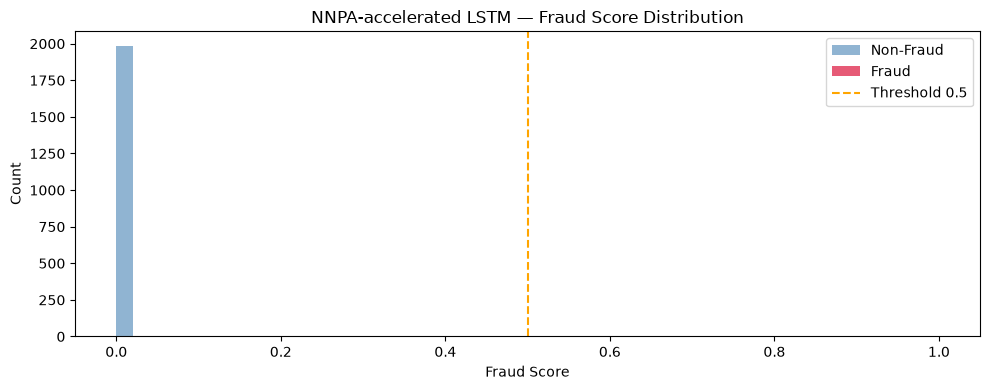

TP=3  FP=6  FN=0  TN=1991
Precision: 0.3333   Recall: 1.0000


In [20]:
# ── 3. Show fraud detection score distribution ────────────────────────────
import matplotlib.pyplot as plt

scores      = preds.numpy()[:, -1, 0]   # last timestep, single output
pred_labels = (scores >= 0.5).astype(int)

# Get true labels for the same rows
true_labels = bench_df['Is Fraud?'].to_numpy().reshape(BENCH_BATCH, timesteps)[:, -1]

fraud_scores    = scores[true_labels == 1]
non_fraud_scores = scores[true_labels == 0]

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(non_fraud_scores, bins=50, alpha=0.6, color='steelblue', label='Non-Fraud')
ax.hist(fraud_scores,     bins=50, alpha=0.7, color='crimson',   label='Fraud')
ax.axvline(0.5, color='orange', linestyle='--', linewidth=1.5, label='Threshold 0.5')
ax.set_xlabel('Fraud Score')
ax.set_ylabel('Count')
ax.set_title('NNPA-accelerated LSTM — Fraud Score Distribution')
ax.legend()
plt.tight_layout()
plt.show()

tp = int(((pred_labels == 1) & (true_labels == 1)).sum())
fp = int(((pred_labels == 1) & (true_labels == 0)).sum())
fn = int(((pred_labels == 0) & (true_labels == 1)).sum())
tn = int(((pred_labels == 0) & (true_labels == 0)).sum())
precision = tp / (tp + fp) if (tp + fp) > 0 else 0
recall    = tp / (tp + fn) if (tp + fn) > 0 else 0
print(f'TP={tp}  FP={fp}  FN={fn}  TN={tn}')
print(f'Precision: {precision:.4f}   Recall: {recall:.4f}')
